# Hyunho Analysis

Ping 고급 프로젝트에서 수행한 **전처리 → EDA → 발표자료 시각화 → 주제 3 EDA**를 실행 순서대로 통합한 최종 노트북입니다.

## 실행 순서
1. 데이터 전처리
2. 서비스·네트워크 EDA
3. 발표자료 시각화
4. 주제 3 EDA — 질문 기반 유저 반응과 수익화 연관성

> 메모리 사용량을 줄이기 위해 각 섹션 마지막에 `%reset -f`를 실행합니다.  
> 따라서 다음 섹션에서는 필요한 데이터를 다시 로드하며, 이는 중복 로드가 아니라 **섹션별 독립 실행과 재현성 유지**를 위한 구성입니다.


# 1. 데이터 전처리

원본 데이터의 결측치·이상치·정합성을 확인하고 분석용 정제 데이터를 생성합니다.

In [668]:
# ===== 팀 프로젝트 시작 셀 =====
import os, sys
from google.colab import userdata

TOKEN = userdata.get('GITHUB_TOKEN')
NAME = "Hyunho"
REPO_URL = "github.com/DA15-Lab/team3-ping-analytics.git"
PROJECT_DIR = "/content/team3-ping-analytics"

if not os.path.exists(PROJECT_DIR):
    !git clone -q https://{repo_url}/
    %cd {PROJECT_DIR}
else:
    %cd {PROJECT_DIR}
    !git pull -q

!git config user.email "{NAME}@example.com"
!git config user.name "{NAME}"

!pip install -q -r requirements.txt

print("✅ 준비 완료")

/content/team3-ping-analytics
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 55.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
✅ 준비 완료


In [ ]:
# ===== 작업 저장 셀 =====
NAME = "Hyunho"
PROJECT_DIR = "/content/team3-ping-analytics"

%cd {PROJECT_DIR}
!git config pull.rebase false
!git config core.editor "true"

!git pull
!pip install -q -r requirements.txt

from google.colab import _message
import json

with open(f'notebooks/{NAME}_analysis.ipynb', 'w') as f:
    json.dump(_message.blocking_request('get_ipynb', timeout_sec=30)['ipynb'], f)

!pip freeze | grep -v "google-colab" > requirements.txt

!git add .
!git commit -m "파트1, 3 완료"
!git push

/content/team3-ping-analytics
Already up to date.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 45.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


## 데이터 불러오기

In [1]:
import os
from pathlib import Path

In [2]:
# 한글 폰트 지원 패키지 설치
!pip install -q koreanize-matplotlib

# matplotlib 한글 폰트 적용
import koreanize_matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 21.0 MB/s eta 0:00:00


In [3]:
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# 프로젝트 공통 경로
project_path = Path('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트')
raw_path = project_path / '00_원본 csv'
clean_path = project_path / '01_전처리 완료된 csv'
text_path = project_path / '98_추가_csv'

# 전처리 구간에서는 원본 데이터 경로 사용
path = str(raw_path) + '/'

In [5]:
users = pd.read_csv(path + 'accounts_user.csv')
groups = pd.read_csv(path + 'accounts_group.csv')
schools = pd.read_csv(path + 'accounts_school.csv')

In [6]:
account_user = pd.read_csv(path + 'accounts_userquestionrecord.csv')

In [7]:
attendance = pd.read_csv(path + 'accounts_attendance.csv')
friendrequest = pd.read_csv(path + 'accounts_friendrequest.csv')

qset = pd.read_csv(path + 'polls_questionset.csv')

In [8]:
users.head()

,id,is_superuser,is_staff,gender,point,friend_id_list,is_push_on,created_at,block_user_id_list,hide_user_id_list,ban_status,report_count,alarm_count,pending_chat,pending_votes,group_id
0,831956,1,1,NaN,600,"[1292473, 913158, 1488461, 1064695, 1043565, 1...",0,2023-03-29 03:44:14.047130,[],[],N,0,0,0,0,NaN
1,831962,0,0,F,2248,"[833025, 832642, 982531, 879496, 838541, 83752...",1,2023-03-29 05:18:56.162368,[],[],N,253,40878,5499,110,12.0
2,832151,0,0,M,1519,"[838785, 982531, 882567, 879496, 838541, 83649...",0,2023-03-29 12:56:34.989468,[],[],N,0,37,0,47,1.0
3,832340,0,0,F,57,"[841345, 982531, 838785, 963714, 882567, 83252...",1,2023-03-29 12:56:35.020790,[],[],N,0,19,0,21,1.0
4,832520,0,0,M,1039,"[874050, 849763, 874212, 844297, 838541, 84004...",0,2023-03-29 12:56:35.049311,[],[],N,0,29,0,15,12.0


## 전처리

### account_user - opened_times 의미

In [9]:
account_user.head()

,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
0,771777,C,2023-04-28 12:27:49,849469,252,849436,998458,0,N,2023-04-28 12:27:49,0,0
1,771800,C,2023-04-28 12:28:02,849446,244,849436,998459,0,N,2023-04-28 12:28:02,0,0
2,771812,C,2023-04-28 12:28:09,849454,183,849436,998460,1,N,2023-04-28 12:28:09,0,0
3,771828,C,2023-04-28 12:28:16,847375,101,849436,998461,0,N,2023-04-28 12:28:16,0,0
4,771851,C,2023-04-28 12:28:26,849477,209,849436,998462,1,N,2023-04-28 12:28:26,0,0


In [10]:
# opened_times 기본 분포
print(account_user['opened_times'].value_counts().sort_index().head(20))

print('\n기초통계')
print(account_user['opened_times'].describe())

opened_times
0    1156896
1      46882
2      11120
3       2660
Name: count, dtype: int64

기초통계
count    1.217558e+06
mean     6.332511e-02
std      3.011468e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.000000e+00
Name: opened_times, dtype: float64


In [11]:
# opened_times와 읽음 여부 관계
pd.crosstab(
    account_user['opened_times'],
    account_user['has_read'],
    margins=True
)

has_read,0,1,All
opened_times,,,
0,537995,618901,1156896
1,3632,43250,46882
2,0,11120,11120
3,0,2660,2660
All,541627,675931,1217558


In [12]:
account_user.groupby(
    ['has_read', 'answer_status']
)['opened_times'].agg(
    count='count',
    mean='mean',
    median='median',
    max='max'
)

count      mean  median  max
has_read answer_status                               
0        N              541627  0.006706     0.0    1
1        A              111761  0.127021     0.0    3
         N              556305  0.103183     0.0    3
         P                7865  0.238144     0.0    3

In [13]:
account_user['opened_times'].value_counts().sort_index()

,count
opened_times,
0,1156896
1,46882
2,11120
3,2660


In [14]:
pd.crosstab(
    account_user['opened_times'],
    account_user['status'],
    margins=True
)

status,B,C,I,All
opened_times,,,,
0,574,1156322,0,1156896
1,56,0,46826,46882
2,20,0,11100,11120
3,8,0,2652,2660
All,658,1156322,60578,1217558


In [15]:
account_user[(account_user['opened_times'] > 0) & (account_user['has_read'] == 0)][
    ['status', 'answer_status', 'opened_times', 'has_read']
].value_counts()

,,,,count
status,answer_status,opened_times,has_read,
I,N,1,0,3629
B,N,1,0,3


### User 테이블 전처리

In [16]:
# 이미 불러온 users에서 분석에 필요한 컬럼만 선택
# alarm_count도 함께 유지해 동일 파일 재로딩을 방지
users = users[[
    'id', 'created_at', 'group_id', 'gender', 'ban_status',
    'is_push_on', 'pending_chat', 'pending_votes', 'alarm_count'
]].copy()

In [17]:
users.info()
users.isna().sum()
users.duplicated().sum()
users['id'].duplicated().sum()
users['group_id'].isna().sum()

users[['created_at']].describe()
users['ban_status'].value_counts(dropna=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 677085 entries, 0 to 677084
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   id             677085 non-null  int64  
 1   created_at     677085 non-null  object 
 2   group_id       677082 non-null  float64
 3   gender         677083 non-null  object 
 4   ban_status     677085 non-null  object 
 5   is_push_on     677085 non-null  int64  
 6   pending_chat   677085 non-null  int64  
 7   pending_votes  677085 non-null  int64  
 8   alarm_count    677085 non-null  int64  
dtypes: float64(1), int64(5), object(3)
memory usage: 46.5+ MB


,count
ban_status,
N,668432
W,7855
NB,608
RB,190


#### 결측치 확인

In [18]:
users[users.isna().any(axis=1)]

,id,created_at,group_id,gender,ban_status,is_push_on,pending_chat,pending_votes,alarm_count
0,831956,2023-03-29 03:44:14.047130,NaN,NaN,N,0,0,0,0
138959,995177,2023-05-08 07:25:51.737820,NaN,F,N,1,0,0,0
674052,1580689,2023-09-24 17:39:12.897884,NaN,NaN,N,0,0,0,0


결측치 삭제

In [19]:
users = users.dropna(subset=['gender', 'group_id']).copy()

In [20]:
users['group_id'].value_counts()

,count
group_id,
67097.0,80
6431.0,79
13705.0,73
53560.0,69
36957.0,61
...,...
84542.0,1
84541.0,1
84539.0,1


In [21]:
# 정수형 변환
users['group_id'] = users['group_id'].astype(int)

In [22]:
users.duplicated().sum()

np.int64(0)

중복값 X

#### 이상치 확인

In [23]:
users.describe()

,id,group_id,is_push_on,pending_chat,pending_votes,alarm_count
count,6.770820e+05,677082.000000,677082.000000,677082.000000,677082.000000,677082.000000
mean,1.212969e+06,37022.980168,0.843100,0.098470,84.630893,0.946650
std,2.138964e+05,21997.765398,0.363706,11.087794,123.262832,56.114983
min,8.319620e+05,1.000000,0.000000,-1.000000,0.000000,0.000000
25%,1.028076e+06,18488.000000,1.000000,0.000000,2.000000,0.000000
50%,1.211730e+06,35614.000000,1.000000,0.000000,29.000000,1.000000
75%,1.397906e+06,54534.000000,1.000000,0.000000,122.000000,1.000000
max,1.583733e+06,84546.000000,1.000000,5712.000000,3352.000000,40878.000000


- pending_chat, pending_votes 이상치로 보이는 max 값 확인

In [24]:
# 분포·상위 분위수 확인
users[['pending_chat', 'pending_votes']].describe(
    percentiles=[.90, .95, .99, .995, .999]
)

,pending_chat,pending_votes
count,677082.000000,677082.000000
mean,0.098470,84.630893
std,11.087794,123.262832
min,-1.000000,0.000000
50%,0.000000,29.000000
90%,0.000000,249.000000
95%,1.000000,339.000000
99%,2.000000,544.000000
99.5%,2.000000,634.000000
99.9%,5.000000,852.000000


In [25]:

users['pending_votes'].nlargest(10)

,pending_votes
173166,3352
356987,2744
385284,2561
286755,2232
194954,2005
54922,1972
217912,1935
201289,1821
333584,1768
273183,1705


In [26]:
users[users['pending_chat'] < 0]

,id,created_at,group_id,gender,ban_status,is_push_on,pending_chat,pending_votes,alarm_count
271084,1138370,2023-05-11 13:53:19.948562,33550,M,N,1,-1,0,0
366683,1242506,2023-05-14 01:41:16.929982,46935,F,N,1,-1,5,0
489170,1377119,2023-05-18 22:59:08.940361,50365,M,N,1,-1,7,1
505326,1395096,2023-05-20 03:53:16.178307,64465,M,N,1,-1,0,0
523372,1415448,2023-05-21 01:53:06.441420,70939,M,N,1,-1,1,0


마이너스 값들 삭제 진행

In [27]:
users = users[users['pending_chat'] >= 0].copy()

In [28]:
users['pending_chat'].value_counts().sort_index().head(20)

,count
pending_chat,
0,642825
1,26984
2,4647
3,1347
4,534
5,263
6,139
7,80
8,47


In [29]:
(users['pending_chat'] > 1000).sum()

np.int64(4)

pending_chat 컬럼은 천 건이 넘는 행에 한해서 1000건이 안되는 값들 중 제일 큰 값으로 대체를 진행하겠다

In [30]:
# 1000 이하 값 중 최댓값
max_normal = users.loc[users['pending_chat'] <= 1000, 'pending_chat'].max()

# 1000 초과값을 max_normal로 대체
users.loc[users['pending_chat'] > 1000, 'pending_chat'] = max_normal

print('대체값:', max_normal)

대체값: 256


In [31]:
users['pending_chat'].nlargest(10)

,pending_chat
1,256
50,256
693,256
644656,256
671688,256
106823,161
113075,116
146208,115
81066,98
463456,59


In [32]:
# 분포·상위 분위수 확인
users['pending_votes'].describe(
    percentiles=[.90, .95, .99, .995, .999]
)

,pending_votes
count,677077.000000
mean,84.631498
std,123.263085
min,0.000000
50%,29.000000
90%,249.000000
95%,339.000000
99%,544.000000
99.5%,634.000000
99.9%,852.000000


In [33]:
q99 = users['pending_votes'].quantile(0.99)

pending_votes_99 = users.loc[
    users['pending_votes'] <= q99,
    'pending_votes'
]

print('99% 기준값:', q99)
print('평균:', pending_votes_99.mean())
print('중앙값:', pending_votes_99.median())
print('최대값:', pending_votes_99.max())
print('포함 행 수:', len(pending_votes_99))

99% 기준값: 544.0
평균: 78.6372006844482
중앙값: 28.0
최대값: 544
포함 행 수: 670321


In [34]:
# UQR 기준 유저별 받은 투표 수
received = (
    account_user.groupby('chosen_user_id')
    .size()
    .reset_index(name='received_votes')
)

# accounts_user의 pending_votes와 연결
check = users[['id', 'pending_votes']].merge(
    received,
    left_on='id',
    right_on='chosen_user_id',
    how='inner'
)

check[['received_votes', 'pending_votes']].describe()

,received_votes,pending_votes
count,15426.000000,15426.000000
mean,78.928951,105.775639
std,131.426705,134.760117
min,1.000000,0.000000
25%,3.000000,6.000000
50%,15.000000,55.000000
75%,97.000000,157.000000
max,1239.000000,1472.000000


pending_votes 의미 해석 및 전처리에 너무 많은 시간을 쏟기보다 팀원 모두 사용하지 않는 컬럼이라 추후 필요할때 다시 불러와서 전처리를 진행하도록 하겠다.

In [35]:
users = users.drop(columns=['pending_votes'])

In [36]:
users.columns

Index(['id', 'created_at', 'group_id', 'gender', 'ban_status', 'is_push_on',
       'pending_chat', 'alarm_count'],
      dtype='object')

In [37]:
users.describe()

,id,group_id,is_push_on,pending_chat,alarm_count
count,6.770770e+05,677077.000000,677077.000000,677077.000000,677077.000000
mean,1.212969e+06,37022.860331,0.843099,0.074709,0.946656
std,2.138968e+05,21997.773046,0.363708,0.896461,56.115190
min,8.319620e+05,1.000000,0.000000,0.000000,0.000000
25%,1.028075e+06,18488.000000,1.000000,0.000000,0.000000
50%,1.211728e+06,35614.000000,1.000000,0.000000,1.000000
75%,1.397906e+06,54534.000000,1.000000,0.000000,1.000000
max,1.583733e+06,84546.000000,1.000000,256.000000,40878.000000


- alarm 컬럼 추가

In [38]:
users['alarm_count'].isna().sum()

np.int64(0)

In [39]:
users['alarm_count'].describe()

,alarm_count
count,677077.000000
mean,0.946656
std,56.115190
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,40878.000000


In [40]:
users['alarm_count'].value_counts().sort_index().head(20)

,count
alarm_count,
0,179631
1,439801
2,47225
3,6959
4,1705
5,632
6,340
7,175
8,137


In [41]:
users['alarm_count'].describe(
    percentiles=[.90, .95, .99, .999]
)

,alarm_count
count,677077.000000
mean,0.946656
std,56.115190
min,0.000000
50%,1.000000
90%,1.000000
95%,2.000000
99%,3.000000
99.9%,7.000000
max,40878.000000


In [42]:
users[users['alarm_count'] > 10][
    ['id', 'alarm_count', 'pending_chat', 'is_push_on', 'group_id']
].sort_values('alarm_count', ascending=False).head(20)

,id,alarm_count,pending_chat,is_push_on,group_id
1,831962,40878,256,1,12
693,838541,21442,256,1,9
50,834358,912,256,1,1
557290,1453061,238,0,1,61829
543379,1437875,201,3,1,1
408561,1288533,119,0,1,59045
644842,1549094,111,4,1,49564
604980,1505972,101,0,1,60786
54216,904023,71,0,1,16311
671641,1577899,69,1,1,61970


상위 3개 값들은 그 다음 값들에 비해 극단적으로 크기에 pending_chat에서 처럼 상한값 캠핑을 진행하겠다

In [43]:
# 238 초과 alarm_count를 238로 대체
users.loc[users['alarm_count'] > 238, 'alarm_count'] = 238

In [44]:
users['alarm_count'].describe()

,alarm_count
count,677077.000000
mean,0.854321
std,1.041887
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,238.000000


In [45]:
# # 전처리 완료 테이블 저장
# users.to_csv('/content/accounts_user_cleaned.csv', index=False, encoding='utf-8-sig')

In [46]:
# from google.colab import files

# files.download('/content/accounts_user_cleaned.csv')

### groups 테이블 전처리

In [47]:
groups.info()
groups.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84515 entries, 0 to 84514
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         84515 non-null  int64
 1   grade      84515 non-null  int64
 2   class_num  84515 non-null  int64
 3   school_id  84515 non-null  int64
dtypes: int64(4)
memory usage: 2.6 MB


,id,grade,class_num,school_id
0,1,1,1,1
1,8,3,2,1
2,9,3,3,1
3,10,2,2,1
4,11,2,3,1


In [48]:
groups.isna().sum()

,0
id,0
grade,0
class_num,0
school_id,0


In [49]:
print('전체 중복 행:', groups.duplicated().sum())
print('id 중복:', groups['id'].duplicated().sum())

전체 중복 행: 0
id 중복: 0


In [50]:
groups['grade'].value_counts(dropna=False).sort_index()

,count
grade,
1,19659
2,35581
3,29273
4,1
20,1


4학년과 20학년은 없기 때문에 확인 후 처리

In [51]:
groups['class_num'].describe()

,class_num
count,84515.000000
mean,5.318606
std,4.089901
min,0.000000
25%,2.000000
50%,4.000000
75%,7.000000
max,41.000000


0, 41 값 확인 필요

In [52]:
groups['school_id'].nunique()

5604

In [53]:
# users.group_id가 실제 groups.id에 다 존재하는지 체크
print(
    'users의 group_id 중 group 테이블에 없는 값:',
    (~users['group_id'].isin(groups['id'])).sum()
)

users의 group_id 중 group 테이블에 없는 값: 0


#### grade 이상치 처리

In [54]:
# grade 4, 20 확인
grade_check = groups[~groups['grade'].isin([1, 2, 3])]

grade_check

,id,grade,class_num,school_id
32624,32644,4,10,4658
61622,61647,20,7,3867


In [55]:
grade_check.merge(
    users.groupby('group_id').size().reset_index(name='user_count'),
    left_on='id',
    right_on='group_id',
    how='left'
)

,id,grade,class_num,school_id,group_id,user_count
0,32644,4,10,4658,NaN,NaN
1,61647,20,7,3867,NaN,NaN


해당 그룹은 비어있으므로 삭제 진행

In [56]:
groups = groups[groups['grade'].isin([1, 2, 3])].copy()

In [57]:
groups['grade'].value_counts().sort_index()

,count
grade,
1,19659
2,35581
3,29273


#### class_num 이상치 처리

In [58]:
# class_num = 41인 그룹
class41 = groups[groups['class_num'] == 41]

class41

,id,grade,class_num,school_id
70368,70394,1,41,736


In [59]:
class_check = groups[groups['class_num'].isin([0, 41])]

class_check

,id,grade,class_num,school_id
62234,62259,2,0,4348
62626,62651,2,0,1820
70368,70394,1,41,736


In [60]:
class_check = (
    groups[groups['class_num'].isin([0, 41])]
    .merge(
        users.groupby('group_id').size().reset_index(name='user_count'),
        left_on='id',
        right_on='group_id',
        how='left'
    )
    .merge(
        schools,
        left_on='school_id',
        right_on='id',
        how='left',
        suffixes=('_group', '_school')
    )
)

class_check

,id_group,grade,class_num,school_id,group_id,user_count,id_school,address,student_count,school_type
0,62259,2,0,4348,62259.0,1.0,4348,경상남도 김해시,151,M
1,62651,2,0,1820,62651.0,1.0,1820,충청남도 세종특별자치시,9,M
2,70394,1,41,736,NaN,NaN,736,전라북도 전주시 덕진구,292,H


In [61]:
# class_num이 0 또는 41인 group 삭제
groups = groups[~groups['class_num'].isin([0, 41])].copy()

class_num인 경우 대응되는 유저 id가 한명씩 존재하므로 나중에 merge했을때 결측이 2건 생길 수 있다

merge 후 추후 추가 결측까지 삭제하도록 하겠다

In [62]:
groups.describe()

,id,grade,class_num,school_id
count,84510.000000,84510.000000,84510.000000,84510.000000
mean,42278.450775,2.113774,5.318235,3079.496095
std,24401.181919,0.752369,4.088062,1675.043968
min,1.000000,1.000000,1.000000,1.000000
25%,21146.250000,2.000000,2.000000,1752.000000
50%,42277.500000,2.000000,4.000000,3023.000000
75%,63411.750000,3.000000,7.000000,4620.000000
max,84546.000000,3.000000,20.000000,5965.000000


In [63]:
groups['class_num'].value_counts().sort_index(ascending=False)

,count
class_num,
20,2454
19,177
18,217
17,214
16,152
15,216
14,311
13,506
12,998


##### clasee_num 20반 확인

In [64]:
# class_num=20의 학교 유형 / 학년 분포
groups[groups['class_num'] == 20]['grade'].value_counts().sort_index()

,count
grade,
1,291
2,1551
3,612


18·19·20반에 실제 유저가 얼마나 연결돼 있는지

In [65]:
group_users = users.groupby('group_id').size().reset_index(name='user_count')

check_1820 = (
    groups[groups['class_num'].isin([18, 19, 20])]
    .merge(group_users, left_on='id', right_on='group_id', how='left')
)

check_1820['user_count'] = check_1820['user_count'].fillna(0)

check_1820.groupby('class_num')['user_count'].agg(
    group_count='count',
    groups_with_users=lambda x: (x > 0).sum(),
    avg_users='mean',
    median_users='median'
)

,group_count,groups_with_users,avg_users,median_users
class_num,,,,
18,217,173,1.368664,1.0
19,177,144,1.079096,1.0
20,2454,2015,2.479625,1.0


같은 학교·같은 학년에 1~19반과 20반이 같이 존재하는지

In [66]:
school_grade_classes = (
    groups.groupby(['school_id', 'grade'])['class_num']
    .agg(list)
    .reset_index()
)

school_grade_classes['has_20'] = school_grade_classes['class_num'].apply(lambda x: 20 in x)
school_grade_classes['has_1_19'] = school_grade_classes['class_num'].apply(
    lambda x: any(1 <= n <= 19 for n in x)
)

pd.crosstab(
    school_grade_classes['has_20'],
    school_grade_classes['has_1_19']
)

has_1_19,False,True
has_20,,
False,0,11185
True,17,2436


In [67]:
only20 = school_grade_classes[
    school_grade_classes['class_num'].apply(lambda x: set(x) == {20})
]

print('20반만 존재하는 학교-학년 수:', len(only20))
only20.head(20)

20반만 존재하는 학교-학년 수: 17


,school_id,grade,class_num,has_20,has_1_19
1152,508,3,[20],True,False
1366,602,2,[20],True,False
1502,671,2,[20],True,False
2914,1358,3,[20],True,False
3044,1419,3,[20],True,False
3608,1663,2,[20],True,False
4213,1910,3,[20],True,False
4908,2178,3,[20],True,False
6373,2769,1,[20],True,False
6578,2852,3,[20],True,False


In [68]:
group_users = users.groupby('group_id').size().reset_index(name='user_count')

class20_check = (
    groups[groups['class_num'] == 20]
    .merge(
        group_users,
        left_on='id',
        right_on='group_id',
        how='left'
    )
)

# 연결 유저가 0명인 class_num=20
class20_zero = class20_check[class20_check['user_count'].isna()]

print('유저 0명인 20반 수:', len(class20_zero))
class20_zero.head(20)

유저 0명인 20반 수: 439


,id,grade,class_num,school_id,group_id,user_count
5,500,3,20,2045,NaN,NaN
6,872,2,20,2078,NaN,NaN
7,1176,1,20,2078,NaN,NaN
10,1594,2,20,2132,NaN,NaN
13,2458,2,20,2079,NaN,NaN
15,2654,2,20,2571,NaN,NaN
17,2767,3,20,1334,NaN,NaN
18,2966,3,20,2560,NaN,NaN
19,3023,3,20,2585,NaN,NaN
21,3159,1,20,4660,NaN,NaN


In [69]:
# 유저 0명인 20반 삭제

groups = groups[~groups['id'].isin(class20_zero['id'])].copy()

print('삭제 후 20반 수:', (groups['class_num'] == 20).sum())

삭제 후 20반 수: 2015


In [70]:
class20_users = (
    groups[groups['class_num'] == 20]
    .merge(
        users.groupby('group_id').size().reset_index(name='user_count'),
        left_on='id',
        right_on='group_id',
        how='left'
    )
)

class20_users['user_count'].describe()

,user_count
count,2015.000000
mean,3.019851
std,5.701060
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,80.000000


In [71]:
class20_users['user_count'].value_counts().sort_index().head(20)

,count
user_count,
1,1226
2,304
3,121
4,84
5,55
6,35
7,25
8,25
9,18


유저 1명 연결된 20반: 1,226개

그다음 2명: 304개

3명: 121개

In [72]:
class20_school_grade = groups[groups['class_num'] == 20][['school_id', 'grade']]

check = class20_school_grade.merge(
    groups,
    on=['school_id', 'grade'],
    how='left'
)

check.groupby(['school_id', 'grade'])['class_num'].agg(
    lambda x: sorted(x.unique())
).head(20)

school_id  grade
1          1            [1, 2, 3, 4, 5, 6, 7, 8, 9, 20]
           2                     [1, 2, 3, 4, 5, 7, 20]
           3            [1, 2, 3, 5, 7, 10, 16, 17, 20]
10         2                 [1, 2, 3, 4, 5, 6, 13, 20]
13         2                  [1, 2, 3, 4, 5, 6, 7, 20]
17         2          [1, 2, 3, 4, 5, 6, 7, 10, 12, 20]
18         3                  [1, 3, 4, 5, 6, 7, 8, 20]
19         2                                    [1, 20]
23         2                           [1, 2, 3, 4, 20]
39         2           [1, 2, 3, 4, 5, 6, 7, 8, 10, 20]
40         1        [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20]
           3                 [1, 2, 3, 6, 7, 8, 10, 20]
42         2                 [1, 2, 3, 4, 5, 6, 17, 20]
43         2           [1, 2, 3, 4, 5, 6, 7, 8, 17, 20]
46         1                   [1, 2, 3, 6, 10, 12, 20]
47         2                           [1, 2, 3, 4, 20]
           3                        [1, 2, 3, 4, 5, 20]
50         2                  [1, 2, 3, 4, 5, 6, 7, 20]
51         2              [2, 3, 4, 5, 6, 7, 8, 12, 20]
59         2                  [1, 2, 3, 4, 5, 6, 7, 20]
Name: class_num, dtype: object

In [73]:
only20_check = (
    groups.groupby(['school_id', 'grade'])['class_num']
    .agg(lambda x: sorted(x.unique()))
    .reset_index(name='class_list')
)

only20_check['only_20'] = only20_check['class_list'].apply(
    lambda x: x == [20]
)

print('20반만 존재하는 학교-학년 수:', only20_check['only_20'].sum())

only20_check[only20_check['only_20']].head(20)

20반만 존재하는 학교-학년 수: 12


,school_id,grade,class_list,only_20
1365,602,2,[20],True
1501,671,2,[20],True
2913,1358,3,[20],True
3043,1419,3,[20],True
3607,1663,2,[20],True
4212,1910,3,[20],True
4907,2178,3,[20],True
6576,2852,3,[20],True
12151,5291,3,[20],True
12683,5504,1,[20],True


In [74]:
has20 = only20_check[
    only20_check['class_list'].apply(lambda x: 20 in x)
]

print('20반 존재 학교-학년 수:', len(has20))
print('그중 20반만 존재:', has20['only_20'].sum())
print(
    '비율:',
    round(has20['only_20'].mean() * 100, 2),
    '%'
)

20반 존재 학교-학년 수: 2014
그중 20반만 존재: 12
비율: 0.6 %


20반 = 미지정/기타 코드일 가능성은 희박하다

In [75]:
# 16~20반 group_id
target_group_ids = groups.loc[
    groups['class_num'].between(16, 20),
    'id'
]

# 16~20반 소속 유저
target_user_ids = set(
    users.loc[
        users['group_id'].isin(target_group_ids),
        'id'
    ]
)

# 투표 표본 유저
vote_user_ids = set(account_user['user_id'].dropna().unique())

# 겹치는 유저
matched_users = target_user_ids & vote_user_ids

print('16~20반 소속 유저 수:', len(target_user_ids))
print('투표 표본 유저 수:', len(vote_user_ids))
print('겹치는 유저 수:', len(matched_users))
print('16~20반 유저 중 투표자 비율:', round(len(matched_users) / len(target_user_ids) * 100, 2), '%')

16~20반 소속 유저 수: 7033
투표 표본 유저 수: 4849
겹치는 유저 수: 34
16~20반 유저 중 투표자 비율: 0.48 %


In [76]:
# 17~20반 group_id
target_group_ids = groups.loc[
    groups['class_num'].between(17, 20),
    'id'
]

# 16~20반 소속 유저
target_user_ids = set(
    users.loc[
        users['group_id'].isin(target_group_ids),
        'id'
    ]
)

# 투표 표본 유저
vote_user_ids = set(account_user['user_id'].dropna().unique())

# 겹치는 유저
matched_users = target_user_ids & vote_user_ids

print('17~20반 소속 유저 수:', len(target_user_ids))
print('투표 표본 유저 수:', len(vote_user_ids))
print('겹치는 유저 수:', len(matched_users))
print('16~20반 유저 중 투표자 비율:', round(len(matched_users) / len(target_user_ids) * 100, 2), '%')

17~20반 소속 유저 수: 6825
투표 표본 유저 수: 4849
겹치는 유저 수: 33
16~20반 유저 중 투표자 비율: 0.48 %


In [77]:
# 20반 group_id
class20_group_ids = groups.loc[
    groups['class_num'] == 20,
    'id'
]

# 20반 소속 유저
class20_user_ids = set(
    users.loc[
        users['group_id'].isin(class20_group_ids),
        'id'
    ]
)

# 투표 표본 유저
vote_user_ids = set(account_user['user_id'].dropna().unique())

# 겹치는 유저
matched_class20 = class20_user_ids & vote_user_ids

print('20반 소속 유저 수:', len(class20_user_ids))
print('20반 중 투표 표본과 겹치는 유저 수:', len(matched_class20))
print('20반 유저 중 투표자 비율:', round(len(matched_class20) / len(class20_user_ids) * 100, 2), '%')

20반 소속 유저 수: 6085
20반 중 투표 표본과 겹치는 유저 수: 33
20반 유저 중 투표자 비율: 0.54 %


In [78]:
high_class_check = (
    groups[groups['class_num'].between(17, 19)][['school_id', 'grade']]
    .drop_duplicates()
    .merge(
        groups.groupby(['school_id', 'grade'])['class_num']
        .agg(lambda x: sorted(x.unique()))
        .reset_index(name='class_list'),
        on=['school_id', 'grade']
    )
)

high_class_check.head(30)

,school_id,grade,class_list
0,4494,3,"[1, 2, 3, 4, 5, 6, 7, 8, 19]"
1,2062,2,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 17]"
2,2078,1,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 17]"
3,1309,1,"[1, 2, 3, 4, 5, 17]"
4,2041,3,"[1, 2, 3, 4, 5, 17]"
5,2051,3,"[3, 4, 5, 6, 7, 8, 11, 12, 17]"
6,1403,1,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 18]"
7,300,2,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
8,271,1,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
9,1985,3,"[1, 2, 4, 5, 7, 8, 18]"


In [79]:
def check_gap(class_list):
    high = [x for x in class_list if 17 <= x <= 19]
    low = [x for x in class_list if x <= 16]

    if not high or not low:
        return None

    return min(high) - max(low)

high_class_check['gap'] = high_class_check['class_list'].apply(check_gap)

high_class_check.sort_values('gap', ascending=False).head(30)

,school_id,grade,class_list,gap
272,1136,2,"[1, 19]",18.0
524,442,2,"[1, 2, 19, 20]",17.0
123,4754,2,"[1, 2, 19]",17.0
507,373,2,"[1, 18]",17.0
460,530,2,"[1, 2, 18, 20]",16.0
421,1385,2,"[1, 2, 18]",16.0
504,4739,2,"[1, 2, 3, 19]",16.0
388,4161,3,"[2, 18]",16.0
432,4279,2,"[1, 2, 3, 19]",16.0
377,5414,3,"[1, 2, 18]",16.0


In [80]:
# class_num=20은 실제 학급 번호로 보기 어려운 패턴이 있어
# 원본값은 유지하되, 추후 학급 단위 분석에서는 제외

In [81]:
groups.describe()

,id,grade,class_num,school_id
count,84071.000000,84071.000000,84071.000000,84071.000000
mean,42234.692010,2.113583,5.241570,3079.903439
std,24383.155305,0.752257,3.958289,1674.878741
min,1.000000,1.000000,1.000000,1.000000
25%,21127.500000,2.000000,2.000000,1752.000000
50%,42217.000000,2.000000,4.000000,3023.000000
75%,63341.500000,3.000000,7.000000,4620.000000
max,84546.000000,3.000000,20.000000,5965.000000


In [82]:
# # 전처리 완료 후 파일 내보내기
# groups.to_csv('/content/accounts_group_cleaned.csv', index=False, encoding='utf-8-sig')

In [83]:
# from google.colab import files
# #
# files.download('/content/accounts_group_cleaned.csv')

### accounts_school 전처리

In [84]:
schools.head()

,id,address,student_count,school_type
0,4,충청북도 충주시,239,H
1,5,충청북도 충주시,160,M
2,6,충청북도 충주시,200,H
3,7,충청북도 충주시,114,H
4,8,충청북도 충주시,139,M


In [85]:
schools.isna().sum()

,0
id,0
address,0
student_count,0
school_type,0


In [86]:
schools.describe()

,id,student_count
count,5951.000000,5951.000000
mean,2981.026046,113.772979
std,1719.084020,102.863428
min,4.000000,0.000000
25%,1493.500000,16.000000
50%,2981.000000,97.000000
75%,4469.500000,183.000000
max,5965.000000,578.000000


In [87]:
schools.duplicated().sum()

np.int64(0)

In [88]:
schools['id'].duplicated().sum()

np.int64(0)

In [89]:
# student_count = 0인 학교
print('student_count 0인 학교 수:', (schools['student_count'] == 0).sum())
schools[schools['student_count'] == 0]

student_count 0인 학교 수: 387


,id,address,student_count,school_type
17,21,충청북도 충주시,0,M
22,26,충청북도 충주시,0,H
31,35,충청북도 충주시,0,H
49,53,충청북도 청주시 흥덕구,0,H
92,96,충청북도 청주시 서원구,0,H
...,...,...,...,...
5902,5910,강원도 강릉시,0,M
5904,5912,강원도 강릉시,0,H
5929,5942,경북 의성군,0,H
5933,5947,경기도 성남시 분당구,0,H


In [90]:
schools.groupby('school_type')['student_count'].describe()

,count,mean,std,min,25%,50%,75%,max
school_type,,,,,,,,
H,2661.0,141.349117,107.759162,0.0,51.0,130.0,217.0,578.0
M,3290.0,91.468997,92.937006,0.0,11.0,62.0,155.0,500.0


In [91]:
# student_count = 0인 학교 id
zero_school_ids = set(
    schools.loc[schools['student_count'] == 0, 'id']
)

# 해당 학교에 연결된 group 수
zero_group_check = (
    groups[groups['school_id'].isin(zero_school_ids)]
    .groupby('school_id')
    .size()
    .reset_index(name='group_count')
)

print('0명 학교 중 group 존재 학교 수:', zero_group_check['school_id'].nunique())

0명 학교 중 group 존재 학교 수: 37


In [92]:
user_school = (
    users[['id', 'group_id']]
    .merge(
        groups[['id', 'school_id']],
        left_on='group_id',
        right_on='id',
        how='left',
        suffixes=('_user', '_group')
    )
)

zero_user_check = (
    user_school[user_school['school_id'].isin(zero_school_ids)]
    .groupby('school_id')['id_user']
    .nunique()
    .reset_index(name='user_count')
)

print('0명 학교 중 실제 연결 유저가 있는 학교 수:',
      (zero_user_check['user_count'] > 0).sum())

0명 학교 중 실제 연결 유저가 있는 학교 수: 1


학생이 0명 존재하는 학교는 삭제하도록 하겠다

user와 연결했을때 1개의 학교는 실제 연결 유저가 있으니 유지하고 386개의 학교 정보 삭제 진행

In [93]:
# 실제 연결 유저 수 계산
user_school = (
    users[['id', 'group_id']]
    .merge(
        groups[['id', 'school_id']],
        left_on='group_id',
        right_on='id',
        how='left',
        suffixes=('_user', '_group')
    )
)

school_user_count = (
    user_school.groupby('school_id')['id_user']
    .nunique()
    .reset_index(name='actual_user_count')
)

# schools에 실제 유저 수 붙이기
schools_check = schools.merge(
    school_user_count,
    left_on='id',
    right_on='school_id',
    how='left'
)

schools_check['actual_user_count'] = schools_check['actual_user_count'].fillna(0)

# student_count=0 이고 실제 유저도 0명인 학교만 삭제
delete_ids = schools_check.loc[
    (schools_check['student_count'] == 0) &
    (schools_check['actual_user_count'] == 0),
    'id'
]

schools = schools[~schools['id'].isin(delete_ids)].copy()

print('삭제 학교 수:', len(delete_ids))
print('남은 student_count=0 학교 수:', (schools['student_count'] == 0).sum())

삭제 학교 수: 386
남은 student_count=0 학교 수: 1


In [94]:
# 삭제 후 확인
print('현재 학교 수:', len(schools))
print('student_count=0 학교 수:', (schools['student_count'] == 0).sum())

# 남아 있는 student_count=0 학교 확인
schools[schools['student_count'] == 0]

현재 학교 수: 5565
student_count=0 학교 수: 1


,id,address,student_count,school_type
4250,4257,경상남도 산청군,0,H


In [95]:
schools.head()

,id,address,student_count,school_type
0,4,충청북도 충주시,239,H
1,5,충청북도 충주시,160,M
2,6,충청북도 충주시,200,H
3,7,충청북도 충주시,114,H
4,8,충청북도 충주시,139,M


In [96]:
schools['address'].value_counts()

,count
address,
경기도 화성시,74
경기도 부천시,59
경기도 남양주시,57
경상남도 김해시,57
대구광역시 달서구,55
...,...
경기 군포시,1
경기 용인시 수지구,1
서울 동대문구,1


In [97]:
# schools.to_csv('/content/accounts_school_cleaned.csv', index=False, encoding='utf-8-sig')

In [98]:
# from google.colab import files

# files.download('/content/accounts_school_cleaned.csv')

### accounts_nearbyschool 전처리

In [99]:
nearby = pd.read_csv(path + 'accounts_nearbyschool.csv')

In [100]:
nearby.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59500 entries, 0 to 59499
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                59500 non-null  int64  
 1   distance          59500 non-null  float64
 2   nearby_school_id  59500 non-null  int64  
 3   school_id         59500 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 1.8 MB


In [101]:
nearby.isna().sum()

,0
id,0
distance,0
nearby_school_id,0
school_id,0


In [102]:
nearby.duplicated().sum()

np.int64(0)

In [103]:
nearby.head()

,id,distance,nearby_school_id,school_id
0,119021,0.004564,6,7
1,119022,0.010787,13,7
2,119023,0.012928,20,7
3,119024,0.013590,4,7
4,119025,0.014122,24,7


In [104]:
nearby.describe()

,id,distance,nearby_school_id,school_id
count,59500.000000,59500.000000,59500.000000,59500.000000
mean,148770.500000,0.055338,2976.695882,2980.524538
std,17176.314845,0.604024,1706.965231,1718.663078
min,119021.000000,0.000000,4.000000,4.000000
25%,133895.750000,0.011484,1518.000000,1493.000000
50%,148770.500000,0.021658,2973.000000,2980.500000
75%,163645.250000,0.064555,4448.000000,4469.000000
max,178520.000000,49.296594,5964.000000,5964.000000


In [105]:
nearby_view = (
    nearby
    .merge(
        schools[['id', 'address']],
        left_on='school_id',
        right_on='id',
        how='left',
        suffixes=('', '_school')
    )
    .rename(columns={'address': 'school_address'})
    .drop(columns='id_school')
    .merge(
        schools[['id', 'address']],
        left_on='nearby_school_id',
        right_on='id',
        how='left',
        suffixes=('', '_nearby')
    )
    .rename(columns={'address': 'nearby_school_address'})
    .drop(columns='id_nearby')
)

nearby_view = nearby_view[
    ['school_id', 'school_address',
     'nearby_school_id', 'nearby_school_address',
     'distance']
]

In [106]:
nearby_view.sort_values('distance', ascending=False).head(50)

,school_id,school_address,nearby_school_id,nearby_school_address,distance
59308,5948,-,615,제주특별자치도 서귀포시,49.296594
59307,5948,-,618,제주특별자치도 서귀포시,49.288493
59306,5948,-,553,제주특별자치도 제주시,49.224064
59305,5948,-,1155,NaN,49.222822
59304,5948,-,1026,전라남도 진도군,49.193698
59303,5948,-,1171,전라남도 신안군,49.149385
59302,5948,-,1420,인천광역시 옹진군,48.410895
59301,5948,-,1425,NaN,48.403180
59300,5948,-,5949,-,43.298250
59358,5949,-,570,제주특별자치도 제주시,6.254296


근처 학교 거리 정보가 결측이거나 뒤죽박죽인 5948, 5948 school_id 행은 삭제하도록 하겠다

In [107]:
# school_id 5948, 5949 관련 행 제거
nearby = nearby[
    ~nearby['school_id'].isin([5948, 5949]) &
    ~nearby['nearby_school_id'].isin([5948, 5949])
].copy()

print(nearby.shape)

(59480, 4)


In [108]:
nearby_view = (
    nearby
    .merge(
        schools[['id', 'address']],
        left_on='school_id',
        right_on='id',
        how='left',
        suffixes=('', '_school')
    )
    .rename(columns={'address': 'school_address'})
    .drop(columns='id_school')
    .merge(
        schools[['id', 'address']],
        left_on='nearby_school_id',
        right_on='id',
        how='left',
        suffixes=('', '_nearby')
    )
    .rename(columns={'address': 'nearby_school_address'})
    .drop(columns='id_nearby')
)

In [109]:
# nearby_view에서 주소가 결측인 학교 ID
missing_school_ids = set(
    nearby_view.loc[
        nearby_view['school_address'].isna(),
        'school_id'
    ].unique()
)

missing_nearby_ids = set(
    nearby_view.loc[
        nearby_view['nearby_school_address'].isna(),
        'nearby_school_id'
    ].unique()
)

# accounts_school 전처리에서 삭제한 학교 ID
deleted_school_ids = set(delete_ids)

pd.DataFrame({
    '구분': ['기준 학교 결측', '주변 학교 결측'],
    '결측 ID 수': [len(missing_school_ids), len(missing_nearby_ids)],
    '삭제 학교와 일치 수': [
        len(missing_school_ids & deleted_school_ids),
        len(missing_nearby_ids & deleted_school_ids)
    ],
    '삭제 학교와 불일치 수': [
        len(missing_school_ids - deleted_school_ids),
        len(missing_nearby_ids - deleted_school_ids)
    ]
})

,구분,결측 ID 수,삭제 학교와 일치 수,삭제 학교와 불일치 수
0,기준 학교 결측,386,386,0
1,주변 학교 결측,386,386,0


nearbyschool에서 주소가 결측으로 나온 학교 ID 386개가

schools에서 삭제한 학교 ID 386개와 정확히 전부 일치

In [110]:
nearby = nearby[
    ~nearby['school_id'].isin(delete_ids) &
    ~nearby['nearby_school_id'].isin(delete_ids)
].copy()

In [111]:
nearby[
    nearby['school_id'].isin(delete_ids) |
    nearby['nearby_school_id'].isin(delete_ids)
]

,id,distance,nearby_school_id,school_id


In [112]:
nearby.head()

,id,distance,nearby_school_id,school_id
0,119021,0.004564,6,7
1,119022,0.010787,13,7
2,119023,0.012928,20,7
3,119024,0.013590,4,7
4,119025,0.014122,24,7


In [113]:
nearby.describe()

,id,distance,nearby_school_id,school_id
count,52879.000000,52879.000000,52879.000000,52879.000000
mean,148784.299627,0.042175,2979.140699,2981.861003
std,17035.911285,0.064215,1692.751912,1704.586971
min,119021.000000,0.000000,4.000000,4.000000
25%,134316.500000,0.010914,1564.000000,1535.000000
50%,148557.000000,0.020334,2956.000000,2959.000000
75%,163818.500000,0.052217,4472.000000,4486.000000
max,178520.000000,1.807119,5964.000000,5964.000000


In [114]:
nearby['id'].duplicated().sum()

np.int64(0)

In [115]:
nearby.duplicated(
    subset=['school_id', 'nearby_school_id']
).sum()

np.int64(0)

#### distance = 0.0 인 행들 확인

In [116]:
nearby[
    nearby['school_id'] == nearby['nearby_school_id']
]

,id,distance,nearby_school_id,school_id
9,119030,0.0,7,7
19,119040,0.0,8,8
29,119050,0.0,22,22
39,119060,0.0,13,13
49,119070,0.0,20,20
...,...,...,...,...
59459,178480,0.0,5959,5959
59469,178490,0.0,5960,5960
59479,178500,0.0,5964,5964
59489,178510,0.0,5963,5963


In [117]:
nearby[nearby['distance'] == 0]

,id,distance,nearby_school_id,school_id
9,119030,0.0,7,7
19,119040,0.0,8,8
29,119050,0.0,22,22
39,119060,0.0,13,13
49,119070,0.0,20,20
...,...,...,...,...
59459,178480,0.0,5959,5959
59469,178490,0.0,5960,5960
59479,178500,0.0,5964,5964
59489,178510,0.0,5963,5963


In [118]:
# distance = 0이고 school_id == nearby_school_id 인 경우 삭제
nearby = nearby[
    nearby['school_id'] != nearby['nearby_school_id']
].copy()

In [119]:
nearby[
    nearby['school_id'] == nearby['nearby_school_id']
]

,id,distance,nearby_school_id,school_id


In [120]:
nearby[
    (nearby['distance'] == 0) &
    (nearby['school_id'] != nearby['nearby_school_id'])
]

,id,distance,nearby_school_id,school_id
220,119241,0.0,28,27
230,119251,0.0,27,28
3170,122191,0.0,324,323
3200,122221,0.0,323,324
3220,122241,0.0,329,328
...,...,...,...,...
55460,174481,0.0,5553,5552
55950,174971,0.0,5619,5598
56120,175141,0.0,5598,5619
57040,176061,0.0,5720,5713


거리가 0이면서 주변 학교 아이디가 다른 경우 중-고등학교가 붙어있는건지 확인하기 위해 school_type과 연결

In [121]:
zero_distance = nearby[
    (nearby['distance'] == 0) &
    (nearby['school_id'] != nearby['nearby_school_id'])
].copy()

school_info = schools[['id', 'school_type', 'address']].rename(
    columns={
        'id': 'school_id',
        'school_type': 'school_type',
        'address': 'school_address'
    }
)

nearby_school_info = schools[['id', 'school_type', 'address']].rename(
    columns={
        'id': 'nearby_school_id',
        'school_type': 'nearby_school_type',
        'address': 'nearby_school_address'
    }
)

zero_distance_check = (
    zero_distance
    .merge(school_info, on='school_id', how='left')
    .merge(nearby_school_info, on='nearby_school_id', how='left')
)

zero_distance_check[
    ['school_id', 'school_type', 'school_address',
     'nearby_school_id', 'nearby_school_type',
     'nearby_school_address', 'distance']
].head(30)

,school_id,school_type,school_address,nearby_school_id,nearby_school_type,nearby_school_address,distance
0,27,H,충청북도 충주시,28,H,충청북도 충주시,0.0
1,28,H,충청북도 충주시,27,H,충청북도 충주시,0.0
2,323,H,충청남도 천안시 동남구,324,H,충청남도 천안시 동남구,0.0
3,324,H,충청남도 천안시 동남구,323,H,충청남도 천안시 동남구,0.0
4,328,H,충청남도 예산군,329,H,충청남도 예산군,0.0
5,329,H,충청남도 예산군,328,H,충청남도 예산군,0.0
6,797,H,전라북도 익산시,798,H,전라북도 익산시,0.0
7,798,H,전라북도 익산시,797,H,전라북도 익산시,0.0
8,806,H,전라북도 익산시,807,H,전라북도 익산시,0.0
9,807,H,전라북도 익산시,806,H,전라북도 익산시,0.0


In [122]:
zero_distance_check.groupby(
    ['school_type', 'nearby_school_type']
).size()

,,0
school_type,nearby_school_type,
H,H,122
M,M,126


distance=0인 서로 다른 학교 248건 중 중학교↔고등학교 조합은 0건

In [123]:
# distance=0인 서로 다른 학교들의 주소 정보만 선택
zero_distance_check[
    ['school_id', 'school_type', 'school_address',
     'nearby_school_id', 'nearby_school_type', 'nearby_school_address']
]

# 기준 학교 주소와 nearby 학교 주소가 같은지 여부를 same_address 컬럼으로 생성
zero_distance_check[
    ['school_id', 'school_type', 'school_address',
     'nearby_school_id', 'nearby_school_type', 'nearby_school_address']
].assign(
    same_address=lambda x: x['school_address'] == x['nearby_school_address']
)

# 같은 주소(True) / 다른 주소(False)가 각각 몇 건인지 집계
zero_distance_check[
    ['school_id', 'school_type', 'school_address',
     'nearby_school_id', 'nearby_school_type', 'nearby_school_address']
].assign(
    same_address=lambda x: x['school_address'] == x['nearby_school_address']
)['same_address'].value_counts()

,count
same_address,
True,246
False,2


 False의 의미 : 학교 주소는 다른데 distance=0으로 저장된 경우

In [124]:
# distance=0인데 주소 지역이 서로 다른 2건 확인
zero_distance_check[
    zero_distance_check['school_address']
    != zero_distance_check['nearby_school_address']
][
    ['school_id', 'school_type', 'school_address',
     'nearby_school_id', 'nearby_school_type',
     'nearby_school_address', 'distance']
]

,school_id,school_type,school_address,nearby_school_id,nearby_school_type,nearby_school_address,distance
224,5294,H,경기도 부천시,5302,H,경기도 부천시 소사구,0.0
225,5302,H,경기도 부천시 소사구,5294,H,경기도 부천시,0.0


In [125]:
nearby[
    nearby.duplicated(
        subset=['school_id', 'nearby_school_id'],
        keep=False
    )
].sort_values(['school_id', 'nearby_school_id'])

,id,distance,nearby_school_id,school_id


In [126]:
reverse = nearby.rename(columns={
    'school_id': 'nearby_school_id',
    'nearby_school_id': 'school_id',
    'distance': 'reverse_distance'
})[['school_id', 'nearby_school_id', 'reverse_distance']]

distance_check = nearby.merge(
    reverse,
    on=['school_id', 'nearby_school_id'],
    how='inner'
)

distance_check[
    (distance_check['distance'] - distance_check['reverse_distance']).abs() > 1e-6
][
    ['school_id', 'nearby_school_id', 'distance', 'reverse_distance']
]

,school_id,nearby_school_id,distance,reverse_distance


In [127]:
# 삭제한 무가입 학교가 남아있는지
nearby[
    nearby['school_id'].isin(delete_ids) |
    nearby['nearby_school_id'].isin(delete_ids)
]

,id,distance,nearby_school_id,school_id


In [128]:
# # 전처리 완료 nearbyschool 저장
# nearby.to_csv(
#     '/content/accounts_nearbyschool_cleaned.csv',
#     index=False,
#     encoding='utf-8-sig'
# )

In [129]:
# from google.colab import files

# files.download('/content/accounts_nearbyschool_cleaned.csv')

## EDA

In [130]:
# 전처리 단계의 대용량 변수 해제 후 EDA를 새로 시작
%reset -f

from pathlib import Path
import pandas as pd

project_path = Path('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트')
clean_path = project_path / '01_전처리 완료된 csv'
path = clean_path


**학교 내 네트워크 규모와 신규 유저 초기 활성화의 관계**

유저-학교 기준 베이스 테이블
베이스 테이블 생성

- accounts_user + accounts_group + accounts_school merge
- 유저별 school_id, created_at 확보
- 학교별 가입순번 join_order 생성
- 학교별 40번째 가입일 생성

user_id | school_id | created_at | join_order | 40th_signup_date

In [131]:
from pathlib import Path

In [132]:
# 전처리 완료 데이터 경로로 전환
path = clean_path

In [133]:
# 한글 폰트 지원 패키지 설치
!pip install -q koreanize-matplotlib

# matplotlib 한글 폰트 적용
import koreanize_matplotlib

In [134]:
import pandas as pd

In [135]:
# 네트워크 EDA에 필요한 컬럼만 로드해 RAM 사용량 절감
users = pd.read_csv(
    path / 'accounts_user_cleaned.csv',
    usecols=['id', 'group_id', 'created_at', 'ban_status']
)
groups = pd.read_csv(
    path / 'accounts_group_cleaned.csv',
    usecols=['id', 'school_id', 'grade', 'class_num']
)
schools = pd.read_csv(
    path / 'accounts_school_cleaned.csv',
    usecols=['id', 'student_count', 'school_type', 'address']
)

users['created_at'] = pd.to_datetime(users['created_at'])


In [136]:
# 유저 + 학급
base = users.merge(
    groups[['id', 'school_id', 'grade', 'class_num']],
    left_on='group_id',
    right_on='id',
    how='left',
    validate='many_to_one',
    suffixes=('_user', '_group')
)

# 학교 정보 추가
base = base.merge(
    schools[['id', 'student_count', 'school_type', 'address']],
    left_on='school_id',
    right_on='id',
    how='left',
    validate='many_to_one'
)

base = base.rename(columns={
    'id_user': 'user_id',
    'address': 'school_address'
})

base.head(10)

,user_id,created_at,ban_status,group_id,id_group,school_id,grade,class_num,id,student_count,school_type,school_address
0,831962,2023-03-29 05:18:56.162368,N,12,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN
1,832151,2023-03-29 12:56:34.989468,N,1,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN
2,832340,2023-03-29 12:56:35.020790,N,1,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN
3,832520,2023-03-29 12:56:35.049311,N,12,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN
4,832614,2023-03-29 12:56:35.064406,N,12,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN
5,832740,2023-03-29 13:20:46.429584,NB,12,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN
6,832857,2023-03-29 13:20:46.460241,N,12,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN
7,832894,2023-03-29 13:20:46.469788,N,1,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN
8,832920,2023-03-29 13:20:46.476550,N,1,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN
9,832986,2023-03-29 13:20:46.493876,N,12,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN


In [137]:
base.shape

(677077, 12)

In [138]:
# merge로 생긴 PK 컬럼명을 명확하게 변경
base = base.rename(columns={ 'id_group': 'group_pk', 'id': 'school_pk' })

In [139]:
base.head(1)

,user_id,created_at,ban_status,group_id,group_pk,school_id,grade,class_num,school_pk,student_count,school_type,school_address
0,831962,2023-03-29 05:18:56.162368,N,12,12.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN


In [140]:
# merge 검증용 컬럼 제거
base = base.drop(columns=['group_pk', 'school_pk'])

In [141]:
base.head(1)

,user_id,created_at,ban_status,group_id,school_id,grade,class_num,student_count,school_type,school_address
0,831962,2023-03-29 05:18:56.162368,N,12,1.0,2.0,1.0,NaN,NaN,NaN


In [142]:
# 결측값 확인
base.isna().sum()

,0
user_id,0
created_at,0
ban_status,0
group_id,0
school_id,2
grade,2
class_num,2
student_count,97
school_type,97
school_address,97


In [143]:
base.duplicated().sum()

np.int64(0)

In [144]:
check = pd.Series({
    '전체 유저': base['user_id'].nunique(),
    'school_id 없음': base.loc[base['school_id'].isna(), 'user_id'].nunique(),
    'school_id 있음 + 학교정보 없음': base.loc[
        base['school_id'].notna() & base['student_count'].isna(),
        'user_id'
    ].nunique()
})

check

,0
전체 유저,677077
school_id 없음,2
school_id 있음 + 학교정보 없음,95


In [145]:
pd.Series({
    'users 행 수': len(users),
    'users 고유 id': users['id'].nunique(),
    'users id 결측': users['id'].isna().sum(),
    'users id 중복': users['id'].duplicated().sum(),
    'base 행 수': len(base),
    'base 고유 user_id': base['user_id'].nunique()
})

,0
users 행 수,677077
users 고유 id,677077
users id 결측,0
users id 중복,0
base 행 수,677077
base 고유 user_id,677077


조인 과정에서 유저 수가 줄어든 것은 아니고, 테이블 전처리 과정에서

677,085 -> 677,077 로 8명이 사라진 것으로 보인다

일단 불러온 base 테이블에서는 결측을 유지하고 네트워크 EDA를 위한 데이터프레임을 따로 만들어서 삭제 후 분석을 진행하도록 하겠다

### network_base 데이터프레임 생성

In [146]:
# 학교 정보까지 정상 매칭된 네트워크 분석용 데이터
network_base = base.dropna(
    subset=['school_id', 'student_count', 'school_type', 'school_address']
).copy()

pd.Series({
    'base 유저 수': base['user_id'].nunique(),
    'network_base 유저 수': network_base['user_id'].nunique(),
    '제외 유저 수': base['user_id'].nunique() - network_base['user_id'].nunique()
})

,0
base 유저 수,677077
network_base 유저 수,676980
제외 유저 수,97


In [147]:
network_base.isna().sum()

,0
user_id,0
created_at,0
ban_status,0
group_id,0
school_id,0
grade,0
class_num,0
student_count,0
school_type,0
school_address,0


In [148]:
# 가입일 datetime 변환
network_base['created_at'] = pd.to_datetime(network_base['created_at'])

# 학교별 가입 순서 계산
network_base = network_base.sort_values(['school_id', 'created_at', 'user_id']).copy()
network_base['join_order'] = network_base.groupby('school_id').cumcount() + 1

# 가입 순서 구간화
network_base['join_order_group'] = pd.cut(
    network_base['join_order'],
    bins=[0, 10, 20, 39, float('inf')],
    labels=['1~10번째', '11~20번째', '21~39번째', '40번째 이후']
)

network_base[['user_id', 'school_id', 'created_at', 'join_order', 'join_order_group']].head()

,user_id,school_id,created_at,join_order,join_order_group
148922,1005961,4.0,2023-05-08 11:36:21.504116,1,1~10번째
218976,1081808,4.0,2023-05-10 07:59:11.082388,2,1~10번째
226778,1090292,4.0,2023-05-10 11:40:57.616770,3,1~10번째
227237,1090778,4.0,2023-05-10 11:53:00.563227,4,1~10번째
227311,1090858,4.0,2023-05-10 11:54:28.888525,5,1~10번째


In [149]:
network_base['join_order_group'].value_counts().sort_index()

,count
join_order_group,
1~10번째,50847
11~20번째,45220
21~39번째,77455
40번째 이후,503458


40이라는 서비스 임계값은 고정하고, 40 이후는 데이터 분포로 자르는 방식

처음에는 1-20 , 21-39, 40-100, 101 이후를 생각했으나 "왜 100이죠?" 라는 질문에 답할 수 없어서 위의 방식으로 진행하겠다

In [150]:
# 40번째 이후 가입자들의 가입 순서 분포
post40 = network_base.loc[network_base['join_order'] >= 40, 'join_order']

post40.describe(percentiles=[0.25, 0.5, 0.75, 0.9])

,join_order
count,503458.000000
mean,133.234635
std,75.200472
min,40.000000
25%,74.000000
50%,116.000000
75%,175.000000
90%,239.000000
max,578.000000


In [151]:
order = network_base.loc[network_base['join_order'] >= 40].drop_duplicates('user_id')['join_order'].dropna()

order.describe(percentiles=[.25, .5, .75, .9]).rename(index={
    'count': '유저 수', 'mean': '평균 순번', 'std': '표준편차',
    'min': '최소 순번', '25%': '하위 25% 경계', '50%': '중앙값 · 2분할 기준',
    '75%': '하위 75% 경계', '90%': '하위 90% 경계', 'max': '최대 순번'
}).round(2)

,join_order
유저 수,503458.00
평균 순번,133.23
표준편차,75.20
최소 순번,40.00
하위 25% 경계,74.00
중앙값 · 2분할 기준,116.00
하위 75% 경계,175.00
하위 90% 경계,239.00
최대 순번,578.00


In [152]:
# 가입 순서 구간화
network_base['join_order_group'] = pd.cut(
    network_base['join_order'],
    bins=[0, 20, 39, 116, float('inf')],
    labels=['1~20번째', '21~39번째', '40~116번째', '117번째 이후']
)

network_base['join_order_group'].value_counts().sort_index()

,count
join_order_group,
1~20번째,96067
21~39번째,77455
40~116번째,254264
117번째 이후,249194


In [153]:
# 학교별 실제 가입 유저 수
network_base['school_user_count'] = (
    network_base.groupby('school_id')['user_id'].transform('nunique')
)

# 학교별 최초 가입 시점
network_base['first_signup'] = (
    network_base.groupby('school_id')['created_at'].transform('min')
)

# 학교가 최종적으로 40명 이상 가입했는지 여부
network_base['reached_40'] = network_base['school_user_count'] >= 40

In [154]:
# 학교별 40번째 가입자의 가입 시점
reached_40_map = (
    network_base[network_base['join_order'] == 40]
    .set_index('school_id')['created_at']
)

network_base['reached_40_at'] = (
    network_base['school_id'].map(reached_40_map)
)

In [155]:
# 최초 가입자 발생 후 40명 달성까지 걸린 일수
network_base['days_to_40'] = (
    network_base['reached_40_at'] - network_base['first_signup']
).dt.days

network_base[
    ['user_id', 'school_id', 'join_order', 'join_order_group',
     'school_user_count', 'reached_40', 'reached_40_at', 'days_to_40']
].head()

,user_id,school_id,join_order,join_order_group,school_user_count,reached_40,reached_40_at,days_to_40
148922,1005961,4.0,1,1~20번째,235,True,2023-05-12 14:38:35.455537,4.0
218976,1081808,4.0,2,1~20번째,235,True,2023-05-12 14:38:35.455537,4.0
226778,1090292,4.0,3,1~20번째,235,True,2023-05-12 14:38:35.455537,4.0
227237,1090778,4.0,4,1~20번째,235,True,2023-05-12 14:38:35.455537,4.0
227311,1090858,4.0,5,1~20번째,235,True,2023-05-12 14:38:35.455537,4.0


In [156]:
# 학교 단위 40명 달성 현황 확인
network_base[
    ['school_id', 'school_user_count', 'reached_40', 'days_to_40']
].drop_duplicates('school_id')['reached_40'].value_counts()

,count
reached_40,
True,3896
False,1654


In [157]:
# 40명 달성 여부 비율(%)
network_base[
    ['school_id', 'reached_40']
].drop_duplicates('school_id')['reached_40'].value_counts(normalize=True).mul(100).round(2)

,proportion
reached_40,
True,70.2
False,29.8


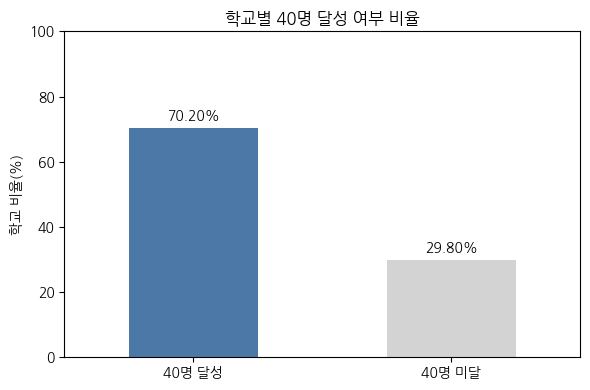

In [158]:
import matplotlib.pyplot as plt

rate = network_base[['school_id', 'reached_40']].dropna(subset=['school_id']).drop_duplicates('school_id')['reached_40'].value_counts(normalize=True).reindex([True, False], fill_value=0).mul(100)
ax = rate.set_axis(['40명 달성', '40명 미달']).plot.bar(figsize=(6, 4), color=['#4C78A8', '#D3D3D3'], rot=0)
ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=4)
ax.set(title='학교별 40명 달성 여부 비율', xlabel='', ylabel='학교 비율(%)', ylim=(0, 100))
plt.tight_layout()
plt.show()

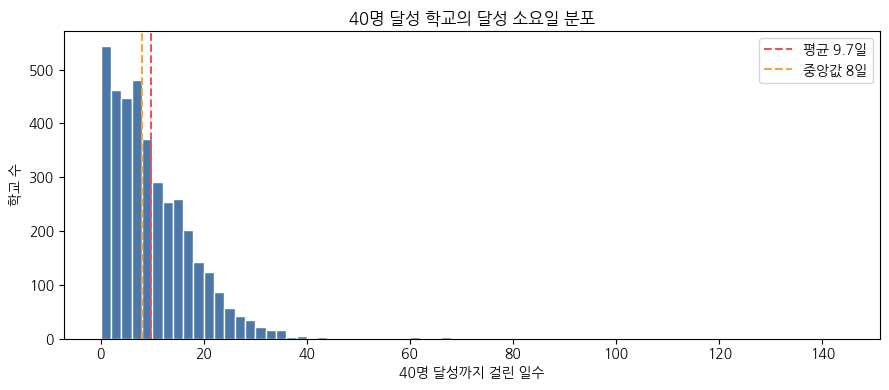

In [159]:
days = network_base.loc[network_base['reached_40'].eq(True)].dropna(subset=['school_id']).drop_duplicates('school_id')['days_to_40'].dropna()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(days, bins=range(0, int(days.max()) + 3, 2), color='#4C78A8', edgecolor='white')
ax.axvline(days.mean(), color='#E45756', linestyle='--', label=f'평균 {days.mean():.1f}일')
ax.axvline(days.median(), color='#F2A541', linestyle='--', label=f'중앙값 {days.median():g}일')
ax.set(title='40명 달성 학교의 달성 소요일 분포', xlabel='40명 달성까지 걸린 일수', ylabel='학교 수')
ax.legend()
plt.tight_layout()
plt.show()

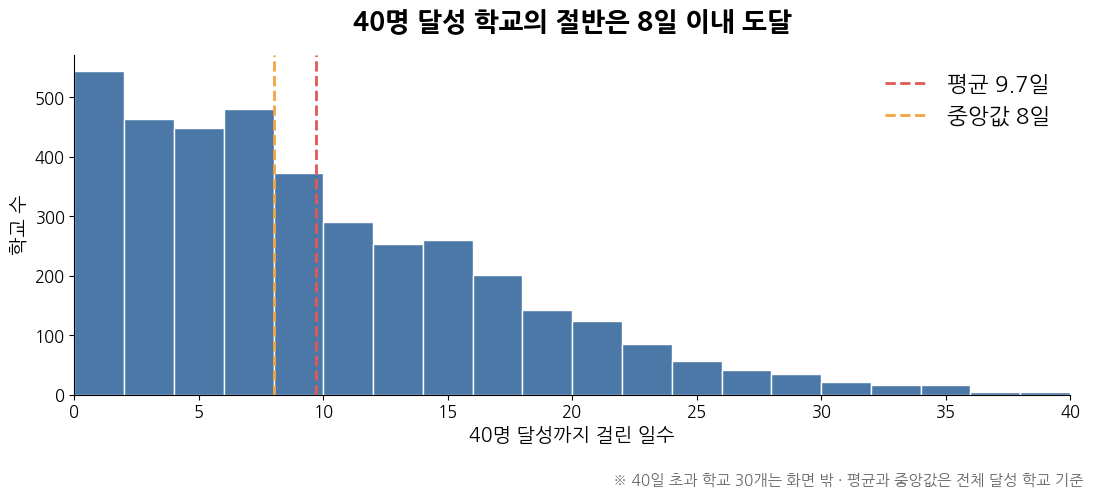

In [160]:
days = network_base.loc[network_base['reached_40'].eq(True)].dropna(subset=['school_id']).drop_duplicates('school_id')['days_to_40'].dropna()

fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(days, bins=range(0, int(days.max()) + 3, 2), color='#4C78A8', edgecolor='white')
ax.axvline(days.mean(), color='#E45756', linestyle='--', linewidth=2, label=f'평균 {days.mean():.1f}일')
ax.axvline(days.median(), color='#F2A541', linestyle='--', linewidth=2, label=f'중앙값 {days.median():g}일')
ax.set_xlim(0, 40)
ax.set_title('40명 달성 학교의 절반은 8일 이내 도달', fontsize=19, fontweight='bold', pad=18)
ax.set_xlabel('40명 달성까지 걸린 일수', fontsize=14)
ax.set_ylabel('학교 수', fontsize=14)
ax.tick_params(labelsize=12)
ax.legend(fontsize=16, frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.text(0.99, 0.02, f'※ 40일 초과 학교 {days.gt(40).sum():,}개는 화면 밖 · 평균과 중앙값은 전체 달성 학교 기준', ha='right', fontsize=11, color='#666666')
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

In [161]:
# 40명을 달성한 학교들의 달성 소요일 분포
network_base.loc[
    network_base['reached_40'],
    ['school_id', 'days_to_40']
].drop_duplicates('school_id')['days_to_40'].describe()

,days_to_40
count,3896.000000
mean,9.710986
std,9.478827
min,0.000000
25%,3.000000
50%,8.000000
75%,14.000000
max,143.000000


In [162]:
# 40명 달성 학교들의 소요일 분포를 분위수까지 더 세분화해서 확인
network_base.loc[
    network_base['reached_40'],
    ['school_id', 'days_to_40']
].drop_duplicates('school_id')['days_to_40'].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)

,days_to_40
count,3896.000000
mean,9.710986
std,9.478827
min,0.000000
10%,1.000000
25%,3.000000
50%,8.000000
75%,14.000000
90%,20.000000
95%,25.000000


In [163]:
# 40명 달성까지 걸린 기간을 구간별로 확인
pd.cut(
    network_base.loc[
        network_base['reached_40'],
        ['school_id', 'days_to_40']
    ].drop_duplicates('school_id')['days_to_40'],
    bins=[-1, 0, 3, 7, 14, 30, 60, float('inf')],
    labels=['당일', '1~3일', '4~7일', '8~14일', '15~30일', '31~60일', '61일 이상']
).value_counts().sort_index()

,count
days_to_40,
당일,310
1~3일,697
4~7일,928
8~14일,1060
15~30일,819
31~60일,64
61일 이상,18


In [164]:
# 구간별 학교 비율(%)
pd.cut(
    network_base.loc[
        network_base['reached_40'],
        ['school_id', 'days_to_40']
    ].drop_duplicates('school_id')['days_to_40'],
    bins=[-1, 0, 3, 7, 14, 30, 60, float('inf')],
    labels=['당일', '1~3일', '4~7일', '8~14일', '15~30일', '31~60일', '61일 이상']
).value_counts(normalize=True).sort_index().mul(100).round(2)

,proportion
days_to_40,
당일,7.96
1~3일,17.89
4~7일,23.82
8~14일,27.21
15~30일,21.02
31~60일,1.64
61일 이상,0.46


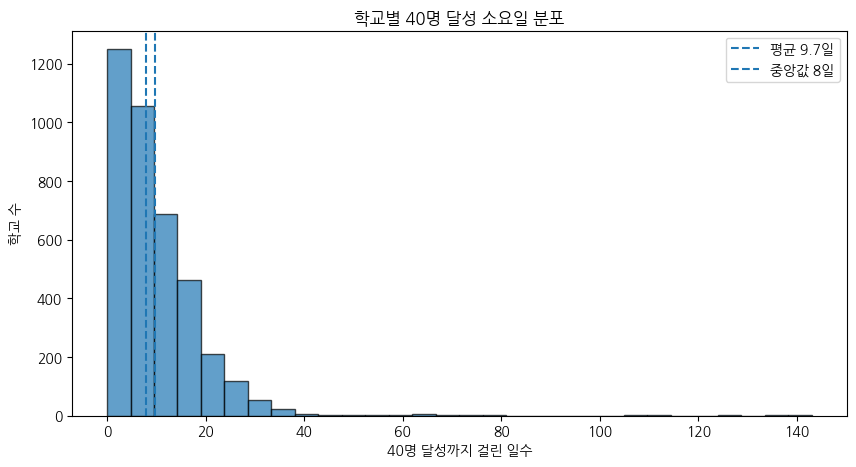

In [165]:
import matplotlib.pyplot as plt

# 학교별 중복 제거 후 40명 달성 소요일만 추출
days_40 = network_base.loc[
    network_base['reached_40'],
    ['school_id', 'days_to_40']
].drop_duplicates('school_id')['days_to_40']

# 40명 달성까지 걸린 기간 분포
plt.figure(figsize=(10, 5))
plt.hist(days_40, bins=30, edgecolor='black', alpha=0.7)

# 평균과 중앙값 표시
plt.axvline(days_40.mean(), linestyle='--', label=f'평균 {days_40.mean():.1f}일')
plt.axvline(days_40.median(), linestyle='--', label=f'중앙값 {days_40.median():.0f}일')

plt.title('학교별 40명 달성 소요일 분포')
plt.xlabel('40명 달성까지 걸린 일수')
plt.ylabel('학교 수')
plt.legend()
plt.show()

며칠 이내에 몇 %가 40명을 달성했는지

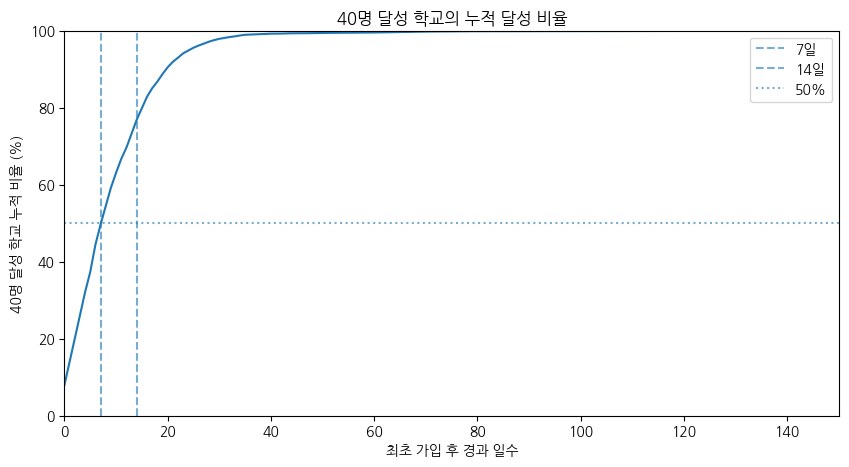

In [166]:
# 소요일 기준 오름차순 정렬
days_sorted = days_40.sort_values()

# 누적 달성 학교 비율
cumulative_ratio = (
    days_sorted.rank(method='max') / len(days_sorted) * 100
)

plt.figure(figsize=(10, 5))
plt.plot(days_sorted, cumulative_ratio)

# 주요 기준선
plt.axvline(7, linestyle='--', alpha=0.6, label='7일')
plt.axvline(14, linestyle='--', alpha=0.6, label='14일')
plt.axhline(50, linestyle=':', alpha=0.6, label='50%')

plt.title('40명 달성 학교의 누적 달성 비율')
plt.xlabel('최초 가입 후 경과 일수')
plt.ylabel('40명 달성 학교 누적 비율 (%)')
plt.xlim(left=0)
plt.ylim(0, 100)
plt.legend()
plt.show()

40명 달성 학교의 절반이 약 8일 이내에 임계점을 통과했다

### 40명 달성 못한 학교들의 특징과 지표 확인 EDA

In [167]:
# 지역별 40명 달성률

# 학교 주소에서 시·도 추출
network_base['region'] = network_base['school_address'].str.split().str[0]

# 시·도 명칭 간단하게 통일
network_base['region'] = network_base['region'].replace({
    '서울특별시': '서울', '부산광역시': '부산', '대구광역시': '대구',
    '인천광역시': '인천', '광주광역시': '광주', '대전광역시': '대전',
    '울산광역시': '울산', '세종특별자치시': '세종',
    '경기도': '경기', '강원특별자치도': '강원', '강원도': '강원',
    '충청북도': '충북', '충청남도': '충남',
    '전북특별자치도': '전북', '전라북도': '전북',
    '전라남도': '전남', '경상북도': '경북', '경상남도': '경남',
    '제주특별자치도': '제주'
})

# 지역별 학교 수 / 40명 달성 학교 수 / 달성률
(
    network_base[
        ['school_id', 'region', 'reached_40']
    ]
    .drop_duplicates('school_id')
    .groupby('region')
    .agg(
        school_count=('school_id', 'count'),
        reached_40_count=('reached_40', 'sum'),
        reached_40_rate=('reached_40', 'mean')
    )
    .assign(reached_40_rate=lambda x: (x['reached_40_rate'] * 100).round(2))
    .sort_values('reached_40_rate', ascending=False)
)

,school_count,reached_40_count,reached_40_rate
region,,,
대한민국,1,1,100.00
대구,225,206,91.56
울산,121,105,86.78
인천,270,230,85.19
부산,318,266,83.65
광주,161,131,81.37
경기,1158,925,79.88
대전,153,116,75.82
충북,206,149,72.33


In [168]:
# 지역이 '대한민국'으로 잡히거나 지역 추출이 안 된 행 확인
network_base.loc[
    (network_base['region'] == '대한민국') | (network_base['region'].isna()),
    ['user_id', 'school_id', 'school_address', 'region', 'school_type']
]

,user_id,school_id,school_address,region,school_type
113043,967337,2941.0,대한민국 강원도 철원군,대한민국,H
245200,1110347,2941.0,대한민국 강원도 철원군,대한민국,H
364733,1240400,2941.0,대한민국 강원도 철원군,대한민국,H
380007,1257093,2941.0,대한민국 강원도 철원군,대한민국,H
380346,1257479,2941.0,대한민국 강원도 철원군,대한민국,H
381745,1259021,2941.0,대한민국 강원도 철원군,대한민국,H
384801,1262444,2941.0,대한민국 강원도 철원군,대한민국,H
397230,1276131,2941.0,대한민국 강원도 철원군,대한민국,H
433853,1316087,2941.0,대한민국 강원도 철원군,대한민국,H
451663,1335743,2941.0,대한민국 강원도 철원군,대한민국,H


In [169]:
# 지역 추출이 비정상적인 학교 3개 확인
network_base.loc[
    network_base['region'].isin(['대한민국', '-']),
    ['school_id', 'school_address', 'region', 'school_type']
].drop_duplicates('school_id')

,school_id,school_address,region,school_type
113043,2941.0,대한민국 강원도 철원군,대한민국,H
661894,5948.0,-,-,H
672760,5949.0,-,-,H


In [170]:
# '대한민국 강원도 ...' 주소의 지역 보정
network_base.loc[
    network_base['region'] == '대한민국',
    'region'
] = '강원'

In [171]:
# 주소 정보가 없는 학교는 지역 결측으로 처리
network_base.loc[
    network_base['region'] == '-',
    'region'
] = pd.NA

In [172]:
# 지역 정보가 있는 학교만 지역별 40명 달성률 계산
(
    network_base.dropna(subset=['region'])
    [['school_id', 'region', 'reached_40']]
    .drop_duplicates('school_id')
    .groupby('region')
    .agg(
        school_count=('school_id', 'count'),
        reached_40_count=('reached_40', 'sum'),
        reached_40_rate=('reached_40', 'mean')
    )
    .assign(reached_40_rate=lambda x: (x['reached_40_rate'] * 100).round(2))
    .sort_values('reached_40_rate', ascending=False)
)

,school_count,reached_40_count,reached_40_rate
region,,,
대구,225,206,91.56
울산,121,105,86.78
인천,270,230,85.19
부산,318,266,83.65
광주,161,131,81.37
경기,1158,925,79.88
대전,153,116,75.82
충북,206,149,72.33
충남,348,238,68.39


In [173]:
# 중학교·고등학교별 40명 달성률

# 학교 유형별 40명 달성률
(
    network_base[
        ['school_id', 'school_type', 'reached_40']
    ]
    .drop_duplicates('school_id')
    .groupby('school_type')
    .agg(
        school_count=('school_id', 'count'),
        reached_40_count=('reached_40', 'sum'),
        reached_40_rate=('reached_40', 'mean')
    )
    .assign(reached_40_rate=lambda x: (x['reached_40_rate'] * 100).round(2))
)

,school_count,reached_40_count,reached_40_rate
school_type,,,
H,2457,2041,83.07
M,3093,1855,59.97


#### 40명 미달 학교의 가입자가 몇명에서 멈췄는지

In [174]:
# 40명 미달 학교의 최종 가입자 수 분포
network_base.loc[
    ~network_base['reached_40'],
    ['school_id', 'school_user_count']
].drop_duplicates('school_id')['school_user_count'].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
)

,school_user_count
count,1654.000000
mean,13.045949
std,10.483372
min,1.000000
10%,1.000000
25%,4.000000
50%,11.000000
75%,20.000000
90%,29.000000
max,39.000000


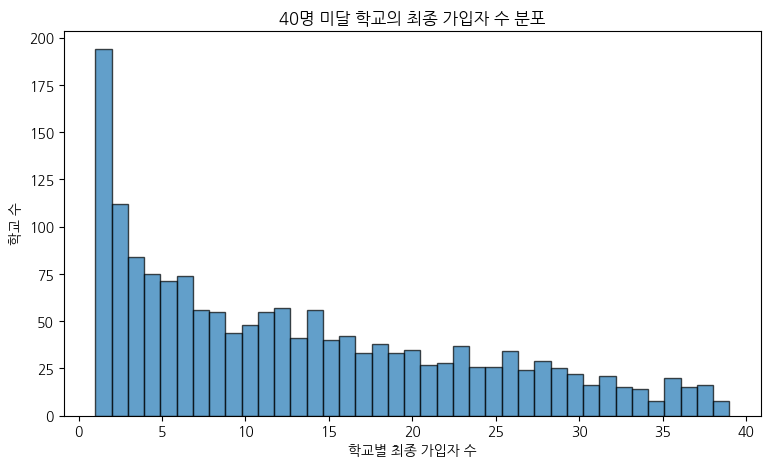

In [175]:
# 40명 미달 학교의 최종 가입자 수 히스토그램
plt.figure(figsize=(9, 5))

network_base.loc[
    ~network_base['reached_40'],
    ['school_id', 'school_user_count']
].drop_duplicates('school_id')['school_user_count'].plot(
    kind='hist',
    bins=39,
    edgecolor='black',
    alpha=0.7
)

plt.title('40명 미달 학교의 최종 가입자 수 분포')
plt.xlabel('학교별 최종 가입자 수')
plt.ylabel('학교 수')
plt.xticks(range(0, 41, 5))
plt.show()

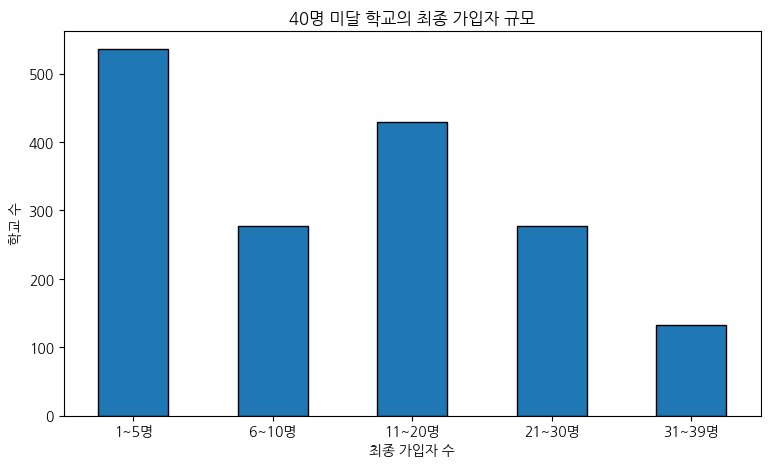

In [176]:
# 미달 학교를 최종 가입자 수에 따라 구간화
miss_group = pd.cut(
    network_base.loc[
        ~network_base['reached_40'],
        ['school_id', 'school_user_count']
    ].drop_duplicates('school_id')['school_user_count'],
    bins=[0, 5, 10, 20, 30, 39],
    labels=['1~5명', '6~10명', '11~20명', '21~30명', '31~39명']
)

# 구간별 학교 수 시각화
miss_group.value_counts().sort_index().plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('40명 미달 학교의 최종 가입자 규모')
plt.xlabel('최종 가입자 수')
plt.ylabel('학교 수')
plt.xticks(rotation=0)
plt.show()

학교별 첫 3일 가입자 분포

In [177]:
# 학교 최초 가입 후 3일 이내 가입 여부
network_base['joined_within_3d'] = (
    network_base['created_at'] - network_base['first_signup']
    <= pd.Timedelta(days=3)
)

# 학교별 초기 3일 가입자 수
network_base['signup_3d_count'] = (
    network_base.groupby('school_id')['joined_within_3d'].transform('sum')
)

# 40명 미달 학교의 초기 3일 가입자 수 분포
network_base.loc[
    ~network_base['reached_40'],
    ['school_id', 'signup_3d_count', 'school_user_count']
].drop_duplicates('school_id').describe()

,school_id,signup_3d_count,school_user_count
count,1654.000000,1654.000000,1654.000000
mean,2897.406288,3.514510,13.045949
std,1755.585755,4.373458,10.483372
min,9.000000,1.000000,1.000000
25%,1223.250000,1.000000,4.000000
50%,2870.500000,2.000000,11.000000
75%,4223.750000,4.000000,20.000000
max,5965.000000,28.000000,39.000000


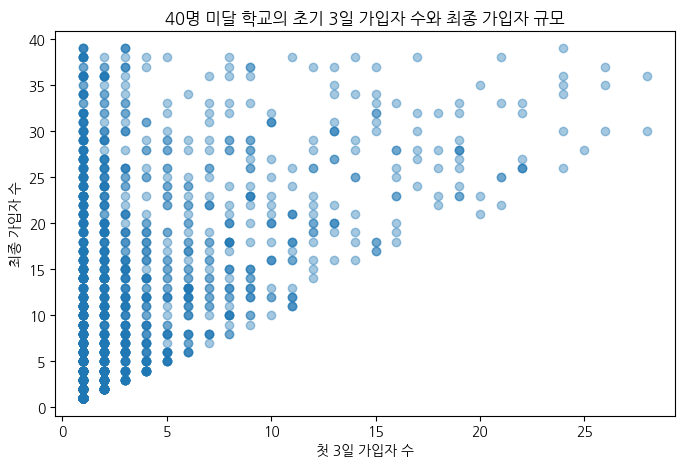

In [178]:
# 40명 미달 학교에서 초기 확산과 최종 규모의 관계
miss_school = network_base.loc[
    ~network_base['reached_40'],
    ['school_id', 'signup_3d_count', 'school_user_count']
].drop_duplicates('school_id')

plt.figure(figsize=(8, 5))
plt.scatter(
    miss_school['signup_3d_count'],
    miss_school['school_user_count'],
    alpha=0.4
)

plt.title('40명 미달 학교의 초기 3일 가입자 수와 최종 가입자 규모')
plt.xlabel('첫 3일 가입자 수')
plt.ylabel('최종 가입자 수')
plt.show()

초기 3일 가입자 수가 많을수록 최종 가입자 규모도 커지는 경향은 보이지만, 초기 1~5명 구간에서도 최종 규모가 매우 넓게 분포한다.

In [179]:
# 주변학교 분석에 필요한 컬럼만 로드
nearby = pd.read_csv(
    path / 'accounts_nearbyschool_cleaned.csv',
    usecols=['school_id', 'nearby_school_id', 'distance']
)


In [180]:
# 주변 10개 학교 평균거리 비교
# 주변 환경 밀도(?)

# 학교마다 주변 학교가 몇 개씩 기록되어 있는지 확인
nearby.groupby('school_id')['nearby_school_id'].nunique().describe()

,nearby_school_id
count,5562.000000
mean,8.507192
std,0.822518
min,3.000000
25%,8.000000
50%,9.000000
75%,9.000000
max,9.000000


#### 40명 달성 여부별 주변 학교와의 거리 비교

In [181]:
# 학교별 주변 학교 평균거리 계산 후 network_base에 추가
network_base['nearby_avg_distance'] = network_base['school_id'].map(
    nearby.groupby('school_id')['distance'].mean()
)

# 40명 달성 / 미달 학교 평균거리 비교
network_base[
    ['school_id', 'reached_40', 'nearby_avg_distance']
].drop_duplicates('school_id').groupby('reached_40')['nearby_avg_distance'].describe()

,count,mean,std,min,25%,50%,75%,max
reached_40,,,,,,,,
False,1651.0,0.076661,0.100458,0.006189,0.017856,0.065136,0.111634,1.652267
True,3896.0,0.037422,0.037944,0.000591,0.015122,0.021246,0.043414,0.365605


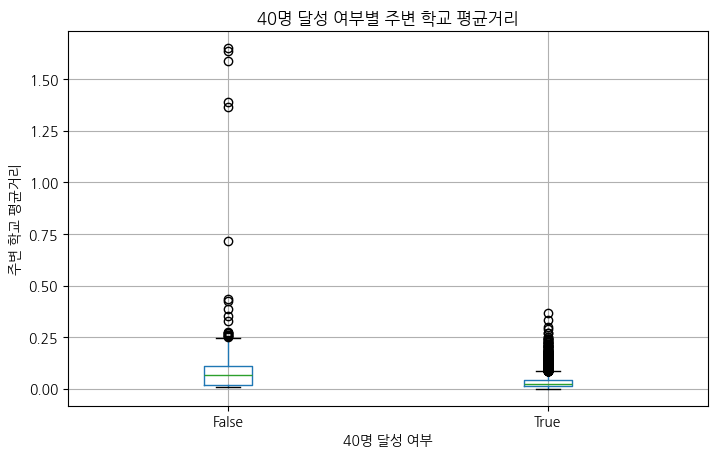

In [182]:
# 40명 달성 여부별 주변 학교 평균거리 비교
network_base[
    ['school_id', 'reached_40', 'nearby_avg_distance']
].drop_duplicates('school_id').boxplot(
    column='nearby_avg_distance',
    by='reached_40',
    figsize=(8, 5)
)

plt.title('40명 달성 여부별 주변 학교 평균거리')
plt.suptitle('')
plt.xlabel('40명 달성 여부')
plt.ylabel('주변 학교 평균거리')
plt.show()

40명 미달 학교(False)는 달성 학교(True)보다 주변 학교 평균거리가 전반적으로 더 멀고 분산도 큰 편으로 보인다.

이는 주변 학교 밀도가 낮은 환경일수록 40명 네트워크 형성이 상대적으로 어려울 가능성을 시사하지만, 이상치가 크므로 중앙값 기준 비교와 통계 검정이 추가로 필요하다.

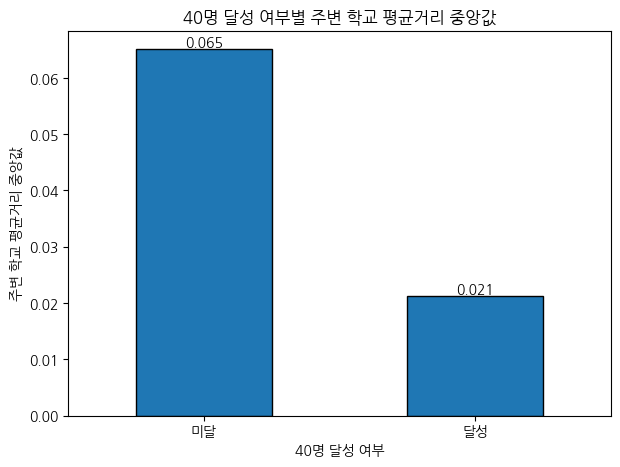

In [183]:
# 학교별 중복 제거 후 40명 달성 여부별 주변 학교 평균거리 중앙값
distance_median = (
    network_base[
        ['school_id', 'reached_40', 'nearby_avg_distance']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['nearby_avg_distance']
    .median()
)

ax = distance_median.plot(kind='bar', figsize=(7, 5), edgecolor='black')

# 막대 위에 값 표시
for i, v in enumerate(distance_median):
    ax.text(i, v, f'{v:.3f}', ha='center', va='bottom')

plt.title('40명 달성 여부별 주변 학교 평균거리 중앙값')
plt.xlabel('40명 달성 여부')
plt.ylabel('주변 학교 평균거리 중앙값')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

In [184]:
# 최초 20명 가입자가 몇 개 학급에 분산되어 있었는지 계산
network_base['first20_class_count'] = network_base['school_id'].map(
    network_base[
        (network_base['school_user_count'] >= 20) &
        (network_base['join_order'] <= 20)
    ]
    .groupby('school_id')['group_id']
    .nunique()
)

# 20명 이상 가입한 학교만 대상으로 40명 달성 여부별 비교
network_base.loc[
    network_base['school_user_count'] >= 20,
    ['school_id', 'reached_40', 'first20_class_count']
].drop_duplicates('school_id').groupby('reached_40')['first20_class_count'].describe()

,count,mean,std,min,25%,50%,75%,max
reached_40,,,,,,,,
False,446.0,8.163677,3.450143,1.0,5.25,8.0,11.0,17.0
True,3896.0,8.937115,2.571274,2.0,7.00,9.0,11.0,18.0


#### 40명 달성 여부별 한 학급에 많이 몰렸나?

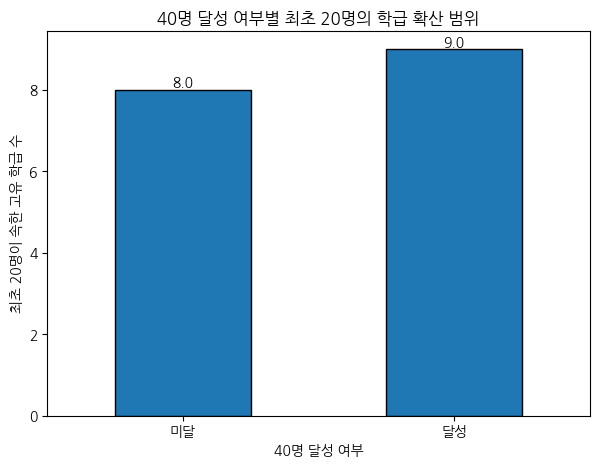

In [185]:
# 40명 달성 여부별 최초 20명의 학급 다양성 중앙값
class_median = (
    network_base.loc[
        network_base['school_user_count'] >= 20,
        ['school_id', 'reached_40', 'first20_class_count']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['first20_class_count']
    .median()
)

ax = class_median.plot(kind='bar', figsize=(7, 5), edgecolor='black')

for i, v in enumerate(class_median):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')

plt.title('40명 달성 여부별 최초 20명의 학급 확산 범위')
plt.xlabel('40명 달성 여부')
plt.ylabel('최초 20명이 속한 고유 학급 수')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

40명 달성 학교는 최초 20명이 중앙값 9개 학급에 분산된 반면, 미달 학교는 8개 학급으로 초기 가입자가 조금 더 넓게 퍼진 학교에서 40명 달성 가능성이 높은 경향이 보였다.

다만 차이가 1개 학급 수준이고 분포도 많이 겹치니 핵심 요인은 아닌 것으로 보인다

-> 단순히 몇 개 반에 퍼졌는지보다, 최초 20명이 특정 한 반에 얼마나 몰렸는지

In [186]:
# 최초 20명 중 가장 많은 가입자가 속한 한 학급의 비율 계산
network_base['first20_topclass_share'] = network_base['school_id'].map(
    network_base.loc[
        (network_base['school_user_count'] >= 20) &
        (network_base['join_order'] <= 20)
    ]
    .groupby(['school_id', 'group_id'])
    .size()
    .groupby(level=0)
    .max()
    .div(20)
)

# 40명 달성 여부별 초기 한 학급 집중도 비교
network_base.loc[
    network_base['school_user_count'] >= 20,
    ['school_id', 'reached_40', 'first20_topclass_share']
].drop_duplicates('school_id').groupby('reached_40')['first20_topclass_share'].describe()

,count,mean,std,min,25%,50%,75%,max
reached_40,,,,,,,,
False,446.0,0.304933,0.155637,0.1,0.2,0.25,0.3875,1.0
True,3896.0,0.273755,0.102628,0.1,0.2,0.25,0.3000,0.8


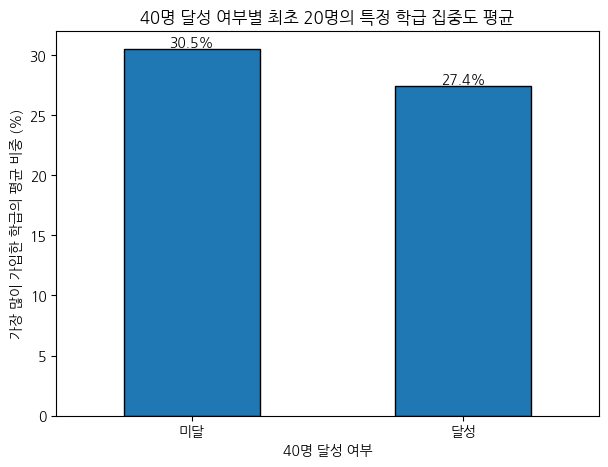

In [187]:
# 40명 달성 여부별 최초 20명의 한 학급 집중도 평균
topclass_mean = (
    network_base.loc[
        network_base['school_user_count'] >= 20,
        ['school_id', 'reached_40', 'first20_topclass_share']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['first20_topclass_share']
    .mean()
    .mul(100)
)

ax = topclass_mean.plot(kind='bar', figsize=(7, 5), edgecolor='black')

# 막대 위에 평균 비율 표시
for i, v in enumerate(topclass_mean):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.title('40명 달성 여부별 최초 20명의 특정 학급 집중도 평균')
plt.xlabel('40명 달성 여부')
plt.ylabel('가장 많이 가입한 학급의 평균 비중 (%)')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

40명 미달 학교는 최초 20명 중 특정 학급에 몰린 비중이 평균 30.5%로, 달성 학교의 27.4%보다 높았다.

즉 초기 가입자가 한 학급에 더 집중된 학교일수록 학교 전체로의 네트워크 확산이 상대적으로 약한 경향이 보인다.

In [188]:
# 40명 달성 여부별 학급 다양성 평균과 중앙값 비교
network_base.loc[
    network_base['school_user_count'] >= 20,
    ['school_id', 'reached_40', 'first20_class_count']
].drop_duplicates('school_id').groupby('reached_40')['first20_class_count'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
reached_40,,,,
False,446,8.163677,8.0,3.450143
True,3896,8.937115,9.0,2.571274


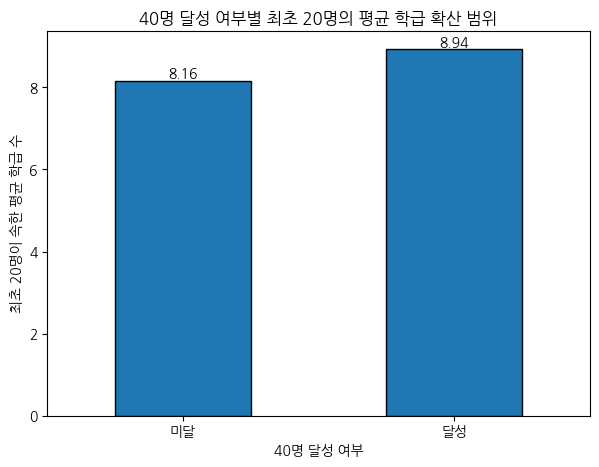

In [189]:
# 최초 20명의 학급 다양성 평균 비교
class_mean = (
    network_base.loc[
        network_base['school_user_count'] >= 20,
        ['school_id', 'reached_40', 'first20_class_count']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['first20_class_count']
    .mean()
)

ax = class_mean.plot(kind='bar', figsize=(7, 5), edgecolor='black')

for i, v in enumerate(class_mean):
    ax.text(i, v, f'{v:.2f}', ha='center', va='bottom')

plt.title('40명 달성 여부별 최초 20명의 평균 학급 확산 범위')
plt.xlabel('40명 달성 여부')
plt.ylabel('최초 20명이 속한 평균 학급 수')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

In [190]:
from scipy.stats import ttest_ind

# 학교 단위 특정 학급 집중도
miss = network_base.loc[
    (network_base['school_user_count'] >= 20) & (~network_base['reached_40']),
    ['school_id', 'first20_topclass_share']
].drop_duplicates('school_id')['first20_topclass_share'].dropna()

reach = network_base.loc[
    (network_base['school_user_count'] >= 20) & (network_base['reached_40']),
    ['school_id', 'first20_topclass_share']
].drop_duplicates('school_id')['first20_topclass_share'].dropna()

ttest_ind(miss, reach, equal_var=False)

TtestResult(statistic=np.float64(4.129044535907677), pvalue=np.float64(4.281721409854087e-05), df=np.float64(490.26458979258507))

t = 4.129

p = 0.0000428

In [191]:
# 평균 차이와 Cohen's d
mean_diff = (miss.mean() - reach.mean()) * 100

pooled_std = (
    ((len(miss) - 1) * miss.var() + (len(reach) - 1) * reach.var())
    / (len(miss) + len(reach) - 2)
) ** 0.5

cohens_d = (miss.mean() - reach.mean()) / pooled_std

pd.Series({
    '평균 차이(%p)': mean_diff,
    "Cohen's d": cohens_d
})

,0
평균 차이(%p),3.117760
Cohen's d,0.285371


애초에 미달 학교가 학급 수가 적어서 한 학급에 몰린 것은 아닐까?

In [192]:
# 학교별 전체 학급(group) 수
network_base['school_class_count'] = network_base['school_id'].map(
    groups.groupby('school_id')['id'].nunique()
)

# 최소 20명 가입 학교에서 40명 달성 여부별 전체 학급 수 비교
network_base.loc[
    network_base['school_user_count'] >= 20,
    ['school_id', 'reached_40', 'school_class_count']
].drop_duplicates('school_id').groupby('reached_40')['school_class_count'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
reached_40,,,,
False,446,10.186099,10.0,4.924042
True,3896,19.082136,19.0,7.658865


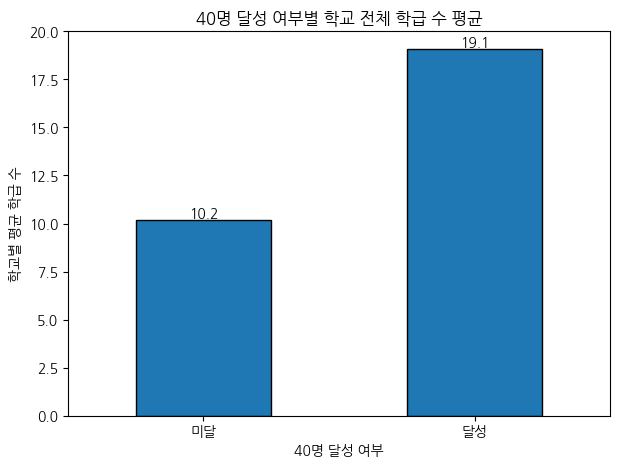

In [193]:
# 40명 달성 여부별 학교 전체 학급 수 평균
class_count_mean = (
    network_base.loc[
        network_base['school_user_count'] >= 20,
        ['school_id', 'reached_40', 'school_class_count']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['school_class_count']
    .mean()
)

ax = class_count_mean.plot(kind='bar', figsize=(7, 5), edgecolor='black')

for i, v in enumerate(class_count_mean):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')

plt.title('40명 달성 여부별 학교 전체 학급 수 평균')
plt.xlabel('40명 달성 여부')
plt.ylabel('학교별 평균 학급 수')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

##### 18~20반 제외하고 다시 확인

In [194]:
# 18~20반 제외 후 학교별 실제 학급 수 계산
network_base['school_class_count'] = network_base['school_id'].map(
    groups.loc[
        ~groups['class_num'].isin([18, 19, 20])
    ].groupby('school_id')['id'].nunique()
)

# 40명 달성 여부별 전체 학급 수 비교
network_base.loc[
    network_base['school_user_count'] >= 20,
    ['school_id', 'reached_40', 'school_class_count']
].drop_duplicates('school_id').groupby('reached_40')['school_class_count'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
reached_40,,,,
False,446,9.968610,10.0,4.854642
True,3896,18.516427,18.0,7.603238


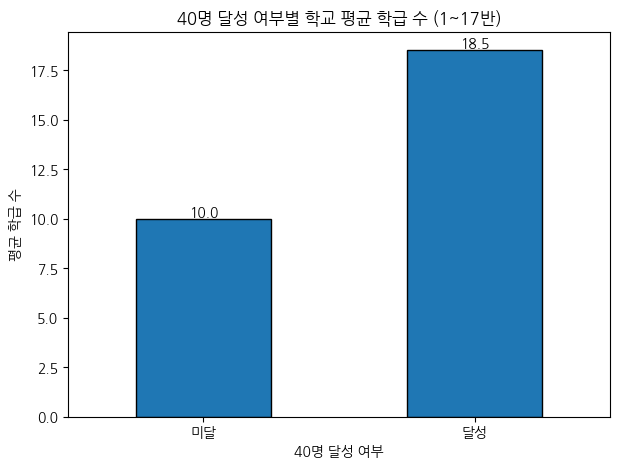

In [195]:
# 달성 여부별 평균 학급 수
class_count_mean = (
    network_base.loc[
        network_base['school_user_count'] >= 20,
        ['school_id', 'reached_40', 'school_class_count']
    ]
    .drop_duplicates('school_id')
    .groupby('reached_40')['school_class_count']
    .mean()
)

ax = class_count_mean.plot(kind='bar', figsize=(7, 5), edgecolor='black')

for i, v in enumerate(class_count_mean):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')

plt.title('40명 달성 여부별 학교 평균 학급 수 (1~17반)')
plt.xlabel('40명 달성 여부')
plt.ylabel('평균 학급 수')
plt.xticks([0, 1], ['미달', '달성'], rotation=0)
plt.show()

In [196]:
# 학교별 학급 수 범위 확인
network_base[['school_id', 'school_class_count']].drop_duplicates()['school_class_count'].describe()

,school_class_count
count,5546.000000
mean,14.710422
std,9.003385
min,1.000000
25%,8.000000
50%,14.000000
75%,21.000000
max,44.000000


In [197]:
# 학급 수가 많은 학교의 학년-반 구성 확인
check_school = (
    network_base[['school_id', 'school_class_count']]
    .drop_duplicates()
    .sort_values('school_class_count', ascending=False)
    .iloc[0]['school_id']
)

network_base.loc[
    network_base['school_id'] == check_school,
    ['grade', 'class_num']
].drop_duplicates().sort_values(['grade', 'class_num'])

,grade,class_num
40431,1.0,1.0
42704,1.0,2.0
40206,1.0,3.0
35692,1.0,4.0
42276,1.0,5.0
42007,1.0,6.0
40221,1.0,7.0
49809,1.0,8.0
46471,1.0,9.0
60111,1.0,10.0


In [198]:
# 최초 20명 중 1~17반만 대상으로
# 가장 많은 가입자가 속한 학급 비중 재계산
network_base['first20_topclass_share'] = network_base['school_id'].map(
    network_base.loc[
        (network_base['school_user_count'] >= 20) &
        (network_base['join_order'] <= 20) &
        (~network_base['class_num'].isin([18, 19, 20]))
    ]
    .groupby(['school_id', 'group_id'])
    .size()
    .groupby(level=0)
    .max()
    .div(20)
)

In [199]:
# 최초 20명 중 18~20반에 해당하는 유저 수
network_base.loc[
    (network_base['join_order'] <= 20) &
    (network_base['class_num'].isin([18, 19, 20])),
    'user_id'
].nunique()

417

In [200]:
# 학급 분석에 사용할 유효 유저 여부
network_base['valid_class'] = ~network_base['class_num'].isin([18, 19, 20])

# 학교별 유효 학급 유저들의 가입 순서 재계산
network_base['valid_class_order'] = (
    network_base['valid_class']
    .groupby(network_base['school_id'])
    .cumsum()
)

# 학교별 유효 학급 유저 수
network_base['valid_class_count'] = (
    network_base.groupby('school_id')['valid_class'].transform('sum')
)

In [201]:
# 유효 학급 기준 최초 20명 중 특정 학급 최대 집중 비율
network_base['first20_topclass_share'] = network_base['school_id'].map(
    network_base.loc[
        network_base['valid_class'] &
        (network_base['valid_class_order'] <= 20) &
        (network_base['valid_class_count'] >= 20)
    ]
    .groupby(['school_id', 'group_id'])
    .size()
    .groupby(level=0)
    .max()
    .div(20)
)

In [202]:
# 40명 달성 여부별 특정 학급 집중도 평균
network_base.loc[
    network_base['valid_class_count'] >= 20,
    ['school_id', 'reached_40', 'first20_topclass_share']
].drop_duplicates('school_id').groupby('reached_40')['first20_topclass_share'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
reached_40,,,,
False,438,0.307534,0.25,0.156551
True,3896,0.273960,0.25,0.102380


In [203]:
# 기존 최초 20명 중 18~20반 유저가 포함됐던 학교 수
network_base.loc[
    (network_base['join_order'] <= 20) &
    (network_base['class_num'].isin([18, 19, 20])),
    'school_id'
].nunique()

306

#### 연락처

In [204]:
# 연락처 분석에 필요한 컬럼만 로드
contacts = pd.read_csv(
    path / 'accounts_user_contacts_cleaned.csv',
    usecols=['user_id', 'contacts_count']
)

contacts.head()


,contacts_count,user_id
0,30,1167696
1,79,863169
2,21,857205
3,29,851431
4,28,855476


해당 전화번호를 가지고 있는 유저 수

In [205]:
# contacts 컬럼명 먼저 확인
contacts.columns

Index(['contacts_count', 'user_id'], dtype='object')

In [206]:
# 연락처 정보가 존재하는 유저 여부
network_base['has_contacts'] = network_base['user_id'].isin(contacts['user_id'])

# 학교별 최초 10명 중 연락처 데이터가 있는 유저 수
network_base['first10_contacts_n'] = network_base['school_id'].map(
    network_base.loc[
        network_base['join_order'] <= 10
    ]
    .groupby('school_id')['has_contacts']
    .sum()
)

# 최초 10명 중 연락처 정보가 몇 명이나 확보됐는지 분포 확인
network_base[
    ['school_id', 'reached_40', 'first10_contacts_n']
].drop_duplicates('school_id').groupby('reached_40')['first10_contacts_n'].describe()

,count,mean,std,min,25%,50%,75%,max
reached_40,,,,,,,,
False,1654.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
True,3896.0,0.020277,0.433334,0.0,0.0,0.0,0.0,10.0


In [207]:
# 유저별 contacts_count를 network_base에 매핑
network_base['contacts_count'] = network_base['user_id'].map(
    contacts.drop_duplicates('user_id').set_index('user_id')['contacts_count']
)

# 학교별 최초 10명 중 contacts 정보가 존재하는 유저들의 평균
network_base['first10_contacts_mean'] = network_base['school_id'].map(
    network_base.loc[
        (network_base['join_order'] <= 10) &
        (network_base['contacts_count'].notna())
    ]
    .groupby('school_id')['contacts_count']
    .mean()
)

# 40명 달성 여부별 비교
network_base[
    ['school_id', 'reached_40', 'first10_contacts_n', 'first10_contacts_mean']
].drop_duplicates('school_id').groupby('reached_40')[
    ['first10_contacts_n', 'first10_contacts_mean']
].describe()

first10_contacts_n                                                \
                        count      mean       std  min  25%  50%  75%   max   
reached_40                                                                    
False                  1654.0  0.000000  0.000000  0.0  0.0  0.0  0.0   0.0   
True                   3896.0  0.020277  0.433334  0.0  0.0  0.0  0.0  10.0   

           first10_contacts_mean                                         \
                           count       mean       std   min   25%   50%   
reached_40                                                                
False                        0.0        NaN       NaN   NaN   NaN   NaN   
True                         9.0  33.169753  6.303662  24.8  30.5  31.5   

                              
                  75%    max  
reached_40                    
False             NaN    NaN  
True        35.777778  46.25

In [208]:
# contacts 테이블 존재 여부
network_base['has_contacts'] = network_base['user_id'].isin(contacts['user_id'])

# 40명 달성 여부별 contacts 기록 보유 유저 수와 비율
network_base.groupby('reached_40')['has_contacts'].agg(
    user_count='count',
    contacts_users='sum',
    contacts_rate='mean'
).assign(
    contacts_rate=lambda x: (x['contacts_rate'] * 100).round(2)
)

,user_count,contacts_users,contacts_rate
reached_40,,,
False,21578,0,0.00
True,655402,5063,0.77


In [209]:
# contacts 기록이 1명이라도 존재하는 학교의 비율
network_base['school_has_contacts'] = (
    network_base.groupby('school_id')['has_contacts'].transform('max')
)

network_base[
    ['school_id', 'reached_40', 'school_has_contacts']
].drop_duplicates('school_id').groupby('reached_40')['school_has_contacts'].agg(
    school_count='count',
    contacts_school='sum',
    contacts_school_rate='mean'
).assign(
    contacts_school_rate=lambda x: (x['contacts_school_rate'] * 100).round(2)
)

,school_count,contacts_school,contacts_school_rate
reached_40,,,
False,1654,0,0.00
True,3896,10,0.26


In [210]:
contacts.shape

(5063, 2)

##### contacts 기록이 존재하는 학교 10개의 특성

In [211]:
# contacts 기록이 존재하는 학교 10개의 특성 확인
network_base.loc[
    network_base['school_has_contacts'],
    ['school_id', 'school_address', 'region', 'school_type',
     'student_count', 'school_user_count', 'reached_40']
].drop_duplicates('school_id').sort_values('school_user_count', ascending=False)

,school_id,school_address,region,school_type,student_count,school_user_count,reached_40
632,369.0,충청남도 아산시,충남,H,578.0,578,True
118814,1719.0,울산광역시 울주군,울산,H,550.0,551,True
12476,4516.0,경기도 화성시,경기,H,507.0,510,True
84886,5372.0,경기도 남양주시,경기,H,505.0,507,True
50452,5520.0,경기도 광명시,경기,M,500.0,500,True
395,271.0,충청남도 천안시 서북구,충남,H,491.0,492,True
4769,352.0,충청남도 아산시,충남,H,491.0,491,True
37867,1478.0,인천광역시 서구,인천,M,489.0,488,True
13342,4426.0,경상남도 거제시,경남,H,483.0,487,True
2886,5491.0,경기도 광주시,경기,H,486.0,486,True


In [212]:
# contacts 기록 유저가 학교별로 몇 명씩 존재하는지 확인
network_base.loc[
    network_base['has_contacts'],
    ['school_id', 'school_address', 'region', 'user_id']
].groupby(
    ['school_id', 'school_address', 'region']
).agg(
    contacts_users=('user_id', 'nunique')
).sort_values('contacts_users', ascending=False)

,,,contacts_users
school_id,school_address,region,
369.0,충청남도 아산시,충남,568
1719.0,울산광역시 울주군,울산,550
4516.0,경기도 화성시,경기,509
5372.0,경기도 남양주시,경기,507
5520.0,경기도 광명시,경기,500
1478.0,인천광역시 서구,인천,488
4426.0,경상남도 거제시,경남,487
352.0,충청남도 아산시,충남,487
5491.0,경기도 광주시,경기,484


In [213]:
# contacts 전체 유저 중 각 학교가 차지하는 비율
(
    network_base.loc[
        network_base['has_contacts'],
        ['school_id', 'user_id']
    ]
    .groupby('school_id')['user_id']
    .nunique()
    .sort_values(ascending=False)
    .div(network_base['has_contacts'].sum())
    .mul(100)
    .round(2)
)

,user_id
school_id,
369.0,11.22
1719.0,10.86
4516.0,10.05
5372.0,10.01
5520.0,9.88
1478.0,9.64
4426.0,9.62
352.0,9.62
5491.0,9.56


In [214]:
# 해당 10개 학교에서 전체 가입자 중 contacts 기록 유저의 비율
network_base.loc[
    network_base['school_has_contacts'],
    ['school_id', 'school_address', 'school_user_count', 'has_contacts']
].groupby(
    ['school_id', 'school_address', 'school_user_count']
).agg(
    contacts_users=('has_contacts', 'sum')
).assign(
    contacts_rate=lambda x:
        (x['contacts_users'] / x.index.get_level_values('school_user_count') * 100).round(2)
).sort_values('contacts_rate', ascending=False)

,,,contacts_users,contacts_rate
school_id,school_address,school_user_count,,
4426.0,경상남도 거제시,487,487,100.00
1478.0,인천광역시 서구,488,488,100.00
5520.0,경기도 광명시,500,500,100.00
5372.0,경기도 남양주시,507,507,100.00
1719.0,울산광역시 울주군,551,550,99.82
4516.0,경기도 화성시,510,509,99.80
5491.0,경기도 광주시,486,484,99.59
352.0,충청남도 아산시,491,487,99.19
369.0,충청남도 아산시,578,568,98.27


In [215]:
# 학교별 10번째, 20번째 가입 시점 추가
network_base['signup_10_at'] = network_base['school_id'].map(
    network_base.loc[network_base['join_order'] == 10]
    .set_index('school_id')['created_at']
)

network_base['signup_20_at'] = network_base['school_id'].map(
    network_base.loc[network_base['join_order'] == 20]
    .set_index('school_id')['created_at']
)

# contacts가 존재하는 10개 학교의 가입 흐름 확인
network_base.loc[
    network_base['school_has_contacts'],
    [
        'school_id', 'school_address', 'region', 'school_type',
        'school_user_count', 'first_signup',
        'signup_10_at', 'signup_20_at', 'reached_40_at',
        'days_to_40'
    ]
].drop_duplicates('school_id').sort_values('first_signup')

,school_id,school_address,region,school_type,school_user_count,first_signup,signup_10_at,signup_20_at,reached_40_at,days_to_40
395,271.0,충청남도 천안시 서북구,충남,H,492,2023-04-19 09:06:00.719792,2023-04-28 02:56:34.379981,2023-04-28 03:10:14.674737,2023-04-28 03:43:18.503902,8.0
632,369.0,충청남도 아산시,충남,H,578,2023-04-19 15:10:56.560337,2023-04-25 02:45:25.205474,2023-05-02 00:33:04.700031,2023-05-02 22:44:27.267798,13.0
2886,5491.0,경기도 광주시,경기,H,486,2023-04-22 13:39:28.230920,2023-04-30 14:40:48.092353,2023-05-06 02:38:52.901159,2023-05-07 02:57:28.039304,14.0
4769,352.0,충청남도 아산시,충남,H,491,2023-04-24 04:10:12.095185,2023-05-03 09:50:33.722620,2023-05-04 03:01:10.866364,2023-05-05 04:07:00.053881,10.0
12476,4516.0,경기도 화성시,경기,H,510,2023-04-29 14:23:17.790839,2023-05-01 22:50:12.539881,2023-05-02 13:14:16.580825,2023-05-02 15:17:04.497555,3.0
13342,4426.0,경상남도 거제시,경남,H,487,2023-04-29 16:06:03.134614,2023-05-13 05:45:43.189614,2023-05-13 13:22:58.102672,2023-05-16 00:18:41.426463,16.0
37867,1478.0,인천광역시 서구,인천,M,488,2023-05-05 10:51:32.513375,2023-05-06 13:07:58.837165,2023-05-06 13:30:59.751649,2023-05-06 14:18:58.057918,1.0
50452,5520.0,경기도 광명시,경기,M,500,2023-05-06 08:51:06.377706,2023-05-07 02:48:58.487242,2023-05-07 13:02:48.571752,2023-05-08 13:49:27.604223,2.0
84886,5372.0,경기도 남양주시,경기,H,507,2023-05-07 02:33:46.412013,2023-05-10 12:00:57.274850,2023-05-10 13:08:11.266067,2023-05-10 23:47:35.094548,3.0
118814,1719.0,울산광역시 울주군,울산,H,551,2023-05-07 14:15:09.397548,2023-05-10 22:32:55.649556,2023-05-12 13:47:43.735216,2023-05-13 08:00:50.712386,5.0


In [216]:
# 학교별 마지막 가입일
network_base['last_signup'] = (
    network_base.groupby('school_id')['created_at'].transform('max')
)

network_base.loc[
    network_base['school_has_contacts'],
    [
        'school_id', 'region', 'school_address',
        'school_user_count', 'first_signup',
        'signup_10_at', 'signup_20_at',
        'reached_40_at', 'last_signup', 'days_to_40'
    ]
].drop_duplicates('school_id').sort_values('first_signup')

,school_id,region,school_address,school_user_count,first_signup,signup_10_at,signup_20_at,reached_40_at,last_signup,days_to_40
395,271.0,충남,충청남도 천안시 서북구,492,2023-04-19 09:06:00.719792,2023-04-28 02:56:34.379981,2023-04-28 03:10:14.674737,2023-04-28 03:43:18.503902,2023-09-13 16:06:38.453835,8.0
632,369.0,충남,충청남도 아산시,578,2023-04-19 15:10:56.560337,2023-04-25 02:45:25.205474,2023-05-02 00:33:04.700031,2023-05-02 22:44:27.267798,2024-04-22 04:54:45.332573,13.0
2886,5491.0,경기,경기도 광주시,486,2023-04-22 13:39:28.230920,2023-04-30 14:40:48.092353,2023-05-06 02:38:52.901159,2023-05-07 02:57:28.039304,2023-11-18 15:12:55.132769,14.0
4769,352.0,충남,충청남도 아산시,491,2023-04-24 04:10:12.095185,2023-05-03 09:50:33.722620,2023-05-04 03:01:10.866364,2023-05-05 04:07:00.053881,2023-09-23 08:52:16.138685,10.0
12476,4516.0,경기,경기도 화성시,510,2023-04-29 14:23:17.790839,2023-05-01 22:50:12.539881,2023-05-02 13:14:16.580825,2023-05-02 15:17:04.497555,2023-09-20 15:30:13.114964,3.0
13342,4426.0,경남,경상남도 거제시,487,2023-04-29 16:06:03.134614,2023-05-13 05:45:43.189614,2023-05-13 13:22:58.102672,2023-05-16 00:18:41.426463,2023-06-18 03:14:36.399002,16.0
37867,1478.0,인천,인천광역시 서구,488,2023-05-05 10:51:32.513375,2023-05-06 13:07:58.837165,2023-05-06 13:30:59.751649,2023-05-06 14:18:58.057918,2023-08-01 11:51:13.811964,1.0
50452,5520.0,경기,경기도 광명시,500,2023-05-06 08:51:06.377706,2023-05-07 02:48:58.487242,2023-05-07 13:02:48.571752,2023-05-08 13:49:27.604223,2024-03-19 12:53:37.705774,2.0
84886,5372.0,경기,경기도 남양주시,507,2023-05-07 02:33:46.412013,2023-05-10 12:00:57.274850,2023-05-10 13:08:11.266067,2023-05-10 23:47:35.094548,2023-12-06 14:44:01.270373,3.0
118814,1719.0,울산,울산광역시 울주군,551,2023-05-07 14:15:09.397548,2023-05-10 22:32:55.649556,2023-05-12 13:47:43.735216,2023-05-13 08:00:50.712386,2024-03-06 12:00:24.208601,5.0


In [217]:
# contacts 교차검증에는 투표 유저 ID만 필요
uqr = pd.read_csv(
    path / 'accounts_userquestionrecord_cleaned.csv',
    usecols=['user_id']
)


In [218]:
# 투표 유저 / contacts 유저 ID
voter_ids = set(uqr['user_id'].dropna().unique())
contact_ids = set(contacts['user_id'].dropna().unique())

overlap_ids = voter_ids & contact_ids

pd.Series({
    '투표 유저 수': len(voter_ids),
    'contacts 유저 수': len(contact_ids),
    '겹치는 유저 수': len(overlap_ids),
    '투표자 중 contacts 포함 비율(%)': round(len(overlap_ids) / len(voter_ids) * 100, 2),
    'contacts 중 투표자 비율(%)': round(len(overlap_ids) / len(contact_ids) * 100, 2),
    '투표에만 있는 유저': len(voter_ids - contact_ids),
    'contacts에만 있는 유저': len(contact_ids - voter_ids)
})

,0
투표 유저 수,4849.00
contacts 유저 수,5063.00
겹치는 유저 수,4824.00
투표자 중 contacts 포함 비율(%),99.48
contacts 중 투표자 비율(%),95.28
투표에만 있는 유저,25.00
contacts에만 있는 유저,239.00


In [219]:
# UQR 투표 여부 추가
network_base['is_voter'] = network_base['user_id'].isin(voter_ids)

# contacts 기록이 존재하는 10개 학교의 투표자 수 확인
network_base.loc[
    network_base['school_has_contacts'],
    ['school_id', 'school_address', 'region', 'user_id', 'is_voter']
].groupby(
    ['school_id', 'school_address', 'region']
).agg(
    school_users=('user_id', 'nunique'),
    voter_users=('is_voter', 'sum')
).assign(
    voter_rate=lambda x: (x['voter_users'] / x['school_users'] * 100).round(2)
).sort_values('voter_users', ascending=False)

,,,school_users,voter_users,voter_rate
school_id,school_address,region,,,
1719.0,울산광역시 울주군,울산,551,541,98.19
369.0,충청남도 아산시,충남,578,537,92.91
5372.0,경기도 남양주시,경기,507,485,95.66
4516.0,경기도 화성시,경기,510,479,93.92
5520.0,경기도 광명시,경기,500,478,95.60
4426.0,경상남도 거제시,경남,487,470,96.51
1478.0,인천광역시 서구,인천,488,467,95.70
271.0,충청남도 천안시 서북구,충남,492,467,94.92
5491.0,경기도 광주시,경기,486,463,95.27


In [220]:
# contacts 학교 10곳에 속한 전체 투표자 수
voters_in_10schools = network_base.loc[
    network_base['school_has_contacts'] & network_base['is_voter'],
    'user_id'
].nunique()

pd.Series({
    '전체 투표자': len(voter_ids),
    '10개 학교 투표자': voters_in_10schools,
    '10개 학교 포함 비율(%)': round(voters_in_10schools / len(voter_ids) * 100, 2)
})

,0
전체 투표자,4849.0
10개 학교 투표자,4849.0
10개 학교 포함 비율(%),100.0


In [221]:
# contacts에는 있지만 UQR 투표 기록은 없는 유저
contact_only_ids = contact_ids - voter_ids

In [222]:
# contacts-only 유저의 학교, 가입일, 상태 확인
network_base.loc[
    network_base['user_id'].isin(contact_only_ids),
    ['user_id', 'school_id', 'region', 'created_at',
     'school_user_count', 'reached_40', 'ban_status']
].head(20)

,user_id,school_id,region,created_at,school_user_count,reached_40,ban_status
9210,850120,271.0,충남,2023-04-28 13:39:23.716808,492,True,N
9283,850216,271.0,충남,2023-04-28 13:59:39.199699,492,True,N
9381,850339,271.0,충남,2023-04-28 14:30:31.780250,492,True,NB
13603,855549,271.0,충남,2023-04-29 16:46:45.795854,492,True,N
13982,856027,271.0,충남,2023-04-29 23:37:51.140375,492,True,N
15652,858172,271.0,충남,2023-04-30 09:38:45.596003,492,True,NB
18476,861753,271.0,충남,2023-04-30 16:11:25.832536,492,True,N
18585,861900,271.0,충남,2023-04-30 16:38:03.655030,492,True,N
21831,865922,271.0,충남,2023-05-01 12:54:05.690671,492,True,N
22365,866576,271.0,충남,2023-05-01 13:59:08.734822,492,True,N


In [223]:
# contacts-only 239명의 학교 분포
network_base.loc[
    network_base['user_id'].isin(contact_only_ids),
    ['school_id', 'school_address', 'region', 'user_id']
].groupby(
    ['school_id', 'school_address', 'region']
)['user_id'].nunique().sort_values(ascending=False)

,,,user_id
school_id,school_address,region,
369.0,충청남도 아산시,충남,41
4516.0,경기도 화성시,경기,30
352.0,충청남도 아산시,충남,29
271.0,충청남도 천안시 서북구,충남,24
5491.0,경기도 광주시,경기,23
5372.0,경기도 남양주시,경기,22
5520.0,경기도 광명시,경기,22
1478.0,인천광역시 서구,인천,21
4426.0,경상남도 거제시,경남,17


239명이 10개중 1~2개의 학교에 몰리지는 않음

In [224]:
# 출석 분석에 필요한 컬럼만 로드
attendance = pd.read_csv(
    path / 'accounts_attendance_clean.csv',
    usecols=['user_id', 'attendance_date']
)

# 출석 기록 존재 여부
network_base['has_attendance'] = network_base['user_id'].isin(
    attendance['user_id']
)

# contacts-only vs 실제 투표자의 출석 기록 보유율
network_base.loc[
    network_base['user_id'].isin(contact_ids),
    ['user_id', 'is_voter', 'has_attendance']
].drop_duplicates('user_id').groupby('is_voter')['has_attendance'].agg(
    user_count='count',
    attendance_users='sum',
    attendance_rate='mean'
).assign(
    attendance_rate=lambda x: (x['attendance_rate'] * 100).round(2)
)


,user_count,attendance_users,attendance_rate
is_voter,,,
False,239,9,3.77
True,4824,2057,42.64


In [225]:
# 유저별 출석 일수 계산
network_base['attendance_count'] = network_base['user_id'].map(
    attendance.groupby('user_id').size()
).fillna(0)

# contacts 유저 중 투표자 / 비투표자 활동량 비교
network_base.loc[
    network_base['user_id'].isin(contact_ids),
    ['user_id', 'is_voter', 'attendance_count']
].drop_duplicates('user_id').groupby('is_voter')['attendance_count'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
is_voter,,,,
False,239,0.075314,0.0,0.669392
True,4824,2.450871,0.0,5.920238


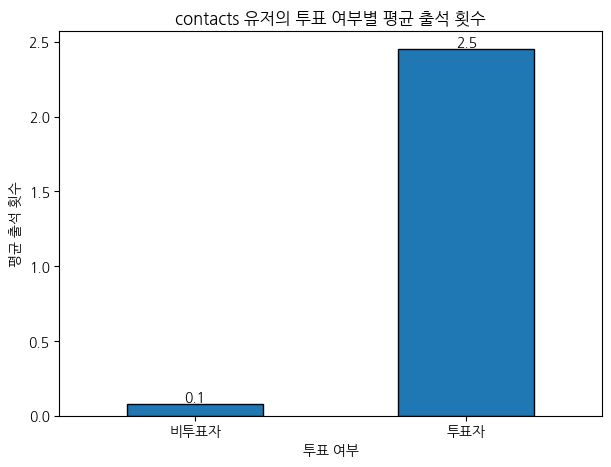

In [226]:
# 투표 여부별 평균 출석 횟수
attendance_mean = (
    network_base.loc[
        network_base['user_id'].isin(contact_ids),
        ['user_id', 'is_voter', 'attendance_count']
    ]
    .drop_duplicates('user_id')
    .groupby('is_voter')['attendance_count']
    .mean()
)

ax = attendance_mean.plot(kind='bar', figsize=(7, 5), edgecolor='black')

for i, v in enumerate(attendance_mean):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')

plt.title('contacts 유저의 투표 여부별 평균 출석 횟수')
plt.xlabel('투표 여부')
plt.ylabel('평균 출석 횟수')
plt.xticks([0, 1], ['비투표자', '투표자'], rotation=0)
plt.show()

In [227]:
# 앱 전체 최초 가입자와 소속 학교 확인
base.sort_values('created_at')[
    ['user_id', 'school_id', 'school_address', 'school_type', 'created_at']
].head(1)

,user_id,school_id,school_address,school_type,created_at
0,831962,1.0,NaN,NaN,2023-03-29 05:18:56.162368


In [228]:
# 학교별 최초 가입자를 뽑은 뒤, 가장 먼저 등장한 학교 10곳 확인
(
    network_base
    .sort_values(['created_at', 'user_id'])
    .drop_duplicates('school_id')
    .head(10)[
        ['user_id', 'school_id', 'school_address', 'region',
         'school_type', 'created_at', 'school_has_contacts']
    ]
)

,user_id,school_id,school_address,region,school_type,created_at,school_has_contacts
10,833024,5464.0,경기도 군포시,경기,H,2023-03-31 09:05:51.903699,False
11,833041,314.0,충청남도 천안시 동남구,충남,H,2023-03-31 14:32:36.425315,False
12,833112,281.0,충청남도 천안시 서북구,충남,H,2023-03-31 15:55:48.870381,False
13,833113,272.0,충청남도 천안시 서북구,충남,H,2023-03-31 15:56:52.300066,False
20,833303,289.0,충청남도 천안시 서북구,충남,H,2023-03-31 16:01:40.796317,False
35,833763,4523.0,경기도 화성시,경기,H,2023-04-01 00:24:59.710901,False
39,833974,268.0,충청남도 천안시 서북구,충남,H,2023-04-01 03:17:53.202598,False
45,834162,4732.0,경기도 의왕시,경기,H,2023-04-01 11:26:23.269860,False
54,834687,10.0,충청북도 충주시,충북,M,2023-04-04 03:19:12.336682,False
55,834771,2932.0,부산광역시 강서구,부산,M,2023-04-04 03:23:46.718202,False


In [229]:
# 가입이 가장 빨랐던 학교 10곳 + 순위
(
    network_base
    .sort_values(['created_at', 'user_id'])
    .drop_duplicates('school_id')
    .head(10)[
        ['user_id', 'school_id', 'school_address', 'region',
         'school_type', 'created_at', 'school_has_contacts']
    ]
    .reset_index(drop=True)
    .rename_axis('가입_학교_순위')
    .reset_index()
    .assign(가입_학교_순위=lambda x: x['가입_학교_순위'] + 1)
)

,가입_학교_순위,user_id,school_id,school_address,region,school_type,created_at,school_has_contacts
0,1,833024,5464.0,경기도 군포시,경기,H,2023-03-31 09:05:51.903699,False
1,2,833041,314.0,충청남도 천안시 동남구,충남,H,2023-03-31 14:32:36.425315,False
2,3,833112,281.0,충청남도 천안시 서북구,충남,H,2023-03-31 15:55:48.870381,False
3,4,833113,272.0,충청남도 천안시 서북구,충남,H,2023-03-31 15:56:52.300066,False
4,5,833303,289.0,충청남도 천안시 서북구,충남,H,2023-03-31 16:01:40.796317,False
5,6,833763,4523.0,경기도 화성시,경기,H,2023-04-01 00:24:59.710901,False
6,7,833974,268.0,충청남도 천안시 서북구,충남,H,2023-04-01 03:17:53.202598,False
7,8,834162,4732.0,경기도 의왕시,경기,H,2023-04-01 11:26:23.269860,False
8,9,834687,10.0,충청북도 충주시,충북,M,2023-04-04 03:19:12.336682,False
9,10,834771,2932.0,부산광역시 강서구,부산,M,2023-04-04 03:23:46.718202,False


In [230]:
# contacts가 존재하는 학교 10개의 지역별 학교 수
contact_region = (
    network_base.loc[network_base['school_has_contacts']]
    [['school_id', 'region']]
    .drop_duplicates('school_id')
    ['region']
    .value_counts()
)

# 전체 학교의 지역별 학교 수
all_region = (
    network_base[['school_id', 'region']]
    .drop_duplicates('school_id')
    ['region']
    .value_counts()
)

# contacts 학교 비중 / 전체 학교 비중 비교
region_compare = pd.DataFrame({
    'contacts_school_count': contact_region,
    'all_school_count': all_region
}).fillna(0)

region_compare['contacts_share'] = (
    region_compare['contacts_school_count'] / contact_region.sum() * 100
)

region_compare['all_share'] = (
    region_compare['all_school_count'] / all_region.sum() * 100
)

region_compare['enrichment'] = (
    region_compare['contacts_share'] / region_compare['all_share']
)

region_compare.sort_values('enrichment', ascending=False)

,contacts_school_count,all_school_count,contacts_share,all_share,enrichment
region,,,,,
충남,3.0,348,30.0,6.272531,4.782759
울산,1.0,121,10.0,2.180966,4.585124
인천,1.0,270,10.0,4.866619,2.054815
경기,4.0,1158,40.0,20.872386,1.916408
경남,1.0,440,10.0,7.930786,1.260909
광주,0.0,161,0.0,2.901947,0.000000
강원,0.0,242,0.0,4.361932,0.000000
경북,0.0,404,0.0,7.281903,0.000000
부산,0.0,318,0.0,5.731795,0.000000


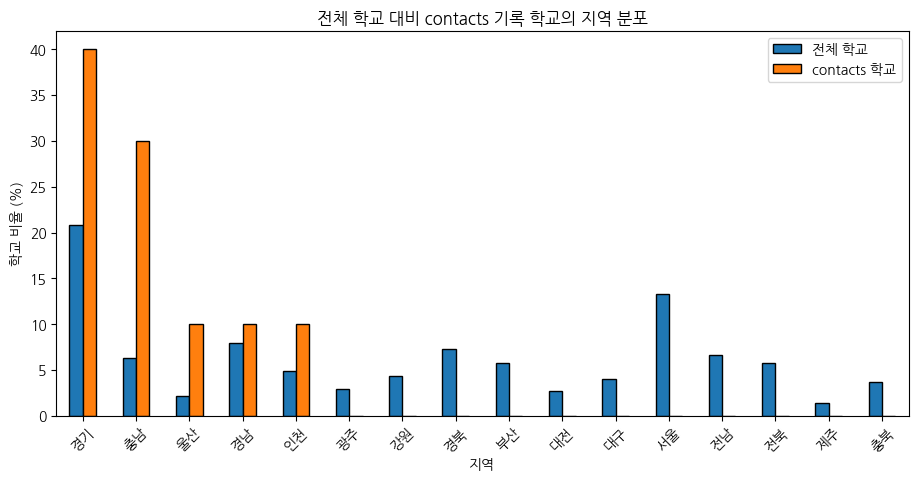

In [231]:
# 지역별 전체 학교 비중 vs contacts 학교 비중
region_compare[
    ['all_share', 'contacts_share']
].dropna().sort_values('contacts_share', ascending=False).plot(
    kind='bar',
    figsize=(11, 5),
    edgecolor='black'
)

plt.title('전체 학교 대비 contacts 기록 학교의 지역 분포')
plt.xlabel('지역')
plt.ylabel('학교 비율 (%)')
plt.xticks(rotation=45)
plt.legend(['전체 학교', 'contacts 학교'])
plt.show()

In [232]:
# contacts 기록이 존재하는 10개 학교 특성
network_base.loc[
    network_base['school_has_contacts'],
    [
        'school_id', 'school_address', 'region', 'school_type',
        'student_count', 'school_user_count',
        'first_signup', 'reached_40_at', 'days_to_40',
        'nearby_avg_distance'
    ]
].drop_duplicates('school_id').sort_values('first_signup')

,school_id,school_address,region,school_type,student_count,school_user_count,first_signup,reached_40_at,days_to_40,nearby_avg_distance
395,271.0,충청남도 천안시 서북구,충남,H,491.0,492,2023-04-19 09:06:00.719792,2023-04-28 03:43:18.503902,8.0,0.027831
632,369.0,충청남도 아산시,충남,H,578.0,578,2023-04-19 15:10:56.560337,2023-05-02 22:44:27.267798,13.0,0.044420
2886,5491.0,경기도 광주시,경기,H,486.0,486,2023-04-22 13:39:28.230920,2023-05-07 02:57:28.039304,14.0,0.048958
4769,352.0,충청남도 아산시,충남,H,491.0,491,2023-04-24 04:10:12.095185,2023-05-05 04:07:00.053881,10.0,0.042645
12476,4516.0,경기도 화성시,경기,H,507.0,510,2023-04-29 14:23:17.790839,2023-05-02 15:17:04.497555,3.0,0.021439
13342,4426.0,경상남도 거제시,경남,H,483.0,487,2023-04-29 16:06:03.134614,2023-05-16 00:18:41.426463,16.0,0.059672
37867,1478.0,인천광역시 서구,인천,M,489.0,488,2023-05-05 10:51:32.513375,2023-05-06 14:18:58.057918,1.0,0.029526
50452,5520.0,경기도 광명시,경기,M,500.0,500,2023-05-06 08:51:06.377706,2023-05-08 13:49:27.604223,2.0,0.015610
84886,5372.0,경기도 남양주시,경기,H,505.0,507,2023-05-07 02:33:46.412013,2023-05-10 23:47:35.094548,3.0,0.055833
118814,1719.0,울산광역시 울주군,울산,H,550.0,551,2023-05-07 14:15:09.397548,2023-05-13 08:00:50.712386,5.0,0.028149


고등학교가 8개, 중학교가 2개 존재한다

평균 가입자 수는 약 500명

40명 달성까지는 7일정도

근처 학교 거리에서는 뚜렷한 특징이 없다

### 가입 당시 학교 네트워크 규모 → 초기 재방문

In [233]:
# 앞에서 불러온 전처리 출석 데이터 재사용
attendance.head()

,user_id,attendance_date
0,1446852,2023-05-27
1,1446852,2023-05-28
2,1446852,2023-05-29
3,1446852,2023-05-30
4,1446852,2023-06-03


In [234]:
# 날짜형 변환
attendance['attendance_date'] = pd.to_datetime(attendance['attendance_date'])
network_base['created_at'] = pd.to_datetime(network_base['created_at'])
network_base['signup_date'] = network_base['created_at'].dt.normalize()

# 혹시 같은 유저-날짜가 중복되어 있으면 제거
attendance = attendance.drop_duplicates(['user_id', 'attendance_date'])

attendance[['user_id', 'attendance_date']].head()

,user_id,attendance_date
0,1446852,2023-05-27
1,1446852,2023-05-28
2,1446852,2023-05-29
3,1446852,2023-05-30
4,1446852,2023-06-03


가입 후 며칠 뒤 출석했는지 계산

In [235]:
# 출석 기록에 가입일 연결
att_check = attendance.merge(
    network_base[['user_id', 'signup_date']].drop_duplicates('user_id'),
    on='user_id',
    how='inner'
)

# 가입일로부터 출석일까지 경과 일수
att_check['days_after_signup'] = (
    att_check['attendance_date'] - att_check['signup_date']
).dt.days

# 가입 당일은 재방문이 아니므로 이후 출석만 사용
att_check = att_check[att_check['days_after_signup'] > 0]

att_check[['user_id', 'signup_date', 'attendance_date', 'days_after_signup']].head()

,user_id,signup_date,attendance_date,days_after_signup
0,1359398,2023-05-17,2023-05-27,10
1,1359398,2023-05-17,2023-05-29,12
2,1359398,2023-05-17,2023-05-30,13
3,1359398,2023-05-17,2023-06-02,16
4,1359398,2023-05-17,2023-06-03,17


1일·3일·7일·30일 누적 재방문 여부

In [236]:
# 기간별 누적 재방문 여부를 network_base에 추가
for day in [1, 3, 7, 30]:
    revisit_ids = att_check.loc[
        att_check['days_after_signup'] <= day,
        'user_id'
    ].unique()

    network_base[f'revisit_{day}d'] = network_base['user_id'].isin(revisit_ids)

In [237]:
# 중요한 부분: 관측기간 보정

# 출석 데이터의 마지막 관측일
attendance_end = attendance['attendance_date'].max()

# 각 기간을 온전히 관측할 수 있었는지 여부
for day in [1, 3, 7, 30]:
    network_base[f'eligible_{day}d'] = (
        network_base['signup_date'] + pd.Timedelta(days=day) <= attendance_end
    )

In [238]:
# 가입 당시 네트워크 규모별 재방문율

# 가입 순서 그룹별 기간별 재방문율
for day in [1, 3, 7, 30]:
    result = (
        network_base.loc[network_base[f'eligible_{day}d']]
        .groupby('join_order_group', observed=True)[f'revisit_{day}d']
        .agg(['count', 'mean'])
        .assign(revisit_rate=lambda x: (x['mean'] * 100).round(2))
        [['count', 'revisit_rate']]
    )

    display(result)

,count,revisit_rate
join_order_group,,
1~20번째,96067,0.24
21~39번째,77455,2.30
40~116번째,254264,3.49
117번째 이후,249190,3.75


,count,revisit_rate
join_order_group,,
1~20번째,96067,0.83
21~39번째,77454,4.75
40~116번째,254264,6.06
117번째 이후,249187,6.58


,count,revisit_rate
join_order_group,,
1~20번째,96064,3.41
21~39번째,77454,10.66
40~116번째,254262,12.30
117번째 이후,249158,13.64


,count,revisit_rate
join_order_group,,
1~20번째,96059,42.09
21~39번째,77446,48.06
40~116번째,254234,45.40
117번째 이후,249062,42.71


각각 가입 후 1일 / 3일 / 7일 / 30일 이내 누적 재방문율

In [239]:
# 가입 순서 그룹별 1·3·7·30일 누적 재방문율 저장
retention_rates = {}

for day in [1, 3, 7, 30]:
    retention_rates[f'{day}일'] = (
        network_base.loc[network_base[f'eligible_{day}d']]
        .groupby('join_order_group', observed=True)[f'revisit_{day}d']
        .mean()
        .mul(100)
    )

retention_plot = pd.DataFrame(retention_rates)

retention_plot.round(2)

,1일,3일,7일,30일
join_order_group,,,,
1~20번째,0.24,0.83,3.41,42.09
21~39번째,2.30,4.75,10.66,48.06
40~116번째,3.49,6.06,12.30,45.40
117번째 이후,3.75,6.58,13.64,42.71


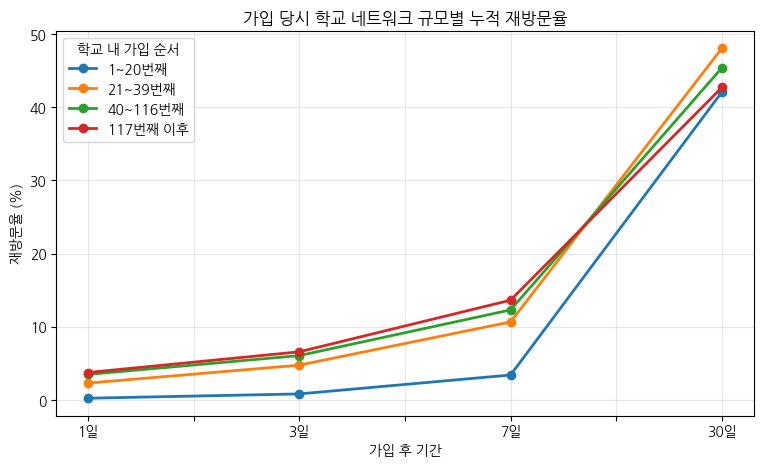

In [240]:
# 가입 당시 학교 네트워크 규모별 재방문율 변화
ax = retention_plot.T.plot(
    marker='o',
    figsize=(9, 5),
    linewidth=2
)

plt.title('가입 당시 학교 네트워크 규모별 누적 재방문율')
plt.xlabel('가입 후 기간')
plt.ylabel('재방문율 (%)')
plt.legend(title='학교 내 가입 순서')
plt.grid(alpha=0.3)
plt.show()

In [241]:
# 가입월 생성
network_base['signup_month'] = (
    pd.to_datetime(network_base['created_at'])
    .dt.to_period('M')
    .astype(str)
)

# 가입월 × 학교 가입순서별 7일 재방문율
month_7d = (
    network_base
    .groupby(['signup_month', 'join_order_group'], observed=True)
    .agg(
        users=('user_id', 'nunique'),
        revisit_7d=('revisit_7d', 'mean')
    )
    .reset_index()
)

month_7d['revisit_7d'] *= 100

month_7d

,signup_month,join_order_group,users,revisit_7d
0,2023-03,1~20번째,22,0.000000
1,2023-04,1~20번째,6952,0.000000
2,2023-04,21~39번째,2461,0.000000
3,2023-04,40~116번째,5927,0.000000
4,2023-04,117번째 이후,3690,0.000000
5,2023-05,1~20번째,87261,3.510159
6,2023-05,21~39번째,72497,9.999034
7,2023-05,40~116번째,241312,11.609452
8,2023-05,117번째 이후,234401,12.888170
9,2023-06,1~20번째,1274,9.105181


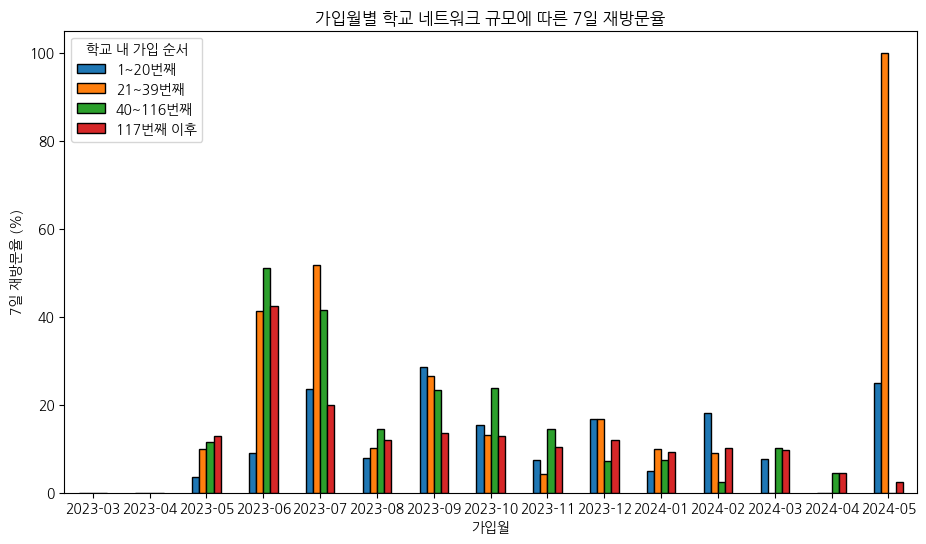

In [242]:
# 월별로 같은 가입순서 집단 비교
month_7d_pivot = month_7d.pivot(
    index='signup_month',
    columns='join_order_group',
    values='revisit_7d'
)

month_7d_pivot.plot(
    kind='bar',
    figsize=(11, 6),
    edgecolor='black'
)

plt.title('가입월별 학교 네트워크 규모에 따른 7일 재방문율')
plt.xlabel('가입월')
plt.ylabel('7일 재방문율 (%)')
plt.xticks(rotation=0)
plt.legend(title='학교 내 가입 순서')
plt.show()

#### 메모리 체크포인트 — 친구 상호작용 분석 전

In [243]:
# 이후 분석에 필요한 network_base 컬럼만 디스크에 임시 저장
checkpoint_cols = [
    'user_id', 'created_at', 'join_order', 'signup_date',
    'revisit_1d', 'revisit_3d', 'revisit_7d', 'revisit_30d',
    'eligible_1d', 'eligible_3d', 'eligible_7d', 'eligible_30d'
]
network_base[checkpoint_cols].to_pickle('/content/network_base_friend_checkpoint.pkl')


In [244]:
# 앞선 학교·연락처 EDA 변수 전체 해제 후 필요한 데이터만 다시 로드
%reset -f

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib

project_path = Path('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트')
clean_path = project_path / '01_전처리 완료된 csv'
path = clean_path

network_base = pd.read_pickle('/content/network_base_friend_checkpoint.pkl')
attendance = pd.read_csv(
    path / 'accounts_attendance_clean.csv',
    usecols=['user_id', 'attendance_date']
)
attendance['attendance_date'] = pd.to_datetime(attendance['attendance_date'])


### 초기 친구 연결 → 재방문

In [245]:
# 친구요청 분석에 필요한 컬럼만 로드
friendrequest = pd.read_csv(
    path / 'accounts_friendrequest_cleaned.csv',
    usecols=['send_user_id', 'receive_user_id', 'status', 'created_at', 'updated_at']
)

friendrequest['created_at'] = pd.to_datetime(friendrequest['created_at'])
friendrequest['updated_at'] = pd.to_datetime(friendrequest['updated_at'])

friendrequest.head()


,status,created_at,updated_at,receive_user_id,send_user_id
0,P,2023-04-17 18:29:11,2023-04-17 18:29:11,831962,837521
1,A,2023-04-17 18:29:11,2023-04-22 06:02:53,832151,837521
2,A,2023-04-17 18:29:11,2023-04-18 19:28:41,832340,837521
3,A,2023-04-17 18:29:11,2023-04-19 11:05:04,833041,837521
4,P,2023-04-17 18:29:11,2023-04-17 18:29:11,834415,837521


In [246]:
# 요청을 보낸 시점이 가입 후 3일 이내인지

# 유저별 가입일 매핑용
signup_map = network_base.set_index('user_id')['signup_date']

# 친구요청을 보낸 유저의 가입일
friendrequest['send_signup_date'] = (
    friendrequest['send_user_id'].map(signup_map)
)

# 가입 후 며칠 뒤 요청했는지 계산
friendrequest['send_days'] = (
    friendrequest['created_at'].dt.normalize()
    - friendrequest['send_signup_date']
).dt.days

In [247]:
# 친구요청을 받은 유저의 가입일
friendrequest['receive_signup_date'] = (
    friendrequest['receive_user_id'].map(signup_map)
)

# 가입 후 며칠 뒤 요청을 받았는지 계산
friendrequest['receive_days'] = (
    friendrequest['created_at'].dt.normalize()
    - friendrequest['receive_signup_date']
).dt.days

In [248]:
# 가입 후 3일 내 친구요청 송신/수신 여부
# 가입 후 0~3일 내 요청을 보낸 유저
send_3d_ids = friendrequest.loc[
    friendrequest['send_days'].between(0, 3),
    'send_user_id'
].unique()

# 가입 후 0~3일 내 요청을 받은 유저
receive_3d_ids = friendrequest.loc[
    friendrequest['receive_days'].between(0, 3),
    'receive_user_id'
].unique()

# 유저 단위 지표 추가
network_base['sent_friend_3d'] = network_base['user_id'].isin(send_3d_ids)
network_base['received_friend_3d'] = network_base['user_id'].isin(receive_3d_ids)

# 둘 중 하나라도 있으면 초기 친구 연결 경험
network_base['friend_interaction_3d'] = (
    network_base['sent_friend_3d'] |
    network_base['received_friend_3d']
)

In [249]:
# 초기 친구 연결 여부별 재방문율

# 초기 친구 상호작용 여부에 따른 재방문율
(
    network_base.groupby('friend_interaction_3d')
    [['revisit_1d', 'revisit_3d', 'revisit_7d', 'revisit_30d']]
    .mean()
    .mul(100)
    .round(2)
)

,revisit_1d,revisit_3d,revisit_7d,revisit_30d
friend_interaction_3d,,,,
False,0.18,0.30,0.72,21.16
True,3.04,5.45,11.54,44.66


In [250]:
# 초기 친구 상호작용 여부별 누적 재방문율 + 시각화

# 기간별로 충분히 관측 가능한 유저만 사용해 재방문율 계산
friend_revisit = pd.DataFrame()

for day in [1, 3, 7, 30]:
    rate = (
        network_base.loc[network_base[f'eligible_{day}d']]
        .groupby('friend_interaction_3d')[f'revisit_{day}d']
        .mean()
        .mul(100)
    )
    friend_revisit[f'{day}일'] = rate

friend_revisit.round(2)

,1일,3일,7일,30일
friend_interaction_3d,,,,
False,0.18,0.29,0.71,21.27
True,3.04,5.45,11.54,44.66


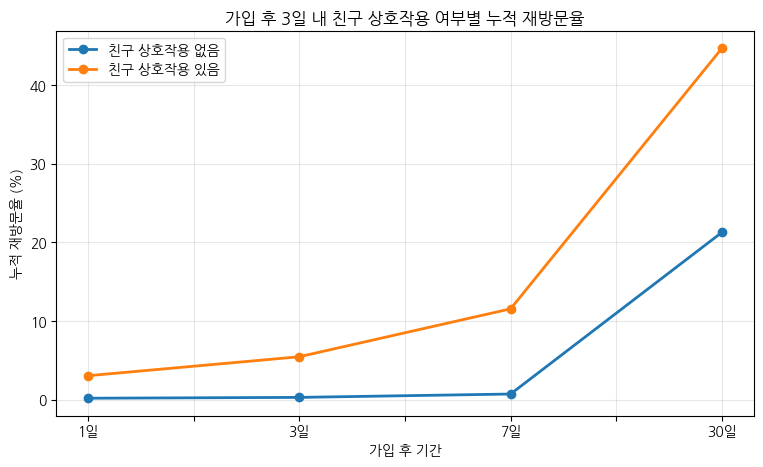

In [251]:
# 초기 친구 상호작용 유무별 누적 재방문율 시각화
ax = friend_revisit.T.plot(
    marker='o',
    figsize=(9, 5),
    linewidth=2
)

plt.title('가입 후 3일 내 친구 상호작용 여부별 누적 재방문율')
plt.xlabel('가입 후 기간')
plt.ylabel('누적 재방문율 (%)')
plt.legend(['친구 상호작용 없음', '친구 상호작용 있음'])
plt.grid(alpha=0.3)
plt.show()

In [252]:
# 가입 후 0~3일 내 보낸 친구요청 수
sent_count_3d = (
    friendrequest[friendrequest['send_days'].between(0, 3)]
    .groupby('send_user_id')
    .size()
)

# 가입 후 0~3일 내 받은 친구요청 수
received_count_3d = (
    friendrequest[friendrequest['receive_days'].between(0, 3)]
    .groupby('receive_user_id')
    .size()
)

# 송신 + 수신 요청 횟수
network_base['friend_request_3d_count'] = (
    network_base['user_id'].map(sent_count_3d).fillna(0) +
    network_base['user_id'].map(received_count_3d).fillna(0)
).astype(int)

In [253]:
network_base['friend_request_3d_count'].describe(
    percentiles=[.25, .5, .75, .9, .95, .99]
)

,friend_request_3d_count
count,676980.000000
mean,37.546926
std,27.478380
min,0.000000
25%,18.000000
50%,33.000000
75%,52.000000
90%,72.000000
95%,87.000000
99%,123.000000


In [254]:
# 실제 분포를 반영한 친구요청 횟수 구간
network_base['friend_count_group'] = pd.cut(
    network_base['friend_request_3d_count'],
    bins=[-1, 0, 17, 32, 51, 71, 122, float('inf')],
    labels=['0', '1~17', '18~32', '33~51', '52~71', '72~122', '123+']
)

# 횟수 구간별 7일·30일 재방문율
friend_count_result = (
    network_base.groupby('friend_count_group', observed=True)
    .agg(
        users=('user_id', 'nunique'),
        revisit_7d=('revisit_7d', 'mean'),
        revisit_30d=('revisit_30d', 'mean')
    )
)

friend_count_result[['revisit_7d', 'revisit_30d']] *= 100
friend_count_result.round(2)

,users,revisit_7d,revisit_30d
friend_count_group,,,
0,12201,0.72,21.16
1~17,152243,6.87,36.21
18~32,170153,12.61,45.80
33~51,171805,13.28,47.86
52~71,100136,12.95,47.81
72~122,63526,12.74,47.94
123+,6916,13.22,46.78


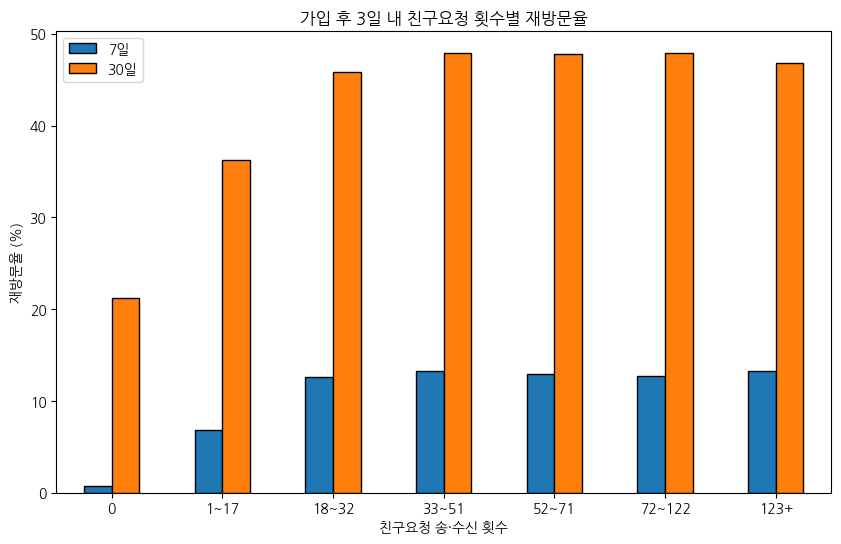

In [255]:
ax = friend_count_result[['revisit_7d', 'revisit_30d']].plot(
    kind='bar',
    figsize=(10, 6),
    edgecolor='black'
)

plt.title('가입 후 3일 내 친구요청 횟수별 재방문율')
plt.xlabel('친구요청 송·수신 횟수')
plt.ylabel('재방문율 (%)')
plt.xticks(rotation=0)
plt.legend(['7일', '30일'])
plt.show()

### 친구요청 유형 구분 [없음 / 보내기만 / 받기만 / 둘 다]

In [256]:
# 가입 후 3일 내 친구요청 유형 구분
network_base['friend_3d_type'] = '없음'

network_base.loc[
    network_base['sent_friend_3d'] & ~network_base['received_friend_3d'],
    'friend_3d_type'
] = '보내기만'

network_base.loc[
    ~network_base['sent_friend_3d'] & network_base['received_friend_3d'],
    'friend_3d_type'
] = '받기만'

network_base.loc[
    network_base['sent_friend_3d'] & network_base['received_friend_3d'],
    'friend_3d_type'
] = '송수신 모두'

In [257]:
network_base['friend_3d_type'].value_counts()

,count
friend_3d_type,
송수신 모두,599377
받기만,33626
보내기만,31776
없음,12201


In [258]:
# 충분히 7일 관측 가능한 유저만 비교
friend_type_7d = (
    network_base.loc[network_base['eligible_7d']]
    .groupby('friend_3d_type')['revisit_7d']
    .agg(['count', 'mean'])
)

friend_type_7d['revisit_rate'] = (
    friend_type_7d['mean'] * 100
).round(2)

friend_type_7d

,count,mean,revisit_rate
friend_3d_type,,,
받기만,33625,0.023257,2.33
보내기만,31751,0.170357,17.04
송수신 모두,599371,0.117648,11.76
없음,12191,0.007136,0.71


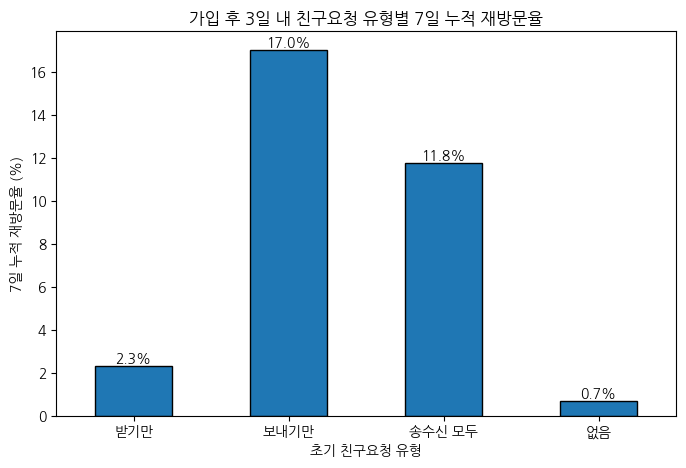

In [259]:
# 친구요청 유형별 7일 누적 재방문율
ax = friend_type_7d['revisit_rate'].plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

for i, v in enumerate(friend_type_7d['revisit_rate']):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.title('가입 후 3일 내 친구요청 유형별 7일 누적 재방문율')
plt.xlabel('초기 친구요청 유형')
plt.ylabel('7일 누적 재방문율 (%)')
plt.xticks(rotation=0)
plt.show()

In [260]:
# 컬럼명 먼저 확인
[c for c in network_base.columns
 if any(x in c.lower() for x in ['friend', 'vote', 'qset', 'question', 'join_order'])]

['join_order',
 'sent_friend_3d',
 'received_friend_3d',
 'friend_interaction_3d',
 'friend_request_3d_count',
 'friend_count_group',
 'friend_3d_type']

In [261]:
# 투표·질문세트 분석에 필요한 컬럼만 추가 로드
uqr = pd.read_csv(
    path / 'accounts_userquestionrecord_cleaned.csv',
    usecols=['user_id', 'created_at']
)
qset = pd.read_csv(
    path / 'polls_questionset_clean.csv',
    usecols=['user_id', 'status', 'created_at']
)

uqr['created_at'] = pd.to_datetime(uqr['created_at'])
qset['created_at'] = pd.to_datetime(qset['created_at'])
network_base['created_at'] = pd.to_datetime(network_base['created_at'])


In [262]:
# 유저별 가입 시간
signup = (
    network_base[['user_id', 'created_at']]
    .drop_duplicates('user_id')
    .rename(columns={'created_at': 'signup_at'})
)

In [263]:
# 실제 투표 기록과 가입 시간 연결
vote_check = (
    uqr[['user_id', 'created_at']]
    .rename(columns={'created_at': 'vote_at'})
    .merge(signup, on='user_id', how='inner')
)

vote_check = vote_check[
    (vote_check['vote_at'] >= vote_check['signup_at']) &
    (vote_check['vote_at'] <= vote_check['signup_at'] + pd.Timedelta(days=3))
]

vote_3d_ids = set(vote_check['user_id'])

network_base['vote_3d'] = network_base['user_id'].isin(vote_3d_ids)

In [264]:
# 완료(F)된 질문세트만 사용
qset_check = (
    qset.loc[qset['status'] == 'F', ['user_id', 'created_at']]
    .rename(columns={'created_at': 'qset_at'})
    .merge(signup, on='user_id', how='inner')
)

qset_check = qset_check[
    (qset_check['qset_at'] >= qset_check['signup_at']) &
    (qset_check['qset_at'] <= qset_check['signup_at'] + pd.Timedelta(days=3))
]

qset_3d_ids = set(qset_check['user_id'])

network_base['qset_complete_3d'] = network_base['user_id'].isin(qset_3d_ids)

In [265]:
# 친구요청 + 투표 + 질문세트 완료가 모두 없는 유저
network_base['no_interaction_3d'] = (
    ~network_base['sent_friend_3d'] &
    ~network_base['received_friend_3d'] &
    ~network_base['vote_3d'] &
    ~network_base['qset_complete_3d']
)

# 결과 확인
network_base[
    ['sent_friend_3d', 'received_friend_3d',
     'vote_3d', 'qset_complete_3d', 'no_interaction_3d']
].mean().mul(100).round(2)

,0
sent_friend_3d,93.23
received_friend_3d,93.50
vote_3d,0.68
qset_complete_3d,0.69
no_interaction_3d,1.80


<가입 당일(D0) 친구요청 → D1~D7 재방문>

In [266]:
# ① 기존 3일 친구요청 유형 비교 — 탐색 결과

# 3일 내 친구요청 유형별 7일 재방문
friend_3d_result = (
    network_base.groupby('friend_3d_type')
    .agg(
        users=('user_id', 'nunique'),
        revisit_rate=('revisit_7d', 'mean')
    )
)

friend_3d_result['revisit_rate'] *= 100
friend_3d_result.round(2)

,users,revisit_rate
friend_3d_type,,
받기만,33626,2.33
보내기만,31776,17.03
송수신 모두,599377,11.76
없음,12201,0.72


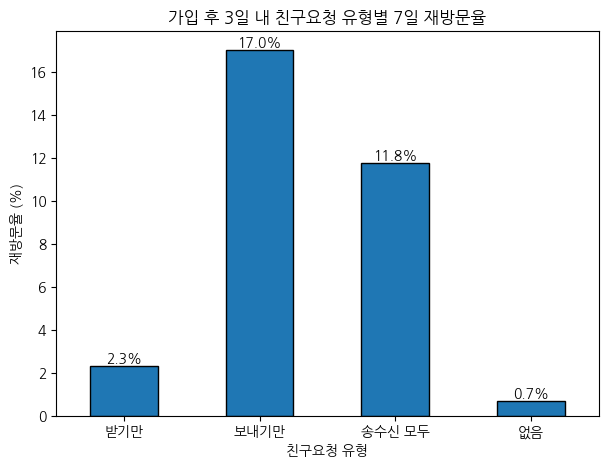

In [267]:
ax = friend_3d_result['revisit_rate'].plot(
    kind='bar', figsize=(7, 5), edgecolor='black'
)

for i, v in enumerate(friend_3d_result['revisit_rate']):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.title('가입 후 3일 내 친구요청 유형별 7일 재방문율')
plt.xlabel('친구요청 유형')
plt.ylabel('재방문율 (%)')
plt.xticks(rotation=0)
plt.show()

In [268]:
# 앞에서 불러온 친구요청 데이터를 재사용
friend = friendrequest.copy()
friend['created_at'] = pd.to_datetime(friend['created_at'])

signup = (
    network_base[['user_id', 'created_at']]
    .drop_duplicates('user_id')
    .rename(columns={'created_at': 'signup_at'})
)

In [269]:
# 가입 당일 보낸 친구요청
sent_d0 = (
    friend[['send_user_id', 'created_at']]
    .rename(columns={'send_user_id': 'user_id', 'created_at': 'friend_at'})
    .merge(signup, on='user_id', how='inner')
)

sent_d0 = sent_d0[
    (sent_d0['friend_at'] >= sent_d0['signup_at']) &
    (sent_d0['friend_at'].dt.date == sent_d0['signup_at'].dt.date)
]

sent_d0_ids = set(sent_d0['user_id'])

In [270]:
# 가입 당일 받은 친구요청
received_d0 = (
    friend[['receive_user_id', 'created_at']]
    .rename(columns={'receive_user_id': 'user_id', 'created_at': 'friend_at'})
    .merge(signup, on='user_id', how='inner')
)

received_d0 = received_d0[
    (received_d0['friend_at'] >= received_d0['signup_at']) &
    (received_d0['friend_at'].dt.date == received_d0['signup_at'].dt.date)
]

received_d0_ids = set(received_d0['user_id'])

In [271]:
# 유형 생성

network_base['sent_friend_d0'] = network_base['user_id'].isin(sent_d0_ids)
network_base['received_friend_d0'] = network_base['user_id'].isin(received_d0_ids)

network_base['friend_d0_type'] = '없음'

network_base.loc[
    network_base['sent_friend_d0'] & ~network_base['received_friend_d0'],
    'friend_d0_type'
] = '보내기만'

network_base.loc[
    ~network_base['sent_friend_d0'] & network_base['received_friend_d0'],
    'friend_d0_type'
] = '받기만'

network_base.loc[
    network_base['sent_friend_d0'] & network_base['received_friend_d0'],
    'friend_d0_type'
] = '송수신 모두'

In [272]:
import ast

# 앞에서 불러온 attendance 데이터 재사용

In [273]:
attendance.columns.tolist()

['user_id', 'attendance_date']

In [274]:
# 출석일과 가입일 연결
att = attendance[['user_id', 'attendance_date']].copy()
att['attendance_date'] = pd.to_datetime(att['attendance_date']).dt.normalize()

signup = (
    network_base[['user_id', 'created_at']]
    .drop_duplicates('user_id')
    .rename(columns={'created_at': 'signup_at'})
)

signup['signup_at'] = pd.to_datetime(signup['signup_at'])
signup['signup_date'] = signup['signup_at'].dt.normalize()

att = att.merge(
    signup[['user_id', 'signup_date']],
    on='user_id',
    how='inner'
)

# 가입 다음날(D1) ~ D7 사이 출석 여부
att_d1_7 = att[
    (att['attendance_date'] >= att['signup_date'] + pd.Timedelta(days=1)) &
    (att['attendance_date'] <= att['signup_date'] + pd.Timedelta(days=7))
]

revisit_d1_7_ids = set(att_d1_7['user_id'])

network_base['revisit_d1_7'] = (
    network_base['user_id'].isin(revisit_d1_7_ids)
)

network_base['revisit_d1_7'].value_counts()

,count
revisit_d1_7,
False,600184
True,76796


가입 당일 친구요청 유형 → D1~D7 재방문

In [275]:
d0_result = (
    network_base.groupby('friend_d0_type')
    .agg(
        users=('user_id', 'nunique'),
        revisit_rate=('revisit_d1_7', 'mean')
    )
)

d0_result['revisit_rate'] *= 100
d0_result.round(2)

,users,revisit_rate
friend_d0_type,,
받기만,36495,4.52
보내기만,125192,15.31
송수신 모두,480327,11.49
없음,34966,2.28


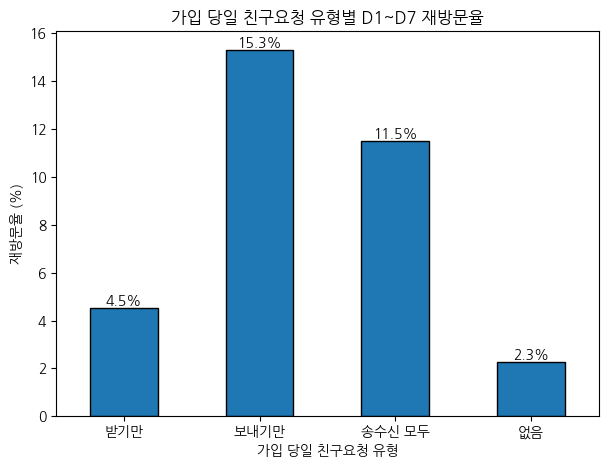

In [276]:
ax = d0_result['revisit_rate'].plot(
    kind='bar', figsize=(7, 5), edgecolor='black'
)

for i, v in enumerate(d0_result['revisit_rate']):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.title('가입 당일 친구요청 유형별 D1~D7 재방문율')
plt.xlabel('가입 당일 친구요청 유형')
plt.ylabel('재방문율 (%)')
plt.xticks(rotation=0)
plt.show()

In [277]:
# ③ 학교 네트워크 규모에 따라 효과가 다른지

# 가입 당시 이미 존재했던 같은 학교 유저 수
network_base['network_at_signup'] = network_base['join_order'] - 1

network_base['network_group'] = pd.cut(
    network_base['network_at_signup'],
    bins=[-1, 19, 39, 59, 99, 199, float('inf')],
    labels=['0~19', '20~39', '40~59', '60~99', '100~199', '200+']
)

network_friend = (
    network_base.groupby(
        ['network_group', 'friend_d0_type'],
        observed=True
    )
    .agg(
        users=('user_id', 'nunique'),
        revisit_rate=('revisit_d1_7', 'mean')
    )
    .reset_index()
)

network_friend['revisit_rate'] *= 100
network_friend.round(2)

,network_group,friend_d0_type,users,revisit_rate
0,0~19,받기만,10671,2.01
1,0~19,보내기만,19886,3.08
2,0~19,송수신 모두,50022,4.58
3,0~19,없음,15488,1.01
4,20~39,받기만,6038,6.00
5,20~39,보내기만,12194,12.37
6,20~39,송수신 모두,58931,11.46
7,20~39,없음,4188,2.94
8,40~59,받기만,4482,5.49
9,40~59,보내기만,9458,14.07


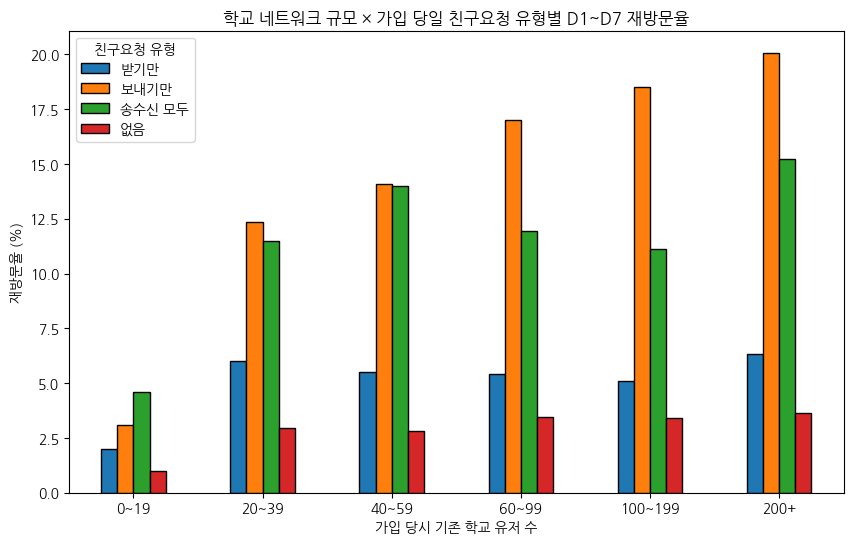

In [278]:
network_pivot = network_friend.pivot(
    index='network_group',
    columns='friend_d0_type',
    values='revisit_rate'
)

network_pivot.plot(
    kind='bar',
    figsize=(10, 6),
    edgecolor='black'
)

plt.title('학교 네트워크 규모 × 가입 당일 친구요청 유형별 D1~D7 재방문율')
plt.xlabel('가입 당시 기존 학교 유저 수')
plt.ylabel('재방문율 (%)')
plt.xticks(rotation=0)
plt.legend(title='친구요청 유형')
plt.show()

### 가입 → 첫 핵심 행동까지 걸린 시간

In [279]:
# 가입 시간
signup = (
    network_base[['user_id', 'created_at']]
    .drop_duplicates('user_id')
    .rename(columns={'created_at': 'signup_at'})
)

signup['signup_at'] = pd.to_datetime(signup['signup_at'])

In [280]:
# 친구수락 시간
friendrequest['created_at'] = pd.to_datetime(friendrequest['created_at'])

# updated_at이 있으면 실제 상태 변경 시점 사용
friend_time_col = (
    'updated_at' if 'updated_at' in friendrequest.columns
    else 'created_at'
)

friendrequest[friend_time_col] = pd.to_datetime(
    friendrequest[friend_time_col]
)

accepted = friendrequest[
    friendrequest['status'] == 'A'
].copy()

# 송신자와 수신자 모두 친구관계 형성 유저
sent_accept = accepted[
    ['send_user_id', friend_time_col]
].rename(columns={
    'send_user_id': 'user_id',
    friend_time_col: 'friend_accept_at'
})

received_accept = accepted[
    ['receive_user_id', friend_time_col]
].rename(columns={
    'receive_user_id': 'user_id',
    friend_time_col: 'friend_accept_at'
})

first_friend = (
    pd.concat([sent_accept, received_accept])
    .groupby('user_id')['friend_accept_at']
    .min()
)

In [281]:
# 첫 투표
uqr['created_at'] = pd.to_datetime(uqr['created_at'])

first_vote = (
    uqr.groupby('user_id')['created_at']
    .min()
    .rename('first_vote_at')
)

# 첫 질문세트 완료
qset['created_at'] = pd.to_datetime(qset['created_at'])

first_qset = (
    qset[qset['status'] == 'F']
    .groupby('user_id')['created_at']
    .min()
    .rename('first_qset_at')
)

In [282]:
import numpy as np

In [283]:
# signup 관련 컬럼 확인
[c for c in network_base.columns if 'signup' in c]

['signup_date', 'network_at_signup']

In [284]:
# 유저 created_at = 가입 시점
network_base['signup_at'] = pd.to_datetime(network_base['created_at'])

# 첫 행동 시점도 datetime으로 통일
network_base['first_friend_at'] = pd.to_datetime(network_base['user_id'].map(first_friend))
network_base['first_vote_at'] = pd.to_datetime(network_base['user_id'].map(first_vote))
network_base['first_qset_at'] = pd.to_datetime(network_base['user_id'].map(first_qset))

# 가입 → 첫 행동까지 소요시간(시간)
for name in ['friend', 'vote', 'qset']:
    network_base[f'{name}_first_hours'] = (
        network_base[f'first_{name}_at'] - network_base['signup_at']
    ).dt.total_seconds() / 3600

    # 가입 이전 기록은 분석 제외
    network_base.loc[
        network_base[f'{name}_first_hours'] < 0,
        f'{name}_first_hours'
    ] = np.nan

network_base[
    ['signup_at', 'first_friend_at', 'first_vote_at', 'first_qset_at']
].head()

,signup_at,first_friend_at,first_vote_at,first_qset_at
148922,2023-05-08 11:36:21.504116,2023-05-11 12:38:21,NaT,NaT
218976,2023-05-10 07:59:11.082388,NaT,NaT,NaT
226778,2023-05-10 11:40:57.616770,2023-05-10 12:11:03,NaT,NaT
227237,2023-05-10 11:53:00.563227,2023-05-10 12:11:05,NaT,NaT
227311,2023-05-10 11:54:28.888525,2023-05-13 05:24:39,NaT,NaT


In [285]:
first_action_summary = network_base[
    ['friend_first_hours',
     'vote_first_hours',
     'qset_first_hours']
].describe(
    percentiles=[.25, .5, .75, .9, .95]
).T

first_action_summary.round(2)

,count,mean,std,min,25%,50%,75%,90%,95%,max
friend_first_hours,650211.0,15.59,102.69,0.0,0.05,0.18,1.63,23.18,70.61,8418.36
vote_first_hours,4849.0,15.18,64.80,0.0,0.02,0.10,4.94,33.91,72.93,2030.52
qset_first_hours,4846.0,10.11,41.01,0.0,0.01,0.02,0.14,21.61,51.06,657.18


3. 행동 도달 속도 구간 만들기

일단 직관적으로:

- 1시간 이내
- 1~6시간
- 6~24시간
- 1~3일
- 3일 이후
- 미도달

In [286]:
[c for c in network_base.columns if 'first_' in c or 'signup_at' in c]

['signup_at',
 'first_friend_at',
 'first_vote_at',
 'first_qset_at',
 'friend_first_hours',
 'vote_first_hours',
 'qset_first_hours']

In [287]:

# 가입 → 첫 투표까지 걸린 시간
network_base['vote_first_hours'] = (
    network_base['first_vote_at'] - network_base['signup_at']
).dt.total_seconds() / 3600

# 가입 → 첫 질문세트 완료까지 걸린 시간
network_base['qset_first_hours'] = (
    network_base['first_qset_at'] - network_base['signup_at']
).dt.total_seconds() / 3600

# 가입 이전 기록은 제외
for col in ['vote_first_hours', 'qset_first_hours']:
    network_base.loc[network_base[col] < 0, col] = np.nan

In [288]:
def make_time_group(col):

    result = pd.cut(
        network_base[col],
        bins=[-0.01, 1, 6, 24, 72, float('inf')],
        labels=[
            '1시간 이내',
            '1~6시간',
            '6~24시간',
            '1~3일',
            '3일 이후'
        ]
    ).astype('object')

    return result.fillna('미도달')


network_base['friend_time_group'] = make_time_group('friend_first_hours')
network_base['vote_time_group'] = make_time_group('vote_first_hours')
network_base['qset_time_group'] = make_time_group('qset_first_hours')

In [289]:
network_base[
    ['friend_first_hours', 'vote_first_hours', 'qset_first_hours']
].describe(
    percentiles=[.25, .5, .75, .9, .95]
).T.round(2)

,count,mean,std,min,25%,50%,75%,90%,95%,max
friend_first_hours,650211.0,15.59,102.69,0.0,0.05,0.18,1.63,23.18,70.61,8418.36
vote_first_hours,4849.0,15.18,64.80,0.0,0.02,0.10,4.94,33.91,72.93,2030.52
qset_first_hours,4846.0,10.11,41.01,0.0,0.01,0.02,0.14,21.61,51.06,657.18


In [290]:
# 첫 친구수락 속도 × 재방문율

friend_speed = (
    network_base.groupby('friend_time_group')
    .agg(
        users=('user_id', 'nunique'),
        revisit_7d=('revisit_7d', 'mean'),
        revisit_30d=('revisit_30d', 'mean')
    )
)

friend_speed[['revisit_7d', 'revisit_30d']] *= 100

friend_speed.round(2)

,users,revisit_7d,revisit_30d
friend_time_group,,,
1~3일,31418,5.13,48.83
1~6시간,74410,10.61,45.37
1시간 이내,461445,13.51,45.58
3일 이후,31673,2.65,48.55
6~24시간,51265,7.47,46.14
미도달,26769,1.08,3.62


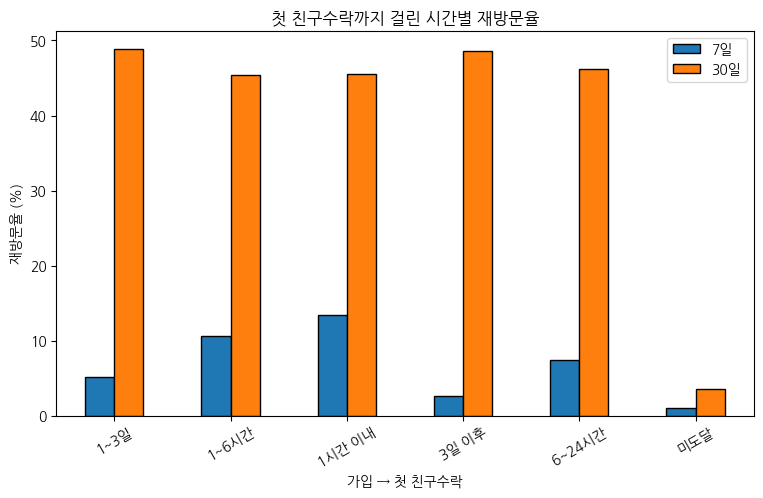

In [291]:
friend_speed[['revisit_7d', 'revisit_30d']].plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('첫 친구수락까지 걸린 시간별 재방문율')
plt.xlabel('가입 → 첫 친구수락')
plt.ylabel('재방문율 (%)')
plt.xticks(rotation=30)
plt.legend(['7일', '30일'])
plt.show()

In [292]:
# 첫 투표 / 질문세트 완료도 똑같이

def action_speed_result(group_col):

    result = (
        network_base.groupby(group_col)
        .agg(
            users=('user_id', 'nunique'),
            revisit_7d=('revisit_7d', 'mean'),
            revisit_30d=('revisit_30d', 'mean')
        )
    )

    result[['revisit_7d', 'revisit_30d']] *= 100

    return result.round(2)


vote_speed = action_speed_result('vote_time_group')
qset_speed = action_speed_result('qset_time_group')

vote_speed

,users,revisit_7d,revisit_30d
vote_time_group,,,
1~3일,364,4.95,42.86
1~6시간,538,5.20,39.59
1시간 이내,3150,8.19,36.35
3일 이후,245,2.86,42.45
6~24시간,552,3.99,40.04
미도달,672131,11.38,44.28


In [293]:
qset_speed

,users,revisit_7d,revisit_30d
qset_time_group,,,
1~3일,258,1.94,41.86
1~6시간,197,5.08,34.52
1시간 이내,3875,7.95,37.47
3일 이후,183,0.55,44.81
6~24시간,333,3.00,39.94
미도달,672134,11.38,44.28


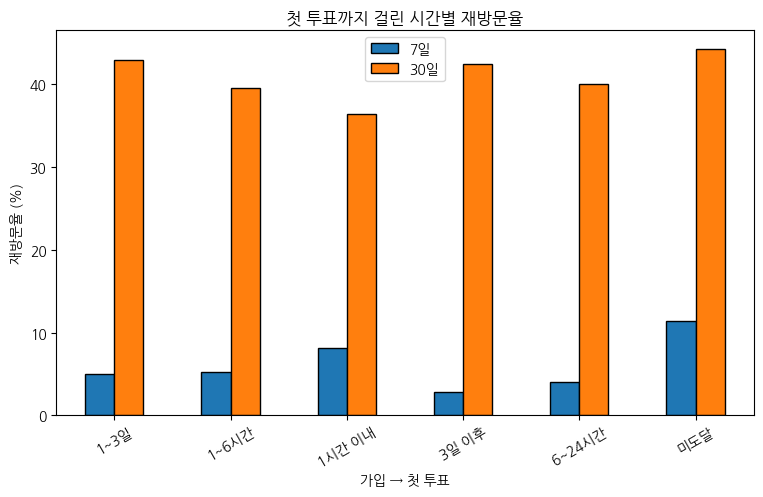

In [294]:
vote_speed[['revisit_7d', 'revisit_30d']].plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('첫 투표까지 걸린 시간별 재방문율')
plt.xlabel('가입 → 첫 투표')
plt.ylabel('재방문율 (%)')
plt.xticks(rotation=30)
plt.legend(['7일', '30일'])
plt.show()

In [295]:
# 출석 로그 관측기간 확인
attendance['attendance_date'] = pd.to_datetime(attendance['attendance_date'])

attendance['attendance_date'].min(), attendance['attendance_date'].max()

(Timestamp('2023-05-27 00:00:00'), Timestamp('2024-05-09 00:00:00'))

In [296]:
# 4/17 이전 가입자 수
cutoff = pd.Timestamp('2023-04-17')

early_users = network_base[
    network_base['created_at'] < cutoff
]

early_users['user_id'].nunique()

88

In [297]:
# 친구요청에 한 번이라도 등장한 유저
friend_users = set(friendrequest['send_user_id']) | set(friendrequest['receive_user_id'])

early_check = (
    early_users['user_id']
    .isin(friend_users)
    .value_counts()
)

early_check

,count
user_id,
True,87
False,1


In [298]:
# 친구요청 로그 시작 구간 확인
friend_daily = (
    friendrequest
    .assign(date=friendrequest['created_at'].dt.date)
    .groupby('date')
    .size()
    .head(25)
)

friend_daily

,0
date,
2023-04-17,7
2023-04-18,1
2023-04-19,6860
2023-04-20,9530
2023-04-21,9022
2023-04-22,12812
2023-04-23,17544
2023-04-24,13071
2023-04-25,13176


In [299]:
may6 = friendrequest[
    friendrequest['created_at'].dt.date == pd.Timestamp('2023-05-06').date()
]

pd.Series({
    '전체 레코드': len(may6),
    '송신 유저 수': may6['send_user_id'].nunique(),
    '수신 유저 수': may6['receive_user_id'].nunique(),
    '고유 송수신 쌍': may6[['send_user_id', 'receive_user_id']].drop_duplicates().shape[0]
})

,0
전체 레코드,591019
송신 유저 수,41896
수신 유저 수,63723
고유 송수신 쌍,590306


In [300]:
may6.groupby(
    ['send_user_id', 'receive_user_id']
).size().describe()

,0
count,590306.000000
mean,1.001208
std,0.043288
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,7.000000


In [301]:
# 메모리 부족 방지 및 변수 초기화 (재현성 유지)
%reset -f

---

# 2. 서비스·네트워크 EDA

학교 네트워크, 친구 상호작용, 투표·재방문, 결제·포인트 구조를 탐색합니다.

9월 11일까지 진행했던 분석에서 재방문이라는 지표를 여러 가설 분석 및 시각화에 활용하였는데 재방문의 정의를 출석 attendence 컬럼을 기준으로 잡고 진행 중이었어서,

5월 27일 이전의 수많은 가입자에 대한 행동 지표가 왜곡되었을 가능성이 높다.

따라서 재방문 및 행동 지표 정의를 다시 하여 이전에 진행했던 분석 그래프를 상황에 맞게 다시 그리려고 한다.

In [302]:
from pathlib import Path

In [303]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [304]:
# 프로젝트 공통 경로
project_path = Path('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트')
project = project_path
raw_path = project_path / '00_원본 csv'
clean_path = project_path / '01_전처리 완료된 csv'
path = clean_path

In [305]:
# 한글 폰트 지원 패키지 설치
!pip install -q koreanize-matplotlib

# matplotlib 한글 폰트 적용
import koreanize_matplotlib

In [306]:
import pandas as pd

In [307]:
# 핵심 테이블 — 실제 분석에 필요한 컬럼만 로드
users = pd.read_csv(path / 'accounts_user_cleaned.csv', usecols=['id', 'group_id', 'created_at'])
groups = pd.read_csv(path / 'accounts_group_cleaned.csv', usecols=['id', 'school_id', 'grade', 'class_num'])
schools = pd.read_csv(path / 'accounts_school_cleaned.csv', usecols=['id', 'student_count', 'school_type', 'address'])
nearby = pd.read_csv(path / 'accounts_nearbyschool_cleaned.csv', usecols=['school_id', 'nearby_school_id', 'distance'])

# 행동/보조 테이블도 필요한 컬럼만 로드
attendance = pd.read_csv(path / 'accounts_attendance_clean.csv', usecols=['user_id', 'attendance_date'])
contacts = pd.read_csv(
    path / 'accounts_user_contacts_cleaned.csv',
    usecols=lambda c: c in {'user_id', 'contacts_count'}
)
uqr = pd.read_csv(
    path / 'accounts_userquestionrecord_cleaned.csv',
    usecols=lambda c: c in {'id', 'user_question_record_id', 'user_id', 'chosen_user_id', 'created_at', 'status', 'answer_status', 'answer_updated_at'}
)
qset = pd.read_csv(path / 'polls_questionset_clean.csv', usecols=['user_id', 'status', 'created_at'])

users['created_at'] = pd.to_datetime(users['created_at'])
attendance['attendance_date'] = pd.to_datetime(attendance['attendance_date'])
uqr['created_at'] = pd.to_datetime(uqr['created_at'])
qset['created_at'] = pd.to_datetime(qset['created_at'])


### 기본 network_base 생성

In [308]:
# PK 이름을 FK와 맞춰 merge용 테이블 생성
groups_base = groups.rename(columns={'id': 'group_id'})
schools_base = schools.rename(columns={'id': 'school_id'})

network_base = (
    users
    .merge(
        groups_base[['group_id', 'school_id', 'grade', 'class_num']],
        on='group_id',
        how='left',
        validate='many_to_one'
    )
    .merge(
        schools_base[['school_id', 'student_count', 'school_type', 'address']],
        on='school_id',
        how='left',
        validate='many_to_one'
    )
    .rename(columns={'address': 'school_address'})
)

# 학교 자체를 알 수 없는 유저만 제외
network_base = network_base.dropna(subset=['school_id']).copy()
network_base['school_id'] = network_base['school_id'].astype(int)

network_base.shape

(677075, 9)

In [309]:
# users 테이블의 id = user_id
network_base = network_base.rename(columns={'id': 'user_id'})

network_base[['user_id', 'school_id', 'created_at']].head()

,user_id,school_id,created_at
0,831962,1,2023-03-29 05:18:56.162368
1,832151,1,2023-03-29 12:56:34.989468
2,832340,1,2023-03-29 12:56:35.020790
3,832520,1,2023-03-29 12:56:35.049311
4,832614,1,2023-03-29 12:56:35.064406


In [310]:
# 학교 내 가입 순서 + 학교 네트워크 기본 지표

# 학교 내 가입 순서
network_base = network_base.sort_values(
    ['school_id', 'created_at', 'user_id']
).copy()

network_base['join_order'] = (
    network_base.groupby('school_id').cumcount() + 1
)

# 기존 분석에서 사용한 가입순서 구간
network_base['join_order_group'] = pd.cut(
    network_base['join_order'],
    bins=[0, 20, 39, 116, float('inf')],
    labels=['1~20번째', '21~39번째', '40~116번째', '117번째 이후']
)

학교 가입 초기 집중도

In [311]:
# 학교별 가입 정보 생성
school_stats = (
    network_base.groupby('school_id')
    .agg(
        school_user_count=('user_id', 'nunique'),
        first_signup=('created_at', 'min'),
        last_signup=('created_at', 'max')
    )
)

# merge 대신 map으로 붙여서 중복 컬럼 방지
network_base['school_user_count'] = network_base['school_id'].map(school_stats['school_user_count'])
network_base['first_signup'] = network_base['school_id'].map(school_stats['first_signup'])
network_base['last_signup'] = network_base['school_id'].map(school_stats['last_signup'])

network_base[['school_id', 'created_at', 'first_signup']].head()

,school_id,created_at,first_signup
0,1,2023-03-29 05:18:56.162368,2023-03-29 05:18:56.162368
1,1,2023-03-29 12:56:34.989468,2023-03-29 05:18:56.162368
2,1,2023-03-29 12:56:35.020790,2023-03-29 05:18:56.162368
3,1,2023-03-29 12:56:35.049311,2023-03-29 05:18:56.162368
4,1,2023-03-29 12:56:35.064406,2023-03-29 05:18:56.162368


In [312]:
# 학교 최초 가입 후 3일 이내 가입 여부
network_base['joined_within_3d'] = (
    network_base['created_at'] <=
    network_base['first_signup'] + pd.Timedelta(days=3)
)

signup_3d = (
    network_base.groupby('school_id')['joined_within_3d']
    .sum()
    .rename('signup_3d_count')
)

network_base['signup_3d_count'] = (
    network_base['school_id'].map(signup_3d)
)

학급 관련 지표

In [313]:
# 학급 분석용 유효 여부
network_base['valid_class'] = (
    network_base['class_num'].between(1, 17)
)

valid_classes = (
    network_base[network_base['valid_class']]
    [['school_id', 'grade', 'class_num']]
    .drop_duplicates()
)

# 학교 전체 실제 학급 수
school_class_count = (
    valid_classes.groupby('school_id')
    .size()
    .rename('school_class_count')
)

network_base['school_class_count'] = (
    network_base['school_id'].map(school_class_count)
)

주변 학교 정보

In [314]:
# 학교별 주변학교 수와 평균거리
nearby_summary = (
    nearby.groupby('school_id')
    .agg(
        nearby_school_count=('nearby_school_id', 'nunique'),
        nearby_avg_distance=('distance', 'mean')
    )
)

network_base = network_base.merge(
    nearby_summary,
    on='school_id',
    how='left',
    validate='many_to_one'
)

투표·질문세트·출석·연락처 기본 지표

In [315]:
# 투표 경험 여부
voter_ids = set(uqr['user_id'].unique())
network_base['is_voter'] = network_base['user_id'].isin(voter_ids)

# 질문세트 완료 경험 여부
qset_finished_ids = set(
    qset.loc[qset['status'] == 'F', 'user_id'].unique()
)

network_base['has_qset_complete'] = (
    network_base['user_id'].isin(qset_finished_ids)
)

In [316]:
# 출석 기록
attendance_count = attendance.groupby('user_id').size()

network_base['attendance_count'] = (
    network_base['user_id'].map(attendance_count).fillna(0).astype(int)
)

network_base['has_attendance'] = (
    network_base['attendance_count'] > 0
)

In [317]:
# 연락처 기록
contacts_count = contacts.groupby('user_id').size()

network_base['contacts_count'] = (
    network_base['user_id'].map(contacts_count).fillna(0).astype(int)
)

network_base['has_contacts'] = (
    network_base['contacts_count'] > 0
)

날짜 파생변수

In [318]:
network_base['signup_at'] = network_base['created_at']
network_base['signup_date'] = network_base['created_at'].dt.normalize()
network_base['signup_month'] = (
    network_base['created_at'].dt.to_period('M').astype(str)
)

In [319]:
network_base.shape, network_base.columns.tolist()

((677075, 29),
 ['user_id',
  'created_at',
  'group_id',
  'school_id',
  'grade',
  'class_num',
  'student_count',
  'school_type',
  'school_address',
  'join_order',
  'join_order_group',
  'school_user_count',
  'first_signup',
  'last_signup',
  'joined_within_3d',
  'signup_3d_count',
  'valid_class',
  'school_class_count',
  'nearby_school_count',
  'nearby_avg_distance',
  'is_voter',
  'has_qset_complete',
  'attendance_count',
  'has_attendance',
  'contacts_count',
  'has_contacts',
  'signup_at',
  'signup_date',
  'signup_month'])

### 공통 분석 코호트

In [320]:
import numpy as np

In [321]:
# 공통 분석 코호트
analysis_base = network_base[
    network_base['created_at'] >= pd.Timestamp('2023-04-29')
].copy()

signup_map = (
    analysis_base.set_index('user_id')['signup_date']
)

analysis_base.shape

(667282, 29)

In [322]:
# 친구요청 송신/수신 로그를 기간별로 저장
sent_early, received_early = set(), set()
sent_4_7, received_4_7 = set(), set()
sent_4_30, received_4_30 = set(), set()

friend_end = pd.Timestamp.min
friend_path = path / 'accounts_friendrequest_cleaned.csv'

for chunk in pd.read_csv(
    friend_path,
    usecols=['send_user_id', 'receive_user_id', 'created_at'],
    chunksize=1_000_000
):
    chunk['created_at'] = pd.to_datetime(chunk['created_at'])
    friend_end = max(friend_end, chunk['created_at'].max())

    # 송신자 기준 가입일
    chunk['send_signup'] = chunk['send_user_id'].map(signup_map)

    send_days = (
        chunk['created_at'].dt.normalize()
        - chunk['send_signup']
    ).dt.days

    # 수신자 기준 가입일
    chunk['receive_signup'] = chunk['receive_user_id'].map(signup_map)

    receive_days = (
        chunk['created_at'].dt.normalize()
        - chunk['receive_signup']
    ).dt.days

    # D0~D3
    sent_early.update(
        chunk.loc[send_days.between(0, 3), 'send_user_id']
    )
    received_early.update(
        chunk.loc[receive_days.between(0, 3), 'receive_user_id']
    )

    # D4~D7
    sent_4_7.update(
        chunk.loc[send_days.between(4, 7), 'send_user_id']
    )
    received_4_7.update(
        chunk.loc[receive_days.between(4, 7), 'receive_user_id']
    )

    # D4~D30
    sent_4_30.update(
        chunk.loc[send_days.between(4, 30), 'send_user_id']
    )
    received_4_30.update(
        chunk.loc[receive_days.between(4, 30), 'receive_user_id']
    )

In [323]:
# 투표
vote_check = uqr[['user_id', 'created_at']].copy()
vote_check['signup_date'] = vote_check['user_id'].map(signup_map)
vote_check = vote_check.dropna(subset=['signup_date'])

vote_days = (
    vote_check['created_at'].dt.normalize()
    - vote_check['signup_date']
).dt.days

# 투표 유저
vote_early = vote_check.loc[
    vote_days.between(0, 3), 'user_id'
].unique()

vote_4_7 = vote_check.loc[
    vote_days.between(4, 7), 'user_id'
].unique()

vote_4_30 = vote_check.loc[
    vote_days.between(4, 30), 'user_id'
].unique()

In [324]:
# 질문세트 완료
qset_check = qset.loc[
    qset['status'] == 'F',
    ['user_id', 'created_at']
].copy()

qset_check['signup_date'] = qset_check['user_id'].map(signup_map)
qset_check = qset_check.dropna(subset=['signup_date'])

qset_days = (
    qset_check['created_at'].dt.normalize()
    - qset_check['signup_date']
).dt.days

# 질문세트 완료 유저
qset_early = qset_check.loc[
    qset_days.between(0, 3), 'user_id'
].unique()

qset_4_7 = qset_check.loc[
    qset_days.between(4, 7), 'user_id'
].unique()

qset_4_30 = qset_check.loc[
    qset_days.between(4, 30), 'user_id'
].unique()

In [325]:
# 기존 set → 배열로 변환
sent_early = np.array(list(sent_early))
sent_4_7 = np.array(list(sent_4_7))
sent_4_30 = np.array(list(sent_4_30))

In [326]:
# 친구요청 송신 / 투표 / 질문세트 완료 중 하나라도 수행
analysis_base['early_active_3d'] = (
    analysis_base['user_id'].isin(sent_early) |
    analysis_base['user_id'].isin(vote_early) |
    analysis_base['user_id'].isin(qset_early)
)

analysis_base['early_active_3d'].value_counts()

,count
early_active_3d,
True,623003
False,44279


#### 가입 당시 학교 네트워크 규모 → 재방문

In [327]:
# 네트워크 규모별 초기 활성화율

early_result = (
    analysis_base
    .groupby('join_order_group', observed=True)
    .agg(
        users=('user_id', 'nunique'),
        early_active_rate=('early_active_3d', 'mean')
    )
)

early_result['early_active_rate'] *= 100
early_result.round(2)

,users,early_active_rate
join_order_group,,
1~20번째,92124,81.04
21~39번째,76254,93.50
40~116번째,251622,96.08
117번째 이후,247282,95.15


In [328]:
order = network_base.loc[network_base['join_order'] >= 40].drop_duplicates('user_id')['join_order'].dropna()

order.describe(percentiles=[.25, .5, .75, .9]).rename(index={
    'count': '유저 수', 'mean': '평균 순번', 'std': '표준편차',
    'min': '최소 순번', '25%': '하위 25% 경계', '50%': '중앙값 · 2분할 기준',
    '75%': '하위 75% 경계', '90%': '하위 90% 경계', 'max': '최대 순번'
}).round(2)

,join_order
유저 수,503514.00
평균 순번,133.23
표준편차,75.20
최소 순번,40.00
하위 25% 경계,74.00
중앙값 · 2분할 기준,116.00
하위 75% 경계,175.00
하위 90% 경계,239.00
최대 순번,578.00


In [329]:
import matplotlib.pyplot as plt

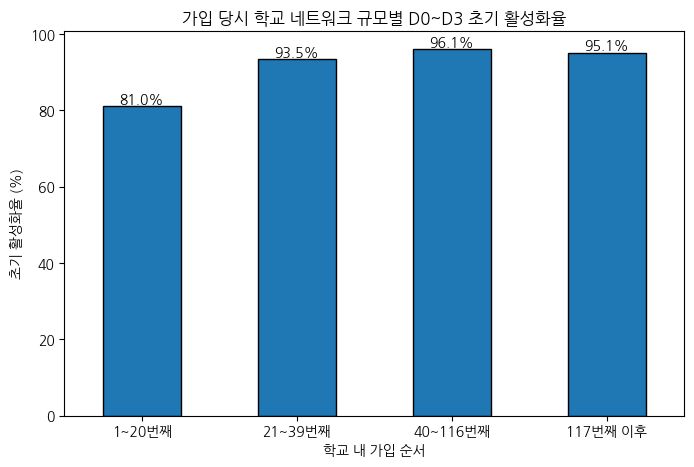

In [330]:
ax = early_result['early_active_rate'].plot(
    kind='bar', figsize=(8, 5), edgecolor='black'
)

for i, v in enumerate(early_result['early_active_rate']):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.title('가입 당시 학교 네트워크 규모별 D0~D3 초기 활성화율')
plt.xlabel('학교 내 가입 순서')
plt.ylabel('초기 활성화율 (%)')
plt.xticks(rotation=0)
plt.show()

초기 활성화율 정의 : 2023-04-29 이후 가입자 중, 가입일(D0)부터 D3까지 아래 3가지 능동 행동 중 하나라도 한 유저의 비율

친구요청, 투표, 질문세트
- 친구요청 O / 투표 X / 질문세트 X → 활성화
- 친구요청 X / 투표 O / 질문세트 X → 활성화
- 친구요청 X / 투표 X / 질문세트 O → 활성화

학교 내 초기 가입자 집단보다 기존 유저가 어느 정도 형성된 시점에 가입한 유저의 초기 활성화율이 높았으며, 40번째 이후부터는 약 95% 수준에서 포화되는 양상이 나타났다.

In [331]:
# D4~D7에 핵심 행동이 하나라도 있으면 후속 활동 유지
analysis_base['followup_active_4_7d'] = (
    analysis_base['user_id'].isin(sent_4_7) |
    analysis_base['user_id'].isin(vote_4_7) |
    analysis_base['user_id'].isin(qset_4_7)
)

# D4~D30에 핵심 행동이 하나라도 있으면 후속 활동 유지
analysis_base['followup_active_4_30d'] = (
    analysis_base['user_id'].isin(sent_4_30) |
    analysis_base['user_id'].isin(vote_4_30) |
    analysis_base['user_id'].isin(qset_4_30)
)

In [332]:
# 세 행동 로그 중 가장 먼저 끝나는 날짜 기준
activity_end = min(
    friend_end,
    uqr['created_at'].max(),
    qset['created_at'].max()
)

# 각 기간을 끝까지 관측할 수 있는 유저만 사용
base_7 = analysis_base[
    analysis_base['created_at'] <= activity_end - pd.Timedelta(days=7)
].copy()

base_30 = analysis_base[
    analysis_base['created_at'] <= activity_end - pd.Timedelta(days=30)
].copy()

In [333]:
# 네트워크 규모별 D4~D7 후속 활동 유지율
followup_7 = (
    base_7[base_7['early_active_3d']]
    .groupby('join_order_group', observed=True)
    ['followup_active_4_7d']
    .mean() * 100
)

# 네트워크 규모별 D4~D30 후속 활동 유지율
followup_30 = (
    base_30[base_30['early_active_3d']]
    .groupby('join_order_group', observed=True)
    ['followup_active_4_30d']
    .mean() * 100
)

# 한 표로 결합
followup_result = pd.concat(
    [followup_7.rename('D4~D7'), followup_30.rename('D4~D30')],
    axis=1
)

followup_result.round(2)

,D4~D7,D4~D30
join_order_group,,
1~20번째,45.02,62.39
21~39번째,42.85,55.99
40~116번째,31.81,43.96
117번째 이후,25.55,36.78


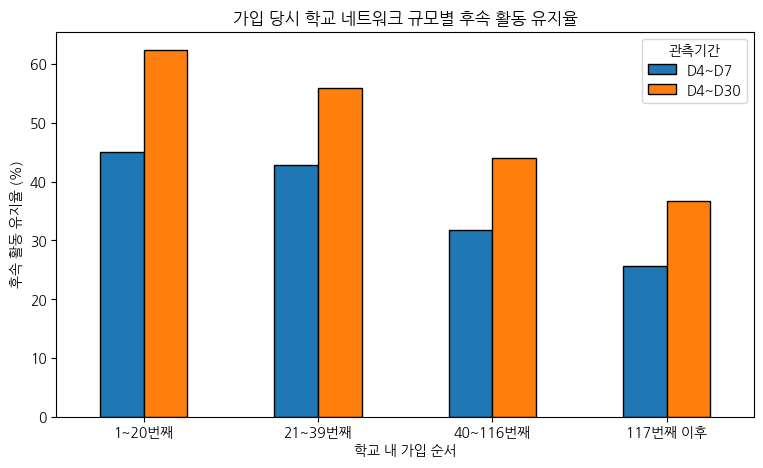

In [334]:
# 네트워크 규모별 후속 활동 유지율 시각화
ax = followup_result.plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('가입 당시 학교 네트워크 규모별 후속 활동 유지율')
plt.xlabel('학교 내 가입 순서')
plt.ylabel('후속 활동 유지율 (%)')
plt.xticks(rotation=0)
plt.legend(title='관측기간')
plt.show()

학교 네트워크 규모가 클수록 신규 유저의 D0~D3 초기 활성화율은 높아졌으나, 초기 활성화 이후의 후속 활동 유지율은 반대로 감소하는 경향이 나타났다.

이는 규모가 큰 네트워크가 신규 유저의 초기 행동 진입에는 유리하지만, 이후 지속적인 활동까지 보장하지는 않음을 시사한다.

초기 진입 효과 와 지속 효과가 다르게 나타난다.

#### 초기 친구 연결 → 후속 활동 유지

초기 친구 연결 = D0~D3에 친구요청을 한 번이라도 보내거나 받은 유저

가입 후 D0-D3 내 친구요청을 보내거나 받은 신규 유저는 그렇지 않은 유저보다 이후 D4-D7 및 D4-D30 후속 활동 유지율이 높을 것이다

In [335]:
# D0~D3 친구요청 송신/수신 여부
analysis_base['sent_friend_3d'] = analysis_base['user_id'].isin(sent_early)
analysis_base['received_friend_3d'] = analysis_base['user_id'].isin(received_early)

# 보내거나 받은 경험이 하나라도 있으면 초기 친구 연결 경험
analysis_base['friend_interaction_3d'] = (
    analysis_base['sent_friend_3d'] |
    analysis_base['received_friend_3d']
)

# 초기 친구 연결 경험 유저 수 확인
analysis_base['friend_interaction_3d'].value_counts()

,count
friend_interaction_3d,
True,655757
False,11525


In [336]:
# D4~D7 관측 가능한 유저
friend_base_7 = analysis_base[
    analysis_base['created_at'] <= activity_end - pd.Timedelta(days=7)
].copy()

# 초기 친구 연결 여부별 D4~D7 후속 활동률
friend_7 = (
    friend_base_7.groupby('friend_interaction_3d')
    .agg(
        users=('user_id', 'nunique'),
        followup_rate=('followup_active_4_7d', 'mean')
    )
)

friend_7['followup_rate'] *= 100
friend_7.round(2)

,users,followup_rate
friend_interaction_3d,,
False,11512,10.35
True,655718,31.89


In [337]:
# D4~D30 관측 가능한 유저
friend_base_30 = analysis_base[
    analysis_base['created_at'] <= activity_end - pd.Timedelta(days=30)
].copy()

# 초기 친구 연결 여부별 D4~D30 후속 활동률
friend_30 = (
    friend_base_30.groupby('friend_interaction_3d')
    .agg(
        users=('user_id', 'nunique'),
        followup_rate=('followup_active_4_30d', 'mean')
    )
)

friend_30['followup_rate'] *= 100
friend_30.round(2)

,users,followup_rate
friend_interaction_3d,,
False,11452,29.21
True,655632,44.59


In [338]:
# D4~D7 / D4~D30 결과 결합
friend_followup = pd.concat(
    [
        friend_7['followup_rate'].rename('D4~D7'),
        friend_30['followup_rate'].rename('D4~D30')
    ],
    axis=1
)

friend_followup.index = ['초기 친구 연결 없음', '초기 친구 연결 있음']

friend_followup.round(2)

,D4~D7,D4~D30
초기 친구 연결 없음,10.35,29.21
초기 친구 연결 있음,31.89,44.59


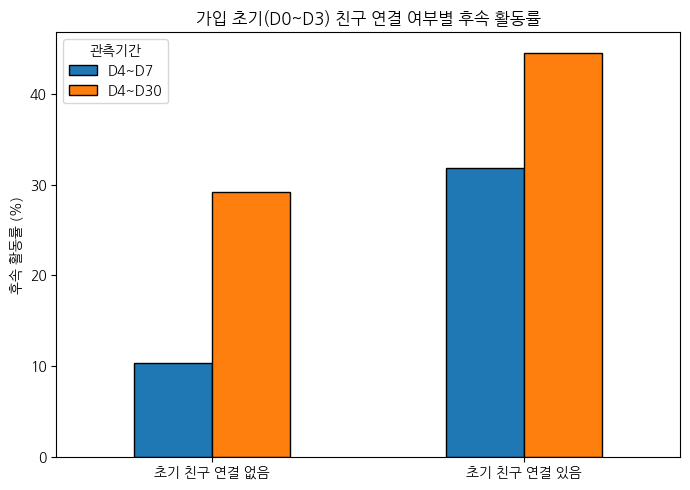

In [339]:
# 초기 친구 연결 여부별 후속 활동 유지율 시각화
ax = friend_followup.plot(kind='bar', figsize=(7, 5), edgecolor='black')

plt.title('가입 초기(D0~D3) 친구 연결 여부별 후속 활동률')
plt.xlabel('')
plt.ylabel('후속 활동률 (%)')
plt.xticks(rotation=0)
plt.legend(title='관측기간')
plt.tight_layout()
plt.show()

초기 친구 연결이 있는 유저는 없는 유저보다 D4-D7, D4-D30 모두에서 후속 활동 유지율이 크게 높게 나타났다.

특히 단기뿐 아니라 30일까지 차이가 유지되어, 초기 친구 연결 경험이 이후 활동 지속성과 연관된 패턴이 확인됐다

가설 지지

#### 친구요청 유형 → 후속 활동 유지율

In [340]:
# D0~D3 친구요청 송신/수신 여부
analysis_base['sent_friend_3d'] = analysis_base['user_id'].isin(sent_early)
analysis_base['received_friend_3d'] = analysis_base['user_id'].isin(received_early)

# 친구요청 유형 생성
analysis_base['friend_3d_type'] = '없음'

analysis_base.loc[
    analysis_base['sent_friend_3d'] & ~analysis_base['received_friend_3d'],
    'friend_3d_type'
] = '보내기만'

analysis_base.loc[
    ~analysis_base['sent_friend_3d'] & analysis_base['received_friend_3d'],
    'friend_3d_type'
] = '받기만'

analysis_base.loc[
    analysis_base['sent_friend_3d'] & analysis_base['received_friend_3d'],
    'friend_3d_type'
] = '송수신 모두'

# 유형별 유저 수 확인
analysis_base['friend_3d_type'].value_counts()

,count
friend_3d_type,
송수신 모두,591519
받기만,32812
보내기만,31426
없음,11525


In [341]:
# D7까지 온전히 관측 가능한 유저
type_base_7 = analysis_base[
    analysis_base['created_at'] <= activity_end - pd.Timedelta(days=7)
].copy()

# 친구요청 유형별 D4~D7 후속 활동률
type_7 = (
    type_base_7.groupby('friend_3d_type')
    .agg(
        users=('user_id', 'nunique'),
        followup_rate=('followup_active_4_7d', 'mean')
    )
)

type_7['followup_rate'] *= 100

In [342]:
# D30까지 온전히 관측 가능한 유저
type_base_30 = analysis_base[
    analysis_base['created_at'] <= activity_end - pd.Timedelta(days=30)
].copy()

# 친구요청 유형별 D4~D30 후속 활동률
type_30 = (
    type_base_30.groupby('friend_3d_type')
    .agg(
        users=('user_id', 'nunique'),
        followup_rate=('followup_active_4_30d', 'mean')
    )
)

type_30['followup_rate'] *= 100

In [343]:
# 두 기간 결과 결합
friend_type_followup = pd.concat(
    [
        type_7['followup_rate'].rename('D4~D7'),
        type_30['followup_rate'].rename('D4~D30')
    ],
    axis=1
)

# 보기 좋은 순서로 정렬
order = ['없음', '받기만', '보내기만', '송수신 모두']
friend_type_followup = friend_type_followup.reindex(order)

friend_type_followup.round(2)

,D4~D7,D4~D30
friend_3d_type,,
없음,10.35,29.21
받기만,24.31,39.97
보내기만,11.62,23.46
송수신 모두,33.39,45.96


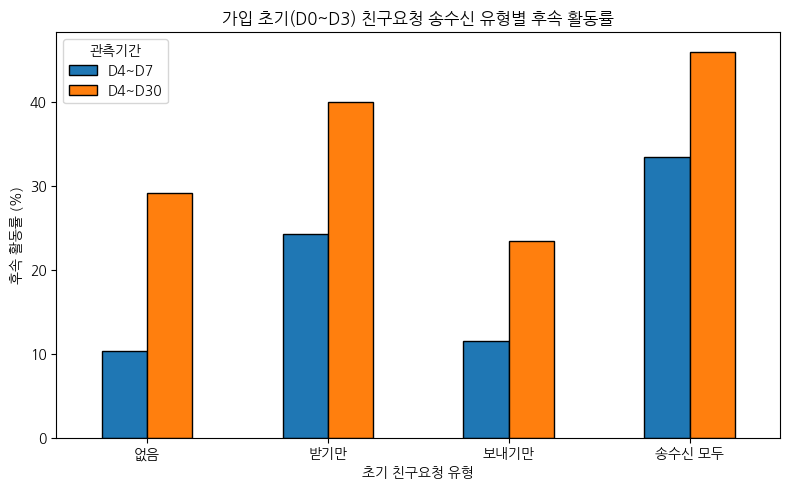

In [344]:
# 친구요청 유형별 후속 활동 유지율 시각화
ax = friend_type_followup.plot(kind='bar', figsize=(8, 5), edgecolor='black')

plt.title('가입 초기(D0~D3) 친구요청 송수신 유형별 후속 활동률')
plt.xlabel('초기 친구요청 유형')
plt.ylabel('후속 활동률 (%)')
plt.xticks(rotation=0)
plt.legend(title='관측기간')
plt.tight_layout()
plt.show()

가설 : 가입 초기 3일 동안 친구요청을 송수신 모두 경험한 유저가 단방향 요청이나 친구요청이 없는 유저보다 이후 후속 활동 유지율이 높을 것이다.

가설 : 초기 네트워크 형성기에 친구요청을 송수신 모두 경험한 유저가 단방향 요청이나 친구요청이 없는 유저보다 이후 후속 활동 유지율이 높을 것이다.

- - -
초기 네트워크 형성기인 가입 초기 3일 동안 친구요청을 송수신 모두 경험한 유저가 단방향 요청이나 친구요청이 없었던 유저보다 이후 후속 활동 유지율이 가장 높게 나타났다.

이는 단순히 친구요청을 보내거나 받는 것보다 초기에 상호적인 관계 형성이 이루어진 경험이 이후 활동 지속과 더 강하게 연관되어 있음을 보여준다.

가설 지지

#### 가입 → 첫 핵심 행동까지 걸린 시간 → 재방문

첫 친구수락 / 첫 투표 / 첫 질문세트 완료 중 가장 먼저 발생한 시점을 첫 핵심행동으로 묶어서 한번에 확인

In [345]:
# 첫 친구수락 시점 계산

# 친구요청 파일 컬럼 확인
friend_path = path / 'accounts_friendrequest_cleaned.csv'
friend_cols = pd.read_csv(friend_path, nrows=0).columns

# 수락 시점은 updated_at이 있으면 updated_at 사용
friend_time_col = 'updated_at' if 'updated_at' in friend_cols else 'created_at'

first_friend_parts = []

for chunk in pd.read_csv(
    friend_path,
    usecols=['send_user_id', 'receive_user_id', 'status', friend_time_col],
    chunksize=1_000_000
):
    # 수락된 친구요청만 사용
    accepted = chunk[chunk['status'] == 'A'].copy()
    accepted[friend_time_col] = pd.to_datetime(accepted[friend_time_col])

    # 요청자와 수신자 모두 친구관계가 형성된 것으로 처리
    send = accepted[['send_user_id', friend_time_col]].rename(
        columns={'send_user_id': 'user_id', friend_time_col: 'first_friend_at'}
    )

    receive = accepted[['receive_user_id', friend_time_col]].rename(
        columns={'receive_user_id': 'user_id', friend_time_col: 'first_friend_at'}
    )

    # chunk 내부에서 유저별 최초 수락시점만 저장
    part = (
        pd.concat([send, receive])
        .groupby('user_id')['first_friend_at']
        .min()
    )

    first_friend_parts.append(part)

# 전체 chunk를 합쳐 최종 최초 친구수락 시점 계산
first_friend = (
    pd.concat(first_friend_parts)
    .groupby(level=0)
    .min()
)

In [346]:
# 첫 투표 / 첫 질문세트 완료

# 첫 투표 시점
first_vote = (
    uqr.groupby('user_id')['created_at']
    .min()
)

# 첫 질문세트 완료 시점
first_qset = (
    qset[qset['status'] == 'F']
    .groupby('user_id')['created_at']
    .min()
)

In [347]:
# 세 행동 중 가장 빠른 행동 = 첫 핵심행동

# 각 유저의 첫 행동시간 연결
analysis_base['first_friend_at'] = analysis_base['user_id'].map(first_friend)
analysis_base['first_vote_at'] = analysis_base['user_id'].map(first_vote)
analysis_base['first_qset_at'] = analysis_base['user_id'].map(first_qset)

# 세 행동 중 가장 먼저 발생한 시점
analysis_base['first_core_at'] = (
    analysis_base[
        ['first_friend_at', 'first_vote_at', 'first_qset_at']
    ].min(axis=1)
)

# 가입 → 첫 핵심행동까지 걸린 시간
analysis_base['first_core_hours'] = (
    analysis_base['first_core_at'] - analysis_base['signup_at']
).dt.total_seconds() / 3600

# 가입 이전 기록은 제외
analysis_base.loc[
    analysis_base['first_core_hours'] < 0,
    'first_core_hours'
] = np.nan

In [348]:
# 첫 핵심행동 도달 속도 구간
# 가입 후 72시간 안에 핵심행동에 도달한 유저끼리 속도를 비교
# 첫 핵심행동 도달 속도 구간
analysis_base['first_core_speed'] = pd.cut(
    analysis_base['first_core_hours'],
    bins=[-0.01, 1, 6, 24, 72],
    labels=['1시간 이내', '1~6시간', '6~24시간', '1~3일']
)

# 구간별 유저 수 확인
analysis_base['first_core_speed'].value_counts(sort=False)


,count
first_core_speed,
1시간 이내,455853
1~6시간,73204
6~24시간,50528
1~3일,30931


In [349]:
# first_core_speed 생성 이후 다시 관측 가능 코호트 생성
base_7 = analysis_base[
    analysis_base['created_at'] <= activity_end - pd.Timedelta(days=7)
].copy()

base_30 = analysis_base[
    analysis_base['created_at'] <= activity_end - pd.Timedelta(days=30)
].copy()

In [350]:
# 가입 후 3일 내 첫 핵심행동에 도달한 유저만 사용
core_speed_dist = (
    analysis_base['first_core_speed']
    .value_counts(sort=False)
    .to_frame('users')
)

# 전체 도달 유저 중 비율 계산
core_speed_dist['ratio'] = (
    core_speed_dist['users']
    / core_speed_dist['users'].sum()
    * 100
)

core_speed_dist.round(2)

,users,ratio
first_core_speed,,
1시간 이내,455853,74.67
1~6시간,73204,11.99
6~24시간,50528,8.28
1~3일,30931,5.07


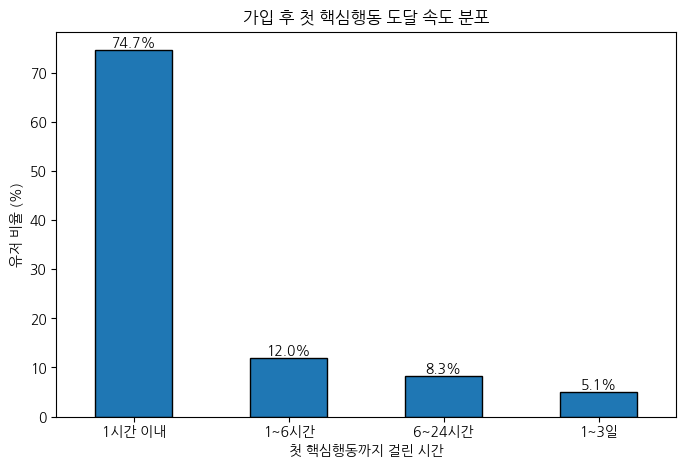

In [351]:
# 첫 핵심행동 도달 속도 분포 시각화
ax = core_speed_dist['ratio'].plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

# 막대 위 비율 표시
for i, v in enumerate(core_speed_dist['ratio']):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.title('가입 후 첫 핵심행동 도달 속도 분포')
plt.xlabel('첫 핵심행동까지 걸린 시간')
plt.ylabel('유저 비율 (%)')
plt.xticks(rotation=0)
plt.show()

In [352]:
# 도달 속도별 후속 활동 유지율

# D4~D7까지 관측 가능한 유저 중
# 가입 후 3일 내 첫 핵심행동에 도달한 유저만 사용
speed_7 = (
    base_7[base_7['first_core_speed'].notna()]
    .groupby('first_core_speed', observed=True)
    ['followup_active_4_7d']
    .mean() * 100
)

# D4~D30도 동일하게 계산
speed_30 = (
    base_30[base_30['first_core_speed'].notna()]
    .groupby('first_core_speed', observed=True)
    ['followup_active_4_30d']
    .mean() * 100
)

# 한 표로 결합
core_speed_result = pd.concat(
    [
        speed_7.rename('D4~D7'),
        speed_30.rename('D4~D30')
    ],
    axis=1
)

core_speed_result.round(2)

,D4~D7,D4~D30
first_core_speed,,
1시간 이내,30.60,42.66
1~6시간,33.14,46.59
6~24시간,39.04,52.57
1~3일,48.27,61.25


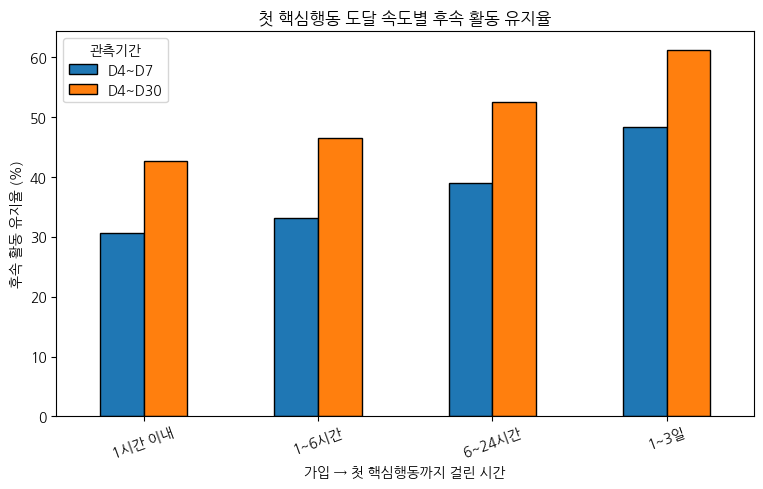

In [353]:
# 첫 핵심행동 도달 속도별 후속 활동 유지율
ax = core_speed_result.plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('첫 핵심행동 도달 속도별 후속 활동 유지율')
plt.xlabel('가입 → 첫 핵심행동까지 걸린 시간')
plt.ylabel('후속 활동 유지율 (%)')
plt.xticks(rotation=20)
plt.legend(title='관측기간')
plt.show()
# D4 ~ D7 가입 후 4일 ~ 7일 사이에 다시 핵심 행동을 했냐를 확인하는 그래프

얼마나 빨리 첫 핵심행동에 도달하는가?

↓

가입 후 빠른 도달이 이후 활동 유지와 연결되는가?

첫 핵심행동은 가입 후 1시간 이내에 도달한 유저가 74.7%로 대부분을 차지해 초기 행동 전환이 매우 빠르게 발생했다.

반면 후속 활동 유지율은 도달이 늦은 집단일수록 오히려 높아, ‘빠른 첫 행동이 이후 활동 유지로 이어질 것’이라는 가설은 지지되지 않았다.

- 왜 이렇게 나왔을까?

1시간 이내 유저는 첫 행동 이후 D4까지 최대 3일 이상 공백이 있지만,

1-3일 유저는 첫 행동 직후 바로 D4-D7 구간이 시작됨.

그래서 늦게 첫 행동한 집단이 후속 활동 구간과 시간적으로 더 가까워 유지율이 높게 잡힐 수 있음

-> 시간 구간이 공평하지가 않은 듯하다

In [354]:
# 첫 핵심행동 이후 1~7일 친구요청 송신 확인

# 유저별 첫 핵심행동 시점 매핑
first_core_map = analysis_base.set_index('user_id')['first_core_at']

friend_followup_parts = []

# 대용량 친구요청은 chunk로 처리
for chunk in pd.read_csv(
    friend_path,
    usecols=['send_user_id', 'created_at'],
    chunksize=1_000_000
):
    chunk['created_at'] = pd.to_datetime(chunk['created_at'])

    # 해당 유저의 첫 핵심행동 시점 연결
    chunk['first_core_at'] = chunk['send_user_id'].map(first_core_map)
    chunk = chunk.dropna(subset=['first_core_at'])

    # 첫 핵심행동 이후 며칠 뒤 행동인지 계산
    days_after_core = (
        chunk['created_at'].dt.normalize()
        - chunk['first_core_at'].dt.normalize()
    ).dt.days

    # 첫 핵심행동 이후 1~7일 내 다시 친구요청을 보낸 유저
    ids = chunk.loc[
        days_after_core.between(1, 7),
        'send_user_id'
    ].unique()

    friend_followup_parts.append(ids)

# 전체 chunk 결과 통합
friend_followup_ids = np.unique(
    np.concatenate(friend_followup_parts)
)

In [355]:
# 첫 핵심행동 이후 1~7일 내 투표
vote_followup = uqr[['user_id', 'created_at']].copy()
vote_followup['first_core_at'] = vote_followup['user_id'].map(first_core_map)
vote_followup = vote_followup.dropna(subset=['first_core_at'])

vote_after_core = (
    vote_followup['created_at'].dt.normalize()
    - vote_followup['first_core_at'].dt.normalize()
).dt.days

vote_followup_ids = vote_followup.loc[
    vote_after_core.between(1, 7),
    'user_id'
].unique()

In [356]:
# 첫 핵심행동 이후 1~7일 내 질문세트 완료
qset_followup = qset.loc[
    qset['status'] == 'F',
    ['user_id', 'created_at']
].copy()

qset_followup['first_core_at'] = qset_followup['user_id'].map(first_core_map)
qset_followup = qset_followup.dropna(subset=['first_core_at'])

qset_after_core = (
    qset_followup['created_at'].dt.normalize()
    - qset_followup['first_core_at'].dt.normalize()
).dt.days

qset_followup_ids = qset_followup.loc[
    qset_after_core.between(1, 7),
    'user_id'
].unique()

In [357]:
# 세 행동 중 하나라도 다시 수행하면 후속 활동 유지
analysis_base['active_after_core_7d'] = (
    analysis_base['user_id'].isin(friend_followup_ids) |
    analysis_base['user_id'].isin(vote_followup_ids) |
    analysis_base['user_id'].isin(qset_followup_ids)
)

In [358]:
# 첫 핵심행동 이후 7일을 온전히 관측할 수 있는 유저만 사용
core_base_7 = analysis_base[
    analysis_base['first_core_at'].notna() &
    (analysis_base['first_core_at'] <= activity_end - pd.Timedelta(days=7)) &
    analysis_base['first_core_speed'].notna()
].copy()

In [359]:
# 도달 속도별 첫 핵심행동 이후 1~7일 재활동률
core_followup_result = (
    core_base_7
    .groupby('first_core_speed', observed=True)
    .agg(
        users=('user_id', 'nunique'),
        followup_rate=('active_after_core_7d', 'mean')
    )
)

core_followup_result['followup_rate'] *= 100
core_followup_result.round(2)

,users,followup_rate
first_core_speed,,
1시간 이내,455841,63.48
1~6시간,73203,61.20
6~24시간,50528,62.98
1~3일,30931,64.13


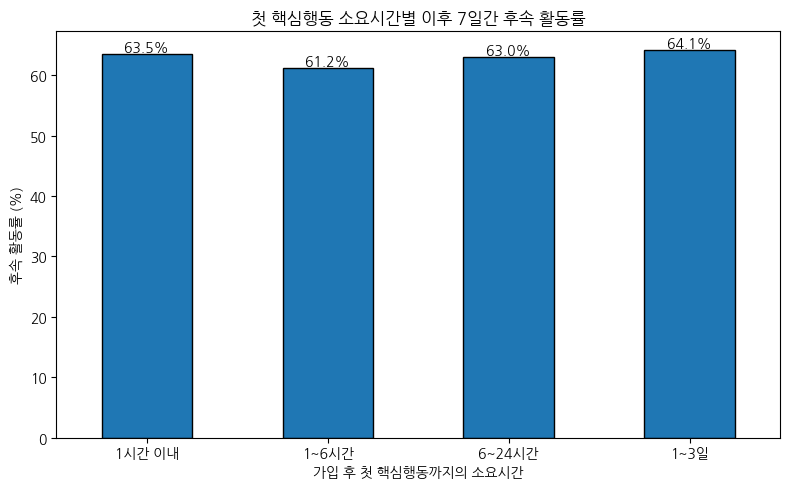

In [360]:
# 시각화
ax = core_followup_result['followup_rate'].plot(kind='bar', figsize=(8, 5), edgecolor='black')

for i, v in enumerate(core_followup_result['followup_rate']):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.title('첫 핵심행동 소요시간별 이후 7일간 후속 활동률')
plt.xlabel('가입 후 첫 핵심행동까지의 소요시간')
plt.ylabel('후속 활동률 (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 주제별 재방문 확인

출석 기록 재방문

In [361]:
# attendance 날짜형 변환
attendance['attendance_date'] = pd.to_datetime(attendance['attendance_date'])

# 유저별 가입일 매핑
signup_map_all = network_base.set_index('user_id')['signup_date']

# 출석 기록에 가입일 연결
att = attendance[['user_id', 'attendance_date']].copy()
att['signup_date'] = att['user_id'].map(signup_map_all)

# 가입 후 며칠째 출석인지 계산
att['days_after_signup'] = (
    att['attendance_date'].dt.normalize()
    - att['signup_date']
).dt.days

# 가입 당일은 제외하고 이후 재출석만 확인
revisit_7_ids = att.loc[
    att['days_after_signup'].between(1, 7),
    'user_id'
].unique()

revisit_30_ids = att.loc[
    att['days_after_signup'].between(1, 30),
    'user_id'
].unique()

In [362]:
# attendance 관측 시작/종료일
attendance_start = attendance['attendance_date'].min().normalize()
attendance_end = attendance['attendance_date'].max().normalize()

# 7일을 온전히 관측할 수 있는 가입자
revisit_base_7 = network_base[
    (network_base['signup_date'] >= attendance_start) &
    (network_base['signup_date'] <= attendance_end - pd.Timedelta(days=7))
].copy()

# 30일을 온전히 관측할 수 있는 가입자
revisit_base_30 = network_base[
    (network_base['signup_date'] >= attendance_start) &
    (network_base['signup_date'] <= attendance_end - pd.Timedelta(days=30))
].copy()

# 재방문 여부
revisit_base_7['revisit_7d_att'] = (
    revisit_base_7['user_id'].isin(revisit_7_ids)
)

revisit_base_30['revisit_30d_att'] = (
    revisit_base_30['user_id'].isin(revisit_30_ids)
)

학교 네트워크 규모별

In [363]:
# 가입순서 그룹별 7일 재방문율
network_revisit_7 = (
    revisit_base_7
    .groupby('join_order_group', observed=True)
    ['revisit_7d_att']
    .mean() * 100
)

# 가입순서 그룹별 30일 재방문율
network_revisit_30 = (
    revisit_base_30
    .groupby('join_order_group', observed=True)
    ['revisit_30d_att']
    .mean() * 100
)

# 한 표로 결합
network_revisit = pd.concat(
    [
        network_revisit_7.rename('7일'),
        network_revisit_30.rename('30일')
    ],
    axis=1
)

network_revisit.round(2)

,7일,30일
join_order_group,,
1~20번째,15.64,20.33
21~39번째,51.36,55.81
40~116번째,57.54,60.22
117번째 이후,46.55,49.43


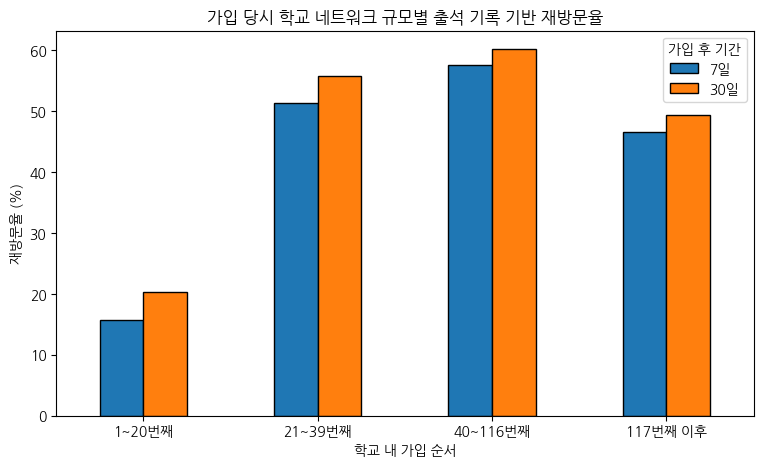

In [364]:
# 학교 네트워크 규모별 attendance 기반 재방문율
ax = network_revisit.plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('가입 당시 학교 네트워크 규모별 출석 기록 기반 재방문율')
plt.xlabel('학교 내 가입 순서')
plt.ylabel('재방문율 (%)')
plt.xticks(rotation=0)
plt.legend(title='가입 후 기간')
plt.show()

출석 기록 기반 재방문율은 1-20번째 가입자에서 가장 낮고, 40-116번째에서 가장 높아 네트워크가 일정 규모 형성된 이후 재방문이 크게 높아지는 패턴이 나타났다.

#### 초기 친구 연결 여부 → 실제 재방문 보조 검증

In [365]:
# 7일을 온전히 관측할 수 있는 유저
friend_revisit_7 = analysis_base[
    (analysis_base['signup_date'] >= attendance_start) &
    (analysis_base['signup_date'] <= attendance_end - pd.Timedelta(days=7))
].copy()

# 30일을 온전히 관측할 수 있는 유저
friend_revisit_30 = analysis_base[
    (analysis_base['signup_date'] >= attendance_start) &
    (analysis_base['signup_date'] <= attendance_end - pd.Timedelta(days=30))
].copy()

# attendance 기준 재방문 여부 추가
friend_revisit_7['revisit_7d_att'] = (
    friend_revisit_7['user_id'].isin(revisit_7_ids)
)

friend_revisit_30['revisit_30d_att'] = (
    friend_revisit_30['user_id'].isin(revisit_30_ids)
)

In [366]:
# 초기 친구 연결 여부별 7일 재방문율
friend_att_7 = (
    friend_revisit_7
    .groupby('friend_interaction_3d')
    ['revisit_7d_att']
    .mean() * 100
)

# 초기 친구 연결 여부별 30일 재방문율
friend_att_30 = (
    friend_revisit_30
    .groupby('friend_interaction_3d')
    ['revisit_30d_att']
    .mean() * 100
)

# 한 표로 결합
friend_att_result = pd.concat(
    [
        friend_att_7.rename('7일'),
        friend_att_30.rename('30일')
    ],
    axis=1
)

friend_att_result.index = ['초기 친구 연결 없음', '초기 친구 연결 있음']

friend_att_result.round(2)

,7일,30일
초기 친구 연결 없음,2.06,2.89
초기 친구 연결 있음,50.35,53.51


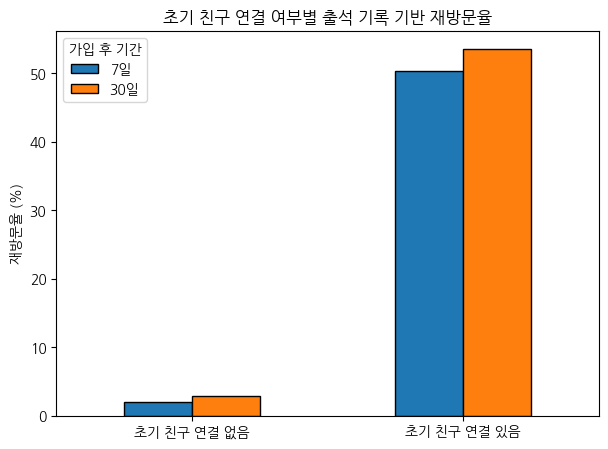

In [367]:
# 초기 친구 연결 여부별 출석 기록 기반 재방문율 시각화
ax = friend_att_result.plot(
    kind='bar',
    figsize=(7, 5),
    edgecolor='black'
)

plt.title('초기 친구 연결 여부별 출석 기록 기반 재방문율')
plt.xlabel('')
plt.ylabel('재방문율 (%)')
plt.xticks(rotation=0)
plt.legend(title='가입 후 기간')
plt.show()

초기 친구 연결 경험이 있는 유저는 없는 유저보다 7일·30일 출석 기록 기반 재방문율이 크게 높게 나타났다.

#### 친구요청 유형 → attendance 기반 실제 재방문 보조검증

In [368]:
# 7일 재방문을 온전히 관측할 수 있는 유저
type_revisit_7 = analysis_base[
    (analysis_base['signup_date'] >= attendance_start) &
    (analysis_base['signup_date'] <= attendance_end - pd.Timedelta(days=7))
].copy()

# 30일 재방문을 온전히 관측할 수 있는 유저
type_revisit_30 = analysis_base[
    (analysis_base['signup_date'] >= attendance_start) &
    (analysis_base['signup_date'] <= attendance_end - pd.Timedelta(days=30))
].copy()

# attendance 기반 재방문 여부 추가
type_revisit_7['revisit_7d_att'] = (
    type_revisit_7['user_id'].isin(revisit_7_ids)
)

type_revisit_30['revisit_30d_att'] = (
    type_revisit_30['user_id'].isin(revisit_30_ids)
)

In [369]:
# 친구요청 유형별 7일 재방문율
type_att_7 = (
    type_revisit_7
    .groupby('friend_3d_type')
    ['revisit_7d_att']
    .mean() * 100
)

# 친구요청 유형별 30일 재방문율
type_att_30 = (
    type_revisit_30
    .groupby('friend_3d_type')
    ['revisit_30d_att']
    .mean() * 100
)

# 두 기간 결과 결합
friend_type_revisit = pd.concat(
    [
        type_att_7.rename('7일'),
        type_att_30.rename('30일')
    ],
    axis=1
)

# 보기 좋은 순서로 정렬
order = ['없음', '받기만', '보내기만', '송수신 모두']
friend_type_revisit = friend_type_revisit.reindex(order)

friend_type_revisit.round(2)

,7일,30일
friend_3d_type,,
없음,2.06,2.89
받기만,9.42,12.22
보내기만,30.14,33.84
송수신 모두,58.75,61.72


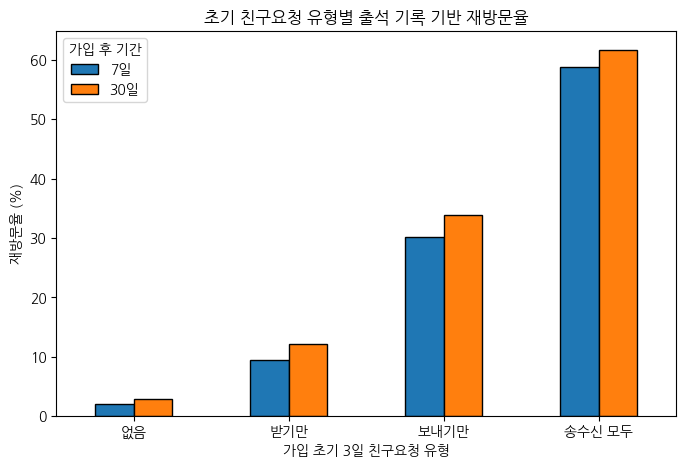

In [370]:
# 친구요청 유형별 출석 기록 기반 재방문율
ax = friend_type_revisit.plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('초기 친구요청 유형별 출석 기록 기반 재방문율')
plt.xlabel('가입 초기 3일 친구요청 유형')
plt.ylabel('재방문율 (%)')
plt.xticks(rotation=0)
plt.legend(title='가입 후 기간')
plt.show()

#### 첫 핵심행동 도달 속도 → 실제 재방문 보조검증

In [371]:
# 첫 핵심행동 시점 매핑
first_core_map = analysis_base.set_index('user_id')['first_core_at']

# attendance에 첫 핵심행동 시점 연결
core_att = attendance[['user_id', 'attendance_date']].copy()
core_att['attendance_date'] = pd.to_datetime(core_att['attendance_date'])
core_att['first_core_at'] = core_att['user_id'].map(first_core_map)

core_att = core_att.dropna(subset=['first_core_at'])

# 첫 핵심행동 이후 며칠 뒤 출석했는지 계산
core_att['days_after_core'] = (
    core_att['attendance_date'].dt.normalize()
    - core_att['first_core_at'].dt.normalize()
).dt.days

# 첫 핵심행동 이후 1~7일 / 1~30일 내 출석 유저
core_revisit_7_ids = core_att.loc[
    core_att['days_after_core'].between(1, 7),
    'user_id'
].unique()

core_revisit_30_ids = core_att.loc[
    core_att['days_after_core'].between(1, 30),
    'user_id'
].unique()

In [372]:
# attendance 관측 시작/종료일
attendance_start = attendance['attendance_date'].min().normalize()
attendance_end = attendance['attendance_date'].max().normalize()

# 첫 핵심행동 이후 7일을 온전히 관측할 수 있는 유저
core_revisit_base_7 = analysis_base[
    analysis_base['first_core_at'].notna() &
    analysis_base['first_core_speed'].notna() &
    (analysis_base['first_core_at'].dt.normalize() >= attendance_start) &
    (analysis_base['first_core_at'].dt.normalize() <= attendance_end - pd.Timedelta(days=7))
].copy()

# 첫 핵심행동 이후 30일을 온전히 관측할 수 있는 유저
core_revisit_base_30 = analysis_base[
    analysis_base['first_core_at'].notna() &
    analysis_base['first_core_speed'].notna() &
    (analysis_base['first_core_at'].dt.normalize() >= attendance_start) &
    (analysis_base['first_core_at'].dt.normalize() <= attendance_end - pd.Timedelta(days=30))
].copy()

# 출석 기록 기반 재방문 여부
core_revisit_base_7['revisit_after_core_7d'] = (
    core_revisit_base_7['user_id'].isin(core_revisit_7_ids)
)

core_revisit_base_30['revisit_after_core_30d'] = (
    core_revisit_base_30['user_id'].isin(core_revisit_30_ids)
)

In [373]:
# 첫 핵심행동 도달 속도별 7일 재방문율
core_att_7 = (
    core_revisit_base_7
    .groupby('first_core_speed', observed=True)
    ['revisit_after_core_7d']
    .mean() * 100
)

# 첫 핵심행동 도달 속도별 30일 재방문율
core_att_30 = (
    core_revisit_base_30
    .groupby('first_core_speed', observed=True)
    ['revisit_after_core_30d']
    .mean() * 100
)

# 결과 결합
core_revisit_result = pd.concat(
    [
        core_att_7.rename('7일'),
        core_att_30.rename('30일')
    ],
    axis=1
)

core_revisit_result.round(2)

,7일,30일
first_core_speed,,
1시간 이내,58.57,61.47
1~6시간,44.83,48.82
6~24시간,34.38,38.43
1~3일,30.16,33.41


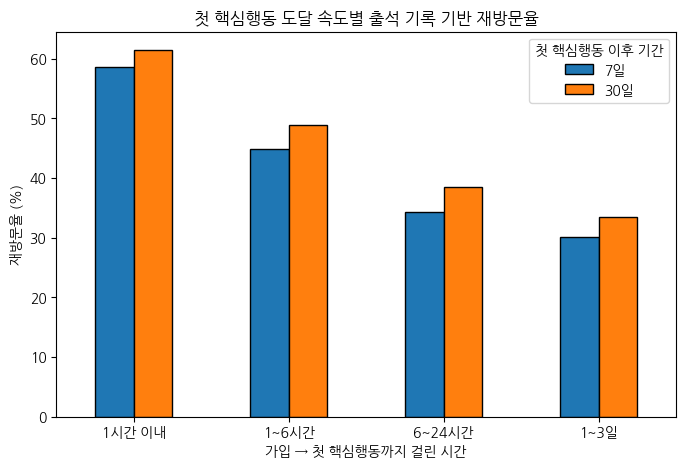

In [374]:
# 첫 핵심행동 도달 속도별 출석 기록 기반 재방문율
ax = core_revisit_result.plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('첫 핵심행동 도달 속도별 출석 기록 기반 재방문율')
plt.xlabel('가입 → 첫 핵심행동까지 걸린 시간')
plt.ylabel('재방문율 (%)')
plt.xticks(rotation=0)
plt.legend(title='첫 핵심행동 이후 기간')
plt.show()

### 투표 기록 확인

In [375]:
# 투표 기록 시간 변환
uqr['created_at'] = pd.to_datetime(uqr['created_at'])

# 월 단위 생성
uqr['month'] = uqr['created_at'].dt.to_period('M')

# 월별 투표 건수 / 투표 유저 수
monthly_vote = (
    uqr.groupby('month')
    .agg(
        vote_count=('id', 'count'),
        voter_count=('user_id', 'nunique')
    )
    .reset_index()
)

monthly_vote

,month,vote_count,voter_count
0,2023-04,29998,338
1,2023-05,1101849,4797
2,2023-06,71341,1872
3,2023-07,5396,389
4,2023-08,2050,170
5,2023-09,1665,178
6,2023-10,330,46
7,2023-11,253,22
8,2023-12,502,26
9,2024-01,236,19


In [376]:
# 일별 투표 건수 / 투표 유저 수
uqr['date'] = uqr['created_at'].dt.date

daily_vote = (
    uqr.groupby('date')
    .agg(
        vote_count=('id', 'count'),
        voter_count=('user_id', 'nunique')
    )
    .reset_index()
)

daily_vote.tail(20)

,date,vote_count,voter_count
253,2024-02-29,6,1
254,2024-03-03,6,3
255,2024-03-08,11,2
256,2024-03-09,25,3
257,2024-03-10,10,1
258,2024-03-17,9,1
259,2024-03-18,10,1
260,2024-03-19,2,1
261,2024-03-20,1,1
262,2024-03-30,6,1


In [377]:
# Hackle 데이터 기간의 실제 UQR 투표
uqr_hackle = uqr[
    uqr['created_at'].between('2023-07-18', '2023-08-10 23:59:59')
]

print(f"투표 건수: {len(uqr_hackle):,}")
print(f"투표 유저 수: {uqr_hackle['user_id'].nunique():,}")

uqr_hackle.groupby(uqr_hackle['created_at'].dt.date)['user_id'].nunique()

투표 건수: 2,816
투표 유저 수: 235


,user_id
created_at,
2023-07-18,18
2023-07-19,14
2023-07-20,26
2023-07-21,27
2023-07-22,14
2023-07-23,19
2023-07-24,9
2023-07-25,9
2023-07-26,12


In [378]:
# 날짜형 변환
uqr['created_at'] = pd.to_datetime(uqr['created_at'])
uqr['answer_updated_at'] = pd.to_datetime(uqr['answer_updated_at'])

# 실제 응답 완료(A)만 추출
uqr_a = uqr[uqr['answer_status'] == 'A'].copy()

# 가장 마지막 기록 10개 확인
uqr_a.sort_values('created_at', ascending=False)[
    ['id', 'user_id', 'answer_status', 'created_at', 'answer_updated_at']
].head(10)

,id,user_id,answer_status,created_at,answer_updated_at
1179003,150841825,887714,A,2023-06-07 17:42:25,2023-06-07 18:02:41
1178938,150825637,869580,A,2023-06-07 16:42:40,2023-06-07 17:40:52
1178931,150825226,877117,A,2023-06-07 16:41:50,2023-06-07 16:43:00
1178768,150785481,883374,A,2023-06-07 15:42:37,2023-06-07 15:43:09
1178765,150784898,883374,A,2023-06-07 15:41:57,2023-06-07 15:42:58
1178719,150779673,1021408,A,2023-06-07 15:36:29,2023-06-07 17:41:03
1178629,150748096,1566708,A,2023-06-07 15:09:44,2023-06-07 15:11:24
1178575,150735711,971740,A,2023-06-07 15:00:51,2023-06-07 15:01:50
1178571,150735325,1548231,A,2023-06-07 15:00:35,2023-06-07 15:03:03
1178484,150707957,1481093,A,2023-06-07 14:40:59,2023-06-07 14:41:38


In [379]:
pd.Series({
    'UQR 전체 마지막 created_at': uqr['created_at'].max(),
    'A 마지막 created_at': uqr_a['created_at'].max(),
    'A 마지막 answer_updated_at': uqr_a['answer_updated_at'].max(),
    'A 투표 기록 수': len(uqr_a),
    'A 고유 투표자 수': uqr_a['user_id'].nunique()
})

,0
UQR 전체 마지막 created_at,2024-05-08 01:36:18
A 마지막 created_at,2023-06-07 17:42:25
A 마지막 answer_updated_at,2023-06-07 18:02:41
A 투표 기록 수,111761
A 고유 투표자 수,4388


In [380]:
# answer_status별 마지막 기록 날짜
uqr.groupby('answer_status').agg(
    record_count=('id', 'count'),
    user_count=('user_id', 'nunique'),
    first_date=('created_at', 'min'),
    last_date=('created_at', 'max')
).sort_values('last_date')

,record_count,user_count,first_date,last_date
answer_status,,,,
P,7865,2291,2023-04-28 13:14:34,2023-06-07 13:47:44
A,111761,4388,2023-04-29 15:20:38,2023-06-07 17:42:25
N,1094300,4844,2023-04-28 12:27:49,2024-05-08 01:36:18


In [381]:
uqr['month'] = uqr['created_at'].dt.to_period('M')

monthly_check = (
    uqr.groupby('month')
    .agg(
        all_records=('id', 'count'),
        all_users=('user_id', 'nunique'),
        vote_records=('answer_status', lambda x: (x == 'A').sum()),
        vote_users=('user_id', lambda x: x[uqr.loc[x.index, 'answer_status'].eq('A')].nunique())
    )
    .reset_index()
)

monthly_check

,month,all_records,all_users,vote_records,vote_users
0,2023-04,29998,338,81,37
1,2023-05,1101849,4797,108127,4358
2,2023-06,71341,1872,3553,803
3,2023-07,5396,389,0,0
4,2023-08,2050,170,0,0
5,2023-09,1665,178,0,0
6,2023-10,330,46,0,0
7,2023-11,253,22,0,0
8,2023-12,502,26,0,0
9,2024-01,236,19,0,0


In [382]:
# 질문 조각 테이블 불러오기
qp = pd.read_csv(path / 'polls_questionpiece_cleaned.csv')

# 필요한 컬럼 확인
qp[['id', 'is_voted', 'is_skipped', 'created_at']].head()

,id,is_voted,is_skipped,created_at
0,998458,1,0,2023-04-28 12:27:22
1,998459,1,0,2023-04-28 12:27:22
2,998460,1,0,2023-04-28 12:27:22
3,998461,1,0,2023-04-28 12:27:22
4,998462,1,0,2023-04-28 12:27:22


In [384]:
# 친구요청 테이블 불러오기
fr = pd.read_csv(path / 'accounts_friendrequest_cleaned.csv')

# 송신/수신 고유 유저 비교
senders = set(fr['send_user_id'].dropna().unique())
receivers = set(fr['receive_user_id'].dropna().unique())

pd.Series({
    '송신 고유 유저': len(senders),
    '수신 고유 유저': len(receivers),
    '송신+수신 둘 다': len(senders & receivers),
    '받기만 한 유저': len(receivers - senders),
    '보내기만 한 유저': len(senders - receivers)
})

,0
송신 고유 유저,649072
수신 고유 유저,660841
송신+수신 둘 다,636208
받기만 한 유저,24633
보내기만 한 유저,12864


In [385]:
# 각 단계 고유 유저
signup = set(users['id'].unique())
send = set(fr['send_user_id'].dropna().unique())
qset_user = set(qset['user_id'].dropna().unique())
vote_user = set(uqr['user_id'].dropna().unique())

# 앞 단계를 실제로 거친 사람만 남김
s1 = signup
s2 = s1 & send
s3 = s2 & qset_user
s4 = s3 & vote_user

funnel = pd.DataFrame({
    '단계': ['가입', '친구요청 송신', '질문세트 기록', '투표(선택) 기록'],
    '인원': [len(s1), len(s2), len(s3), len(s4)]
})

funnel['가입 대비(%)'] = (funnel['인원'] / len(s1) * 100).round(2)
funnel['직전 단계 대비(%)'] = (
    funnel['인원'] / funnel['인원'].shift(1) * 100
).round(2)

funnel

,단계,인원,가입 대비(%),직전 단계 대비(%)
0,가입,677077,100.00,NaN
1,친구요청 송신,649067,95.86,95.86
2,질문세트 기록,4914,0.73,0.76
3,투표(선택) 기록,4798,0.71,97.64


## 투표 유저 vs 비투표 유저 비교

### 학교별 투표 유저 존재 여부 + 40명 달성 정보 생성

In [386]:
import pandas as pd
import matplotlib.pyplot as plt

# UQR에 투표 기록이 있는 유저
voter_ids = uqr['user_id'].dropna().unique()

# 유저별 투표 기록 존재 여부
network_base['is_voter_uqr'] = (
    network_base['user_id'].isin(voter_ids)
)

# 학교별 기본 정보
school_vote = (
    network_base.groupby('school_id')
    .agg(
        school_user_count=('user_id', 'nunique'),
        voter_count=('is_voter_uqr', 'sum'),
        first_signup=('created_at', 'min'),
        last_signup=('created_at', 'max'),
        school_class_count=('school_class_count', 'first'),
        school_type=('school_type', 'first'),
        school_address=('school_address', 'first')
    )
    .reset_index()
)

# 투표 유저가 1명 이상 존재하는 학교
school_vote['has_voter'] = (
    school_vote['voter_count'] > 0
)

school_vote[['school_id', 'school_user_count', 'voter_count', 'has_voter']].head()

,school_id,school_user_count,voter_count,has_voter
0,1,95,0,False
1,4,235,0,False
2,5,160,0,False
3,6,197,0,False
4,7,114,0,False


In [387]:
# 학교별 40번째 가입자의 가입 시점
signup_40 = (
    network_base.loc[
        network_base['join_order'] == 40,
        ['school_id', 'created_at']
    ]
    .drop_duplicates('school_id')
    .rename(columns={'created_at': 'reached_40_at'})
)

# 학교 단위 데이터에 연결
school_vote = school_vote.merge(
    signup_40,
    on='school_id',
    how='left'
)

# 40명 달성 여부
school_vote['reached_40'] = (
    school_vote['reached_40_at'].notna()
)

# 최초 가입 → 40번째 가입까지 걸린 시간
school_vote['days_to_40'] = (
    school_vote['reached_40_at']
    - school_vote['first_signup']
).dt.total_seconds() / 86400

투표 유저 존재 학교 vs 없는 학교의 40명 달성 비교

In [388]:
# 투표 유저 존재 여부별 학교 수와 40명 달성률
reach_summary = (
    school_vote.groupby('has_voter')
    .agg(
        schools=('school_id', 'nunique'),
        reached_40_rate=('reached_40', 'mean')
    )
)

reach_summary['reached_40_rate'] *= 100
reach_summary.round(2)

,schools,reached_40_rate
has_voter,,
False,5541,70.15
True,10,100.00


In [389]:
# 40명 달성 학교만 대상으로 달성 소요일 비교
days40_summary = (
    school_vote[school_vote['reached_40']]
    .groupby('has_voter')
    .agg(
        schools=('school_id', 'nunique'),
        mean_days=('days_to_40', 'mean'),
        median_days=('days_to_40', 'median')
    )
)

days40_summary.round(2)

,schools,mean_days,median_days
has_voter,,,
False,3887,10.22,8.05
True,10,8.00,7.26


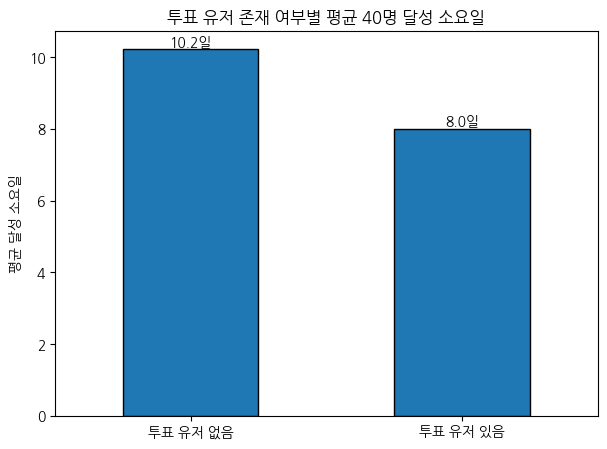

In [390]:
# 투표 유저 존재 여부별 평균 40명 달성 소요일
ax = days40_summary['mean_days'].plot(
    kind='bar',
    figsize=(7, 5),
    edgecolor='black'
)

for i, v in enumerate(days40_summary['mean_days']):
    ax.text(i, v, f'{v:.1f}일', ha='center', va='bottom')

plt.title('투표 유저 존재 여부별 평균 40명 달성 소요일')
plt.xlabel('')
plt.ylabel('평균 달성 소요일')
plt.xticks([0, 1], ['투표 유저 없음', '투표 유저 있음'], rotation=0)
plt.show()

학교 규모·학급 수 비교

In [391]:
# 학교 규모와 학급 수 비교
size_class_summary = (
    school_vote.groupby('has_voter')
    .agg(
        schools=('school_id', 'nunique'),
        mean_users=('school_user_count', 'mean'),
        median_users=('school_user_count', 'median'),
        mean_classes=('school_class_count', 'mean'),
        median_classes=('school_class_count', 'median')
    )
)

size_class_summary.round(2)

,schools,mean_users,median_users,mean_classes,median_classes
has_voter,,,,,
False,5541,121.28,108.0,14.13,13.0
True,10,509.00,496.0,34.60,36.0


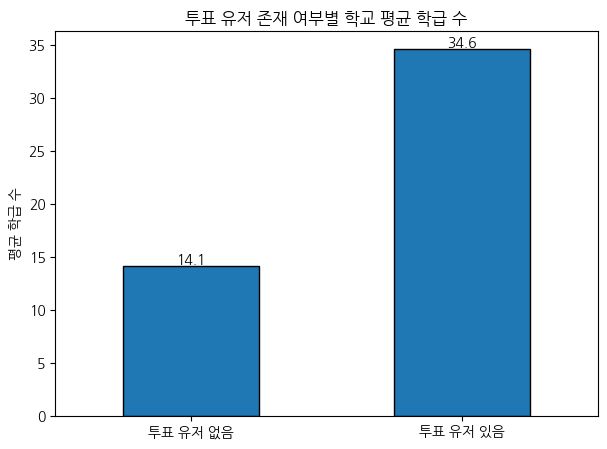

In [392]:
# 투표 유저 존재 여부별 평균 학급 수
ax = size_class_summary['mean_classes'].plot(
    kind='bar',
    figsize=(7, 5),
    edgecolor='black'
)

for i, v in enumerate(size_class_summary['mean_classes']):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')

plt.title('투표 유저 존재 여부별 학교 평균 학급 수')
plt.xlabel('')
plt.ylabel('평균 학급 수')
plt.xticks([0, 1], ['투표 유저 없음', '투표 유저 있음'], rotation=0)
plt.show()

학년 구성 비교

In [393]:
# 학교 × 학년별 유저 수
grade_count = (
    network_base
    .groupby(['school_id', 'grade'])
    ['user_id']
    .nunique()
    .unstack(fill_value=0)
)

# 1~3학년 컬럼 보장
grade_count = grade_count.reindex(
    columns=[1, 2, 3],
    fill_value=0
)

# 학교별 학년 비율
grade_share = (
    grade_count.div(
        grade_count.sum(axis=1),
        axis=0
    ) * 100
)

grade_share.columns = [
    'grade1_share',
    'grade2_share',
    'grade3_share'
]

# 투표 유저 존재 여부 연결
grade_share = grade_share.join(
    school_vote.set_index('school_id')['has_voter']
)

# 학교 단위 평균 학년 구성
grade_summary = (
    grade_share.groupby('has_voter')
    [['grade1_share', 'grade2_share', 'grade3_share']]
    .mean()
)

grade_summary.round(2)

,grade1_share,grade2_share,grade3_share
has_voter,,,
False,23.88,42.38,33.74
True,34.61,42.04,23.36


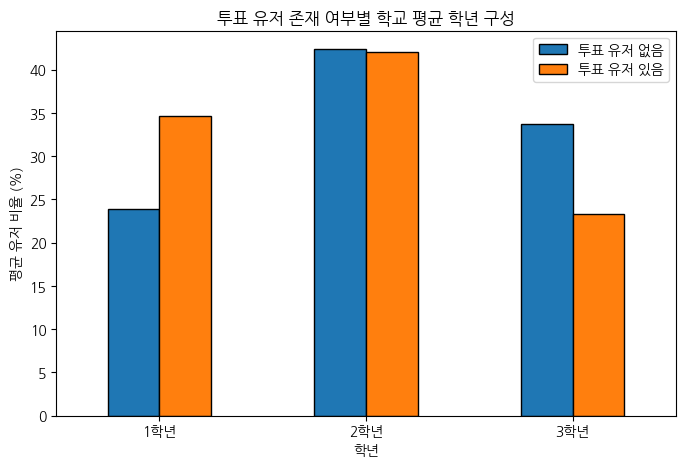

In [394]:
# 투표 유저 존재 여부별 평균 학년 구성
grade_summary.T.plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('투표 유저 존재 여부별 학교 평균 학년 구성')
plt.xlabel('학년')
plt.ylabel('평균 유저 비율 (%)')
plt.xticks(
    [0, 1, 2],
    ['1학년', '2학년', '3학년'],
    rotation=0
)
plt.legend(['투표 유저 없음', '투표 유저 있음'])
plt.show()

중·고등학교 / 지역 비교

In [395]:
# 투표 유저 존재 여부별 중학교/고등학교 구성비
school_type_result = pd.crosstab(
    school_vote['has_voter'],
    school_vote['school_type'],
    normalize='index'
) * 100

school_type_result.round(2)

school_type,H,M
has_voter,,
False,44.21,55.79
True,80.00,20.00


In [396]:
# 투표 유저 존재 여부별 학교급 구성비
school_type_result = pd.crosstab(
    school_vote['has_voter'],
    school_vote['school_type'],
    normalize='index'
) * 100

# 보기 좋은 이름으로 변경
school_type_result = school_type_result.rename(
    index={False: '투표 유저 없음', True: '투표 유저 있음'},
    columns={'M': '중학교', 'H': '고등학교'}
)

school_type_result.round(2)

school_type,고등학교,중학교
has_voter,,
투표 유저 없음,44.21,55.79
투표 유저 있음,80.00,20.00


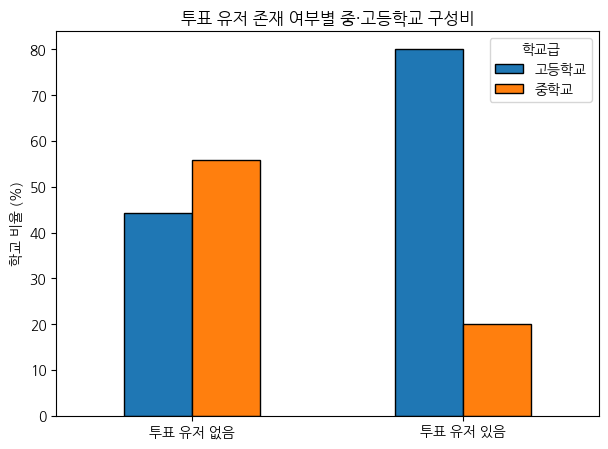

In [397]:
# 학교급 구성비 시각화
ax = school_type_result.plot(
    kind='bar',
    figsize=(7, 5),
    edgecolor='black'
)

plt.title('투표 유저 존재 여부별 중·고등학교 구성비')
plt.xlabel('')
plt.ylabel('학교 비율 (%)')
plt.xticks(rotation=0)
plt.legend(title='학교급')
plt.show()

In [398]:
# 주소에서 시·도 추출
region_pattern = (
    r'(서울특별시|부산광역시|대구광역시|인천광역시|광주광역시|'
    r'대전광역시|울산광역시|세종특별자치시|경기도|강원특별자치도|'
    r'강원도|충청북도|충청남도|전북특별자치도|전라북도|'
    r'전라남도|경상북도|경상남도|제주특별자치도)'
)

school_vote['region'] = (
    school_vote['school_address']
    .astype(str)
    .str.extract(region_pattern, expand=False)
)

# 보기 좋게 지역명 축약
region_map = {
    '서울특별시': '서울', '부산광역시': '부산',
    '대구광역시': '대구', '인천광역시': '인천',
    '광주광역시': '광주', '대전광역시': '대전',
    '울산광역시': '울산', '세종특별자치시': '세종',
    '경기도': '경기',
    '강원도': '강원', '강원특별자치도': '강원',
    '충청북도': '충북', '충청남도': '충남',
    '전라북도': '전북', '전북특별자치도': '전북',
    '전라남도': '전남',
    '경상북도': '경북', '경상남도': '경남',
    '제주특별자치도': '제주'
}

school_vote['region'] = school_vote['region'].replace(region_map)

# 투표 유저 존재 여부별 지역 구성비
region_result = pd.crosstab(
    school_vote['has_voter'],
    school_vote['region'],
    normalize='index'
) * 100

region_result.round(2)

region,강원,경기,경남,경북,광주,대구,대전,부산,서울,울산,인천,전남,전북,제주,충남,충북
has_voter,,,,,,,,,,,,,,,,
False,4.37,20.84,7.89,7.29,2.92,4.06,2.77,5.77,13.28,2.18,4.86,6.69,5.77,1.38,6.2,3.74
True,0.00,40.00,10.00,0.00,0.00,0.00,0.00,0.00,0.00,10.00,10.00,0.00,0.00,0.00,30.0,0.00


In [399]:
# 수도권 / 비수도권으로 재분류
# 수도권 여부 생성
metro_regions = ['서울', '경기', '인천']

school_vote['metro_type'] = np.where(
    school_vote['region'].isin(metro_regions),
    '수도권',
    '비수도권'
)

# 실제 학교 수 먼저 확인
metro_count = pd.crosstab(
    school_vote['has_voter'],
    school_vote['metro_type']
)

metro_count = metro_count.rename(
    index={False: '투표 유저 없음', True: '투표 유저 있음'}
)

metro_count

metro_type,비수도권,수도권
has_voter,,
투표 유저 없음,3392,2149
투표 유저 있음,5,5


In [400]:
# 투표 유저 존재 여부별 수도권/비수도권 구성비
metro_result = pd.crosstab(
    school_vote['has_voter'],
    school_vote['metro_type'],
    normalize='index'
) * 100

metro_result = metro_result.rename(
    index={False: '투표 유저 없음', True: '투표 유저 있음'}
)

metro_result.round(2)

metro_type,비수도권,수도권
has_voter,,
투표 유저 없음,61.22,38.78
투표 유저 있음,50.00,50.00


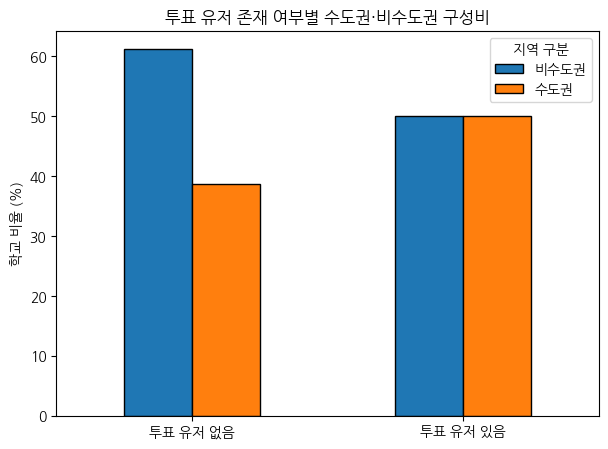

In [401]:
# 수도권/비수도권 구성비 시각화
ax = metro_result.plot(
    kind='bar',
    figsize=(7, 5),
    edgecolor='black'
)

plt.title('투표 유저 존재 여부별 수도권·비수도권 구성비')
plt.xlabel('')
plt.ylabel('학교 비율 (%)')
plt.xticks(rotation=0)
plt.legend(title='지역 구분')
plt.show()

### 투표 관련 추가 분석

#### 투표 Give ↔ Take 관계

UQR.user_id = 투표한 사람, chosen_user_id = 선택받은 사람

In [402]:
# 유저별 Give / Take 횟수 만들기

# 유저별 투표한 횟수(Give)
give_count = (
    uqr.groupby('user_id')
    .size()
)

# 유저별 선택받은 횟수(Take)
take_count = (
    uqr.groupby('chosen_user_id')
    .size()
)

# 몇 명의 서로 다른 유저에게 선택받았는지
unique_voters_received = (
    uqr.groupby('chosen_user_id')['user_id']
    .nunique()
)

# network_base에 유저 단위 지표 추가
network_base['give_count'] = (
    network_base['user_id'].map(give_count)
    .fillna(0)
    .astype(int)
)

network_base['take_count'] = (
    network_base['user_id'].map(take_count)
    .fillna(0)
    .astype(int)
)

network_base['unique_voters_received'] = (
    network_base['user_id'].map(unique_voters_received)
    .fillna(0)
    .astype(int)
)

# 투표 경험 여부
network_base['voter_group'] = np.where(
    network_base['give_count'] > 0,
    '투표 유저',
    '비투표 유저'
)

In [403]:
# 투표 유저 vs 비투표 유저의 Take 비교

# 투표 여부별 선택받은 정도 비교
give_take_summary = (
    network_base.groupby('voter_group')
    .agg(
        users=('user_id', 'nunique'),
        mean_take=('take_count', 'mean'),
        median_take=('take_count', 'median'),
        mean_unique_voters=('unique_voters_received', 'mean'),
        take_experience_rate=('take_count', lambda x: (x > 0).mean() * 100)
    )
)

give_take_summary.round(2)

,users,mean_take,median_take,mean_unique_voters,take_experience_rate
voter_group,,,,,
비투표 유저,672226,0.26,0.0,0.04,1.58
투표 유저,4849,214.09,179.0,31.06,99.46


표본 추출이 잘못되어 다시 진행

UQR에 한 번이라도 등장한 유저만 모집단

In [404]:
# 투표한 유저 / 선택받은 유저 ID
voter_ids = uqr['user_id'].dropna().unique()
chosen_ids = uqr['chosen_user_id'].dropna().unique()

# UQR 생태계에 한 번이라도 등장한 유저
uqr_user_ids = np.union1d(voter_ids, chosen_ids)

# UQR 관련 유저만 추출
give_take_base = network_base[
    network_base['user_id'].isin(uqr_user_ids)
].copy()

In [405]:
# 유저별 투표한 횟수(Give)
give_count = (
    uqr.groupby('user_id')
    .size()
)

# 유저별 선택받은 횟수(Take)
take_count = (
    uqr.groupby('chosen_user_id')
    .size()
)

# 서로 다른 몇 명에게 투표했는지
unique_given = (
    uqr.groupby('user_id')['chosen_user_id']
    .nunique()
)

# 서로 다른 몇 명에게 선택받았는지
unique_received = (
    uqr.groupby('chosen_user_id')['user_id']
    .nunique()
)

# 유저 단위 지표 추가
give_take_base['give_count'] = (
    give_take_base['user_id'].map(give_count).fillna(0).astype(int)
)

give_take_base['take_count'] = (
    give_take_base['user_id'].map(take_count).fillna(0).astype(int)
)

give_take_base['unique_given'] = (
    give_take_base['user_id'].map(unique_given).fillna(0).astype(int)
)

give_take_base['unique_received'] = (
    give_take_base['user_id'].map(unique_received).fillna(0).astype(int)
)

In [406]:
# Give / Take 여부에 따라 3개 유형 분류
give_take_base['give_take_type'] = np.select(
    [
        (give_take_base['give_count'] > 0) &
        (give_take_base['take_count'] > 0),

        (give_take_base['give_count'] > 0) &
        (give_take_base['take_count'] == 0),

        (give_take_base['give_count'] == 0) &
        (give_take_base['take_count'] > 0)
    ],
    [
        '투표+선택',
        '투표만',
        '선택만'
    ],
    default='기타'
)

# 유형별 유저 수
give_take_base['give_take_type'].value_counts()

,count
give_take_type,
선택만,10596
투표+선택,4823
투표만,26


In [407]:
# 유형별 Give / Take 규모 비교
give_take_summary = (
    give_take_base
    .groupby('give_take_type')
    .agg(
        users=('user_id', 'nunique'),
        mean_give=('give_count', 'mean'),
        median_give=('give_count', 'median'),
        mean_take=('take_count', 'mean'),
        median_take=('take_count', 'median'),
        mean_unique_given=('unique_given', 'mean'),
        mean_unique_received=('unique_received', 'mean')
    )
)

give_take_summary.round(2)

,users,mean_give,median_give,mean_take,median_take,mean_unique_given,mean_unique_received
give_take_type,,,,,,,
선택만,10596,0.00,0.0,16.59,6.0,0.00,2.84
투표+선택,4823,251.51,190.0,215.24,180.0,37.44,31.23
투표만,26,33.73,6.5,0.00,0.0,6.12,0.00


이전에 다은님 분석이랑 겹쳐서 더 진행 X

#### 투표 유저 vs 선택만 유저의 가입 환경

UQR에 실제 등장한 유저만 대상으로
투표한 유저 vs 선택만 받은 유저의 가입 당시 학교 네트워크 환경을 비교

In [408]:
# UQR 내 유저별 Give / Take 여부
voter_ids = set(uqr['user_id'].dropna().unique())
chosen_ids = set(uqr['chosen_user_id'].dropna().unique())

# UQR에 등장한 유저만 추출
uqr_env = network_base[
    network_base['user_id'].isin(voter_ids | chosen_ids)
].copy()

# 투표 유저 vs 선택만 유저 분류
uqr_env['uqr_group'] = np.where(
    uqr_env['user_id'].isin(voter_ids),
    '투표 유저',
    '선택만 받은 유저'
)

uqr_env['uqr_group'].value_counts()

,count
uqr_group,
선택만 받은 유저,10596
투표 유저,4849


In [409]:
# 가입순서 평균/중앙값 비교
join_summary = (
    uqr_env.groupby('uqr_group')
    .agg(
        users=('user_id', 'nunique'),
        mean_join_order=('join_order', 'mean'),
        median_join_order=('join_order', 'median')
    )
)

join_summary.round(2)

,users,mean_join_order,median_join_order
uqr_group,,,
선택만 받은 유저,10596,118.83,94.0
투표 유저,4849,249.64,247.0


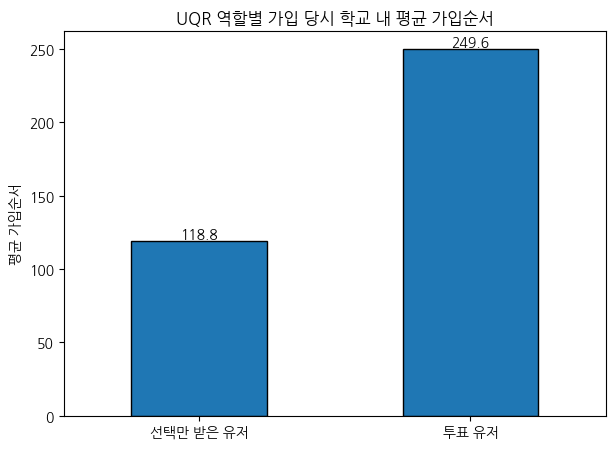

In [410]:
# 가입순서 평균 시각화
ax = join_summary['mean_join_order'].plot(
    kind='bar',
    figsize=(7, 5),
    edgecolor='black'
)

for i, v in enumerate(join_summary['mean_join_order']):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')

plt.title('UQR 역할별 가입 당시 학교 내 평균 가입순서')
plt.xlabel('')
plt.ylabel('평균 가입순서')
plt.xticks(rotation=0)
plt.show()

In [411]:
# 40명 이전 / 이후 가입 비율 비교

# 가입 당시 학교가 40명 이전인지 이후인지
uqr_env['network_stage'] = np.where(
    uqr_env['join_order'] < 40,
    '40명 이전',
    '40명 이후'
)

# 집단별 구성비
stage_result = pd.crosstab(
    uqr_env['uqr_group'],
    uqr_env['network_stage'],
    normalize='index'
) * 100

stage_result.round(2)

network_stage,40명 이전,40명 이후
uqr_group,,
선택만 받은 유저,25.85,74.15
투표 유저,8.00,92.00


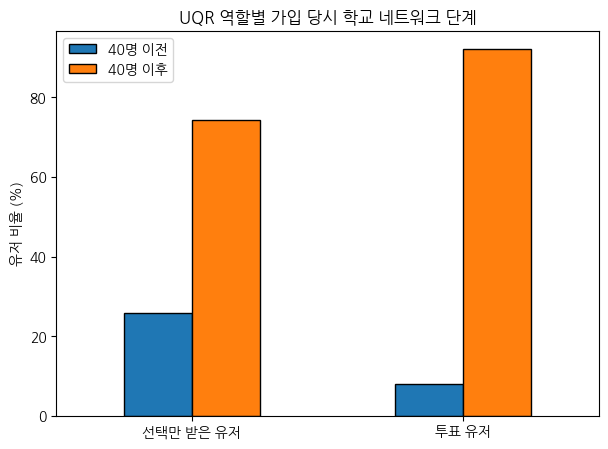

In [412]:
# 시각화
stage_result.plot(
    kind='bar',
    figsize=(7, 5),
    edgecolor='black'
)

plt.title('UQR 역할별 가입 당시 학교 네트워크 단계')
plt.xlabel('')
plt.ylabel('유저 비율 (%)')
plt.xticks(rotation=0)
plt.legend(title='')
plt.show()

-> 이상하다....?

소속 학교 규모·학급 수 비교

In [413]:
# 학교 네트워크 특성 비교
school_env_summary = (
    uqr_env.groupby('uqr_group')
    .agg(
        mean_school_users=('school_user_count', 'mean'),
        median_school_users=('school_user_count', 'median'),
        mean_classes=('school_class_count', 'mean'),
        median_classes=('school_class_count', 'median')
    )
)

school_env_summary.round(2)

,mean_school_users,median_school_users,mean_classes,median_classes
uqr_group,,,,
선택만 받은 유저,285.80,292.0,27.06,28.0
투표 유저,510.64,500.0,34.59,36.0


In [414]:
# 중학교 / 고등학교 구성비
type_result = pd.crosstab(
    uqr_env['uqr_group'],
    uqr_env['school_type'],
    normalize='index'
) * 100

type_result = type_result.rename(
    columns={'M': '중학교', 'H': '고등학교'}
)

type_result.round(2)

school_type,고등학교,중학교
uqr_group,,
선택만 받은 유저,83.44,16.56
투표 유저,80.51,19.49


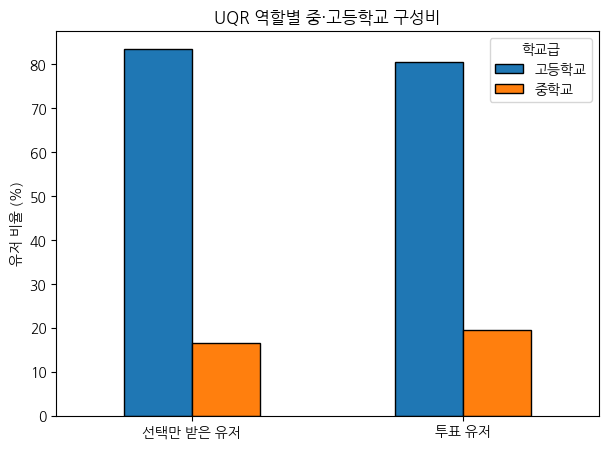

In [415]:
# 학교급 시각화
type_result.plot(
    kind='bar',
    figsize=(7, 5),
    edgecolor='black'
)

plt.title('UQR 역할별 중·고등학교 구성비')
plt.xlabel('')
plt.ylabel('유저 비율 (%)')
plt.xticks(rotation=0)
plt.legend(title='학교급')
plt.show()

##### 투표 관련 40명 이전 이후 확인

In [416]:
# 1. 선택만 받은 유저가 몇 개 학교에 분포하는지

# 투표 유저 / 선택받은 유저
voter_ids = set(uqr['user_id'].dropna().unique())
chosen_ids = set(uqr['chosen_user_id'].dropna().unique())

# 선택만 받은 유저
chosen_only_ids = chosen_ids - voter_ids

chosen_only = network_base[
    network_base['user_id'].isin(chosen_only_ids)
].copy()

# 선택만 받은 유저의 학교 분포
chosen_only_school = (
    chosen_only.groupby('school_id')
    .agg(
        chosen_only_users=('user_id', 'nunique')
    )
    .sort_values('chosen_only_users', ascending=False)
)

# 고유 학교 수
chosen_only_school_count = chosen_only['school_id'].nunique()

chosen_only_school_count

1345

In [417]:
# 2. 투표 유저 4,849명의 가입순서 직접 확인

# 투표 유저만 추출
voter_base = network_base[
    network_base['user_id'].isin(voter_ids)
].copy()

# 40명 이전 / 이후 구분
voter_base['network_stage'] = np.where(
    voter_base['join_order'] < 40,
    '40명 이전',
    '40명 이후'
)

# 유저 수와 비율
voter_stage = (
    voter_base.groupby('network_stage')
    .agg(users=('user_id', 'nunique'))
)

voter_stage['rate'] = (
    voter_stage['users'] / voter_base['user_id'].nunique() * 100
)

voter_stage.round(2)

,users,rate
network_stage,,
40명 이전,388,8.0
40명 이후,4461,92.0


In [418]:
# 3. 투표 유저 10개 학교별로도 쪼개서 확인

# 투표 유저가 속한 학교별 40명 이전/이후 분포
voter_school_stage = (
    voter_base.groupby(['school_id', 'network_stage'])
    .agg(users=('user_id', 'nunique'))
    .unstack(fill_value=0)
)

voter_school_stage.columns = voter_school_stage.columns.droplevel(0)

# 학교별 전체 투표 유저 수
voter_school_stage['total'] = voter_school_stage.sum(axis=1)

# 40명 이후 비율
voter_school_stage['after_40_rate'] = (
    voter_school_stage.get('40명 이후', 0)
    / voter_school_stage['total'] * 100
)

voter_school_stage.sort_values('total', ascending=False).round(2)

network_stage,40명 이전,40명 이후,total,after_40_rate
school_id,,,,
1719,39,502,541,92.79
369,39,498,537,92.74
5372,38,447,485,92.16
4516,39,440,479,91.86
5520,39,439,478,91.84
4426,39,431,470,91.70
1478,39,428,467,91.65
271,38,429,467,91.86
5491,39,424,463,91.58


In [419]:
# 4. 연락처 5,063명과 투표자 4,849명의 실제 차이 확인

# 연락처 유저
contact_ids = set(contacts['user_id'].dropna().unique())

# 집단별 ID
both_ids = contact_ids & voter_ids
contact_only_ids = contact_ids - voter_ids
voter_only_ids = voter_ids - contact_ids

contact_vote_overlap = pd.Series({
    '연락처 전체': len(contact_ids),
    '투표 유저 전체': len(voter_ids),
    '둘 다': len(both_ids),
    '연락처만': len(contact_only_ids),
    '투표만': len(voter_only_ids)
})

contact_vote_overlap

,0
연락처 전체,5063
투표 유저 전체,4849
둘 다,4824
연락처만,239
투표만,25


In [420]:
# 5. 연락처 집단 자체의 40명 이전/이후 분포 비교

# 연락처 유저
contact_base = network_base[
    network_base['user_id'].isin(contact_ids)
].copy()

contact_base['network_stage'] = np.where(
    contact_base['join_order'] < 40,
    '40명 이전',
    '40명 이후'
)

# 연락처 유저 vs 투표 유저 비교
stage_compare = pd.DataFrame({
    '연락처 유저': (
        contact_base['network_stage']
        .value_counts(normalize=True) * 100
    ),
    '투표 유저': (
        voter_base['network_stage']
        .value_counts(normalize=True) * 100
    )
}).fillna(0)

stage_compare.round(2)

,연락처 유저,투표 유저
network_stage,,
40명 이후,92.71,92.0
40명 이전,7.29,8.0


#### 활동 지속성 차이

투표 유저가 비투표/선택만 유저보다 실제로 더 오래 서비스를 이용했는가?

In [421]:
# 1. 7일 관측 가능한 코호트 만들기

# 날짜형 정리
attendance['attendance_date'] = pd.to_datetime(attendance['attendance_date'])
uqr_env['created_at'] = pd.to_datetime(uqr_env['created_at'])

# 가입일
uqr_env['signup_date'] = uqr_env['created_at'].dt.normalize()

# 출석 로그 관측 기간
attendance_start = attendance['attendance_date'].min().normalize()
attendance_end = attendance['attendance_date'].max().normalize()

# 가입 후 최소 7일까지 관측 가능한 유저만 사용
activity_base = uqr_env[
    (uqr_env['signup_date'] >= attendance_start) &
    (uqr_env['signup_date'] <= attendance_end - pd.Timedelta(days=7))
].copy()

activity_base['uqr_group'].value_counts()

,count
uqr_group,
선택만 받은 유저,232
투표 유저,107


In [422]:
# 2. 가입 후 1~7일 출석 기록 만들기

# 같은 날짜의 중복 출석 제거
att_unique = (
    attendance[['user_id', 'attendance_date']]
    .drop_duplicates()
    .copy()
)

# 가입일 연결
signup_map = activity_base.set_index('user_id')['signup_date']

att_unique['signup_date'] = (
    att_unique['user_id'].map(signup_map)
)

# 가입 후 며칠째 출석인지 계산
att_unique['days_after_signup'] = (
    att_unique['attendance_date'].dt.normalize()
    - att_unique['signup_date']
).dt.days

# 가입 후 1~7일 기록만 사용
att_7 = att_unique[
    att_unique['days_after_signup'].between(1, 7)
].copy()

att_7.head()

,user_id,attendance_date,signup_date,days_after_signup
90606,1525212,2023-05-29,2023-05-27,2.0
90607,1525212,2023-05-30,2023-05-27,3.0
90608,1525212,2023-05-31,2023-05-27,4.0
90609,1525212,2023-06-01,2023-05-27,5.0
90610,1525212,2023-06-02,2023-05-27,6.0


In [423]:
# 3. 유저별 7일 활동 지속성 지표 생성

# 유저별 7일 내 출석 지표
attendance_metrics = (
    att_7.groupby('user_id')
    .agg(
        attendance_days_7=('attendance_date', 'nunique'),
        last_attendance_day=('days_after_signup', 'max')
    )
)

# 분석 데이터에 연결
activity_base['attendance_days_7'] = (
    activity_base['user_id']
    .map(attendance_metrics['attendance_days_7'])
    .fillna(0)
    .astype(int)
)

activity_base['last_attendance_day'] = (
    activity_base['user_id']
    .map(attendance_metrics['last_attendance_day'])
    .fillna(0)
    .astype(int)
)

# 7일 내 출석 기록 1회 이상
activity_base['revisit_7d'] = (
    activity_base['attendance_days_7'] > 0
)

In [424]:
# 4. 투표 유저 vs 선택만 유저 비교

# UQR 역할별 활동 지속성 비교
activity_summary = (
    activity_base.groupby('uqr_group')
    .agg(
        users=('user_id', 'nunique'),
        revisit_7d=('revisit_7d', 'mean'),
        mean_attendance_days=('attendance_days_7', 'mean'),
        median_attendance_days=('attendance_days_7', 'median'),
        mean_last_day=('last_attendance_day', 'mean'),
        median_last_day=('last_attendance_day', 'median')
    )
)

# 비율을 %
activity_summary['revisit_7d'] *= 100

activity_summary.round(2)

,users,revisit_7d,mean_attendance_days,median_attendance_days,mean_last_day,median_last_day
uqr_group,,,,,,
선택만 받은 유저,232,64.22,2.26,1.5,3.06,2.5
투표 유저,107,51.40,1.62,1.0,2.47,1.0


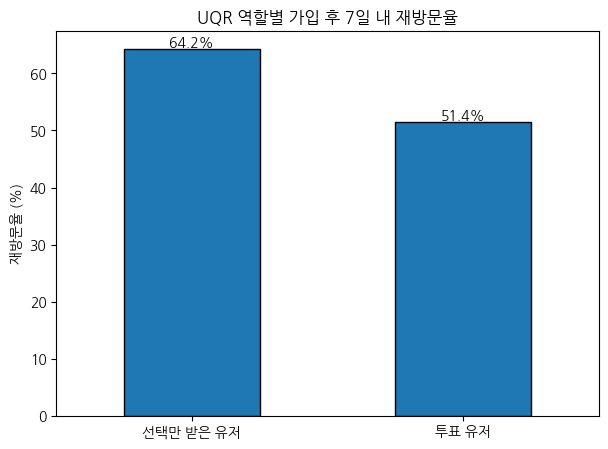

In [425]:
# 5. 시각화는 두 개가 핵심

# 7일 내 재방문율 비교
ax = activity_summary['revisit_7d'].plot(
    kind='bar',
    figsize=(7, 5),
    edgecolor='black'
)

for i, v in enumerate(activity_summary['revisit_7d']):
    ax.text(i, v, f'{v:.1f}%', ha='center', va='bottom')

plt.title('UQR 역할별 가입 후 7일 내 재방문율')
plt.xlabel('')
plt.ylabel('재방문율 (%)')
plt.xticks(rotation=0)
plt.show()

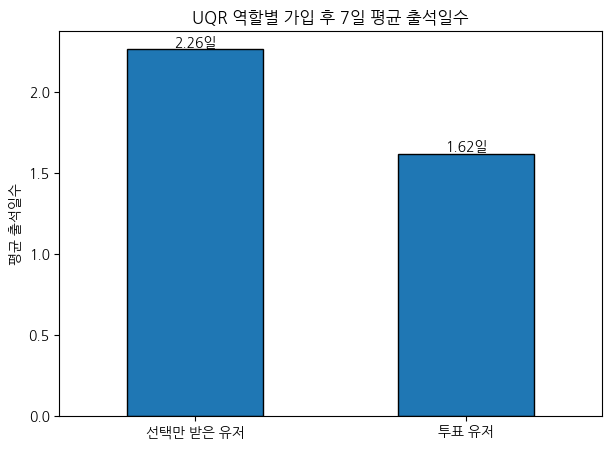

In [426]:
# 7일 내 평균 출석일수 비교
ax = activity_summary['mean_attendance_days'].plot(
    kind='bar',
    figsize=(7, 5),
    edgecolor='black'
)

for i, v in enumerate(activity_summary['mean_attendance_days']):
    ax.text(i, v, f'{v:.2f}일', ha='center', va='bottom')

plt.title('UQR 역할별 가입 후 7일 평균 출석일수')
plt.xlabel('')
plt.ylabel('평균 출석일수')
plt.xticks(rotation=0)
plt.show()

In [427]:
# Hackle 대용량 이벤트 로드 전 이전 EDA 변수 전체 해제
%reset -f

from pathlib import Path
import pandas as pd

project_path = Path('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트')
raw_path = project_path / '00_원본 csv'


## 출석체크가 자동인지 여부 확인

In [428]:
# Hackle 원본도 공통 raw_path를 사용

In [429]:
import pandas as pd

# Hackle 이벤트 테이블 불러오기
he = pd.read_csv(
    raw_path / 'hackle_events.csv',
    usecols=['event_id', 'event_datetime', 'event_key', 'session_id', 'item_name', 'page_name']
)

# 날짜형 변환
he['event_datetime'] = pd.to_datetime(he['event_datetime'])

he.head()

,event_id,event_datetime,event_key,session_id,item_name,page_name
0,00000533-3f1c-4b3b-81f1-0c8f35754b4e,2023-07-18 19:40:17,$session_start,4OzYh3seq3VKytpSn5pvQkZNQii1,NaN,NaN
1,00000716-27e9-4e72-a602-d0ce61784b06,2023-07-18 21:07:24,click_question_open,8QXy31PQxbW9qLzq0Y1dhR8Ypm52,NaN,NaN
2,000007c8-68ce-40e6-9b1e-f0e34e8ff9cc,2023-08-06 20:18:03,click_bottom_navigation_profile,6bcea65d-9f40-46fc-888c-700fe707483f,NaN,NaN
3,00000981-5e2a-4111-993e-4f1891ad9a53,2023-08-05 01:46:10,view_shop,XVYNT6zfhFWqIg9omwg2AHDjTLx2,NaN,NaN
4,00000a7a-ba72-4332-b4a9-7910670aaeb2,2023-07-24 15:03:37,click_bottom_navigation_lab,XFB2SPiGfjbVhvJ3Q3DBsaT3m2B3,NaN,NaN


In [430]:
# 관련 event_key 후보 확인
keywords = 'attendance|attend|check|friend|vote|question'

event_candidates = (
    he.loc[
        he['event_key'].str.contains(keywords, case=False, na=False),
        'event_key'
    ]
    .value_counts()
)

event_candidates

,count
event_key,
click_question_open,816801
click_bottom_navigation_questions,769163
skip_question,454981
view_questions_tap,353400
click_question_start,220385
click_attendance,157737
complete_question,154105
click_question_ask,136766
click_question_share,69241


In [431]:
he.loc[
    he[['event_key', 'item_name', 'page_name']]
      .astype(str)
      .apply(lambda x: x.str.contains(keywords, case=False, na=False))
      .any(axis=1),
    ['event_key', 'item_name', 'page_name']
].drop_duplicates()

,event_key,item_name,page_name
1,click_question_open,NaN,NaN
8,click_bottom_navigation_questions,NaN,NaN
10,skip_question,NaN,NaN
12,view_questions_tap,NaN,NaN
30,complete_question,NaN,NaN
93,click_attendance,NaN,home
115,click_question_ask,NaN,home
139,click_question_share,NaN,NaN
146,click_appbar_friend_plus,NaN,NaN
200,click_question_start,NaN,home


In [432]:
attendance_event = 'click_attendance'

question_events = [
    'click_question_start',              # 질문 시작
    'skip_question',                     # 질문 스킵
    'complete_question'                  # 질문 완료
]
# 친구요청 송수신은 Hackle에 직접 로그가 없음

### 출석 클릭 없이 핵심행동한 세션이 존재하는가

In [433]:
# 세션별 출석 클릭 / 핵심행동 여부
session_check = (
    he.groupby('session_id')
    .agg(
        attendance=('event_key', lambda x: (x == attendance_event).any()),
        core_action=('event_key', lambda x: x.isin(question_events).any())
    )
    .reset_index()
)

# 핵심행동이 발생한 세션만
core_sessions = session_check[session_check['core_action']]

pd.Series({
    '핵심행동 세션 수': len(core_sessions),
    '출석 클릭 O': core_sessions['attendance'].sum(),
    '출석 클릭 X': (~core_sessions['attendance']).sum(),
    '출석 없이 핵심행동 비율(%)':
        (~core_sessions['attendance']).mean() * 100
}).round(2)

,0
핵심행동 세션 수,75877.00
출석 클릭 O,29684.00
출석 클릭 X,46193.00
출석 없이 핵심행동 비율(%),60.88


### 핵심행동이 출석보다 먼저 일어난 세션

In [434]:
he['event_datetime'] = pd.to_datetime(he['event_datetime'])

# 세션별 최초 출석 / 최초 핵심행동 시간
first_times = (
    he.groupby('session_id')
    .apply(lambda g: pd.Series({
        'first_attendance':
            g.loc[g['event_key'].eq(attendance_event), 'event_datetime'].min(),
        'first_core':
            g.loc[g['event_key'].isin(question_events), 'event_datetime'].min()
    }))
    .reset_index()
)

# 핵심행동이 있는 세션만
first_times = first_times[first_times['first_core'].notna()]

first_times['type'] = '출석 후 핵심행동'
first_times.loc[first_times['first_attendance'].isna(), 'type'] = '출석 없이 핵심행동'
first_times.loc[
    first_times['first_attendance'].notna() &
    (first_times['first_core'] < first_times['first_attendance']),
    'type'
] = '핵심행동이 출석보다 먼저'

first_times['type'].value_counts()

/tmp/ipykernel_1293/1306842124.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,count
type,
출석 없이 핵심행동,46193
핵심행동이 출석보다 먼저,15027
출석 후 핵심행동,14657


#### 기능별로도 따로 확인

In [435]:
result = []

for event in question_events:
    sessions = set(he.loc[he['event_key'].eq(event), 'session_id'])
    attend_sessions = set(
        he.loc[he['event_key'].eq(attendance_event), 'session_id']
    )

    result.append({
        'event': event,
        '사용 세션 수': len(sessions),
        '출석 클릭 있는 세션': len(sessions & attend_sessions),
        '출석 클릭 없는 세션': len(sessions - attend_sessions),
        '출석 없이 사용 비율(%)':
            round(len(sessions - attend_sessions) / len(sessions) * 100, 2)
            if len(sessions) else 0
    })

pd.DataFrame(result)

,event,사용 세션 수,출석 클릭 있는 세션,출석 클릭 없는 세션,출석 없이 사용 비율(%)
0,click_question_start,75875,29683,46192,60.88
1,skip_question,39423,17341,22082,56.01
2,complete_question,50013,21921,28092,56.17


In [436]:
# Hackle 이벤트 데이터 해제 후 결제·포인트 EDA 시작
%reset -f

from pathlib import Path
import pandas as pd
import numpy as np

project_path = Path('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트')
clean_path = project_path / '01_전처리 완료된 csv'
raw_path = project_path / '00_원본 csv'
path = clean_path
project = project_path


## 9월 17일 EDA - 결제 관련

In [437]:
# 결제 분석에 필요한 테이블만 최소 컬럼으로 새로 로드
users = pd.read_csv(
    clean_path / 'accounts_user_cleaned.csv',
    usecols=['id', 'created_at']
)
uqr = pd.read_csv(
    clean_path / 'accounts_userquestionrecord_cleaned.csv',
    usecols=lambda c: c in {
        'id', 'user_question_record_id', 'user_id', 'chosen_user_id',
        'status', 'opened_times', 'has_read', 'question_id', 'created_at'
    }
)
payment = pd.read_csv(
    clean_path / 'accounts_paymenthistory_cleaned.csv',
    usecols=lambda c: c in {'user_id', 'productId', 'created_at'},
    parse_dates=['created_at']
)

users['created_at'] = pd.to_datetime(users['created_at'])
uqr['created_at'] = pd.to_datetime(uqr['created_at'])

payment.head()


,productId,created_at,user_id
0,heart.777,2023-05-13 21:28:34,1211127
1,heart.777,2023-05-13 21:29:39,1151343
2,heart.777,2023-05-13 21:31:33,1002147
3,heart.777,2023-05-13 21:31:39,1095040
4,heart.777,2023-05-13 21:34:32,1164081


In [438]:
# 포인트 이력도 분석에 필요한 컬럼만 로드
point = pd.read_csv(
    raw_path / 'accounts_pointhistory.csv',
    usecols=['user_id', 'user_question_record_id', 'delta_point', 'created_at'],
    parse_dates=['created_at']
)


In [439]:
# 테이블 크기와 컬럼 확인
pd.DataFrame({
    'rows': [len(payment), len(point), len(uqr), len(users)],
    'unique_users': [
        payment['user_id'].nunique(),
        point['user_id'].nunique(),
        uqr['user_id'].nunique(),
        users['id'].nunique()
    ]
}, index=['payment', 'point', 'uqr', 'users'])

,rows,unique_users
payment,94609,59192
point,2338918,5037
uqr,1213926,4849
users,677077,677077


In [440]:
# 실제 판매된 상품 확인
payment['productId'].value_counts()

,count
productId,
heart.777,57568
heart.1000,19189
heart.200,15722
heart.4000,2130


In [441]:
# 포인트 증감 종류
point['delta_point'].value_counts().sort_index()

,count
delta_point,
-1000,1422
-500,6147
-300,40266
-200,20781
-30,1
-10,39966
5,203173
6,203479
7,202967


In [442]:
# 투표 수신 후 행동 상태
uqr[['status', 'opened_times', 'has_read']].value_counts().head(20)

status  opened_times  has_read
C       0             1           618650
                      0           537672
I       1             1            43197
        2             1            11100
        3             1             2652
B       0             0              323
                      1              251
        1             1               53
        2             1               20
        3             1                8
Name: count, dtype: int64

In [443]:
# UQR의 PK 컬럼명 자동 확인
uqr_id_col = (
    'user_question_record_id'
    if 'user_question_record_id' in uqr.columns
    else 'id'
)

# 조인용 UQR
uqr_join = uqr[
    [uqr_id_col, 'user_id', 'chosen_user_id',
     'status', 'opened_times', 'question_id']
].rename(columns={uqr_id_col: 'uqr_id'})

# 포인트 기록 ↔ 투표 기록 연결
point_uqr = point.merge(
    uqr_join,
    left_on='user_question_record_id',
    right_on='uqr_id',
    how='left',
    suffixes=('_point', '_vote')
)

point_uqr.head()

,delta_point,created_at,user_id_point,user_question_record_id,uqr_id,user_id_vote,chosen_user_id,status,opened_times,question_id
0,9,2023-04-28 12:27:49,849436,771777.0,771777.0,849436.0,849469.0,C,0.0,252.0
1,9,2023-04-28 12:28:02,849436,771800.0,771800.0,849436.0,849446.0,C,0.0,244.0
2,5,2023-04-28 12:28:09,849436,771812.0,771812.0,849436.0,849454.0,C,0.0,183.0
3,13,2023-04-28 12:28:16,849436,771828.0,771828.0,849436.0,847375.0,C,0.0,101.0
4,5,2023-04-28 12:28:26,849436,771851.0,771851.0,849436.0,849477.0,C,0.0,209.0


In [444]:
pd.Series({
    '전체 포인트 기록': len(point_uqr),
    'UQR 연결 성공': point_uqr['uqr_id'].notna().sum(),
    '포인트 유저 = 투표한 유저': (
        point_uqr['user_id_point'] == point_uqr['user_id_vote']
    ).sum(),
    '포인트 유저 = 선택받은 유저': (
        point_uqr['user_id_point'] == point_uqr['chosen_user_id']
    ).sum()
})

,0
전체 포인트 기록,2338918
UQR 연결 성공,2327128
포인트 유저 = 투표한 유저,1216016
포인트 유저 = 선택받은 유저,1115165


In [445]:
import numpy as np

In [446]:
# 유저별 포인트 적립/소비 요약
point_user = point.groupby('user_id').agg(
    earned_point=('delta_point', lambda x: x[x > 0].sum()),
    spent_point=('delta_point', lambda x: -x[x < 0].sum())
)

# 소비 여부
point_user['point_type'] = np.where(
    point_user['spent_point'] > 0,
    '소비 경험',
    '적립만'
)

point_user['point_type'].value_counts()

,count
point_type,
소비 경험,4609
적립만,428


In [447]:
# 데이터 구조 이상 여부 확인
point_user[
    (point_user['earned_point'] == 0) &
    (point_user['spent_point'] > 0)
].shape[0]

0

포인트 관련 음수만 존재하는 유저 등의 이상치는 존재하지 않음

In [448]:
# 포인트 소비 유저 기준 결제 경험 비교
spend_ids = set(point_user.query('spent_point > 0').index)
no_spend_ids = set(point_user.query('spent_point == 0').index)
pay_ids = set(payment['user_id'].unique())

pd.Series({
    '전체 포인트 유저': len(point_user),
    '포인트 소비 유저': len(spend_ids),
    '포인트 미소비 유저': len(no_spend_ids),
    '소비 유저 중 결제 경험': len(spend_ids & pay_ids),
    '소비 유저 결제 경험률(%)': round(len(spend_ids & pay_ids) / len(spend_ids) * 100, 2)
})

,0
전체 포인트 유저,5037.00
포인트 소비 유저,4609.00
포인트 미소비 유저,428.00
소비 유저 중 결제 경험,407.00
소비 유저 결제 경험률(%),8.83


In [449]:
# 음수 포인트가 무슨 행동인지 다시 확인

# 포인트 차감 기록만 확인
point_uqr.loc[
    point_uqr['delta_point'] < 0,
    ['delta_point', 'status', 'opened_times']
].value_counts().head(30)

,,,count
delta_point,status,opened_times,
-10,C,0.0,35753
-300,I,1.0,23365
-200,I,1.0,14959
-300,I,2.0,10433
-500,I,2.0,4848
-200,I,2.0,4570
-300,I,3.0,3256
-10,I,1.0,2900
-1000,I,3.0,1420


In [450]:
# 결제 유저와 포인트 유저가 실제로 겹치는지

pay_ids = set(payment['user_id'].unique())
point_ids = set(point['user_id'].unique())

pd.Series({
    '결제 유저': len(pay_ids),
    '포인트 보유 유저': len(point_ids),
    '둘 다 경험': len(pay_ids & point_ids),
    '포인트 유저 중 결제 경험률(%)': round(len(pay_ids & point_ids) / len(point_ids) * 100, 2)
})

,0
결제 유저,59192.00
포인트 보유 유저,5037.00
둘 다 경험,410.00
포인트 유저 중 결제 경험률(%),8.14


In [451]:
# 유저별 구매 횟수
pay_per_user = payment.groupby('user_id').size()

pay_per_user.describe(percentiles=[.5, .75, .9, .95, .99])

,0
count,59192.000000
mean,1.598341
std,1.548523
min,1.000000
50%,1.000000
75%,2.000000
90%,3.000000
95%,4.000000
99%,8.000000
max,60.000000


In [452]:
# 상품별 구매량
payment['productId'].value_counts(normalize=True).mul(100).round(2)

,proportion
productId,
heart.777,60.85
heart.1000,20.28
heart.200,16.62
heart.4000,2.25


In [453]:
# 월별 결제 건수
payment['month'] = payment['created_at'].dt.to_period('M')

payment.groupby('month').size()

,0
month,
2023-05,82186
2023-06,7709
2023-07,2151
2023-08,1386
2023-09,435
2023-10,168
2023-11,147
2023-12,136
2024-01,110


### 300포인트 이상치

In [454]:
# 날짜형으로 변환
point['created_at'] = pd.to_datetime(point['created_at'])

In [455]:
# 포인트 차감 단가가 시기에 따라 변했는지 확인
point['month'] = point['created_at'].dt.to_period('M')

point_spend_month = (
    point[point['delta_point'] < 0]
    .groupby(['month', 'delta_point'])
    .size()
    .unstack(fill_value=0)
)

point_spend_month

delta_point,-1000,-500,-300,-200,-30,-10
month,,,,,,
2023-04,0,0,929,0,0,0
2023-05,891,4532,39337,16509,0,36133
2023-06,356,1239,0,3326,0,3833
2023-07,66,163,0,363,0,0
2023-08,38,88,0,166,0,0
2023-09,32,57,0,194,1,0
2023-10,12,17,0,58,0,0
2023-11,6,10,0,62,0,0
2023-12,5,17,0,41,0,0


In [456]:
# -300 포인트 차감 기록만 추출
point_300 = point_uqr[
    point_uqr['delta_point'] == -300
].copy()

# 상태 × 오픈 횟수 분포
point_300_summary = (
    point_300
    .groupby(['status', 'opened_times'])
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
)

point_300_summary

,status,opened_times,count
5,I,1.0,23365
6,I,2.0,10433
7,I,3.0,3256
1,B,1.0,38
2,B,2.0,32
3,B,3.0,12
4,C,0.0,4
0,B,0.0,3


In [457]:
# -300 포인트 차감 기록의 최초/마지막 발생 시점
point_300_date = point.loc[
    point['delta_point'] == -300,
    'created_at'
]

pd.Series({
    '최초 발생': point_300_date.min(),
    '마지막 발생': point_300_date.max()
})

,0
최초 발생,2023-04-28 14:31:21
마지막 발생,2023-05-18 13:18:52


In [458]:
# -200 포인트 차감 최초 발생 시점
point_200_date = point.loc[
    point['delta_point'] == -200,
    'created_at'
]

point_200_date.min()

Timestamp('2023-05-18 12:19:05')

In [459]:
pd.Series({
    '-500 최초 발생': point.loc[
        point['delta_point'] == -500, 'created_at'
    ].min(),

    '-1000 최초 발생': point.loc[
        point['delta_point'] == -1000, 'created_at'
    ].min()
})

,0
-500 최초 발생,2023-05-18 12:24:21
-1000 최초 발생,2023-05-18 12:51:30


In [460]:
pd.Series({
    '-300 마지막 발생시각': point.loc[
        point['delta_point'] == -300, 'created_at'
    ].max(),

    '-200 최초 발생시각': point.loc[
        point['delta_point'] == -200, 'created_at'
    ].min(),

    '-500 최초 발생시각': point.loc[
        point['delta_point'] == -500, 'created_at'
    ].min(),

    '-1000 최초 발생시각': point.loc[
        point['delta_point'] == -1000, 'created_at'
    ].min()
})

,0
-300 마지막 발생시각,2023-05-18 13:18:52
-200 최초 발생시각,2023-05-18 12:19:05
-500 최초 발생시각,2023-05-18 12:24:21
-1000 최초 발생시각,2023-05-18 12:51:30


In [461]:
# 초성 1단계 단가 변경 시점
change_time = point.loc[
    point['delta_point'] == -200,
    'created_at'
].min()

change_time

Timestamp('2023-05-18 12:19:05')

In [462]:
# 변경 전후 7일 결제 현황부터 비교

import pandas as pd

payment['created_at'] = pd.to_datetime(payment['created_at'])

before_start = change_time - pd.Timedelta(days=7)
after_end = change_time + pd.Timedelta(days=7)

payment_compare = payment[
    (payment['created_at'] >= before_start) &
    (payment['created_at'] < after_end)
].copy()

payment_compare['period'] = pd.cut(
    payment_compare['created_at'],
    bins=[before_start, change_time, after_end],
    labels=['300포인트 시기', '200포인트 시기'],
    right=False
)

payment_compare.groupby('period', observed=True).agg(
    결제건수=('user_id', 'size'),
    결제유저수=('user_id', 'nunique')
)

,결제건수,결제유저수
period,,
300포인트 시기,34419,24537
200포인트 시기,29492,19990


In [463]:
# 상품별 실제 판매가격
price_map = {
    'heart.200': 900,
    'heart.777': 1900,
    'heart.1000': 2900,
    'heart.4000': 9900
}

payment_compare['price'] = payment_compare['productId'].map(price_map)

payment_compare.groupby('period', observed=True).agg(
    결제유저수=('user_id', 'nunique'),
    결제건수=('user_id', 'size'),
    총매출=('price', 'sum'),
    유저당매출=('price', lambda x: x.sum())
)

,결제유저수,결제건수,총매출,유저당매출
period,,,,
300포인트 시기,24537,34419,73066100,73066100
200포인트 시기,19990,29492,63120800,63120800


In [464]:
result = payment_compare.groupby('period', observed=True).agg(
    결제유저수=('user_id', 'nunique'),
    결제건수=('user_id', 'size'),
    총매출=('price', 'sum')
)

result['결제유저당_매출'] = (
    result['총매출'] / result['결제유저수']
).round(0)

result['결제유저당_구매횟수'] = (
    result['결제건수'] / result['결제유저수']
).round(2)

result

,결제유저수,결제건수,총매출,결제유저당_매출,결제유저당_구매횟수
period,,,,,
300포인트 시기,24537,34419,73066100,2978.0,1.40
200포인트 시기,19990,29492,63120800,3158.0,1.48


In [465]:
# 정책 변경 시점
change_time = point.loc[
    point['delta_point'] == -200, 'created_at'
].min()

before_start = change_time - pd.Timedelta(days=7)
after_end = change_time + pd.Timedelta(days=7)

In [466]:
# 정책 변경 전후 Ping 수신 유저
before_ping = set(
    uqr.loc[
        (uqr['created_at'] >= before_start) &
        (uqr['created_at'] < change_time),
        'chosen_user_id'
    ].dropna().unique()
)

after_ping = set(
    uqr.loc[
        (uqr['created_at'] >= change_time) &
        (uqr['created_at'] < after_end),
        'chosen_user_id'
    ].dropna().unique()
)

# 같은 기간 결제 유저
before_pay = set(
    payment.loc[
        (payment['created_at'] >= before_start) &
        (payment['created_at'] < change_time),
        'user_id'
    ].unique()
)

after_pay = set(
    payment.loc[
        (payment['created_at'] >= change_time) &
        (payment['created_at'] < after_end),
        'user_id'
    ].unique()
)

pd.DataFrame({
    '기간': ['300·300·300', '200·500·1000'],
    'Ping 수신 유저': [len(before_ping), len(after_ping)],
    '결제 유저': [len(before_pay & before_ping), len(after_pay & after_ping)],
    '결제율(%)': [
        round(len(before_pay & before_ping) / len(before_ping) * 100, 2),
        round(len(after_pay & after_ping) / len(after_ping) * 100, 2)
    ]
})

,기간,Ping 수신 유저,결제 유저,결제율(%)
0,300·300·300,8742,452,5.17
1,200·500·1000,9181,292,3.18


가격 변경이 실제 초성 공개 깊이에 영향을 줬는지도 같이 봐야 함

In [467]:
# 변경 전후 UQR 구분
uqr_policy = uqr[
    (uqr['created_at'] >= before_start) &
    (uqr['created_at'] < after_end)
].copy()

uqr_policy['policy'] = np.where(
    uqr_policy['created_at'] < change_time,
    '300·300·300',
    '200·500·1000'
)

# opened_times 분포
open_compare = (
    uqr_policy[uqr_policy['opened_times'] > 0]
    .groupby(['policy', 'opened_times'])
    .size()
    .groupby(level=0)
    .apply(lambda x: (x / x.sum() * 100).round(2))
)

open_compare

policy        policy        opened_times
200·500·1000  200·500·1000  1               74.39
                            2               20.65
                            3                4.96
300·300·300   300·300·300   1               75.84
                            2               19.75
                            3                4.42
dtype: float64

### 현재 가격 기준 월별 매출

In [468]:
price_map = {
    'heart.200': 900,
    'heart.777': 1900,
    'heart.1000': 2900,
    'heart.4000': 9900
}

payment['price'] = payment['productId'].map(price_map)
payment['month'] = payment['created_at'].dt.to_period('M')

In [469]:
monthly_revenue = (
    payment.groupby('month')
    .agg(
        결제건수=('user_id', 'size'),
        결제유저수=('user_id', 'nunique'),
        매출=('price', 'sum')
    )
)

monthly_revenue['결제유저당_매출'] = (
    monthly_revenue['매출'] / monthly_revenue['결제유저수']
).round(0)

monthly_revenue

,결제건수,결제유저수,매출,결제유저당_매출
month,,,,
2023-05,82186,52649,174733400,3319.0
2023-06,7709,5596,16168100,2889.0
2023-07,2151,1655,4223900,2552.0
2023-08,1386,1055,2765400,2621.0
2023-09,435,345,845500,2451.0
2023-10,168,130,339200,2609.0
2023-11,147,121,308300,2548.0
2023-12,136,103,280400,2722.0
2024-01,110,94,226000,2404.0


In [470]:
monthly_product_revenue = (
    payment.groupby(['month', 'productId'])['price']
    .sum()
    .unstack(fill_value=0)
)

monthly_product_revenue['총매출'] = monthly_product_revenue.sum(axis=1)

monthly_product_revenue

productId,heart.1000,heart.200,heart.4000,heart.777,총매출
month,,,,,
2023-05,46962600,11626200,18938700,97205900,174733400
2023-06,5260600,1574100,1801800,7531600,16168100
2023-07,1539900,448200,128700,2107100,4223900
2023-08,1116500,285300,79200,1284400,2765400
2023-09,252300,90000,39600,463600,845500
2023-10,101500,35100,29700,172900,339200
2023-11,92800,24300,29700,161500,308300
2023-12,107300,27900,19800,125400,280400
2024-01,69600,13500,9900,133000,226000


### 9월 18일 EDA

#### 결제는 Ping 수신 이후에 일어나는게 맞나?

In [471]:
# Ping 수신 유저 / 결제 유저
ping_ids = set(uqr['chosen_user_id'].dropna().unique())
pay_ids = set(payment['user_id'].dropna().unique())

no_ping_pay_ids = pay_ids - ping_ids

pd.Series({
    '전체 결제 유저': len(pay_ids),
    'Ping 수신 경험 있는 결제 유저': len(pay_ids & ping_ids),
    'Ping 수신 경험 없는 결제 유저': len(no_ping_pay_ids),
    '결제 유저 중 Ping 미수신 비율(%)':
        round(len(no_ping_pay_ids) / len(pay_ids) * 100, 2)
})

,0
전체 결제 유저,59192.00
Ping 수신 경험 있는 결제 유저,1212.00
Ping 수신 경험 없는 결제 유저,57980.00
결제 유저 중 Ping 미수신 비율(%),97.95


In [472]:
# 유저별 최초 Ping / 최초 결제
first_ping = (
    uqr.groupby('chosen_user_id')['created_at']
    .min()
    .rename('first_ping')
)

first_pay = (
    payment.groupby('user_id')['created_at']
    .min()
    .rename('first_pay')
)

pay_ping = first_pay.to_frame().join(first_ping, how='left')

# 첫 결제 이전 Ping 수신 여부
pay_ping['ping_before_pay'] = (
    pay_ping['first_ping'].notna() &
    (pay_ping['first_ping'] <= pay_ping['first_pay'])
)

pd.Series({
    '전체 결제 유저': len(pay_ping),
    '결제 전 Ping 수신 유저': pay_ping['ping_before_pay'].sum(),
    '결제 전 Ping 미수신 유저': (~pay_ping['ping_before_pay']).sum(),
    '결제 전 Ping 미수신 비율(%)':
        round((~pay_ping['ping_before_pay']).mean() * 100, 2)
})

,0
전체 결제 유저,59192.00
결제 전 Ping 수신 유저,906.00
결제 전 Ping 미수신 유저,58286.00
결제 전 Ping 미수신 비율(%),98.47


아님

### 정책 변경 전후 신규가입자 → 결제 전환율 비교

In [473]:
# 정책 변경 시점
change_time = point.loc[
    point['delta_point'] == -200, 'created_at'
].min()

change_date = change_time.normalize()

users['created_at'] = pd.to_datetime(users['created_at'])
payment['created_at'] = pd.to_datetime(payment['created_at'])

# 변경 전/후 7일 가입자
before_users = users[
    (users['created_at'] >= change_date - pd.Timedelta(days=7)) &
    (users['created_at'] < change_date)
][['id', 'created_at']].rename(columns={
    'id': 'user_id',
    'created_at': 'signup_at'
})

after_users = users[
    (users['created_at'] >= change_date) &
    (users['created_at'] < change_date + pd.Timedelta(days=7))
][['id', 'created_at']].rename(columns={
    'id': 'user_id',
    'created_at': 'signup_at'
})

# 최초 결제
first_pay = (
    payment.groupby('user_id', as_index=False)['created_at']
    .min()
    .rename(columns={'created_at': 'first_pay'})
)

def signup_conversion(df, label):
    x = df.merge(first_pay, on='user_id', how='left')

    # 가입 후 7일 이내 결제
    x['pay_7d'] = (
        (x['first_pay'] >= x['signup_at']) &
        (x['first_pay'] < x['signup_at'] + pd.Timedelta(days=7))
    )

    return {
        '정책': label,
        '신규가입자': len(x),
        '7일내 결제유저': x['pay_7d'].sum(),
        '7일내 결제율(%)': round(x['pay_7d'].mean() * 100, 2)
    }

pd.DataFrame([
    signup_conversion(before_users, '300·300·300'),
    signup_conversion(after_users, '200·500·1000')
])

,정책,신규가입자,7일내 결제유저,7일내 결제율(%)
0,300·300·300,227466,18199,8.00
1,200·500·1000,123177,12139,9.85


신규가입자 전체의 7일 결제율은 8.00%→9.85%로 상승했지만 Ping 수신자의 결제율은 5.17%→3.18%로 하락해,

정책 변경이 전체 결제를 악화시켰다고 보기는 어렵고 Ping 기반 수익화 효율만 약화된 모습

### 전체 결제자 구매 구조

In [474]:
# 결제 순서
pay_sorted = payment.sort_values(['user_id', 'created_at']).copy()
pay_sorted['pay_order'] = pay_sorted.groupby('user_id').cumcount() + 1

# 유저별 구매 요약
pay_user = pay_sorted.groupby('user_id').agg(
    결제횟수=('productId', 'size'),
    누적결제금액=('price', 'sum')
)

pd.Series({
    '전체 결제유저': len(pay_user),
    '1회 결제유저': (pay_user['결제횟수'] == 1).sum(),
    '2회 이상 결제유저': (pay_user['결제횟수'] >= 2).sum(),
    '반복결제율(%)': round((pay_user['결제횟수'] >= 2).mean() * 100, 2),
    '1인당 평균 누적결제금액': round(pay_user['누적결제금액'].mean())
})

,0
전체 결제유저,59192.00
1회 결제유저,43277.00
2회 이상 결제유저,15915.00
반복결제율(%),26.89
1인당 평균 누적결제금액,3383.00


In [475]:
# 첫 구매 상품 분포
first_product = (
    pay_sorted[pay_sorted['pay_order'] == 1]['productId']
    .value_counts()
    .to_frame('유저수')
)

first_product['비율(%)'] = (
    first_product['유저수'] / first_product['유저수'].sum() * 100
).round(2)

first_product

,유저수,비율(%)
productId,,
heart.777,55703,94.11
heart.1000,2400,4.05
heart.200,588,0.99
heart.4000,501,0.85


In [476]:
# 첫 결제 → 두 번째 결제까지 얼마나 걸리는지

first_pay = (
    pay_sorted[pay_sorted['pay_order'] == 1]
    .set_index('user_id')['created_at']
)

second_pay = (
    pay_sorted[pay_sorted['pay_order'] == 2]
    .set_index('user_id')['created_at']
)

repurchase = pd.DataFrame({
    'first_pay': first_pay,
    'second_pay': second_pay
}).dropna()

repurchase['days_to_second'] = (
    repurchase['second_pay'] - repurchase['first_pay']
).dt.total_seconds() / 86400

repurchase['days_to_second'].describe(
    percentiles=[.25, .5, .75, .9]
)

,days_to_second
count,15915.000000
mean,4.911259
std,19.664061
min,0.000012
25%,0.002135
50%,0.299479
75%,2.099005
90%,7.931486
max,360.409398


In [477]:
# 첫 상품 → 두 번째 상품이 어떻게 바뀌는지

product_change = (
    pay_sorted[pay_sorted['pay_order'].isin([1, 2])]
    .pivot(index='user_id', columns='pay_order', values='productId')
    .dropna()
    .rename(columns={1: '첫구매', 2: '두번째구매'})
)

pd.crosstab(
    product_change['첫구매'],
    product_change['두번째구매']
)

두번째구매,heart.1000,heart.200,heart.4000,heart.777
첫구매,,,,
heart.1000,387,66,68,972
heart.200,38,71,4,253
heart.4000,40,3,51,136
heart.777,6810,6513,396,107


### 가격 구조 시뮬레이션 가능한지 확인 EDA

In [478]:
# 정책별 실제 단계 전환율부터 계산

# 날짜형 변환
uqr['created_at'] = pd.to_datetime(uqr['created_at'])
uqr['opened_times'] = pd.to_numeric(uqr['opened_times'], errors='coerce').fillna(0)

# 정책 변경 시점
change_time = point.loc[
    point['delta_point'] == -200, 'created_at'
].min()

# 변경 전후 동일하게 7일
before_start = change_time - pd.Timedelta(days=7)
after_end = change_time + pd.Timedelta(days=7)

policy_uqr = uqr[
    (uqr['created_at'] >= before_start) &
    (uqr['created_at'] < after_end)
].copy()

# UQR 생성 시점을 기준으로 당시 가격정책 구분
policy_uqr['policy'] = np.where(
    policy_uqr['created_at'] < change_time,
    '300·300·300',
    '200·500·1000'
)

# 정책별 단계 전환율 계산
def calc_open_rate(x):
    total = len(x)
    open1 = (x['opened_times'] >= 1).sum()
    open2 = (x['opened_times'] >= 2).sum()
    open3 = (x['opened_times'] >= 3).sum()

    return pd.Series({
        'Ping건수': total,
        '1단계오픈': open1,
        '1단계오픈율(%)': round(open1 / total * 100, 2),
        '2단계오픈': open2,
        '1→2단계전환율(%)': round(open2 / open1 * 100, 2) if open1 else 0,
        '3단계오픈': open3,
        '2→3단계전환율(%)': round(open3 / open2 * 100, 2) if open2 else 0,
        '전체3단계공개율(%)': round(open3 / total * 100, 2)
    })

policy_open_rate = (
    policy_uqr.groupby('policy')
    .apply(calc_open_rate, include_groups=False)
)

policy_open_rate

,Ping건수,1단계오픈,1단계오픈율(%),2단계오픈,1→2단계전환율(%),3단계오픈,2→3단계전환율(%),전체3단계공개율(%)
policy,,,,,,,,
200·500·1000,248193.0,12558.0,5.06,3216.0,25.61,623.0,19.37,0.25
300·300·300,404814.0,21047.0,5.20,5086.0,24.16,930.0,18.29,0.23


| 단계 | 과거 | 현재 |
|---|---:|---:|
| 1단계 | 300 → | **200** |
| 2단계 | 300 → | **500** |
| 3단계 | 300 → | **1000** |

가격정책 변경 전후 1단계 오픈율은 5.20%→5.06%로 유사했고,

2·3단계 전환율도 오히려 소폭 상승해 초성 오픈 행동이 가격 변화에 민감하게 반응했다고 보기 어렵다.

In [479]:
# 정책별 Ping 1건당 기대 포인트 소비량 계산
policy_open_rate['Ping당_평균포인트소비'] = [
    # 200·500·1000 정책
    (12558 * 200 + 3216 * 500 + 623 * 1000) / 248193,

    # 300·300·300 정책
    (21047 * 300 + 5086 * 300 + 930 * 300) / 404814
]

policy_open_rate[['Ping건수', 'Ping당_평균포인트소비']]

,Ping건수,Ping당_평균포인트소비
policy,,
200·500·1000,248193.0,19.108516
300·300·300,404814.0,20.055878


전체 공개 비용은 900→1700으로 크게 올랐는데 실제 Ping 1건당 평균 포인트 소비는 오히려 약간 감소

높은 2·3단계 가격이 전체 포인트 소비 증가로 이어지지는 않았다라고 볼 수 있는 근거가 됨

In [480]:
# 현재 정책의 실제 단계별 오픈율
current = policy_open_rate.loc['200·500·1000']

open1_rate = current['1단계오픈'] / current['Ping건수']
open2_rate = current['2단계오픈'] / current['Ping건수']
open3_rate = current['3단계오픈'] / current['Ping건수']

# 비교할 가격 후보안
plans = pd.DataFrame({
    '가격안': ['현행', 'A안', 'B안', 'C안', '과거정책'],
    '1단계': [200, 200, 200, 300, 300],
    '2단계': [500, 400, 300, 400, 300],
    '3단계': [1000, 700, 500, 600, 300]
})

# 오픈율이 동일하다고 가정했을 때 Ping 1건당 예상 포인트 소비
plans['전체오픈비용'] = plans[['1단계', '2단계', '3단계']].sum(axis=1)

plans['Ping당_예상포인트소비'] = (
    open1_rate * plans['1단계'] +
    open2_rate * plans['2단계'] +
    open3_rate * plans['3단계']
).round(2)

# 현행 대비 포인트 소비 변화
current_spend = plans.loc[plans['가격안'] == '현행', 'Ping당_예상포인트소비'].iloc[0]

plans['현행대비_소비변화(%)'] = (
    (plans['Ping당_예상포인트소비'] / current_spend - 1) * 100
).round(2)

plans

,가격안,1단계,2단계,3단계,전체오픈비용,Ping당_예상포인트소비,현행대비_소비변화(%)
0,현행,200,500,1000,1700,19.11,0.00
1,A안,200,400,700,1300,17.06,-10.73
2,B안,200,300,500,1000,15.26,-20.15
3,C안,300,400,600,1300,21.87,14.44
4,과거정책,300,300,300,900,19.82,3.72


오픈 행동이 현재 수준으로 유지된다는 보수적 가정하에 여러 안 비교


소비 단가를 낮췄을 때 결제율이 얼마나 올라야 매출이 유지되는지 손익분기점 비교 필요

In [481]:
# 현행 Ping 수신자 결제율
current_conversion = 3.18

# 현행 대비 예상 포인트 소비 비율
plans['소비비율'] = (
    plans['Ping당_예상포인트소비']
    / plans.loc[plans['가격안'] == '현행', 'Ping당_예상포인트소비'].iloc[0]
)

# 포인트 소비 감소만큼 결제자당 매출도 감소한다고 가정한 손익분기 결제율
plans['손익분기_결제율(%)'] = (
    current_conversion / plans['소비비율']
).round(2)

# 현행 결제율 대비 얼마나 더 올라야 하는지
plans['필요_결제율증가(%p)'] = (
    plans['손익분기_결제율(%)'] - current_conversion
).round(2)

plans[
    ['가격안', '전체오픈비용', 'Ping당_예상포인트소비',
     '현행대비_소비변화(%)', '손익분기_결제율(%)', '필요_결제율증가(%p)']
]

,가격안,전체오픈비용,Ping당_예상포인트소비,현행대비_소비변화(%),손익분기_결제율(%),필요_결제율증가(%p)
0,현행,1700,19.11,0.00,3.18,0.00
1,A안,1300,17.06,-10.73,3.56,0.38
2,B안,1000,15.26,-20.15,3.98,0.80
3,C안,1300,21.87,14.44,2.78,-0.40
4,과거정책,900,19.82,3.72,3.07,-0.11


In [482]:
# 정책 변경 전후 동일 7일
before_start = change_time - pd.Timedelta(days=7)
after_end = change_time + pd.Timedelta(days=7)

# 기간별 Ping 수신 유저
before_ping_ids = set(
    uqr.loc[
        (uqr['created_at'] >= before_start) &
        (uqr['created_at'] < change_time),
        'chosen_user_id'
    ].dropna().unique()
)

after_ping_ids = set(
    uqr.loc[
        (uqr['created_at'] >= change_time) &
        (uqr['created_at'] < after_end),
        'chosen_user_id'
    ].dropna().unique()
)

# 해당 기간 Ping 수신 유저의 결제 내역
before_pay = payment[
    (payment['user_id'].isin(before_ping_ids)) &
    (payment['created_at'] >= before_start) &
    (payment['created_at'] < change_time)
]

after_pay = payment[
    (payment['user_id'].isin(after_ping_ids)) &
    (payment['created_at'] >= change_time) &
    (payment['created_at'] < after_end)
]

# 실제 매출 효율 비교
actual_check = pd.DataFrame({
    '정책': ['300·300·300', '200·500·1000'],
    'Ping수신유저': [len(before_ping_ids), len(after_ping_ids)],
    '결제유저': [before_pay['user_id'].nunique(), after_pay['user_id'].nunique()],
    '매출': [before_pay['price'].sum(), after_pay['price'].sum()]
})

actual_check['결제유저당_매출'] = (
    actual_check['매출'] / actual_check['결제유저']
).round(0)

actual_check['Ping유저당_매출'] = (
    actual_check['매출'] / actual_check['Ping수신유저']
).round(0)

actual_check

,정책,Ping수신유저,결제유저,매출,결제유저당_매출,Ping유저당_매출
0,300·300·300,8742,452,1254000,2774.0,143.0
1,200·500·1000,9181,292,893700,3061.0,97.0


In [483]:
# 실제 변화율 한 번 정리

# 정책 변경 전후 핵심 지표 변화율
actual_change = pd.Series({
    'Ping수신유저 변화(%)':
        round((9181 / 8742 - 1) * 100, 2),

    '결제율 변화(%p)':
        round(3.18 - 5.17, 2),

    '결제유저당 매출 변화(%)':
        round((3061 / 2774 - 1) * 100, 2),

    'Ping유저당 매출 변화(%)':
        round((97 / 143 - 1) * 100, 2),

    '총매출 변화(%)':
        round((893700 / 1254000 - 1) * 100, 2),

    'Ping당 포인트소비 변화(%)':
        round((19.11 / 20.06 - 1) * 100, 2)
})

actual_change

,0
Ping수신유저 변화(%),5.02
결제율 변화(%p),-1.99
결제유저당 매출 변화(%),10.35
Ping유저당 매출 변화(%),-32.17
총매출 변화(%),-28.73
Ping당 포인트소비 변화(%),-4.74


### UQR 연결 여부에 따른 반복결제·결제규모 비교

In [484]:
# Ping 수신 기록이 확인되는 유저
ping_ids = set(uqr['chosen_user_id'].dropna().unique())

# 결제 유저별 구매 특성
pay_user = payment.groupby('user_id').agg(
    결제횟수=('productId', 'size'),
    누적결제금액=('price', 'sum')
)

# UQR에서 Ping 수신 기록이 연결되는지 구분
pay_user['UQR연결'] = np.where(
    pay_user.index.isin(ping_ids),
    'Ping 수신 기록 있음',
    'UQR 미연결'
)

# 반복결제 여부
pay_user['반복결제'] = pay_user['결제횟수'] >= 2

# 집단별 결제 특성 비교
pay_compare = pay_user.groupby('UQR연결').agg(
    결제유저수=('결제횟수', 'size'),
    반복결제유저=('반복결제', 'sum'),
    평균결제횟수=('결제횟수', 'mean'),
    평균누적결제금액=('누적결제금액', 'mean'),
    중앙누적결제금액=('누적결제금액', 'median')
)

pay_compare['반복결제율(%)'] = (
    pay_compare['반복결제유저'] / pay_compare['결제유저수'] * 100
).round(2)

pay_compare[['결제유저수', '반복결제유저', '반복결제율(%)',
             '평균결제횟수', '평균누적결제금액', '중앙누적결제금액']].round(2)

,결제유저수,반복결제유저,반복결제율(%),평균결제횟수,평균누적결제금액,중앙누적결제금액
UQR연결,,,,,,
Ping 수신 기록 있음,1212,307,25.33,1.59,3309.24,1900.0
UQR 미연결,57980,15608,26.92,1.60,3384.84,1900.0


In [485]:
# 결제·포인트 대용량 객체 해제 후 스키마 확인만 별도 실행
%reset -f

from pathlib import Path
import pandas as pd

project_path = Path('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트')
project = project_path
path = project_path / '01_전처리 완료된 csv'


## ERD 를 위한 컬럼 확인 사전 작업

In [486]:
tables = ['accounts_user', 'accounts_group', 'accounts_school', 'accounts_attendance', 'accounts_friendrequest', 'polls_question', 'polls_questionpiece', 'accounts_userquestionrecord', 'accounts_user_contacts', 'accounts_nearbyschool', 'accounts_blockrecord', 'accounts_userwithdraw', 'polls_usercandidate', 'accounts_paymenthistory', 'polls_questionset']

files = [f for f in path.glob('*.csv') if any(f.stem in [t + '_clean', t + '_cleaned', t + '_updated'] for t in tables)]
columns = {f.name: pd.read_csv(f, nrows=0).columns.tolist() for f in files}
columns

{'accounts_group_cleaned.csv': ['id', 'grade', 'class_num', 'school_id'],
 'polls_usercandidate_cleaned.csv': ['id',
  'created_at',
  'question_piece_id',
  'user_id'],
 'accounts_user_cleaned.csv': ['id',
  'gender',
  'is_push_on',
  'created_at',
  'ban_status',
  'pending_chat',
  'group_id',
  'alarm_count'],
 'accounts_userwithdraw_cleaned.csv': ['id', 'reason', 'created_at'],
 'polls_question_cleaned.csv': ['id', 'question_text', 'created_at'],
 'accounts_school_cleaned.csv': ['id',
  'address',
  'student_count',
  'school_type'],
 'polls_questionpiece_cleaned.csv': ['id',
  'is_voted',
  'created_at',
  'question_id',
  'is_skipped'],
 'accounts_user_contacts_cleaned.csv': ['id',
  'contacts_count',
  'invite_user_id_list',
  'user_id'],
 'accounts_friendrequest_cleaned.csv': ['id',
  'status',
  'created_at',
  'updated_at',
  'receive_user_id',
  'send_user_id'],
 'accounts_nearbyschool_cleaned.csv': ['id',
  'distance',
  'nearby_school_id',
  'school_id'],
 'accounts_atte

In [487]:
extra = ['accounts_pointhistory', 'accounts_failpaymenthistory']
check_tables = list(dict.fromkeys(tables + extra))

rows = []
for t in check_tables:
    matches = [f for f in path.glob('*.csv') if f.stem in [t, t + '_clean', t + '_cleaned', t + '_updated']]
    if not matches:
        rows.append([t, '파일 없음', []])
    for f in matches:
        rows.append([t, f.name, pd.read_csv(f, nrows=0).columns.tolist()])

schema = pd.DataFrame(rows, columns=['테이블', '파일명', '컬럼'])
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
    display(schema)

,테이블,파일명,컬럼
0,accounts_user,accounts_user_cleaned.csv,"[id, gender, is_push_on, created_at, ban_status, pending_chat, group_id, alarm_count]"
1,accounts_group,accounts_group_cleaned.csv,"[id, grade, class_num, school_id]"
2,accounts_school,accounts_school_cleaned.csv,"[id, address, student_count, school_type]"
3,accounts_attendance,accounts_attendance_clean.csv,"[attendance_record_id, user_id, attendance_date]"
4,accounts_friendrequest,accounts_friendrequest_cleaned.csv,"[id, status, created_at, updated_at, receive_user_id, send_user_id]"
5,polls_question,polls_question_cleaned.csv,"[id, question_text, created_at]"
6,polls_questionpiece,polls_questionpiece_cleaned.csv,"[id, is_voted, created_at, question_id, is_skipped]"
7,accounts_userquestionrecord,accounts_userquestionrecord_cleaned.csv,"[id, status, created_at, chosen_user_id, question_id, user_id, question_piece_id, has_read, answer_status, answer_updated_at, report_count, opened_times]"
8,accounts_userquestionrecord,accounts_userquestionrecord_updated.csv,"[id, status, created_at, chosen_user_id, question_id, user_id, question_piece_id, has_read, answer_status, answer_updated_at, report_count, opened_times]"
9,accounts_user_contacts,accounts_user_contacts_cleaned.csv,"[id, contacts_count, invite_user_id_list, user_id]"


In [488]:
matches = [f for f in project.rglob('*.csv') if any(t in f.name.lower() for t in ['pointhistory', 'failpayment'])]
[str(f.relative_to(project)) for f in matches]

['00_원본 csv/accounts_pointhistory.csv',
 '00_원본 csv/accounts_failpaymenthistory.csv']

In [489]:
import pandas as pd

path = project / '01_전처리 완료된 csv'
tables = ['accounts_user', 'accounts_group', 'accounts_school', 'accounts_attendance', 'accounts_friendrequest', 'polls_question', 'polls_questionpiece', 'accounts_userquestionrecord', 'accounts_user_contacts', 'accounts_nearbyschool', 'accounts_blockrecord', 'accounts_userwithdraw', 'polls_usercandidate', 'accounts_paymenthistory', 'polls_questionset']
extra = ['accounts_pointhistory', 'accounts_failpaymenthistory']
originals = [f for f in project.rglob('*.csv') if f.stem in extra]

rows = []
for t in tables + extra:
    matches = [f for f in originals if f.stem == t] if t in extra else [f for f in path.glob('*.csv') if f.stem in [t + '_clean', t + '_cleaned', t + '_updated']]
    if not matches:
        rows.append([t, '파일 없음', []])
    for f in matches:
        rows.append([t, str(f.relative_to(project)), pd.read_csv(f, nrows=0).columns.tolist()])

schema = pd.DataFrame(rows, columns=['테이블', '파일명', '컬럼'])
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
    display(schema)

,테이블,파일명,컬럼
0,accounts_user,01_전처리 완료된 csv/accounts_user_cleaned.csv,"[id, gender, is_push_on, created_at, ban_status, pending_chat, group_id, alarm_count]"
1,accounts_group,01_전처리 완료된 csv/accounts_group_cleaned.csv,"[id, grade, class_num, school_id]"
2,accounts_school,01_전처리 완료된 csv/accounts_school_cleaned.csv,"[id, address, student_count, school_type]"
3,accounts_attendance,01_전처리 완료된 csv/accounts_attendance_clean.csv,"[attendance_record_id, user_id, attendance_date]"
4,accounts_friendrequest,01_전처리 완료된 csv/accounts_friendrequest_cleaned.csv,"[id, status, created_at, updated_at, receive_user_id, send_user_id]"
5,polls_question,01_전처리 완료된 csv/polls_question_cleaned.csv,"[id, question_text, created_at]"
6,polls_questionpiece,01_전처리 완료된 csv/polls_questionpiece_cleaned.csv,"[id, is_voted, created_at, question_id, is_skipped]"
7,accounts_userquestionrecord,01_전처리 완료된 csv/accounts_userquestionrecord_cleaned.csv,"[id, status, created_at, chosen_user_id, question_id, user_id, question_piece_id, has_read, answer_status, answer_updated_at, report_count, opened_times]"
8,accounts_userquestionrecord,01_전처리 완료된 csv/accounts_userquestionrecord_updated.csv,"[id, status, created_at, chosen_user_id, question_id, user_id, question_piece_id, has_read, answer_status, answer_updated_at, report_count, opened_times]"
9,accounts_user_contacts,01_전처리 완료된 csv/accounts_user_contacts_cleaned.csv,"[id, contacts_count, invite_user_id_list, user_id]"


In [490]:
# status 분포 확인에 필요한 컬럼만 다시 로드
qset = pd.read_csv(
    path / 'polls_questionset_clean.csv',
    usecols=['status']
)

status_dist = (
    qset['status']
    .value_counts(dropna=False)
    .rename_axis('status')
    .reset_index(name='count')
)

status_dist['ratio(%)'] = (
    status_dist['count'] / len(qset) * 100
).round(2)

status_dist


,status,count,ratio(%)
0,F,153411,96.86
1,O,4407,2.78
2,C,566,0.36


In [491]:
# 출석 PK 중복 확인에 필요한 컬럼만 로드
attendance = pd.read_csv(
    path / 'accounts_attendance_clean.csv',
    usecols=['attendance_record_id', 'attendance_date']
)

attendance['attendance_record_id'].duplicated().sum()


np.int64(1893635)

In [492]:
attendance.duplicated(
    subset=['attendance_record_id', 'attendance_date']
).sum()

np.int64(0)

In [493]:
# 메모리 부족 방지 및 변수 초기화 (재현성 유지)
%reset -f

---

# 3. 발표자료 시각화

발표에 사용한 핵심 지표와 최종 그래프를 재현합니다.

발표자료에 사용한 최종 시각화 코드입니다.  \n초기 친구 상호작용·투표 경험 수준과 후속 활동 관련 그래프를 재현합니다.

In [494]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 한글 폰트
!pip install -q koreanize-matplotlib
import koreanize_matplotlib

# 프로젝트 경로
project_path = Path('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트')
clean_path = project_path / '01_전처리 완료된 csv'
path = clean_path

# 시각화에 필요한 테이블
users = pd.read_csv(path / 'accounts_user_cleaned.csv')
groups = pd.read_csv(path / 'accounts_group_cleaned.csv')
schools = pd.read_csv(path / 'accounts_school_cleaned.csv')
uqr = pd.read_csv(path / 'accounts_userquestionrecord_cleaned.csv')

# 친구요청은 대용량이라 아래에서 chunk 처리
friend_path = path / 'accounts_friendrequest_cleaned.csv'

users['created_at'] = pd.to_datetime(users['created_at'])
uqr['created_at'] = pd.to_datetime(uqr['created_at'])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [495]:
# merge 키 이름 통일
groups_base = groups.rename(columns={'id': 'group_id'})
schools_base = schools.rename(columns={'id': 'school_id'})

# 유저 + 그룹 + 학교
network_base = (
    users
    .merge(
        groups_base[['group_id', 'school_id', 'grade', 'class_num']],
        on='group_id',
        how='left',
        validate='many_to_one'
    )
    .merge(
        schools_base[['school_id', 'student_count', 'school_type', 'address']],
        on='school_id',
        how='left',
        validate='many_to_one'
    )
    .rename(columns={'id': 'user_id', 'address': 'school_address'})
)

# 학교를 식별할 수 없는 유저 제외
network_base = network_base.dropna(subset=['school_id']).copy()
network_base['school_id'] = network_base['school_id'].astype(int)

# 가입일
network_base['signup_at'] = network_base['created_at']
network_base['signup_date'] = network_base['created_at'].dt.normalize()

# 행동 로그가 온전히 관측되는 공통 코호트
analysis_base = network_base[
    network_base['created_at'] >= pd.Timestamp('2023-04-29')
].copy()

signup_map = analysis_base.set_index('user_id')['signup_date']

analysis_base.shape

(667282, 16)

## 슬라이드 10 — 초기 친구 상호작용 × 투표 강도

In [496]:
# 가입 후 며칠째 투표인지 계산
vote = uqr[['user_id', 'created_at']].copy()
vote['signup_date'] = vote['user_id'].map(signup_map)
vote = vote.dropna(subset=['signup_date'])

vote['days_after_signup'] = (
    vote['created_at'].dt.normalize() - vote['signup_date']
).dt.days

# D0~D3 초기 투표 횟수
vote_3d_count = (
    vote[vote['days_after_signup'].between(0, 3)]
    .groupby('user_id')
    .size()
)

analysis_base['vote_count_3d'] = (
    analysis_base['user_id']
    .map(vote_3d_count)
    .fillna(0)
    .astype(int)
)

# 후속활동용 투표 유저
vote_4_7_ids = set(
    vote.loc[vote['days_after_signup'].between(4, 7), 'user_id']
)

vote_4_30_ids = set(
    vote.loc[vote['days_after_signup'].between(4, 30), 'user_id']
)

In [497]:
# 초기 친구요청 및 후속 친구요청 유저
sent_early, received_early = set(), set()
sent_4_7, sent_4_30 = set(), set()

friend_end = pd.Timestamp.min

for chunk in pd.read_csv(
    friend_path,
    usecols=['send_user_id', 'receive_user_id', 'created_at'],
    chunksize=1_000_000
):
    chunk['created_at'] = pd.to_datetime(chunk['created_at'])
    friend_end = max(friend_end, chunk['created_at'].max())

    # 송신자 가입일
    chunk['send_signup'] = chunk['send_user_id'].map(signup_map)
    send_days = (
        chunk['created_at'].dt.normalize() - chunk['send_signup']
    ).dt.days

    # 수신자 가입일
    chunk['receive_signup'] = chunk['receive_user_id'].map(signup_map)
    receive_days = (
        chunk['created_at'].dt.normalize() - chunk['receive_signup']
    ).dt.days

    # D0~D3 친구요청 상호작용
    sent_early.update(
        chunk.loc[send_days.between(0, 3), 'send_user_id'].dropna()
    )
    received_early.update(
        chunk.loc[receive_days.between(0, 3), 'receive_user_id'].dropna()
    )

    # 후속 활동은 능동행동인 '송신' 기준
    sent_4_7.update(
        chunk.loc[send_days.between(4, 7), 'send_user_id'].dropna()
    )
    sent_4_30.update(
        chunk.loc[send_days.between(4, 30), 'send_user_id'].dropna()
    )

In [498]:
# D0~D3 친구요청 송수신 경험 여부
analysis_base['friend_interaction_3d'] = (
    analysis_base['user_id'].isin(sent_early) |
    analysis_base['user_id'].isin(received_early)
)

# 초기 투표 경험자의 중앙값을 낮음/높음 기준으로 사용
vote_median = analysis_base.loc[
    analysis_base['vote_count_3d'] > 0,
    'vote_count_3d'
].median()

vote_median

101.0

In [499]:
# 투표 강도 구분
analysis_base['vote_level_3d'] = np.select(
    [
        analysis_base['vote_count_3d'] == 0,
        analysis_base['vote_count_3d'].between(1, vote_median),
        analysis_base['vote_count_3d'] > vote_median
    ],
    [
        '투표 없음',
        '낮은 투표',
        '높은 투표'
    ],
    default='기타'  # 문자열로 통일
)

analysis_base['vote_level_3d'].value_counts()

,count
vote_level_3d,
투표 없음,662784
낮은 투표,2263
높은 투표,2235


In [500]:
# 친구 연결 여부 × 투표 강도 조합
analysis_base['initial_type'] = np.select(
    [
        (~analysis_base['friend_interaction_3d']) & (analysis_base['vote_level_3d'] == '투표 없음'),
        (~analysis_base['friend_interaction_3d']) & (analysis_base['vote_level_3d'] == '낮은 투표'),
        (~analysis_base['friend_interaction_3d']) & (analysis_base['vote_level_3d'] == '높은 투표'),
        (analysis_base['friend_interaction_3d']) & (analysis_base['vote_level_3d'] == '투표 없음'),
        (analysis_base['friend_interaction_3d']) & (analysis_base['vote_level_3d'] == '낮은 투표'),
        (analysis_base['friend_interaction_3d']) & (analysis_base['vote_level_3d'] == '높은 투표')
    ],
    [
        '연결X·투표없음',
        '연결X·낮은투표',
        '연결X·높은투표',
        '연결O·투표없음',
        '연결O·낮은투표',
        '연결O·높은투표'
    ],
    default='기타'  # 문자열로 통일
)

analysis_base['initial_type'].value_counts()

,count
initial_type,
연결O·투표없음,651259
연결X·투표없음,11525
연결O·낮은투표,2263
연결O·높은투표,2235


In [501]:
# D0~D3 투표 경험 유저의 투표 횟수 분포 확인
vote_stats = analysis_base.loc[
    analysis_base['vote_count_3d'] > 0,
    'vote_count_3d'
].describe(percentiles=[.25, .5, .75, .9])

vote_stats

,vote_count_3d
count,4498.000000
mean,124.360827
std,97.530738
min,1.000000
25%,50.000000
50%,101.000000
75%,177.000000
90%,262.000000
max,629.000000


In [502]:
# D4~D7 / D4~D30 후속 핵심행동
analysis_base['followup_4_7d'] = (
    analysis_base['user_id'].isin(sent_4_7) |
    analysis_base['user_id'].isin(vote_4_7_ids)
)

analysis_base['followup_4_30d'] = (
    analysis_base['user_id'].isin(sent_4_30) |
    analysis_base['user_id'].isin(vote_4_30_ids)
)

# 두 행동 로그가 모두 존재하는 마지막 시점
activity_end = min(
    friend_end,
    uqr['created_at'].max()
)

# 각 후속기간을 끝까지 관측할 수 있는 유저만 사용
base_7 = analysis_base[
    analysis_base['signup_at'] <= activity_end - pd.Timedelta(days=7)
].copy()

base_30 = analysis_base[
    analysis_base['signup_at'] <= activity_end - pd.Timedelta(days=30)
].copy()

In [503]:
# 보기 좋은 그룹 순서
group_order = [
    '연결X·투표없음',
    '연결X·낮은투표',
    '연결X·높은투표',
    '연결O·투표없음',
    '연결O·낮은투표',
    '연결O·높은투표'
]

# 그룹별 후속 활동률
result_7 = (
    base_7.groupby('initial_type')['followup_4_7d']
    .mean().mul(100)
)

result_30 = (
    base_30.groupby('initial_type')['followup_4_30d']
    .mean().mul(100)
)

slide10_result = pd.concat(
    [result_7.rename('D4~D7'), result_30.rename('D4~D30')],
    axis=1
).reindex(group_order)

slide10_result.round(2)

,D4~D7,D4~D30
initial_type,,
연결X·투표없음,10.35,29.20
연결X·낮은투표,NaN,NaN
연결X·높은투표,NaN,NaN
연결O·투표없음,31.51,44.27
연결O·낮은투표,77.77,84.27
연결O·높은투표,95.12,97.05


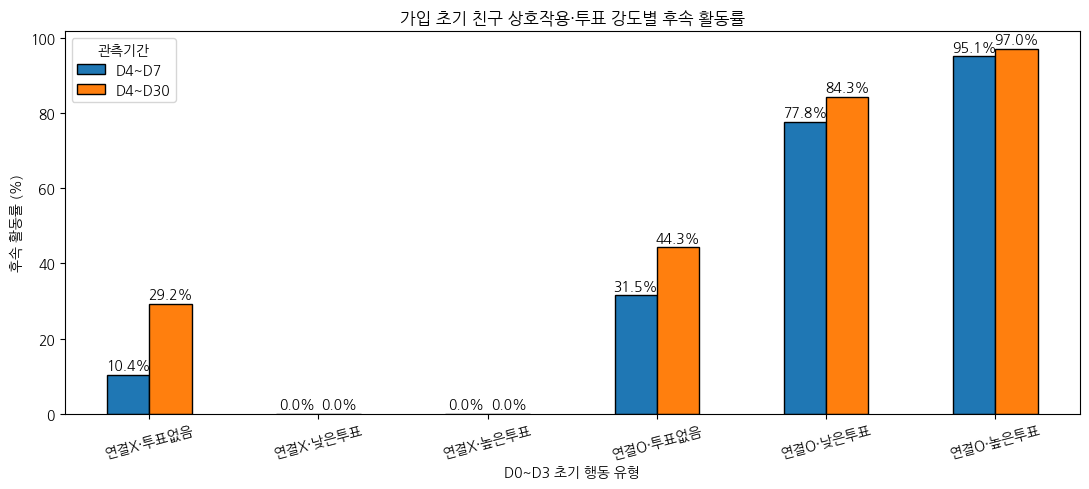

In [504]:
# 슬라이드 10 시각화
ax = slide10_result.plot(
    kind='bar',
    figsize=(11, 5),
    edgecolor='black'
)

# 막대 위 값 표시
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=2)

plt.title('가입 초기 친구 상호작용·투표 강도별 후속 활동률')
plt.xlabel('D0~D3 초기 행동 유형')
plt.ylabel('후속 활동률 (%)')
plt.xticks(rotation=15)
plt.legend(title='관측기간')
plt.tight_layout()
plt.show()

In [505]:
# 친구 연결 여부 × 초기 투표 강도별 실제 유저 수 확인
group_count = (
    analysis_base
    .groupby(['friend_interaction_3d', 'vote_level_3d'])
    .size()
    .unstack(fill_value=0)
)

group_count

vote_level_3d,낮은 투표,높은 투표,투표 없음
friend_interaction_3d,,,
False,0,0,11525
True,2263,2235,651259


In [506]:
# 그래프에 사용한 6개 그룹별 표본 수
analysis_base['initial_type'].value_counts().reindex([
    '연결X·투표없음',
    '연결X·낮은투표',
    '연결X·높은투표',
    '연결O·투표없음',
    '연결O·낮은투표',
    '연결O·높은투표'
], fill_value=0)

,count
initial_type,
연결X·투표없음,11525
연결X·낮은투표,0
연결X·높은투표,0
연결O·투표없음,651259
연결O·낮은투표,2263
연결O·높은투표,2235


In [507]:
# 4개 실제 유형으로 재정의
analysis_base['initial_type_4'] = np.select(
    [
        (~analysis_base['friend_interaction_3d']) & (analysis_base['vote_count_3d'] == 0),
        (analysis_base['friend_interaction_3d']) & (analysis_base['vote_count_3d'] == 0),
        (analysis_base['friend_interaction_3d']) & (analysis_base['vote_level_3d'] == '낮은 투표'),
        (analysis_base['friend_interaction_3d']) & (analysis_base['vote_level_3d'] == '높은 투표')
    ],
    [
        '친구 상호작용 없음·투표 없음',
        '친구 상호작용 있음·투표 없음',
        '친구 상호작용 있음·낮은 투표',
        '친구 상호작용 있음·높은 투표'
    ],
    default='기타'
)

# 새 컬럼이 반영되도록 관측기간 데이터 다시 생성
base_7 = analysis_base[
    analysis_base['signup_at'] <= activity_end - pd.Timedelta(days=7)
].copy()

base_30 = analysis_base[
    analysis_base['signup_at'] <= activity_end - pd.Timedelta(days=30)
].copy()

In [508]:
# 그룹 순서
group_order = [
    '친구 상호작용 없음·투표 없음',
    '친구 상호작용 있음·투표 없음',
    '친구 상호작용 있음·낮은 투표',
    '친구 상호작용 있음·높은 투표'
]

# 후속 활동률 계산
result_7 = (
    base_7.groupby('initial_type_4')['followup_4_7d']
    .mean().mul(100)
)

result_30 = (
    base_30.groupby('initial_type_4')['followup_4_30d']
    .mean().mul(100)
)

slide10_result = pd.concat(
    [result_7.rename('D4~D7'), result_30.rename('D4~D30')],
    axis=1
).reindex(group_order)

slide10_result.round(2)

,D4~D7,D4~D30
initial_type_4,,
친구 상호작용 없음·투표 없음,10.35,29.20
친구 상호작용 있음·투표 없음,31.51,44.27
친구 상호작용 있음·낮은 투표,77.77,84.27
친구 상호작용 있음·높은 투표,95.12,97.05


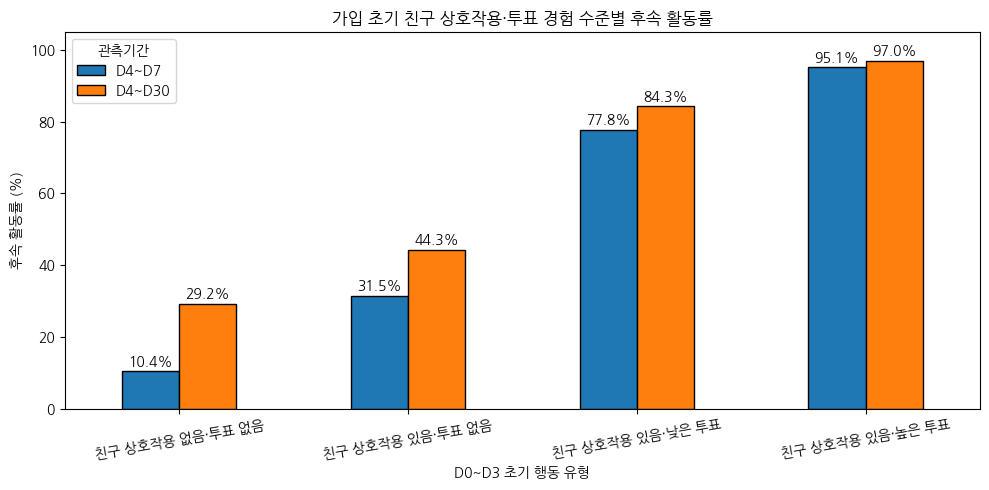

In [509]:
# 슬라이드 10 시각화
ax = slide10_result.plot(
    kind='bar',
    figsize=(10, 5),
    edgecolor='black'
)

# 막대 위 후속 활동률 표시
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=2)

plt.title('가입 초기 친구 상호작용·투표 경험 수준별 후속 활동률')
plt.xlabel('D0~D3 초기 행동 유형')
plt.ylabel('후속 활동률 (%)')
plt.xticks(rotation=10)
plt.legend(title='관측기간')
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

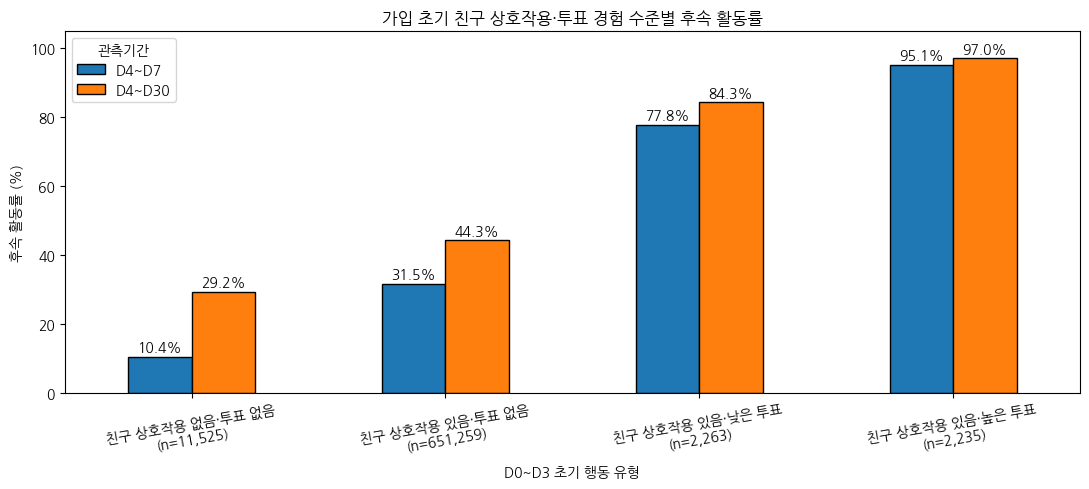

In [510]:
# 그룹별 표본 수
group_count = (
    analysis_base['initial_type_4']
    .value_counts()
    .reindex(group_order)
)

# 시각화
ax = slide10_result.plot(
    kind='bar',
    figsize=(11, 5),
    edgecolor='black'
)

# 막대 위 활동률 표시
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=2)

# x축에 그룹별 표본 수 추가
labels = [
    f'{group}\n(n={group_count[group]:,})'
    for group in group_order
]

plt.title('가입 초기 친구 상호작용·투표 경험 수준별 후속 활동률')
plt.xlabel('D0~D3 초기 행동 유형')
plt.ylabel('후속 활동률 (%)')
plt.xticks(
    ticks=range(len(group_order)),
    labels=labels,
    rotation=10
)
plt.legend(title='관측기간')
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

## 핵심행동

In [511]:
# D0~D3 친구요청 송신 여부
analysis_base['friend_sent_3d'] = analysis_base['user_id'].isin(sent_early)

# D0~D3 투표 여부
analysis_base['voted_3d'] = analysis_base['vote_count_3d'] > 0

# 4개 행동 유형 구분
analysis_base['core_action_type'] = np.select(
    [
        (~analysis_base['friend_sent_3d']) & (~analysis_base['voted_3d']),
        (analysis_base['friend_sent_3d']) & (~analysis_base['voted_3d']),
        (~analysis_base['friend_sent_3d']) & (analysis_base['voted_3d']),
        (analysis_base['friend_sent_3d']) & (analysis_base['voted_3d'])
    ],
    [
        '둘 다 없음',
        '친구요청만',
        '투표만',
        '친구요청+투표'
    ],
    default='기타'
)

# 유저 수와 비율
core_action_dist = (
    analysis_base['core_action_type']
    .value_counts()
    .reindex(['둘 다 없음', '친구요청만', '투표만', '친구요청+투표'])
    .to_frame('유저수')
)

core_action_dist['비율(%)'] = (
    core_action_dist['유저수'] / core_action_dist['유저수'].sum() * 100
).round(2)

core_action_dist

,유저수,비율(%)
core_action_type,,
둘 다 없음,44284,6.64
친구요청만,618500,92.69
투표만,53,0.01
친구요청+투표,4445,0.67


In [512]:
# 메모리 부족 방지 및 변수 초기화 (재현성 유지)
%reset -f

---

# 4. 주제 3 EDA — 질문 기반 유저 반응과 수익화 연관성

질문 카테고리별 초성 개봉·답장·포인트 소비와 결제 경험의 연관성을 분석합니다.

## 데이터 불러오기

In [513]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [514]:
# 프로젝트 공통 경로
path = Path('/content/drive/MyDrive/코드잇 3팀 고급 프로젝트')

In [523]:
# 하위 폴더
raw_path = path / '00_원본 csv'
clean_path = path / '01_전처리 완료된 csv'
text_path = path / '02_추가_csv'

In [516]:
[x.name for x in path.iterdir()]

['00_원본 csv',
 '99_SQL 테이블 -> csv 파일로 변경하는 코드',
 '고급_SNS 데이터 명세서.gsheet',
 '01_전처리 완료된 csv',
 '02_추가_csv',
 '03_ipynb 파일']

In [524]:
[x.name for x in clean_path.iterdir()]

['accounts_group_cleaned.csv',
 'polls_usercandidate_cleaned.csv',
 'accounts_user_cleaned.csv',
 'accounts_userwithdraw_cleaned.csv',
 'polls_question_cleaned.csv',
 'accounts_school_cleaned.csv',
 'polls_questionpiece_cleaned.csv',
 'accounts_user_contacts_cleaned.csv',
 'accounts_friendrequest_cleaned.csv',
 'accounts_nearbyschool_cleaned.csv',
 'accounts_attendance_clean.csv',
 'polls_questionset_piece_clean.csv',
 'polls_questionset_clean.csv',
 'accounts_paymenthistory_cleaned.csv',
 'accounts_blockrecord_clean.csv',
 'accounts_userquestionrecord_cleaned.csv',
 'accounts_userquestionrecord_updated.csv']

In [525]:
# 질문 카테고리
questions = pd.read_csv(
    text_path / 'questions_combined_final.csv'
)

# 투표 수신 / 읽기 / 초성 개봉
uqr = pd.read_csv(
    clean_path / 'accounts_userquestionrecord_updated.csv',
    parse_dates=['created_at', 'answer_updated_at']
)

# 질문 조각 - 실제 투표/스킵
qpiece = pd.read_csv(
    clean_path / 'polls_questionpiece_cleaned.csv',
    parse_dates=['created_at']
)

# 질문세트
qset = pd.read_csv(
    clean_path / 'polls_questionset_clean.csv',
    parse_dates=['created_at', 'opening_time']
)

# 유저 정보
users = pd.read_csv(
    clean_path / 'accounts_user_cleaned.csv',
    parse_dates=['created_at']
)

In [526]:
point = pd.read_csv(
    raw_path / 'accounts_pointhistory.csv',
    parse_dates=['created_at']
)

In [527]:
pd.DataFrame({
    'data': ['questions', 'uqr', 'qpiece', 'qset', 'users'],
    'rows': [len(questions), len(uqr), len(qpiece), len(qset), len(users)],
    'cols': [
        questions.shape[1], uqr.shape[1], qpiece.shape[1],
        qset.shape[1], users.shape[1]
    ]
})

,data,rows,cols
0,questions,3901,5
1,uqr,1213926,12
2,qpiece,1264349,5
3,qset,158384,8
4,users,677077,8


## ① 질문세트 카테고리 구성에 따른 참여·완주 차이

### 1. 카테고리별 질문 공급량

In [528]:
category_supply = (
    questions.groupby('category')
    .agg(question_count=('id', 'nunique'))
    .reset_index()
)

category_supply['supply_pct'] = (
    category_supply['question_count']
    / category_supply['question_count'].sum()
    * 100
).round(2)

category_supply.sort_values('question_count', ascending=False)

,category,question_count,supply_pct
2,외적 매력·연애 호감,927,23.76
4,취향·생활습관·상황,870,22.30
3,우정·신뢰·관계 친밀도,832,21.33
1,성격·감정·사회적 태도,658,16.87
0,능력·학업·미래,614,15.74


In [529]:
!pip install koreanize-matplotlib

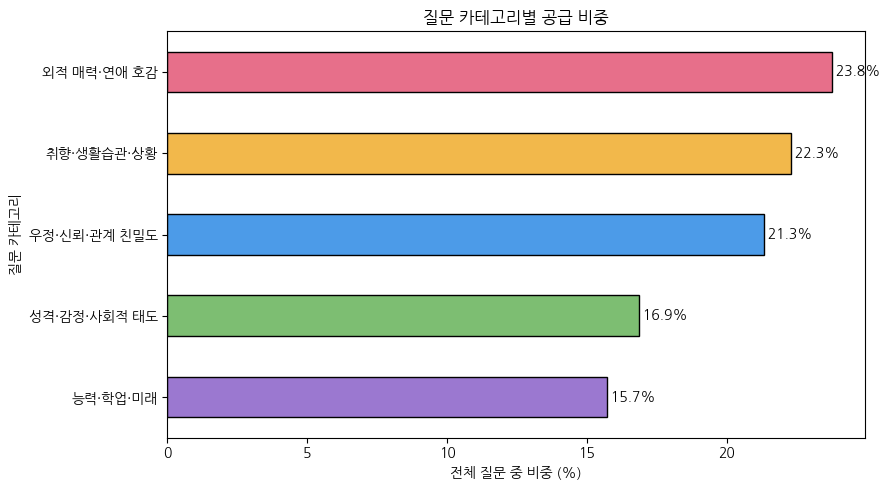

In [530]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

# 카테고리별 고정 색상
category_colors = {
    '외적 매력·연애 호감': '#E76F8A',
    '우정·신뢰·관계 친밀도': '#4C9BE8',
    '성격·감정·사회적 태도': '#7DBE72',
    '취향·생활습관·상황': '#F2B84B',
    '능력·학업·미래': '#9B78D0'
}

# 공급 비율 기준 정렬
plot_df = category_supply.sort_values('supply_pct')
colors = plot_df['category'].map(category_colors)

ax = plot_df.plot(
    x='category',
    y='supply_pct',
    kind='barh',
    figsize=(9, 5),
    color=colors,
    edgecolor='black',
    legend=False
)

# 막대 끝에 비율 표시
for i, v in enumerate(plot_df['supply_pct']):
    ax.text(
        v,
        i,
        f' {v:.1f}%',
        va='center'
    )

plt.title('질문 카테고리별 공급 비중')
plt.xlabel('전체 질문 중 비중 (%)')
plt.ylabel('질문 카테고리')
plt.tight_layout()
plt.show()

### 2. 실제 카테고리별 노출량

In [531]:
qpiece_cat = qpiece.merge(
    questions[['id', 'category']],
    left_on='question_id',
    right_on='id',
    how='left'
)

qpiece_cat[['question_id', 'category']].head()

,question_id,category
0,252,외적 매력·연애 호감
1,244,능력·학업·미래
2,183,우정·신뢰·관계 친밀도
3,101,능력·학업·미래
4,209,외적 매력·연애 호감


In [532]:
qpiece_cat['category'].isna().sum()

np.int64(10179)

In [533]:
category_exposure = (
    qpiece_cat.groupby('category')
    .agg(exposure_count=('question_id', 'size'))
    .reset_index()
)

category_exposure['exposure_pct'] = (
    category_exposure['exposure_count']
    / category_exposure['exposure_count'].sum()
    * 100
).round(2)

category_exposure.sort_values('exposure_count', ascending=False)

,category,exposure_count,exposure_pct
2,외적 매력·연애 호감,305735,24.38
1,성격·감정·사회적 태도,272817,21.75
3,우정·신뢰·관계 친밀도,255472,20.37
0,능력·학업·미래,221062,17.63
4,취향·생활습관·상황,199084,15.87


### 3. 공급 비중 vs 실제 노출 비중 비교

In [534]:
supply_exposure = category_supply.merge(
    category_exposure,
    on='category',
    how='left'
)

supply_exposure['exposure_vs_supply'] = (
    supply_exposure['exposure_pct']
    - supply_exposure['supply_pct']
).round(2)

supply_exposure.sort_values('exposure_pct', ascending=False)

,category,question_count,supply_pct,exposure_count,exposure_pct,exposure_vs_supply
2,외적 매력·연애 호감,927,23.76,305735,24.38,0.62
1,성격·감정·사회적 태도,658,16.87,272817,21.75,4.88
3,우정·신뢰·관계 친밀도,832,21.33,255472,20.37,-0.96
0,능력·학업·미래,614,15.74,221062,17.63,1.89
4,취향·생활습관·상황,870,22.30,199084,15.87,-6.43


In [535]:
# 질문세트 상태 분포
qset_status = (
    qset['status']
    .value_counts(dropna=False)
    .rename_axis('status')
    .reset_index(name='count')
)

qset_status['ratio'] = (
    qset_status['count'] / len(qset) * 100
).round(2)

qset_status

,status,count,ratio
0,F,153411,96.86
1,O,4407,2.78
2,C,566,0.36


In [536]:
qset['status'].unique()

array(['F', 'C', 'O'], dtype=object)

In [537]:
# 실제 열린 세트만
opened_qset = qset[qset['status'].isin(['O', 'F'])].copy()

completion_rate = (
    (opened_qset['status'] == 'F').mean() * 100
)

round(completion_rate, 2)

np.float64(97.21)

In [538]:
pd.DataFrame({
    '열린_세트수': [len(opened_qset)],
    '완료_세트수': [(opened_qset['status'] == 'F').sum()],
    '미완료_세트수': [(opened_qset['status'] == 'O').sum()],
    '완주율(%)': [round(completion_rate, 2)]
})

,열린_세트수,완료_세트수,미완료_세트수,완주율(%)
0,157818,153411,4407,97.21


In [539]:
completion_rate_all = (
    (qset['status'] == 'F').mean() * 100
)

round(completion_rate_all, 2)

np.float64(96.86)

In [540]:
qset_piece = pd.read_csv(
    clean_path / 'polls_questionset_piece_clean.csv'
)

qset_piece.columns.tolist()

['questionset_id', 'question_piece_id', 'stored_position']

In [541]:
qset.columns.tolist()

['questionset_id',
 'user_id',
 'status',
 'created_at',
 'opening_time',
 'opening_delay_seconds',
 'opening_before_created',
 'same_user_created_at_set_count']

In [542]:
qset_piece.head()

,questionset_id,question_piece_id,stored_position
0,99817,998458,1
1,99817,998459,2
2,99817,998460,3
3,99817,998461,4
4,99817,998462,5


세트 → 질문 → 카테고리 연결

In [543]:
# 질문세트 상태 붙이기
set_piece = qset_piece.merge(
    qset[['questionset_id', 'status']],
    on='questionset_id',
    how='left'
)

# question_piece → 실제 question
set_piece = set_piece.merge(
    qpiece[['id', 'question_id']],
    left_on='question_piece_id',
    right_on='id',
    how='left'
).drop(columns='id')

# question → category
set_piece = set_piece.merge(
    questions[['id', 'category']],
    left_on='question_id',
    right_on='id',
    how='left'
).drop(columns='id')

set_piece.head()

,questionset_id,question_piece_id,stored_position,status,question_id,category
0,99817,998458,1,F,252.0,외적 매력·연애 호감
1,99817,998459,2,F,244.0,능력·학업·미래
2,99817,998460,3,F,183.0,우정·신뢰·관계 친밀도
3,99817,998461,4,F,101.0,능력·학업·미래
4,99817,998462,5,F,209.0,외적 매력·연애 호감


In [544]:
set_coverage = (
    set_piece.groupby('questionset_id')
    .agg(
        question_count=('question_piece_id', 'size'),
        categorized_count=('category', 'count')
    )
    .reset_index()
)

set_coverage['category_match_rate'] = (
    set_coverage['categorized_count']
    / set_coverage['question_count']
    * 100
).round(2)

set_coverage[
    ['question_count', 'categorized_count', 'category_match_rate']
].describe()

,question_count,categorized_count,category_match_rate
count,158384.0,158384.000000,158384.000000
mean,10.0,7.918540,79.185398
std,0.0,2.373258,23.732579
min,10.0,0.000000,0.000000
25%,10.0,7.000000,70.000000
50%,10.0,9.000000,90.000000
75%,10.0,10.000000,100.000000
max,10.0,10.000000,100.000000


In [545]:
fully_matched_sets = set_coverage[
    (set_coverage['question_count'] == 10) &
    (set_coverage['categorized_count'] == 10)
]

len(fully_matched_sets), round(
    len(fully_matched_sets) / len(set_coverage) * 100, 2
)

(52128, 32.91)

In [546]:
valid_set_ids = fully_matched_sets['questionset_id']

valid_piece = set_piece[
    set_piece['questionset_id'].isin(valid_set_ids)
].copy()

set_category = (
    valid_piece.groupby(
        ['questionset_id', 'status', 'category']
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# F만 완료
set_category['is_finished'] = (
    set_category['status'] == 'F'
).astype(int)

set_category.head()

category,questionset_id,status,능력·학업·미래,성격·감정·사회적 태도,외적 매력·연애 호감,우정·신뢰·관계 친밀도,취향·생활습관·상황,is_finished
0,99817,F,4,1,4,1,0,1
1,99840,F,4,1,3,2,0,1
2,99866,F,2,3,1,3,1,1
3,99897,F,2,3,2,2,1,1
4,99914,F,1,3,3,3,0,1


In [547]:
classified_ids = set(questions['id'])
used_ids = set(qpiece['question_id'].unique())

print('분류 질문 수:', len(classified_ids))
print('questionpiece 등장 질문 수:', len(used_ids))
print('둘 다 포함:', len(classified_ids & used_ids))
print('사용됐지만 미분류:', len(used_ids - classified_ids))
print('분류됐지만 미사용:', len(classified_ids - used_ids))

분류 질문 수: 3901
questionpiece 등장 질문 수: 3903
둘 다 포함: 3901
사용됐지만 미분류: 2
분류됐지만 미사용: 0


In [548]:
# 1. question_piece_id가 qpiece에 실제로 존재하는지 확인
piece_check = qset_piece.merge(
    qpiece[['id', 'question_id']],
    left_on='question_piece_id',
    right_on='id',
    how='left'
)

piece_match_rate = piece_check['question_id'].notna().mean() * 100

pd.DataFrame({
    '전체 세트-질문 연결': [len(piece_check)],
    'qpiece 매칭 성공': [piece_check['question_id'].notna().sum()],
    'qpiece 매칭 실패': [piece_check['question_id'].isna().sum()],
    'qpiece 매칭률(%)': [round(piece_match_rate, 2)]
})

,전체 세트-질문 연결,qpiece 매칭 성공,qpiece 매칭 실패,qpiece 매칭률(%)
0,1583840,1264349,319491,79.83


In [549]:
# 2. question_id까지 연결된 뒤 카테고리 매칭 확인
category_check = piece_check.merge(
    questions[['id', 'category']],
    left_on='question_id',
    right_on='id',
    how='left',
    suffixes=('_piece', '_question')
)

pd.DataFrame({
    'qpiece 연결 성공': [category_check['question_id'].notna().sum()],
    '카테고리 연결 성공': [category_check['category'].notna().sum()],
    '카테고리만 미분류': [
        (
            category_check['question_id'].notna()
            & category_check['category'].isna()
        ).sum()
    ]
})

,qpiece 연결 성공,카테고리 연결 성공,카테고리만 미분류
0,1264349,1254170,10179


In [550]:
# 세트 상태를 붙여 qpiece 누락률 비교
match_check = qset_piece.merge(
    qset[['questionset_id', 'status', 'created_at']],
    on='questionset_id',
    how='left'
)

match_check = match_check.merge(
    qpiece[['id', 'question_id']],
    left_on='question_piece_id',
    right_on='id',
    how='left'
)

match_check['piece_matched'] = match_check['question_id'].notna()

status_match = (
    match_check.groupby('status')
    .agg(
        total_piece=('question_piece_id', 'size'),
        matched_piece=('piece_matched', 'sum'),
        match_rate=('piece_matched', 'mean')
    )
    .reset_index()
)

status_match['match_rate'] = (status_match['match_rate'] * 100).round(2)

status_match

,status,total_piece,matched_piece,match_rate
0,C,5660,5658,99.96
1,F,1534110,1215730,79.25
2,O,44070,42961,97.48


In [551]:
match_check['month'] = pd.to_datetime(
    match_check['created_at']
).dt.to_period('M')

month_match = (
    match_check.groupby('month')
    .agg(
        total_piece=('question_piece_id', 'size'),
        matched_piece=('piece_matched', 'sum'),
        match_rate=('piece_matched', 'mean')
    )
    .reset_index()
)

month_match['match_rate'] = (month_match['match_rate'] * 100).round(2)

month_match

,month,total_piece,matched_piece,match_rate
0,2023-04,41810,33647,80.48
1,2023-05,1431580,1144198,79.93
2,2023-06,95630,74198,77.59
3,2023-07,7190,5999,83.44
4,2023-08,2730,2268,83.08
5,2023-09,2400,2036,84.83
6,2023-10,480,446,92.92
7,2023-11,360,306,85.00
8,2023-12,750,555,74.00
9,2024-01,460,294,63.91


#### 누락 319,491건이 몇 개의 고유 piece인지

In [552]:
# qset_piece → qpiece 매칭
piece_check = qset_piece.merge(
    qset[['questionset_id', 'status', 'created_at']],
    on='questionset_id', how='left'
).merge(
    qpiece[['id', 'question_id']],
    left_on='question_piece_id', right_on='id', how='left'
)

missing = piece_check[piece_check['question_id'].isna()].copy()

missing_summary = pd.DataFrame({
    '누락 참조 건수': [len(missing)],
    '누락 고유 piece_id': [missing['question_piece_id'].nunique()],
    '중복 참조 건수': [len(missing) - missing['question_piece_id'].nunique()],
    '최소 piece_id': [missing['question_piece_id'].min()],
    '최대 piece_id': [missing['question_piece_id'].max()]
})

missing_summary

,누락 참조 건수,누락 고유 piece_id,중복 참조 건수,최소 piece_id,최대 piece_id
0,319491,319491,0,998596,208351470


In [553]:
# 누락 ID가 특정 구간에 몰렸는지

piece_check['id_bin'] = pd.cut(
    piece_check['question_piece_id'], bins=20
)

id_range_check = (
    piece_check.groupby('id_bin', observed=True)
    .agg(
        total=('question_piece_id', 'size'),
        missing=('question_id', lambda x: x.isna().sum())
    )
    .reset_index()
)

id_range_check['missing_rate'] = (
    id_range_check['missing'] / id_range_check['total'] * 100
).round(2)

id_range_check

,id_bin,total,missing,missing_rate
0,"(791071.228, 11367796.6]",327580,68722,20.98
1,"(11367796.6, 21737135.2]",84060,18107,21.54
2,"(21737135.2, 32106473.8]",64320,13554,21.07
3,"(32106473.8, 42475812.4]",82810,17971,21.70
4,"(42475812.4, 52845151.0]",90430,20164,22.30
5,"(52845151.0, 63214489.6]",100950,19104,18.92
6,"(63214489.6, 73583828.2]",95640,17135,17.92
7,"(73583828.2, 83953166.8]",80610,14095,17.49
8,"(83953166.8, 94322505.4]",76390,13533,17.72
9,"(94322505.4, 104691844.0]",71710,12407,17.30


In [554]:
missing['question_piece_id'].describe(
    percentiles=[.1, .25, .5, .75, .9, .95, .99]
)

,question_piece_id
count,3.194910e+05
mean,7.592009e+07
std,6.072982e+07
min,9.985960e+05
10%,4.631646e+06
25%,1.692761e+07
50%,6.422049e+07
75%,1.239937e+08
90%,1.687873e+08
95%,1.855574e+08


In [555]:
# qpiece에 없는 piece_id
missing_ids = set(missing['question_piece_id'])

# UQR에서 piece → question 매핑 추출
uqr_map = (
    uqr[['question_piece_id', 'question_id']]
    .dropna()
    .drop_duplicates()
)

# 누락 piece 중 UQR에서 복구 가능한 것
recovered = uqr_map[
    uqr_map['question_piece_id'].isin(missing_ids)
]

pd.DataFrame({
    'qpiece 누락 고유 piece': [len(missing_ids)],
    'UQR 복구 가능 piece': [recovered['question_piece_id'].nunique()],
    '복구율(%)': [
        round(
            recovered['question_piece_id'].nunique()
            / len(missing_ids) * 100, 2
        )
    ]
})

,qpiece 누락 고유 piece,UQR 복구 가능 piece,복구율(%)
0,319491,29,0.01


In [556]:
uqr_conflict = (
    recovered.groupby('question_piece_id')['question_id']
    .nunique()
)

uqr_conflict[uqr_conflict > 1]

,question_id
question_piece_id,


In [557]:
import ast
import pandas as pd

# 원본 questionset
qset_raw = pd.read_csv(raw_path / 'polls_questionset.csv')

qset_raw[['id', 'question_piece_id_list']].head()

,id,question_piece_id_list
0,99817,"[998458, 998459, 998460, 998461, 998462, 99846..."
1,99830,"[998588, 998589, 998590, 998591, 998592, 99859..."
2,99840,"[998689, 998691, 998693, 998695, 998697, 99869..."
3,99841,"[998688, 998690, 998692, 998694, 998696, 99869..."
4,99848,"[998768, 998769, 998770, 998771, 998772, 99877..."


In [558]:
# 문자열 리스트 → 실제 리스트
qset_raw['piece_list'] = qset_raw['question_piece_id_list'].apply(ast.literal_eval)

# 세트당 질문 개수 확인
qset_raw['piece_count'] = qset_raw['piece_list'].str.len()

qset_raw['piece_count'].value_counts().sort_index()

,count
piece_count,
10,158384


In [559]:
# 모든 질문세트의 piece_id 펼치기
raw_piece_ids = (
    qset_raw['piece_list']
    .explode()
    .astype('int64')
)

raw_piece_summary = pd.DataFrame({
    '질문세트 수': [len(qset_raw)],
    '전체 piece 참조 수': [len(raw_piece_ids)],
    '고유 piece_id 수': [raw_piece_ids.nunique()],
    '최소 piece_id': [raw_piece_ids.min()],
    '최대 piece_id': [raw_piece_ids.max()]
})

raw_piece_summary

,질문세트 수,전체 piece 참조 수,고유 piece_id 수,최소 piece_id,최대 piece_id
0,158384,1583840,1583840,998458,208385230


In [560]:
qpiece_raw = pd.read_csv(raw_path / 'polls_questionpiece.csv')

raw_qset_ids = set(raw_piece_ids)
raw_qpiece_ids = set(qpiece_raw['id'])

pd.DataFrame({
    'questionset 고유 piece_id': [len(raw_qset_ids)],
    'questionpiece 고유 id': [len(raw_qpiece_ids)],
    '공통 id': [len(raw_qset_ids & raw_qpiece_ids)],
    'questionset에만 존재': [len(raw_qset_ids - raw_qpiece_ids)],
    'questionpiece에만 존재': [len(raw_qpiece_ids - raw_qset_ids)]
})

,questionset 고유 piece_id,questionpiece 고유 id,공통 id,questionset에만 존재,questionpiece에만 존재
0,1583840,1265476,1265476,318364,0


### 다시 1번 분석 이어서 진행

In [561]:
# 10개 모두 카테고리 매칭된 세트만
full_set_ids = set_coverage.loc[
    (set_coverage['question_count'] == 10) &
    (set_coverage['categorized_count'] == 10),
    'questionset_id'
]

full_piece = set_piece[
    set_piece['questionset_id'].isin(full_set_ids)
].copy()

# 세트별 카테고리 개수
set_category = (
    full_piece.groupby(['questionset_id', 'status', 'category'])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

set_category['is_finished'] = (
    set_category['status'] == 'F'
).astype(int)

set_category.shape

(52128, 8)

In [562]:
romance_result = (
    set_category.groupby('외적 매력·연애 호감')
    .agg(
        set_count=('questionset_id', 'count'),
        finished_count=('is_finished', 'sum'),
        completion_rate=('is_finished', 'mean')
    )
    .reset_index()
)

romance_result['completion_rate'] = (
    romance_result['completion_rate'] * 100
).round(2)

romance_result

,외적 매력·연애 호감,set_count,finished_count,completion_rate
0,0,2942,2704,91.91
1,1,9797,9040,92.27
2,2,14592,13470,92.31
3,3,13056,12040,92.22
4,4,7559,6956,92.02
5,5,3112,2883,92.64
6,6,872,804,92.20
7,7,176,161,91.48
8,8,20,20,100.00
9,9,2,2,100.00


In [563]:
category_cols = [
    '능력·학업·미래',
    '성격·감정·사회적 태도',
    '외적 매력·연애 호감',
    '우정·신뢰·관계 친밀도',
    '취향·생활습관·상황'
]

results = []

for category in category_cols:
    temp = (
        set_category.groupby(category)
        .agg(
            set_count=('questionset_id', 'count'),
            finished_count=('is_finished', 'sum'),
            completion_rate=('is_finished', 'mean')
        )
        .reset_index()
        .rename(columns={category: 'category_count'})
    )

    temp['completion_rate'] = (temp['completion_rate'] * 100).round(2)
    temp['category'] = category
    results.append(temp)

category_result_all = pd.concat(results, ignore_index=True)

category_result_all[
    ['category', 'category_count', 'set_count', 'finished_count', 'completion_rate']
]

,category,category_count,set_count,finished_count,completion_rate
0,능력·학업·미래,0,7988,7301,91.40
1,능력·학업·미래,1,16249,14909,91.75
2,능력·학업·미래,2,15343,14159,92.28
3,능력·학업·미래,3,8574,8003,93.34
4,능력·학업·미래,4,3048,2827,92.75
5,능력·학업·미래,5,760,718,94.47
6,능력·학업·미래,6,148,145,97.97
7,능력·학업·미래,7,16,16,100.00
8,능력·학업·미래,8,2,2,100.00
9,성격·감정·사회적 태도,0,5212,4684,89.87


In [564]:
completion_pivot = category_result_all.pivot(
    index='category_count',
    columns='category',
    values='completion_rate'
)

completion_pivot.round(2)

category,능력·학업·미래,성격·감정·사회적 태도,외적 매력·연애 호감,우정·신뢰·관계 친밀도,취향·생활습관·상황
category_count,,,,,
0,91.40,89.87,91.91,92.26,94.56
1,91.75,90.95,92.27,92.69,93.51
2,92.28,92.44,92.31,92.06,91.49
3,93.34,93.03,92.22,91.98,90.01
4,92.75,94.39,92.02,92.13,86.77
5,94.47,94.76,92.64,92.44,87.64
6,97.97,96.18,92.20,90.91,85.09
7,100.00,96.63,91.48,94.34,80.00
8,100.00,90.00,100.00,100.00,NaN


In [565]:
!pip install koreanize_matplotlib

세트 수 100개 이상인 구간만 시각화

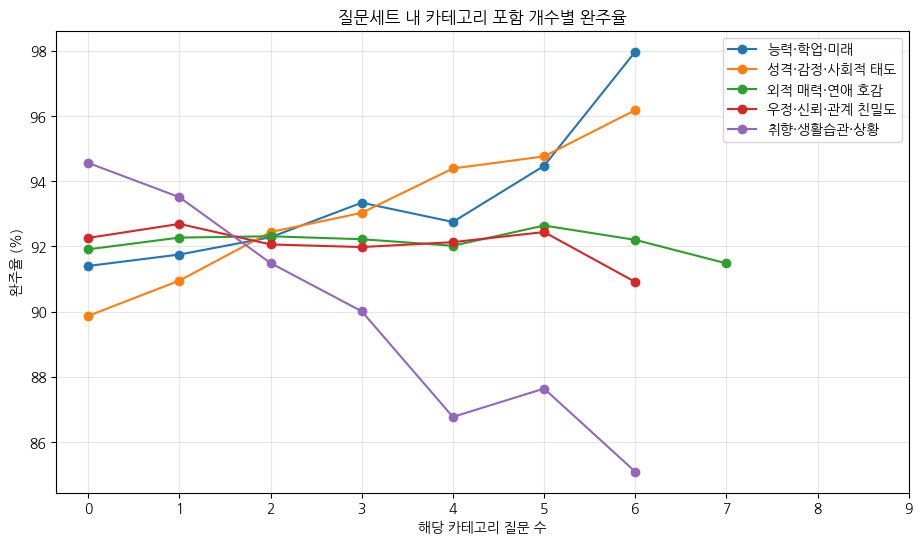

In [566]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

plot_data = category_result_all[
    category_result_all['set_count'] >= 100
]

plt.figure(figsize=(11, 6))

for category in category_cols:
    temp = plot_data[plot_data['category'] == category]

    plt.plot(
        temp['category_count'],
        temp['completion_rate'],
        marker='o',
        label=category
    )

plt.title('질문세트 내 카테고리 포함 개수별 완주율')
plt.xlabel('해당 카테고리 질문 수')
plt.ylabel('완주율 (%)')
plt.xticks(range(0, 10))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

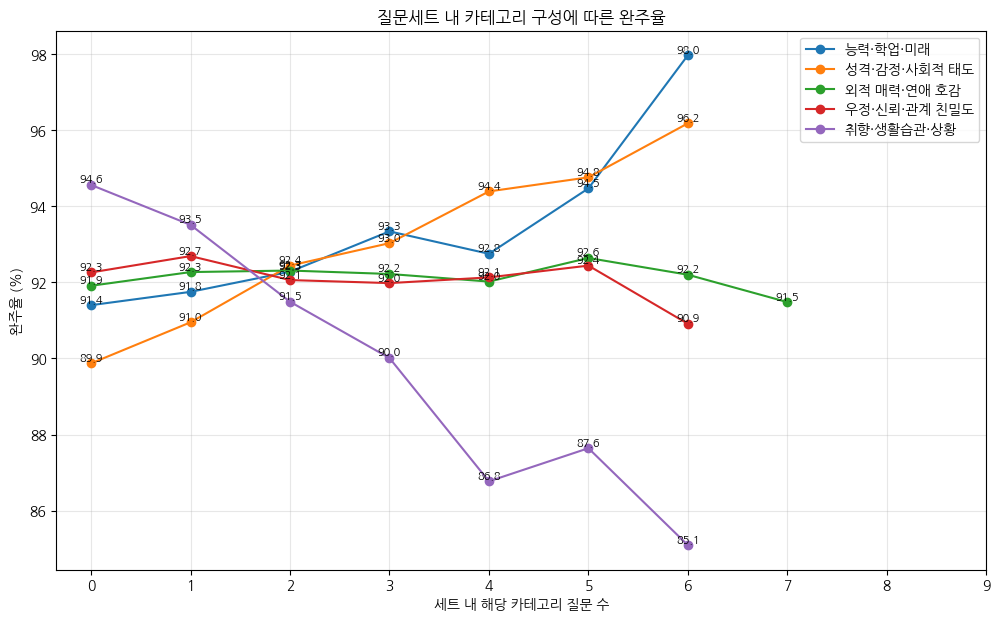

In [567]:
plt.figure(figsize=(12, 7))

for category in category_cols:
    temp = plot_data[plot_data['category'] == category]

    plt.plot(
        temp['category_count'],
        temp['completion_rate'],
        marker='o',
        label=category
    )

    for _, row in temp.iterrows():
        plt.text(
            row['category_count'],
            row['completion_rate'] + 0.08,
            f"{row['completion_rate']:.1f}",
            ha='center',
            fontsize=8
        )

plt.title('질문세트 내 카테고리 구성에 따른 완주율')
plt.xlabel('세트 내 해당 카테고리 질문 수')
plt.ylabel('완주율 (%)')
plt.xticks(range(0, 10))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## question id 관련 정합성 확인

In [568]:
# 앞에서 불러온 qset_raw, qpiece_raw은 재사용
# 질문 원본만 추가 로드
question_raw = pd.read_csv(raw_path / 'polls_question.csv')

In [569]:
qpiece_question_ids = set(qpiece_raw['question_id'])
question_ids = set(question_raw['id'])

pd.DataFrame({
    'qpiece의 고유 question_id': [len(qpiece_question_ids)],
    'question의 고유 id': [len(question_ids)],
    '공통 question_id': [len(qpiece_question_ids & question_ids)],
    'qpiece에만 존재': [len(qpiece_question_ids - question_ids)],
    'question에만 존재': [len(question_ids - qpiece_question_ids)]
})

,qpiece의 고유 question_id,question의 고유 id,공통 question_id,qpiece에만 존재,question에만 존재
0,4944,5025,4944,0,81


In [570]:
qset_piece_ids = set(raw_piece_ids)
qpiece_ids = set(qpiece_raw['id'])

pd.DataFrame({
    'qset 고유 piece_id': [len(qset_piece_ids)],
    'qpiece 고유 id': [len(qpiece_ids)],
    'qset→qpiece 매칭': [len(qset_piece_ids & qpiece_ids)],
    'qset에는 있는데 qpiece 없음': [len(qset_piece_ids - qpiece_ids)],
    'qpiece에는 있는데 qset 없음': [len(qpiece_ids - qset_piece_ids)]
})

,qset 고유 piece_id,qpiece 고유 id,qset→qpiece 매칭,qset에는 있는데 qpiece 없음,qpiece에는 있는데 qset 없음
0,1583840,1265476,1265476,318364,0


In [571]:
pd.DataFrame({
    'qset 내 piece 참조 수': [len(raw_piece_ids)],
    'qpiece 레코드 수': [len(qpiece_raw)],
    'qset→qpiece 매칭 수': [len(qset_piece_ids & qpiece_ids)],
    'qset 참조 중 qpiece 없음': [len(qset_piece_ids - qpiece_ids)],
    'qpiece 중 qset 참조 없음': [len(qpiece_ids - qset_piece_ids)]
})

,qset 내 piece 참조 수,qpiece 레코드 수,qset→qpiece 매칭 수,qset 참조 중 qpiece 없음,qpiece 중 qset 참조 없음
0,1583840,1265476,1265476,318364,0


In [572]:
raw_set_piece = pd.DataFrame({
    'question_piece_id': raw_piece_ids
})

raw_chain = (
    raw_set_piece
    .merge(
        qpiece_raw[['id', 'question_id']],
        left_on='question_piece_id',
        right_on='id',
        how='left'
    )
    .merge(
        question_raw[['id']],
        left_on='question_id',
        right_on='id',
        how='left',
        suffixes=('_piece', '_question')
    )
)

pd.DataFrame({
    '전체 qset piece 참조': [len(raw_chain)],
    'qpiece 매칭 성공': [raw_chain['question_id'].notna().sum()],
    'question까지 매칭 성공': [raw_chain['id_question'].notna().sum()],
    'qpiece 매칭률(%)': [
        round(raw_chain['question_id'].notna().mean() * 100, 2)
    ],
    'question 최종 매칭률(%)': [
        round(raw_chain['id_question'].notna().mean() * 100, 2)
    ]
})

,전체 qset piece 참조,qpiece 매칭 성공,question까지 매칭 성공,qpiece 매칭률(%),question 최종 매칭률(%)
0,1583840,1265476,1265476,79.9,79.9


## ③ 실제 하트/포인트 소비량 비교

In [573]:
# 앞에서 불러온 point 데이터 재사용
# 음수 포인트 사용 내역 확인
point.loc[point['delta_point'] < 0, 'delta_point'].value_counts().sort_index()

,count
delta_point,
-1000,1422
-500,6147
-300,40266
-200,20781
-30,1
-10,39966


In [574]:
policy_change = pd.Timestamp('2023-05-18 12:19:05')

point_open = point[
    (point['created_at'] >= policy_change) &
    (point['delta_point'].isin([-200, -500, -1000]))
].copy()

point_cat = (
    point_open
    .merge(
        uqr[['id', 'question_id', 'user_id']]
        .rename(columns={'id': 'uqr_id', 'user_id': 'uqr_user_id'}),
        left_on='user_question_record_id',
        right_on='uqr_id',
        how='inner'
    )
    .merge(
        questions[['id', 'category']].rename(columns={'id': 'question_id'}),
        on='question_id',
        how='inner'
    )
)

point_cat['spent_point'] = -point_cat['delta_point']

point_cat.head()

,id,delta_point,created_at,user_id,user_question_record_id,uqr_id,question_id,uqr_user_id,category,spent_point
0,145112480,-200,2023-05-18 12:19:05,1276125,68706929.0,68706929,1488,1236519,외적 매력·연애 호감,200
1,145120738,-200,2023-05-18 12:19:35,1276125,67406530.0,67406530,200,1305165,외적 매력·연애 호감,200
2,145174925,-200,2023-05-18 12:22:45,1278844,56006324.0,56006324,155,1205269,우정·신뢰·관계 친밀도,200
3,145181525,-200,2023-05-18 12:23:08,1366896,70939707.0,70939707,385,1331190,우정·신뢰·관계 친밀도,200
4,145203381,-500,2023-05-18 12:24:21,1228792,69029243.0,69029243,1062,1243220,외적 매력·연애 호감,500


In [575]:
category_spend = (
    point_cat.groupby('category')
    .agg(
        spend_count=('spent_point', 'count'),
        spend_users=('uqr_user_id', 'nunique'),
        total_spent=('spent_point', 'sum'),
        avg_spent=('spent_point', 'mean'),
        median_spent=('spent_point', 'median')
    )
    .reset_index()
    .sort_values('total_spent', ascending=False)
)

category_spend[['avg_spent', 'median_spent']] = (
    category_spend[['avg_spent', 'median_spent']].round(1)
)

category_spend

,category,spend_count,spend_users,total_spent,avg_spent,median_spent
2,외적 매력·연애 호감,10223,2164,3262000,319.1,200.0
3,우정·신뢰·관계 친밀도,8284,1994,2622100,316.5,200.0
1,성격·감정·사회적 태도,4137,1526,1171100,283.1,200.0
4,취향·생활습관·상황,2971,1209,822500,276.8,200.0
0,능력·학업·미래,2528,1174,710500,281.1,200.0


In [576]:
received = (
    uqr.merge(
        questions[['id', 'category']],
        left_on='question_id',
        right_on='id',
        how='inner'
    )
    .groupby('category')
    .agg(received_count=('id_x', 'count'))
    .reset_index()
)

category_spend = category_spend.merge(
    received,
    on='category',
    how='left'
)

category_spend['spend_rate'] = (
    category_spend['spend_count']
    / category_spend['received_count'] * 100
).round(2)

category_spend['point_per_received'] = (
    category_spend['total_spent']
    / category_spend['received_count']
).round(2)

category_spend[
    ['category', 'received_count', 'spend_count',
     'spend_rate', 'total_spent', 'point_per_received']
]

,category,received_count,spend_count,spend_rate,total_spent,point_per_received
0,외적 매력·연애 호감,293029,10223,3.49,3262000,11.13
1,우정·신뢰·관계 친밀도,244551,8284,3.39,2622100,10.72
2,성격·감정·사회적 태도,263483,4137,1.57,1171100,4.44
3,취향·생활습관·상황,190054,2971,1.56,822500,4.33
4,능력·학업·미래,213111,2528,1.19,710500,3.33


In [577]:
category_spend_kr = category_spend[
    ['category', 'received_count', 'spend_count',
     'spend_rate', 'total_spent', 'point_per_received']
].rename(columns={
    'category': '질문 카테고리',
    'received_count': '수신 질문 수',
    'spend_count': '포인트 소비 건수',
    'spend_rate': '포인트 소비율(%)',
    'total_spent': '총 소비 포인트',
    'point_per_received': '수신 1건당 평균 소비 포인트'
})

category_spend_kr

,질문 카테고리,수신 질문 수,포인트 소비 건수,포인트 소비율(%),총 소비 포인트,수신 1건당 평균 소비 포인트
0,외적 매력·연애 호감,293029,10223,3.49,3262000,11.13
1,우정·신뢰·관계 친밀도,244551,8284,3.39,2622100,10.72
2,성격·감정·사회적 태도,263483,4137,1.57,1171100,4.44
3,취향·생활습관·상황,190054,2971,1.56,822500,4.33
4,능력·학업·미래,213111,2528,1.19,710500,3.33


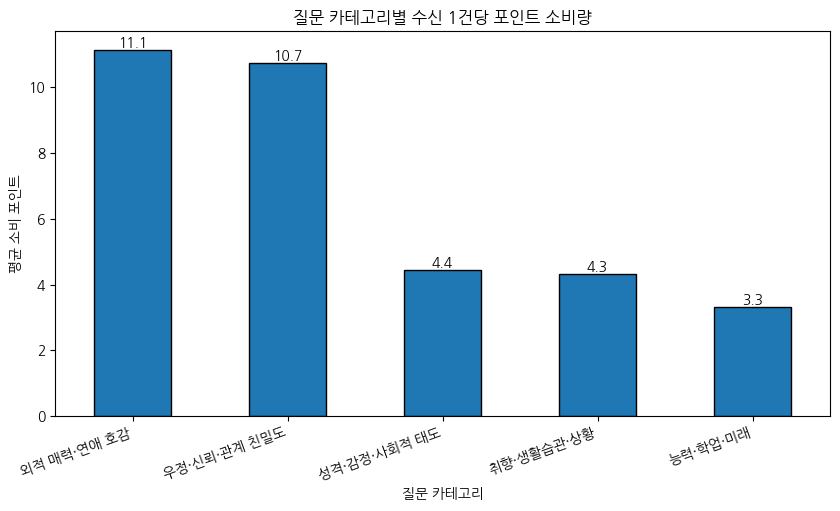

In [578]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

plot_df = category_spend.sort_values(
    'point_per_received',
    ascending=False
)

ax = plot_df.plot(
    x='category',
    y='point_per_received',
    kind='bar',
    figsize=(10, 5),
    edgecolor='black',
    legend=False
)

for i, v in enumerate(plot_df['point_per_received']):
    ax.text(i, v, f'{v:.1f}', ha='center', va='bottom')

plt.title('질문 카테고리별 수신 1건당 포인트 소비량')
plt.xlabel('질문 카테고리')
plt.ylabel('평균 소비 포인트')
plt.xticks(rotation=20, ha='right')
plt.show()

### 300포인트만 카테고리 매핑

In [579]:
# -300 포인트 소비만 추출
point_300 = point[point['delta_point'] == -300].copy()

point_300_cat = (
    point_300
    .merge(
        uqr[['id', 'question_id', 'user_id']]
        .rename(columns={'id': 'uqr_id', 'user_id': 'uqr_user_id'}),
        left_on='user_question_record_id',
        right_on='uqr_id',
        how='inner'
    )
    .merge(
        questions[['id', 'category']].rename(columns={'id': 'question_id'}),
        on='question_id',
        how='inner'
    )
)

point_300_cat.head()

,id,delta_point,created_at,user_id,user_question_record_id,uqr_id,question_id,uqr_user_id,category
0,812641,-300,2023-04-28 14:55:08,849670,782368.0,782368,209,849475,외적 매력·연애 호감
1,818045,-300,2023-04-28 15:34:02,849445,788522.0,788522,277,850007,성격·감정·사회적 태도
2,822730,-300,2023-04-28 16:08:49,849503,793399.0,793399,101,850031,능력·학업·미래
3,825616,-300,2023-04-28 16:39:11,850098,789980.0,789980,205,849475,성격·감정·사회적 태도
4,827691,-300,2023-04-28 17:04:02,850031,807996.0,807996,259,849620,외적 매력·연애 호감


In [580]:
start_300 = point_300['created_at'].min()
end_300 = point_300['created_at'].max()

uqr_300_period = uqr[
    uqr['created_at'].between(start_300, end_300)
]

received_300 = (
    uqr_300_period
    .merge(
        questions[['id', 'category']],
        left_on='question_id',
        right_on='id',
        how='inner'
    )
    .groupby('category')
    .size()
    .rename('received_count')
    .reset_index()
)

spend_300 = (
    point_300_cat.groupby('category')
    .agg(
        spend_count=('uqr_id', 'count'),
        spend_users=('uqr_user_id', 'nunique')
    )
    .reset_index()
    .merge(received_300, on='category', how='left')
)

spend_300['spend_rate'] = (
    spend_300['spend_count'] / spend_300['received_count'] * 100
).round(2)

spend_300['total_spent'] = spend_300['spend_count'] * 300

spend_300_kr = spend_300.rename(columns={
    'category': '질문 카테고리',
    'received_count': '수신 질문 수',
    'spend_count': '-300 소비 건수',
    'spend_users': '소비 유저 수',
    'spend_rate': '-300 소비율(%)',
    'total_spent': '총 소비 포인트'
}).sort_values('-300 소비율(%)', ascending=False)

spend_300_kr

,질문 카테고리,-300 소비 건수,소비 유저 수,수신 질문 수,-300 소비율(%),총 소비 포인트
2,외적 매력·연애 호감,12848,2778,177452,7.24,3854400
3,우정·신뢰·관계 친밀도,11051,2544,154545,7.15,3315300
1,성격·감정·사회적 태도,6355,2236,178186,3.57,1906500
4,취향·생활습관·상황,3014,1529,100399,3.00,904200
0,능력·학업·미래,3766,1739,139910,2.69,1129800


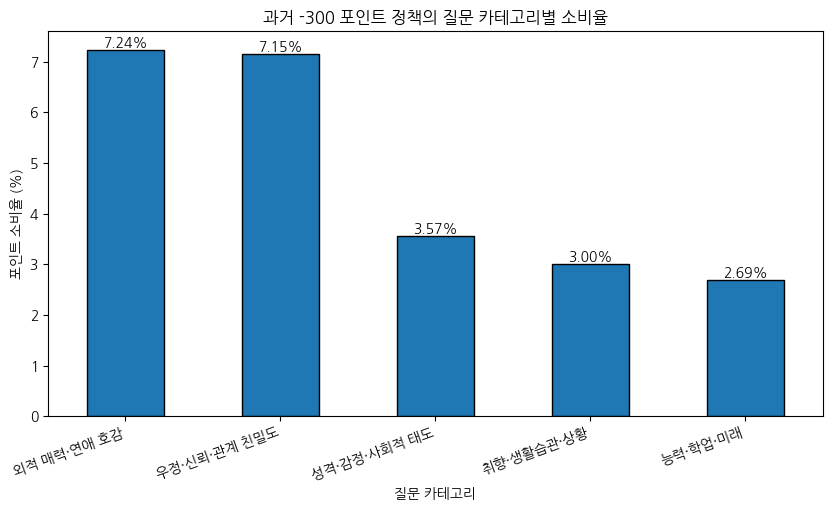

In [581]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

plot_df = spend_300_kr.sort_values('-300 소비율(%)', ascending=False)

ax = plot_df.plot(
    x='질문 카테고리',
    y='-300 소비율(%)',
    kind='bar',
    figsize=(10, 5),
    edgecolor='black',
    legend=False
)

for i, v in enumerate(plot_df['-300 소비율(%)']):
    ax.text(i, v, f'{v:.2f}%', ha='center', va='bottom')

plt.title('과거 -300 포인트 정책의 질문 카테고리별 소비율')
plt.xlabel('질문 카테고리')
plt.ylabel('포인트 소비율 (%)')
plt.xticks(rotation=20, ha='right')
plt.show()

## ④ 카테고리 내부 질문별 편차 확인

In [582]:
# ④-1. 질문별 수신·초성 개봉률 계산

# UQR → 질문 텍스트 + 카테고리
question_perf = (
    uqr.merge(
        questions[['id', 'question_text', 'category']],
        left_on='question_id',
        right_on='id',
        how='inner'
    )
)

question_perf['opened'] = (question_perf['opened_times'] > 0).astype(int)

question_result = (
    question_perf.groupby(['question_id', 'question_text', 'category'])
    .agg(
        received_count=('opened', 'count'),
        opened_count=('opened', 'sum'),
        open_rate=('opened', 'mean'),
        avg_opened_times=('opened_times', 'mean')
    )
    .reset_index()
)

question_result['open_rate'] = (question_result['open_rate'] * 100).round(2)
question_result['avg_opened_times'] = question_result['avg_opened_times'].round(2)

question_result.head()

,question_id,question_text,category,received_count,opened_count,open_rate,avg_opened_times
0,99,가장 신비한 매력이 있는 사람은?,외적 매력·연애 호감,1679,83,4.94,0.06
1,100,"""이 사람으로 한 번 살아보고 싶다"" 하는 사람은?",우정·신뢰·관계 친밀도,1681,103,6.13,0.08
2,101,미래의 틱톡커는?,능력·학업·미래,1812,31,1.71,0.02
3,102,여기서 제일 특이한 친구는?,취향·생활습관·상황,1936,83,4.29,0.05
4,103,가장 지켜주고 싶은 사람은?,외적 매력·연애 호감,1620,97,5.99,0.08


In [583]:
# ④-2. 표본 너무 작은 질문 제외

# 전체 초성 개봉률
p = question_perf['opened'].mean()

# 95% 신뢰수준, 허용오차 ±5%p
z = 1.96
e = 0.05

min_n = np.ceil(
    z**2 * p * (1 - p) / e**2
).astype(int)

p, min_n

(np.float64(0.04712313615029712), np.int64(69))

In [584]:
errors = [0.03, 0.05, 0.075, 0.10]

sample_기준 = pd.DataFrame({
    '허용오차(%p)': [e * 100 for e in errors],
    '최소 수신 건수': [
        int(np.ceil(z**2 * p * (1 - p) / e**2))
        for e in errors
    ]
})

sample_기준

,허용오차(%p),최소 수신 건수
0,3.0,192
1,5.0,69
2,7.5,31
3,10.0,18


In [585]:
question_result_valid = question_result[
    question_result['received_count'] >= min_n
].copy()

pd.DataFrame({
    '전체 질문 수': [len(question_result)],
    '분석 포함 질문 수': [len(question_result_valid)],
    '제외 질문 수': [len(question_result) - len(question_result_valid)],
    '최소 수신 기준': [min_n]
})

,전체 질문 수,분석 포함 질문 수,제외 질문 수,최소 수신 기준
0,3900,1515,2385,69


In [586]:
category_variation = (
    question_result_valid.groupby('category')
    .agg(
        question_count=('question_id', 'nunique'),
        avg_open_rate=('open_rate', 'mean'),
        median_open_rate=('open_rate', 'median'),
        min_open_rate=('open_rate', 'min'),
        max_open_rate=('open_rate', 'max'),
        std_open_rate=('open_rate', 'std')
    )
    .round(2)
    .reset_index()
)

category_variation_kr = category_variation.rename(columns={
    'category': '질문 카테고리',
    'question_count': '분석 질문 수',
    'avg_open_rate': '평균 개봉률(%)',
    'median_open_rate': '중앙값 개봉률(%)',
    'min_open_rate': '최소 개봉률(%)',
    'max_open_rate': '최대 개봉률(%)',
    'std_open_rate': '개봉률 표준편차'
})

category_variation_kr

,질문 카테고리,분석 질문 수,평균 개봉률(%),중앙값 개봉률(%),최소 개봉률(%),최대 개봉률(%),개봉률 표준편차
0,능력·학업·미래,237,2.84,2.65,0.50,11.07,1.30
1,성격·감정·사회적 태도,277,3.85,3.28,0.52,23.01,2.46
2,외적 매력·연애 호감,411,6.95,6.61,0.67,21.05,3.49
3,우정·신뢰·관계 친밀도,315,7.38,6.30,0.93,38.10,5.05
4,취향·생활습관·상황,275,2.90,2.54,0.53,10.18,1.52


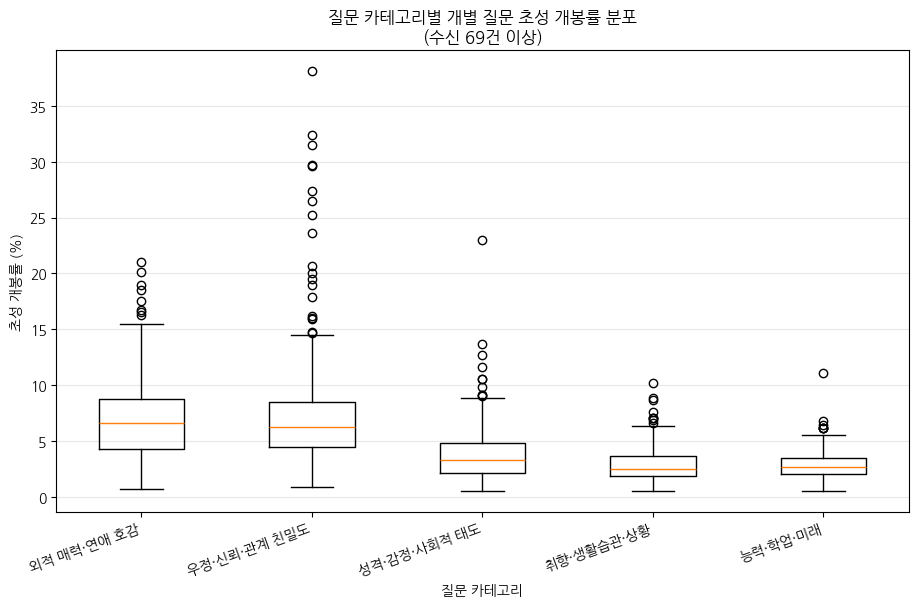

In [587]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

category_cols = [
    '외적 매력·연애 호감',
    '우정·신뢰·관계 친밀도',
    '성격·감정·사회적 태도',
    '취향·생활습관·상황',
    '능력·학업·미래'
]

plot_data = [
    question_result_valid.loc[
        question_result_valid['category'] == c,
        'open_rate'
    ]
    for c in category_cols
]

plt.figure(figsize=(11, 6))
plt.boxplot(plot_data, tick_labels=category_cols)

plt.title(f'질문 카테고리별 개별 질문 초성 개봉률 분포\n(수신 {min_n}건 이상)')
plt.xlabel('질문 카테고리')
plt.ylabel('초성 개봉률 (%)')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.show()

④-6. 성과 상위 개별 질문 확인

In [588]:
top_questions = (
    question_result_valid
    .sort_values(
        ['open_rate', 'received_count'],
        ascending=[False, False]
    )
    .head(20)
)

top_questions[
    ['question_text', 'category',
     'received_count', 'opened_count', 'open_rate']
]

,question_text,category,received_count,opened_count,open_rate
714,어떤 일로 멀어졌는데 다시 관계 회복하고 싶은 사람은?,우정·신뢰·관계 친밀도,147,56,38.10
1507,친해지고 싶었지만 타이밍을 놓쳐서 친해지지 못한 친구는?,우정·신뢰·관계 친밀도,281,91,32.38
891,나는 얘를 아는데 얘는 나를 모른다,우정·신뢰·관계 친밀도,232,73,31.47
715,어산데 친해지고 싶은 친구는?,우정·신뢰·관계 친밀도,269,80,29.74
1112,화해하고 싶은 친구는?,우정·신뢰·관계 친밀도,382,113,29.58
1504,안 친한데 연락해보고 싶은 사람,우정·신뢰·관계 친밀도,299,82,27.42
556,사과할 일 있는데 연락 못하고 있는 친구,우정·신뢰·관계 친밀도,132,35,26.52
1469,요즘따라 친해지고 싶은 친구는?,우정·신뢰·관계 친밀도,333,84,25.23
784,다가가고 싶지만 다가가기 어려운 친구는?,우정·신뢰·관계 친밀도,301,71,23.59
1396,다가가기 힘들었던 사람은?,성격·감정·사회적 태도,339,78,23.01


In [589]:
top5_by_category = (
    question_result_valid
    .sort_values(
        ['category', 'open_rate', 'received_count'],
        ascending=[True, False, False]
    )
    .groupby('category')
    .head(5)
)

top5_by_category[
    ['category', 'question_text',
     'received_count', 'open_rate']
]

,category,question_text,received_count,open_rate
1133,능력·학업·미래,노래부르면 목소리가 180도 달라지는 사람?,262,11.07
621,능력·학업·미래,"봉준호, BTS, 손흥민, ○○○ Let's go",309,6.80
1502,능력·학업·미래,노는것 같은데 은근 공부 잘하는 사람은?,327,6.42
1063,능력·학업·미래,길가다가 길거리 캐스팅 받아볼 것 같은 친구는?,323,6.19
252,능력·학업·미래,축구하는 모습이 멋진 사람은?,1327,6.18
1396,성격·감정·사회적 태도,다가가기 힘들었던 사람은?,339,23.01
492,성격·감정·사회적 태도,가장 마해자인 친구는?,752,13.70
596,성격·감정·사회적 태도,인기가 많은데 모를 것 같은 사람은?,362,12.71
773,성격·감정·사회적 태도,은근 친절한 사람은?,352,11.65
1101,성격·감정·사회적 태도,가장 놀리기 좋은 사람은?,332,10.54


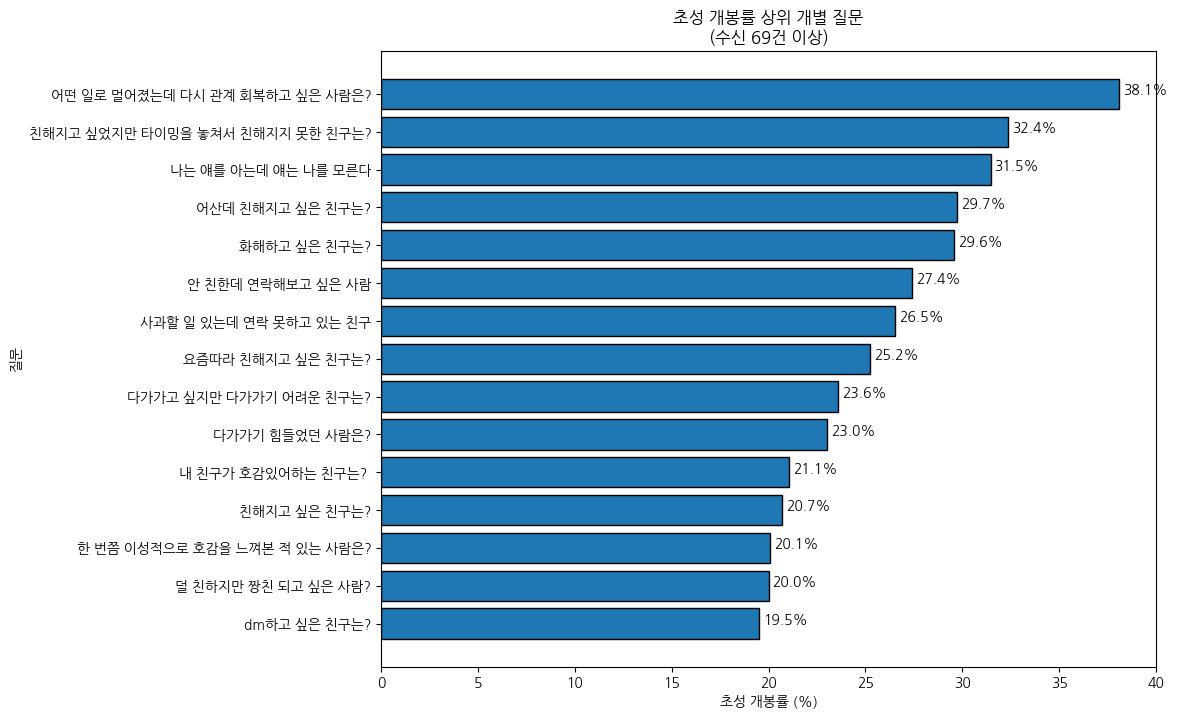

In [590]:
plot_df = (
    question_result_valid
    .sort_values(
        ['open_rate', 'received_count'],
        ascending=[False, False]
    )
    .head(15)
    .sort_values('open_rate')
)

plt.figure(figsize=(10, 8))

plt.barh(
    plot_df['question_text'],
    plot_df['open_rate'],
    edgecolor='black'
)

for i, v in enumerate(plot_df['open_rate']):
    plt.text(v + 0.2, i, f'{v:.1f}%')

plt.title(f'초성 개봉률 상위 개별 질문\n(수신 {min_n}건 이상)')
plt.xlabel('초성 개봉률 (%)')
plt.ylabel('질문')
plt.show()

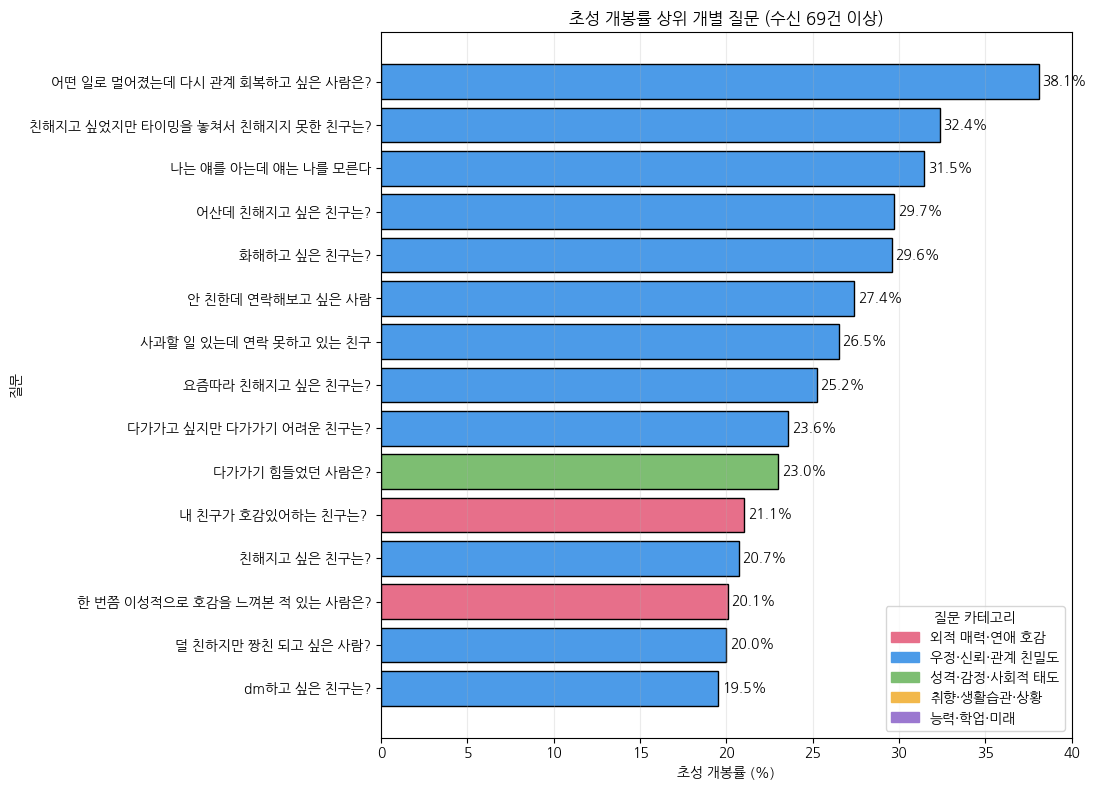

In [591]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

# 전체 TOP 15
plot_df = (
    question_result_valid
    .sort_values(
        ['open_rate', 'received_count'],
        ascending=[False, False]
    )
    .head(15)
    .sort_values('open_rate')
)

# 카테고리별 색상
category_colors = {
    '외적 매력·연애 호감': '#E76F8A',
    '우정·신뢰·관계 친밀도': '#4C9BE8',
    '성격·감정·사회적 태도': '#7DBE72',
    '취향·생활습관·상황': '#F2B84B',
    '능력·학업·미래': '#9B78D0'
}

colors = plot_df['category'].map(category_colors)

plt.figure(figsize=(11, 8))

bars = plt.barh(
    plot_df['question_text'],
    plot_df['open_rate'],
    color=colors,
    edgecolor='black'
)

for bar, v in zip(bars, plot_df['open_rate']):
    plt.text(
        v + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f'{v:.1f}%',
        va='center'
    )

# 범례
handles = [
    plt.Rectangle((0, 0), 1, 1, color=color, label=category)
    for category, color in category_colors.items()
]

plt.legend(
    handles=handles,
    title='질문 카테고리',
    loc='lower right'
)

plt.title(f'초성 개봉률 상위 개별 질문 (수신 {min_n}건 이상)')
plt.xlabel('초성 개봉률 (%)')
plt.ylabel('질문')
plt.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## ⑤ 유저마다 선호 카테고리가 다른지 확인

같은 유저 안에서도 카테고리별 개봉 반응이 달라지는지

In [592]:
# 유저 × 카테고리별 초성 개봉률
user_category = (
    uqr.merge(
        questions[['id', 'category']],
        left_on='question_id',
        right_on='id',
        how='inner'
    )
)

user_category['opened'] = (
    user_category['opened_times'] > 0
).astype(int)

user_category_result = (
    user_category.groupby(['chosen_user_id', 'category'])
    .agg(
        received_count=('opened', 'count'),
        opened_count=('opened', 'sum'),
        open_rate=('opened', 'mean')
    )
    .reset_index()
)

user_category_result['open_rate'] = (
    user_category_result['open_rate'] * 100
).round(2)

user_category_result.head()

,chosen_user_id,category,received_count,opened_count,open_rate
0,833112,성격·감정·사회적 태도,1,0,0.0
1,833112,취향·생활습관·상황,1,0,0.0
2,833113,능력·학업·미래,2,0,0.0
3,833113,성격·감정·사회적 태도,3,0,0.0
4,833113,외적 매력·연애 호감,3,0,0.0


In [593]:
# 유저들이 실제 몇 개 카테고리를 받아봤는지 확인

user_coverage = (
    user_category_result.groupby('chosen_user_id')
    .agg(
        category_count=('category', 'nunique'),
        total_received=('received_count', 'sum'),
        total_opened=('opened_count', 'sum')
    )
    .reset_index()
)

user_coverage['category_count'].value_counts().sort_index()

,count
category_count,
1,2273
2,1655
3,1490
4,1644
5,8340


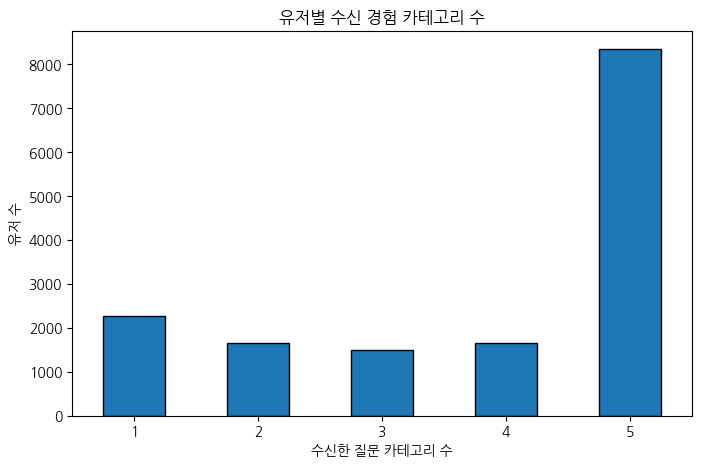

In [594]:
ax = (
    user_coverage['category_count']
    .value_counts()
    .sort_index()
    .plot(
        kind='bar',
        figsize=(8, 5),
        edgecolor='black'
    )
)

plt.title('유저별 수신 경험 카테고리 수')
plt.xlabel('수신한 질문 카테고리 수')
plt.ylabel('유저 수')
plt.xticks(rotation=0)
plt.show()

In [595]:
# 유저별 카테고리 개봉률 편차 계산

valid_users = user_coverage.loc[
    user_coverage['category_count'] >= 2,
    'chosen_user_id'
]

user_pref = user_category_result[
    user_category_result['chosen_user_id'].isin(valid_users)
].copy()

user_spread = (
    user_pref.groupby('chosen_user_id')
    .agg(
        category_count=('category', 'nunique'),
        max_open_rate=('open_rate', 'max'),
        min_open_rate=('open_rate', 'min'),
        std_open_rate=('open_rate', 'std')
    )
    .reset_index()
)

user_spread['rate_gap'] = (
    user_spread['max_open_rate']
    - user_spread['min_open_rate']
).round(2)

user_spread.describe().round(2)

,chosen_user_id,category_count,max_open_rate,min_open_rate,std_open_rate,rate_gap
count,13129.00,13129.00,13129.00,13129.00,13129.00,13129.00
mean,1072017.74,4.27,13.46,0.86,6.11,12.60
std,218841.17,1.09,23.27,5.96,11.96,22.31
min,833112.00,2.00,0.00,0.00,0.00,0.00
25%,880029.00,4.00,0.00,0.00,0.00,0.00
50%,979523.00,5.00,3.85,0.00,1.49,3.43
75%,1235198.00,5.00,16.00,0.00,6.25,14.29
max,1579422.00,5.00,100.00,100.00,70.71,100.00


In [596]:
# 유저별 가장 반응이 높았던 카테고리

favorite_category = (
    user_pref
    .sort_values(
        ['chosen_user_id', 'open_rate', 'received_count'],
        ascending=[True, False, False]
    )
    .drop_duplicates('chosen_user_id')
)

favorite_summary = (
    favorite_category['category']
    .value_counts()
    .rename_axis('선호 카테고리')
    .reset_index(name='유저 수')
)

favorite_summary['비율(%)'] = (
    favorite_summary['유저 수']
    / favorite_summary['유저 수'].sum() * 100
).round(2)

favorite_summary

,선호 카테고리,유저 수,비율(%)
0,외적 매력·연애 호감,3926,29.90
1,우정·신뢰·관계 친밀도,3583,27.29
2,성격·감정·사회적 태도,2447,18.64
3,능력·학업·미래,2167,16.51
4,취향·생활습관·상황,1006,7.66


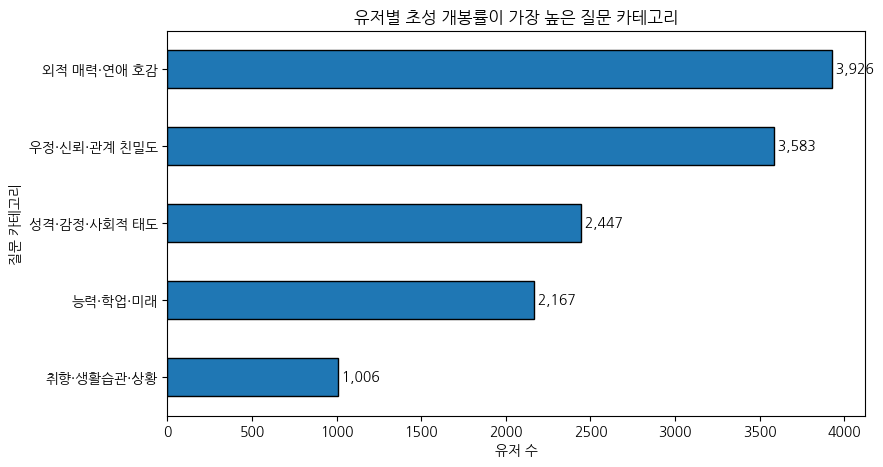

In [597]:
plot_df = favorite_summary.sort_values('유저 수')

ax = plot_df.plot(
    x='선호 카테고리',
    y='유저 수',
    kind='barh',
    figsize=(9, 5),
    edgecolor='black',
    legend=False
)

for i, v in enumerate(plot_df['유저 수']):
    ax.text(v, i, f' {v:,}', va='center')

plt.title('유저별 초성 개봉률이 가장 높은 질문 카테고리')
plt.xlabel('유저 수')
plt.ylabel('질문 카테고리')
plt.show()

In [598]:
# 유저×카테고리별 수신 건수 분포 확인
user_category_result['received_count'].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
)

,received_count
count,58329.000000
mean,20.645442
std,29.697463
min,1.000000
25%,2.000000
50%,7.000000
75%,28.000000
90%,60.000000
95%,83.000000
max,325.000000


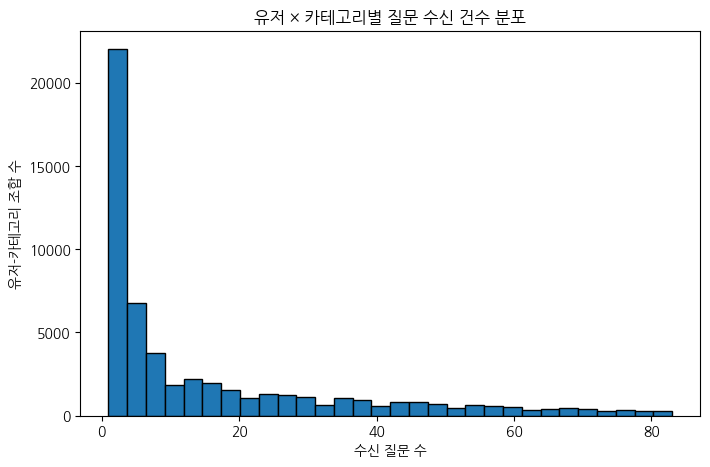

In [599]:
import matplotlib.pyplot as plt

# 극단적으로 수신이 많은 값 때문에 그래프가 찌그러지는 것을 방지해 95%까지만 표시
limit = user_category_result['received_count'].quantile(0.95)

plt.figure(figsize=(8, 5))

plt.hist(
    user_category_result.loc[
        user_category_result['received_count'] <= limit,
        'received_count'
    ],
    bins=30,
    edgecolor='black'
)

plt.title('유저 × 카테고리별 질문 수신 건수 분포')
plt.xlabel('수신 질문 수')
plt.ylabel('유저-카테고리 조합 수')
plt.show()

### ⑤-1. 유저 × 카테고리별 수신·개봉률

In [600]:
# 질문을 실제로 받은 유저(chosen_user_id) 기준
user_category = (
    uqr.dropna(subset=['chosen_user_id'])
    .merge(
        questions[['id', 'category']],
        left_on='question_id',
        right_on='id',
        how='inner'
    )
)

# 초성을 한 번이라도 열었으면 1
user_category['opened'] = (user_category['opened_times'] > 0).astype(int)

# 유저 × 카테고리별 수신/개봉 집계
user_category_result = (
    user_category.groupby(['chosen_user_id', 'category'])
    .agg(
        received_count=('opened', 'count'),
        opened_count=('opened', 'sum'),
        open_rate=('opened', 'mean')
    )
    .reset_index()
)

user_category_result['open_rate'] = (
    user_category_result['open_rate'] * 100
).round(2)

user_category_result.head()

,chosen_user_id,category,received_count,opened_count,open_rate
0,833112,성격·감정·사회적 태도,1,0,0.0
1,833112,취향·생활습관·상황,1,0,0.0
2,833113,능력·학업·미래,2,0,0.0
3,833113,성격·감정·사회적 태도,3,0,0.0
4,833113,외적 매력·연애 호감,3,0,0.0


### ⑤-2. 유저가 몇 개 카테고리를 경험했는지

In [601]:
# 유저별 카테고리 경험 수와 전체 수신/개봉 수
user_coverage = (
    user_category_result.groupby('chosen_user_id')
    .agg(
        category_count=('category', 'nunique'),
        total_received=('received_count', 'sum'),
        total_opened=('opened_count', 'sum')
    )
    .reset_index()
)

coverage_result = (
    user_coverage['category_count']
    .value_counts()
    .sort_index()
    .rename_axis('경험 카테고리 수')
    .reset_index(name='유저 수')
)

coverage_result

,경험 카테고리 수,유저 수
0,1,2273
1,2,1655
2,3,1490
3,4,1644
4,5,8340


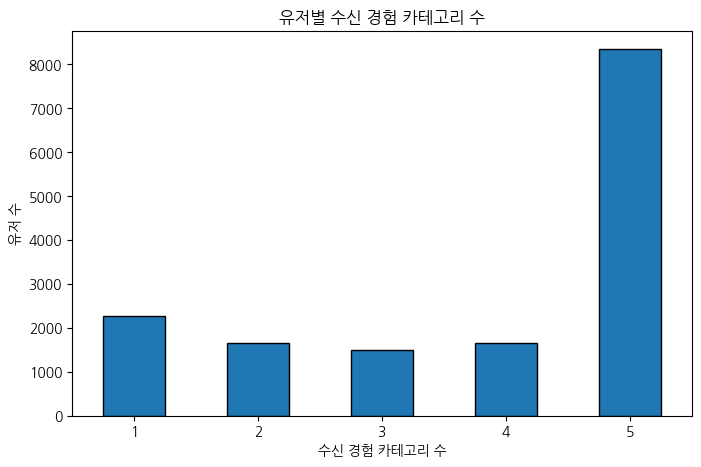

In [602]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

ax = coverage_result.plot(
    x='경험 카테고리 수',
    y='유저 수',
    kind='bar',
    figsize=(8, 5),
    edgecolor='black',
    legend=False
)

plt.title('유저별 수신 경험 카테고리 수')
plt.xlabel('수신 경험 카테고리 수')
plt.ylabel('유저 수')
plt.xticks(rotation=0)
plt.show()

최소 3개 이상 카테고리를 경험한 유저만 비교

### ⑤-3. 수신 건수 차이를 보정한 카테고리 반응 점수

In [603]:
# 전체 유저 기준 카테고리별 기본 개봉률
category_base = (
    user_category.groupby('category')
    .agg(
        total_received=('opened', 'count'),
        total_opened=('opened', 'sum')
    )
    .reset_index()
)

category_base['base_rate'] = (
    category_base['total_opened']
    / category_base['total_received']
)

# 유저×카테고리 수신 건수 중앙값을 보정 강도로 사용
prior_strength = int(
    user_category_result['received_count'].median()
)

# 카테고리 평균값 연결
user_pref_score = user_category_result.merge(
    category_base[['category', 'base_rate']],
    on='category',
    how='left'
)

# 표본이 적을수록 카테고리 평균에 가깝게 보정
user_pref_score['adjusted_rate'] = (
    user_pref_score['opened_count']
    + prior_strength * user_pref_score['base_rate']
) / (
    user_pref_score['received_count']
    + prior_strength
)

# 카테고리 평균보다 얼마나 더 반응했는지
user_pref_score['preference_lift'] = (
    (user_pref_score['adjusted_rate']
     - user_pref_score['base_rate']) * 100
).round(2)

user_pref_score.head()

,chosen_user_id,category,received_count,opened_count,open_rate,base_rate,adjusted_rate,preference_lift
0,833112,성격·감정·사회적 태도,1,0,0.0,0.036572,0.032000,-0.46
1,833112,취향·생활습관·상황,1,0,0.0,0.029539,0.025847,-0.37
2,833113,능력·학업·미래,2,0,0.0,0.027971,0.021755,-0.62
3,833113,성격·감정·사회적 태도,3,0,0.0,0.036572,0.025600,-1.10
4,833113,외적 매력·연애 호감,3,0,0.0,0.065352,0.045746,-1.96


### ⑤-4. 한 유저 안에서 카테고리 반응 차이가 얼마나 나는지

In [604]:
# 최소 3개 카테고리를 경험했고,
# 실제 초성 개봉 경험이 있는 유저만 비교
valid_users = user_coverage.loc[
    (user_coverage['category_count'] >= 3) &
    (user_coverage['total_opened'] > 0),
    'chosen_user_id'
]

user_pref_valid = user_pref_score[
    user_pref_score['chosen_user_id'].isin(valid_users)
].copy()

# 유저 내부 카테고리 반응 편차
user_spread = (
    user_pref_valid.groupby('chosen_user_id')
    .agg(
        category_count=('category', 'nunique'),
        max_lift=('preference_lift', 'max'),
        min_lift=('preference_lift', 'min'),
        std_lift=('preference_lift', 'std')
    )
    .reset_index()
)

# 가장 선호/비선호 카테고리 간 차이
user_spread['lift_gap'] = (
    user_spread['max_lift']
    - user_spread['min_lift']
).round(2)

user_spread[
    ['category_count', 'max_lift',
     'min_lift', 'std_lift', 'lift_gap']
].describe().round(2)

,category_count,max_lift,min_lift,std_lift,lift_gap
count,6830.00,6830.00,6830.00,6830.00,6830.00
mean,4.84,6.99,-2.43,4.01,9.43
std,0.47,6.98,2.52,2.51,5.73
min,3.00,-2.74,-6.39,0.20,0.38
25%,5.00,1.81,-3.94,2.09,5.23
50%,5.00,5.75,-2.54,3.44,8.32
75%,5.00,10.45,-1.48,5.42,12.26
max,5.00,58.88,33.99,19.87,47.10


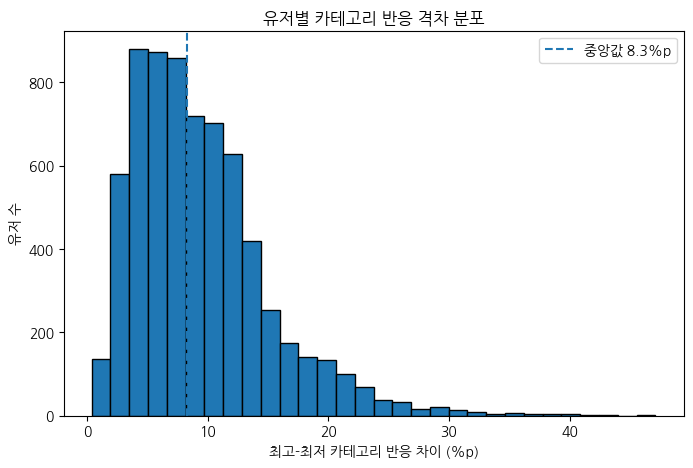

In [605]:
plt.figure(figsize=(8, 5))

plt.hist(
    user_spread['lift_gap'],
    bins=30,
    edgecolor='black'
)

plt.axvline(
    user_spread['lift_gap'].median(),
    linestyle='--',
    label=f"중앙값 {user_spread['lift_gap'].median():.1f}%p"
)

plt.title('유저별 카테고리 반응 격차 분포')
plt.xlabel('최고-최저 카테고리 반응 차이 (%p)')
plt.ylabel('유저 수')
plt.legend()
plt.show()

### ⑤-5. 유저별 상대적으로 가장 선호한 카테고리

In [606]:
# 유저별 상대 반응이 가장 높은 카테고리 선정
favorite_category = (
    user_pref_valid
    .sort_values(
        ['chosen_user_id', 'preference_lift', 'received_count'],
        ascending=[True, False, False]
    )
    .drop_duplicates('chosen_user_id')
)

# 카테고리 평균보다 실제로 높은 반응을 보인 경우만 사용
favorite_category = favorite_category[
    favorite_category['preference_lift'] > 0
].copy()

# 선호 카테고리 분포
favorite_summary = (
    favorite_category['category']
    .value_counts()
    .rename_axis('선호 카테고리')
    .reset_index(name='유저 수')
)

favorite_summary['비율(%)'] = (
    favorite_summary['유저 수']
    / favorite_summary['유저 수'].sum() * 100
).round(2)

favorite_summary

,선호 카테고리,유저 수,비율(%)
0,우정·신뢰·관계 친밀도,1719,29.18
1,외적 매력·연애 호감,1587,26.93
2,성격·감정·사회적 태도,990,16.80
3,능력·학업·미래,857,14.55
4,취향·생활습관·상황,739,12.54


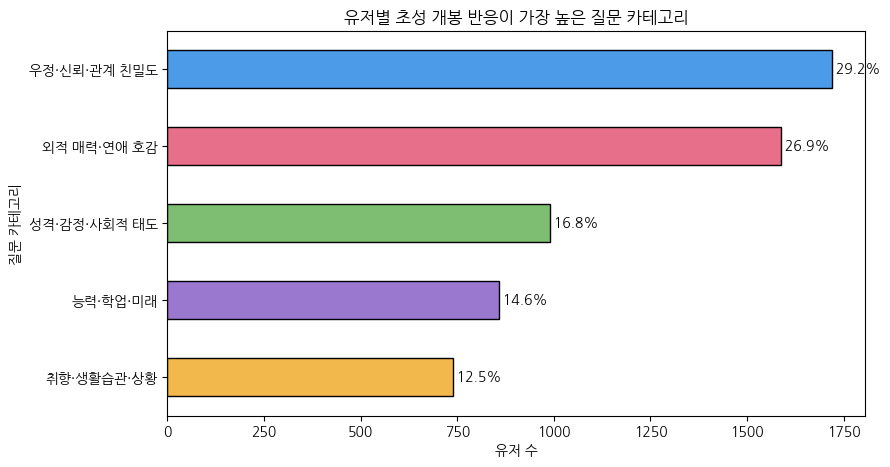

In [607]:
category_colors = {
    '외적 매력·연애 호감': '#E76F8A',
    '우정·신뢰·관계 친밀도': '#4C9BE8',
    '성격·감정·사회적 태도': '#7DBE72',
    '취향·생활습관·상황': '#F2B84B',
    '능력·학업·미래': '#9B78D0'
}

plot_df = favorite_summary.sort_values('유저 수')

colors = plot_df['선호 카테고리'].map(category_colors)

ax = plot_df.plot(
    x='선호 카테고리',
    y='유저 수',
    kind='barh',
    figsize=(9, 5),
    color=colors,
    edgecolor='black',
    legend=False
)

for i, row in plot_df.reset_index(drop=True).iterrows():
    ax.text(
        row['유저 수'],
        i,
        f" {row['비율(%)']:.1f}%",
        va='center'
    )

plt.title('유저별 초성 개봉 반응이 가장 높은 질문 카테고리')
plt.xlabel('유저 수')
plt.ylabel('질문 카테고리')
plt.show()

=> 유저별 카테고리 초성 개봉 반응 차이

카테고리별 반응률은:

해당 유저가 그 카테고리에서 초성을 연 질문 수 ÷ 그 카테고리 질문을 받은 수

‘우정·신뢰·관계 친밀도’가 다른 카테고리보다 상대적으로 가장 높은 반응을 보인 카테고리였던 유저의 비율

In [608]:
# 카테고리별 실제 초성 개봉률
category_open_rate = (
    question_perf.groupby('category')
    .agg(
        수신건수=('opened', 'count'),
        개봉건수=('opened', 'sum')
    )
    .reset_index()
)

category_open_rate['초성 개봉률(%)'] = (
    category_open_rate['개봉건수']
    / category_open_rate['수신건수'] * 100
).round(2)

category_open_rate

,category,수신건수,개봉건수,초성 개봉률(%)
0,능력·학업·미래,213111,5961,2.80
1,성격·감정·사회적 태도,263483,9636,3.66
2,외적 매력·연애 호감,293029,19150,6.54
3,우정·신뢰·관계 친밀도,244551,16386,6.70
4,취향·생활습관·상황,190054,5614,2.95


## 대화방 생성 찾기

In [609]:
# -200 포인트 사용만 추출
point_200 = point[
    point['delta_point'] == -200
].copy()

# UQR과 연결해서 초성 개봉 여부 확인
point_200_check = (
    point_200.merge(
        uqr[
            ['id', 'chosen_user_id', 'question_id',
             'opened_times', 'status']
        ],
        left_on='user_question_record_id',
        right_on='id',
        how='inner',
        suffixes=('_point', '_uqr')
    )
)

# 초성을 한 번도 열지 않았는데 -200을 사용했다면
# 채팅방 생성일 가능성이 높은 케이스
point_200_check['type_check'] = np.where(
    point_200_check['opened_times'] == 0,
    '초성 미개봉 - 채팅 가능성',
    '초성 개봉 있음 - 구분 불가'
)

point_200_check['type_check'].value_counts()

,count
type_check,
초성 개봉 있음 - 구분 불가,20781


In [610]:
(
    point_200_check['type_check']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

,proportion
type_check,
초성 개봉 있음 - 구분 불가,100.0


In [611]:
# -200 사용 + 초성 미개봉 → 채팅방 생성 후보
chat_candidate = point_200_check[
    point_200_check['opened_times'] == 0
].copy()

chat_candidate.shape

(0, 11)

In [612]:
# 전체 -200 포인트 사용 기록
point_200 = point[
    point['delta_point'] == -200
].copy()

# UQR 연결 여부 확인
pd.DataFrame({
    '전체 -200 건수': [len(point_200)],
    'UQR id 있음': [point_200['user_question_record_id'].notna().sum()],
    'UQR id 없음': [point_200['user_question_record_id'].isna().sum()]
})

,전체 -200 건수,UQR id 있음,UQR id 없음
0,20781,20781,0


In [613]:
# -200 포인트 기록에 UQR의 두 유저 id 연결
point_200_user = (
    point_200.merge(
        uqr[
            ['id', 'user_id', 'chosen_user_id',
             'question_id', 'opened_times']
        ].rename(columns={
            'id': 'uqr_id',
            'user_id': 'vote_user_id'
        }),
        left_on='user_question_record_id',
        right_on='uqr_id',
        how='inner'
    )
)

# 실제 포인트를 쓴 사람이 누구와 일치하는지 확인
point_200_user['spender_type'] = np.select(
    [
        point_200_user['user_id'] == point_200_user['chosen_user_id'],
        point_200_user['user_id'] == point_200_user['vote_user_id']
    ],
    [
        '선택받은 유저',
        '투표한 유저'
    ],
    default='둘 다 아님'
)

point_200_user['spender_type'].value_counts()

,count
spender_type,
선택받은 유저,20781


In [614]:
# UQR 하나당 -200 소비 횟수 계산
point_200_count = (
    point_200_user.groupby('uqr_id')
    .agg(
        minus_200_count=('id', 'count'),
        opened_times=('opened_times', 'first')
    )
    .reset_index()
)

point_200_count.head()

,uqr_id,minus_200_count,opened_times
0,795467,1,2
1,795793,1,1
2,805748,1,1
3,826065,1,1
4,839788,1,1


In [615]:
# 초성 개봉 횟수와 -200 소비 횟수 교차 확인
pd.crosstab(
    point_200_count['opened_times'],
    point_200_count['minus_200_count']
)

minus_200_count,1
opened_times,
1,14968
2,4572
3,1241


In [616]:
# UQR별 -200 발생 횟수
point_200_count = (
    point_200_user.groupby('uqr_id')
    .agg(
        minus_200_count=('uqr_id', 'size'),
        opened_times=('opened_times', 'first')
    )
    .reset_index()
)

pd.crosstab(
    point_200_count['opened_times'],
    point_200_count['minus_200_count']
)

minus_200_count,1
opened_times,
1,14968
2,4572
3,1241


In [617]:
# -200이 2번 이상 발생한 UQR이 있는지 확인
point_200_count[
    point_200_count['minus_200_count'] >= 2
]

,uqr_id,minus_200_count,opened_times


## -10 포인트 차감 기록에 대해

In [618]:
# -10 포인트 차감만 추출
point_10 = point[
    point['delta_point'] == -10
].copy()

pd.DataFrame({
    '전체 -10 건수': [len(point_10)],
    '고유 사용 유저 수': [point_10['user_id'].nunique()],
    '연결된 UQR 수': [point_10['user_question_record_id'].nunique()]
})

,전체 -10 건수,고유 사용 유저 수,연결된 UQR 수
0,39966,2012,39963


In [619]:
# -10 기록 → UQR 연결
reply_check = (
    point_10.merge(
        uqr[
            ['id', 'user_id', 'chosen_user_id',
             'question_id', 'answer_status', 'answer_updated_at']
        ].rename(columns={
            'id': 'uqr_id',
            'user_id': 'vote_user_id'
        }),
        left_on='user_question_record_id',
        right_on='uqr_id',
        how='inner'
    )
)

# 실제 포인트 사용자가 누구인지 확인
reply_check['spender_type'] = np.select(
    [
        reply_check['user_id'] == reply_check['chosen_user_id'],
        reply_check['user_id'] == reply_check['vote_user_id']
    ],
    [
        '수신자(선택받은 유저)',
        '투표한 유저'
    ],
    default='둘 다 아님'
)

reply_check['spender_type'].value_counts()

,count
spender_type,
수신자(선택받은 유저),39966


In [620]:
# answer_status와 -10의 관계 확인

# -10 소비 기록의 답장 상태 확인
reply_check['answer_status'].value_counts(dropna=False)

,count
answer_status,
A,36917
P,2975
N,74


In [621]:
(
    reply_check['answer_status']
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

,proportion
answer_status,
A,92.37
P,7.44
N,0.19


-10 포인트 차감 = 실제 답장 행동으로 충분히 해석 가능

In [622]:
# 같은 투표에 -10이 여러 번 발생했는지 확인
reply_count = (
    point_10.groupby('user_question_record_id')
    .size()
    .value_counts()
    .sort_index()
)

reply_count

,count
1,39960
2,3


### N + 중복 2회 제거해서 답장 데이터 생성

In [623]:
# -10 포인트 기록 → UQR 연결
reply_check = (
    point_10.merge(
        uqr[
            ['id', 'user_id', 'chosen_user_id',
             'question_id', 'answer_status',
             'answer_updated_at', 'opened_times']
        ].rename(columns={
            'id': 'uqr_id',
            'user_id': 'vote_user_id'
        }),
        left_on='user_question_record_id',
        right_on='uqr_id',
        how='inner'
    )
)

reply_check.head()

,id,delta_point,created_at,user_id,user_question_record_id,uqr_id,vote_user_id,chosen_user_id,question_id,answer_status,answer_updated_at,opened_times
0,145109550,-10,2023-05-18 12:18:54,1165963,71640033.0,71640033,873211,1165963,1541,A,2023-05-18 12:18:54,1
1,145176409,-10,2023-05-18 12:22:50,1193946,61268136.0,61268136,1259519,1193946,1216,A,2023-05-18 12:22:50,0
2,145187521,-10,2023-05-18 12:23:28,1018202,71656480.0,71656480,1040190,1018202,802,A,2023-05-18 12:23:28,0
3,145189945,-10,2023-05-18 12:23:36,1193946,61892208.0,61892208,1259519,1193946,1386,A,2023-05-18 12:23:36,0
4,145191284,-10,2023-05-18 12:23:40,1126012,71663505.0,71663505,1306868,1126012,1601,A,2023-05-18 12:23:40,2


In [624]:
# UQR별 -10 차감 횟수 계산
reply_counts = (
    point_10.groupby('user_question_record_id')
    .size()
    .rename('reply_point_count')
    .reset_index()
)

# -10이 정확히 1회 발생한 UQR만 유지
valid_reply_ids = reply_counts.loc[
    reply_counts['reply_point_count'] == 1,
    'user_question_record_id'
]

# 실제 답장 상태(A/P)만 유지
valid_reply = reply_check[
    (reply_check['uqr_id'].isin(valid_reply_ids)) &
    (reply_check['answer_status'].isin(['A', 'P']))
].copy()

valid_reply.shape

(39888, 12)

### 초성을 안 열고도 답장을 했는지 확인

In [625]:
# 실제 답장 유저의 초성 개봉 횟수 분포
reply_open_result = (
    valid_reply['opened_times']
    .value_counts()
    .sort_index()
    .rename_axis('초성 개봉 횟수')
    .reset_index(name='답장 건수')
)

reply_open_result['비율(%)'] = (
    reply_open_result['답장 건수']
    / reply_open_result['답장 건수'].sum() * 100
).round(2)

reply_open_result

,초성 개봉 횟수,답장 건수,비율(%)
0,0,35688,89.47
1,1,2900,7.27
2,2,1035,2.59
3,3,265,0.66


In [626]:
# 초성을 한 번도 열지 않고 답장한 경우
no_open_reply = (valid_reply['opened_times'] == 0).sum()

pd.DataFrame({
    '전체 답장 건수': [len(valid_reply)],
    '초성 미개봉 답장 건수': [no_open_reply],
    '초성 미개봉 답장 비율(%)': [
        round(no_open_reply / len(valid_reply) * 100, 2)
    ]
})

,전체 답장 건수,초성 미개봉 답장 건수,초성 미개봉 답장 비율(%)
0,39888,35688,89.47


In [627]:
# 답장한 유저의 초성 개봉 횟수 분포
reply_open_result = (
    valid_reply['opened_times']
    .value_counts()
    .sort_index()
    .rename_axis('초성 개봉 횟수')
    .reset_index(name='답장 건수')
)

# 비율 계산
reply_open_result['비율(%)'] = (
    reply_open_result['답장 건수']
    / reply_open_result['답장 건수'].sum() * 100
).round(2)

reply_open_result

,초성 개봉 횟수,답장 건수,비율(%)
0,0,35688,89.47
1,1,2900,7.27
2,2,1035,2.59
3,3,265,0.66


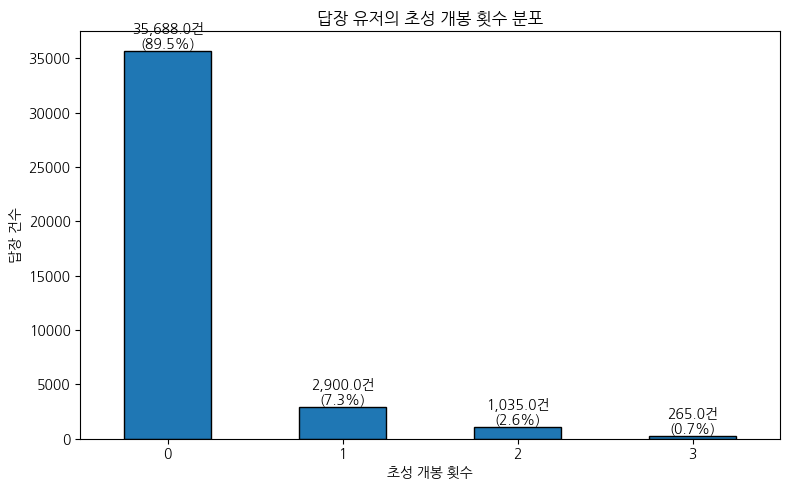

In [628]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

ax = reply_open_result.plot(
    x='초성 개봉 횟수',
    y='답장 건수',
    kind='bar',
    figsize=(8, 5),
    edgecolor='black',
    legend=False
)

# 막대 위에 건수와 비율 표시
for i, row in reply_open_result.reset_index(drop=True).iterrows():
    ax.text(
        i,
        row['답장 건수'],
        f"{row['답장 건수']:,}건\n({row['비율(%)']:.1f}%)",
        ha='center',
        va='bottom'
    )

plt.title('답장 유저의 초성 개봉 횟수 분포')
plt.xlabel('초성 개봉 횟수')
plt.ylabel('답장 건수')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [629]:
# 초성 개봉 여부 기준으로 재분류
valid_reply['초성 개봉 여부'] = np.where(
    valid_reply['opened_times'] == 0,
    '초성 미개봉',
    '초성 개봉'
)

reply_open_binary = (
    valid_reply['초성 개봉 여부']
    .value_counts()
    .rename_axis('구분')
    .reset_index(name='답장 건수')
)

reply_open_binary['비율(%)'] = (
    reply_open_binary['답장 건수']
    / reply_open_binary['답장 건수'].sum() * 100
).round(2)

reply_open_binary

,구분,답장 건수,비율(%)
0,초성 미개봉,35688,89.47
1,초성 개봉,4200,10.53


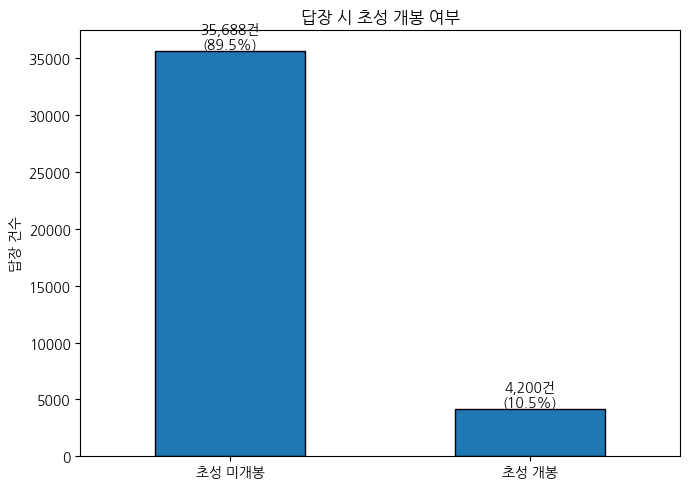

In [630]:
ax = reply_open_binary.plot(
    x='구분',
    y='답장 건수',
    kind='bar',
    figsize=(7, 5),
    edgecolor='black',
    legend=False
)

for i, row in reply_open_binary.reset_index(drop=True).iterrows():
    ax.text(
        i,
        row['답장 건수'],
        f"{row['답장 건수']:,}건\n({row['비율(%)']:.1f}%)",
        ha='center',
        va='bottom'
    )

plt.title('답장 시 초성 개봉 여부')
plt.xlabel('')
plt.ylabel('답장 건수')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 카테고리별 결제 건수

In [631]:
# 결제 기록
payment = pd.read_csv(
    raw_path / 'accounts_paymenthistory.csv',
    parse_dates=['created_at']
)

payment.shape

(95140, 5)

In [632]:
# 질문 관련 포인트 소비만 추출
spend = point[
    point['delta_point'].isin([-10, -200, -500, -1000])
].copy()

# 포인트 소비 → UQR → 질문 카테고리 연결
spend_cat = (
    spend.merge(
        uqr[['id', 'question_id']],
        left_on='user_question_record_id',
        right_on='id',
        how='inner'
    )
    .merge(
        questions[['id', 'category']],
        left_on='question_id',
        right_on='id',
        how='inner',
        suffixes=('_uqr', '_question')
    )
)

spend_cat = spend_cat[
    ['user_id', 'created_at', 'category']
].rename(columns={'created_at': 'spend_at'})

spend_cat.head()

,user_id,spend_at,category
0,1165963,2023-05-18 12:18:54,취향·생활습관·상황
1,1276125,2023-05-18 12:19:05,외적 매력·연애 호감
2,1276125,2023-05-18 12:19:35,외적 매력·연애 호감
3,1278844,2023-05-18 12:22:45,우정·신뢰·관계 친밀도
4,1193946,2023-05-18 12:22:50,능력·학업·미래


In [633]:
# 질문 관련 포인트 소비만 추출
spend = point[
    point['delta_point'].isin([-10, -200, -500, -1000])
].copy()

# 포인트 소비 → UQR → 질문 카테고리 연결
spend_cat = (
    spend.merge(
        uqr[['id', 'question_id']],
        left_on='user_question_record_id',
        right_on='id',
        how='inner'
    )
    .merge(
        questions[['id', 'category']],
        left_on='question_id',
        right_on='id',
        how='inner',
        suffixes=('_uqr', '_question')
    )
)

spend_cat = spend_cat[
    ['user_id', 'created_at', 'category']
].rename(columns={'created_at': 'spend_at'})

spend_cat.head()

,user_id,spend_at,category
0,1165963,2023-05-18 12:18:54,취향·생활습관·상황
1,1276125,2023-05-18 12:19:05,외적 매력·연애 호감
2,1276125,2023-05-18 12:19:35,외적 매력·연애 호감
3,1278844,2023-05-18 12:22:45,우정·신뢰·관계 친밀도
4,1193946,2023-05-18 12:22:50,능력·학업·미래


In [634]:
# 시간형 확실히 맞추기
payment['created_at'] = pd.to_datetime(payment['created_at'])
spend_cat['spend_at'] = pd.to_datetime(spend_cat['spend_at'])

# 시간 결측 제거
payment_sorted = payment.dropna(subset=['created_at']).copy()
spend_sorted = spend_cat.dropna(subset=['spend_at']).copy()

# merge_asof는 시간 컬럼이 전체적으로 정렬돼 있어야 함
payment_sorted = payment_sorted.sort_values(
    ['created_at', 'user_id']
).reset_index(drop=True)

spend_sorted = spend_sorted.sort_values(
    ['spend_at', 'user_id']
).reset_index(drop=True)

# 결제 전 24시간 이내 가장 최근 질문 관련 소비 연결
payment_category = pd.merge_asof(
    payment_sorted,
    spend_sorted,
    left_on='created_at',
    right_on='spend_at',
    by='user_id',
    direction='backward',
    tolerance=pd.Timedelta('24h')
)

payment_category.head()

,id,productId,phone_type,created_at,user_id,spend_at,category
0,6,heart.777,A,2023-05-13 21:28:34,1211127,NaT,NaN
1,7,heart.777,A,2023-05-13 21:29:39,1151343,NaT,NaN
2,8,heart.777,A,2023-05-13 21:31:33,1002147,NaT,NaN
3,9,heart.777,A,2023-05-13 21:31:39,1095040,NaT,NaN
4,11,heart.777,A,2023-05-13 21:34:32,1164081,NaT,NaN


In [635]:
# 카테고리가 연결된 결제만 집계
category_payment = (
    payment_category
    .dropna(subset=['category'])
    .groupby('category')
    .agg(
        결제건수=('id', 'count'),
        결제유저수=('user_id', 'nunique')
    )
    .reset_index()
    .rename(columns={'category': '질문 카테고리'})
    .sort_values('결제건수', ascending=False)
)

category_payment

,질문 카테고리,결제건수,결제유저수
3,우정·신뢰·관계 친밀도,85,67
2,외적 매력·연애 호감,79,61
1,성격·감정·사회적 태도,42,30
4,취향·생활습관·상황,36,25
0,능력·학업·미래,21,19


In [636]:
category_payment['결제건수 비율(%)'] = (
    category_payment['결제건수']
    / category_payment['결제건수'].sum() * 100
).round(2)

category_payment

,질문 카테고리,결제건수,결제유저수,결제건수 비율(%)
3,우정·신뢰·관계 친밀도,85,67,32.32
2,외적 매력·연애 호감,79,61,30.04
1,성격·감정·사회적 태도,42,30,15.97
4,취향·생활습관·상황,36,25,13.69
0,능력·학업·미래,21,19,7.98


In [637]:
# 전체 결제 중 카테고리가 연결된 비율
pd.DataFrame({
    '전체 결제 건수': [len(payment)],
    '카테고리 연결 결제 건수': [payment_category['category'].notna().sum()],
    '연결률(%)': [
        round(payment_category['category'].notna().mean() * 100, 2)
    ]
})

,전체 결제 건수,카테고리 연결 결제 건수,연결률(%)
0,95140,263,0.28


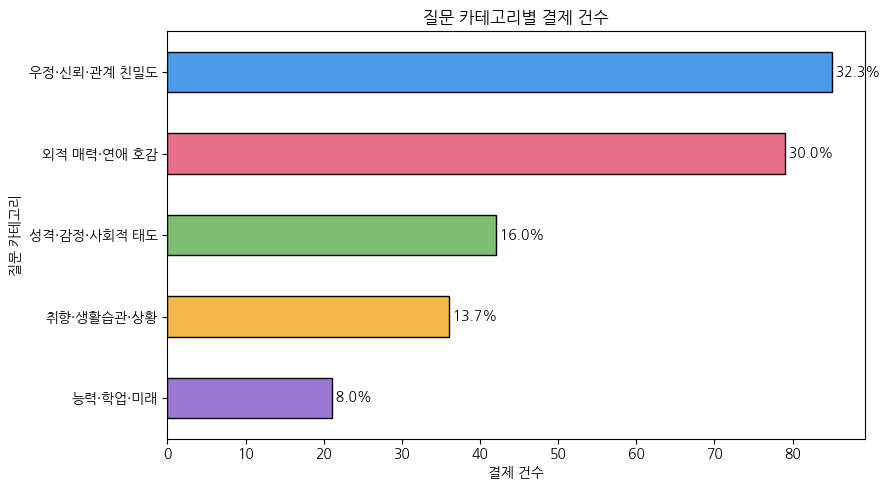

In [638]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

# 카테고리별 고정 색상
category_colors = {
    '외적 매력·연애 호감': '#E76F8A',
    '우정·신뢰·관계 친밀도': '#4C9BE8',
    '성격·감정·사회적 태도': '#7DBE72',
    '취향·생활습관·상황': '#F2B84B',
    '능력·학업·미래': '#9B78D0'
}

# 결제건수 기준 정렬
plot_df = category_payment.sort_values('결제건수')

# 각 행의 카테고리에 맞는 색상 적용
colors = plot_df['질문 카테고리'].map(category_colors)

ax = plot_df.plot(
    x='질문 카테고리',
    y='결제건수',
    kind='barh',
    figsize=(9, 5),
    color=colors,
    edgecolor='black',
    legend=False
)

# 막대 끝에 건수 + 비율 표시
for i, row in plot_df.reset_index(drop=True).iterrows():
    ax.text(
        row['결제건수'],
        i,
        f" {row['결제건수 비율(%)']:.1f}%",
        va='center'
    )

plt.title('질문 카테고리별 결제 건수')
plt.xlabel('결제 건수')
plt.ylabel('질문 카테고리')
plt.tight_layout()
plt.show()

현재 코드: 질문 관련 포인트 소비 → 24시간 이내 결제


실제 흐름 가능성: 질문 확인 → 포인트 부족 → 결제 → -200/-500/-1000 소비

In [639]:
# 단계별 표본 감소 확인
payment_users = set(payment['user_id'].dropna())
spend_users = set(spend_cat['user_id'].dropna())
common_users = payment_users & spend_users

pd.DataFrame({
    '구분': [
        '전체 결제 건수',
        '전체 결제 유저',
        '카테고리 연결 포인트 소비 유저',
        '결제·포인트 소비 공통 유저',
        '현재 24시간 조건 연결 결제'
    ],
    '값': [
        len(payment),
        payment['user_id'].nunique(),
        spend_cat['user_id'].nunique(),
        len(common_users),
        payment_category['category'].notna().sum()
    ]
})

,구분,값
0,전체 결제 건수,95140
1,전체 결제 유저,59192
2,카테고리 연결 포인트 소비 유저,3573
3,결제·포인트 소비 공통 유저,380
4,현재 24시간 조건 연결 결제,263


In [640]:
# 결제 후 포인트 소비로 수정

# 시간형 변환
payment['created_at'] = pd.to_datetime(payment['created_at'])
spend_cat['spend_at'] = pd.to_datetime(spend_cat['spend_at'])

# merge_asof용 정렬
payment_sorted = (
    payment.dropna(subset=['created_at'])
    .sort_values(['created_at', 'user_id'])
    .reset_index(drop=True)
)

spend_sorted = (
    spend_cat.dropna(subset=['spend_at'])
    .sort_values(['spend_at', 'user_id'])
    .reset_index(drop=True)
)

# 결제 후 24시간 이내 첫 질문 관련 포인트 소비 연결
payment_category_forward = pd.merge_asof(
    payment_sorted,
    spend_sorted,
    left_on='created_at',
    right_on='spend_at',
    by='user_id',
    direction='forward',
    tolerance=pd.Timedelta('24h')
)

payment_category_forward['category'].notna().sum()

np.int64(305)

In [641]:
category_payment_forward = (
    payment_category_forward
    .dropna(subset=['category'])
    .groupby('category')
    .agg(
        결제건수=('id', 'count'),
        결제유저수=('user_id', 'nunique')
    )
    .reset_index()
    .rename(columns={'category': '질문 카테고리'})
    .sort_values('결제건수', ascending=False)
)

category_payment_forward['결제건수 비율(%)'] = (
    category_payment_forward['결제건수']
    / category_payment_forward['결제건수'].sum() * 100
).round(2)

category_payment_forward

,질문 카테고리,결제건수,결제유저수,결제건수 비율(%)
2,외적 매력·연애 호감,112,82,36.72
3,우정·신뢰·관계 친밀도,84,60,27.54
1,성격·감정·사회적 태도,46,31,15.08
4,취향·생활습관·상황,38,28,12.46
0,능력·학업·미래,25,22,8.20


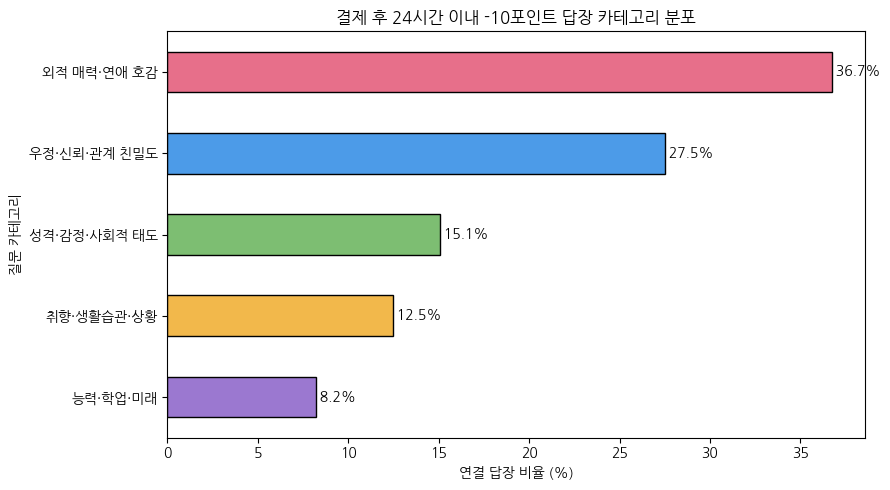

In [642]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

# 카테고리별 고정 색상
category_colors = {
    '외적 매력·연애 호감': '#E76F8A',
    '우정·신뢰·관계 친밀도': '#4C9BE8',
    '성격·감정·사회적 태도': '#7DBE72',
    '취향·생활습관·상황': '#F2B84B',
    '능력·학업·미래': '#9B78D0'
}

# 비율 기준 정렬
plot_df = category_payment_forward.sort_values('결제건수 비율(%)')
colors = plot_df['질문 카테고리'].map(category_colors)

ax = plot_df.plot(
    x='질문 카테고리',
    y='결제건수 비율(%)',
    kind='barh',
    figsize=(9, 5),
    color=colors,
    edgecolor='black',
    legend=False
)

# 막대 끝에 비율 표시
for i, v in enumerate(plot_df['결제건수 비율(%)']):
    ax.text(v, i, f' {v:.1f}%', va='center')

plt.title('결제 후 24시간 이내 -10포인트 답장 카테고리 분포')
plt.xlabel('연결 답장 비율 (%)')
plt.ylabel('질문 카테고리')
plt.tight_layout()
plt.show()

### 결제 유저와 UQR 행동을 user_id 기준으로 직접 연결

In [643]:
# 실제 답장이 확인된 UQR
reply_ids = set(valid_reply['uqr_id'])

# 수신된 질문별 행동 데이터
behavior = uqr[
    ['id', 'chosen_user_id', 'has_read', 'opened_times']
].dropna(subset=['chosen_user_id']).copy()

behavior['읽음'] = (behavior['has_read'] == 1).astype(int)
behavior['초성개봉'] = (behavior['opened_times'] > 0).astype(int)
behavior['답장'] = behavior['id'].isin(reply_ids).astype(int)

# 결제 경험 유저
payer_ids = set(payment['user_id'].dropna())

behavior['결제여부'] = np.where(
    behavior['chosen_user_id'].isin(payer_ids),
    '결제 유저',
    '미결제 유저'
)

behavior.head()

,id,chosen_user_id,has_read,opened_times,읽음,초성개봉,답장,결제여부
0,771777,849469,0,0,0,0,0,미결제 유저
1,771800,849446,0,0,0,0,0,미결제 유저
2,771812,849454,1,0,1,0,0,미결제 유저
3,771828,847375,0,0,0,0,0,미결제 유저
4,771851,849477,1,0,1,0,0,미결제 유저


In [644]:
# 결제 여부별 행동 집계
payment_behavior = (
    behavior.groupby('결제여부')
    .agg(
        유저수=('chosen_user_id', 'nunique'),
        수신건수=('id', 'size'),
        읽음건수=('읽음', 'sum'),
        초성개봉건수=('초성개봉', 'sum'),
        답장건수=('답장', 'sum')
    )
    .reset_index()
)

# 행동률 계산
payment_behavior['읽음률(%)'] = (
    payment_behavior['읽음건수'] / payment_behavior['수신건수'] * 100
).round(2)

payment_behavior['초성개봉률(%)'] = (
    payment_behavior['초성개봉건수'] / payment_behavior['수신건수'] * 100
).round(2)

payment_behavior['답장률(%)'] = (
    payment_behavior['답장건수'] / payment_behavior['수신건수'] * 100
).round(2)

payment_behavior

,결제여부,유저수,수신건수,읽음건수,초성개봉건수,답장건수,읽음률(%),초성개봉률(%),답장률(%)
0,결제 유저,1212,113453,80334,8730,5835,70.81,7.69,5.14
1,미결제 유저,14207,1100473,595597,48300,34053,54.12,4.39,3.09


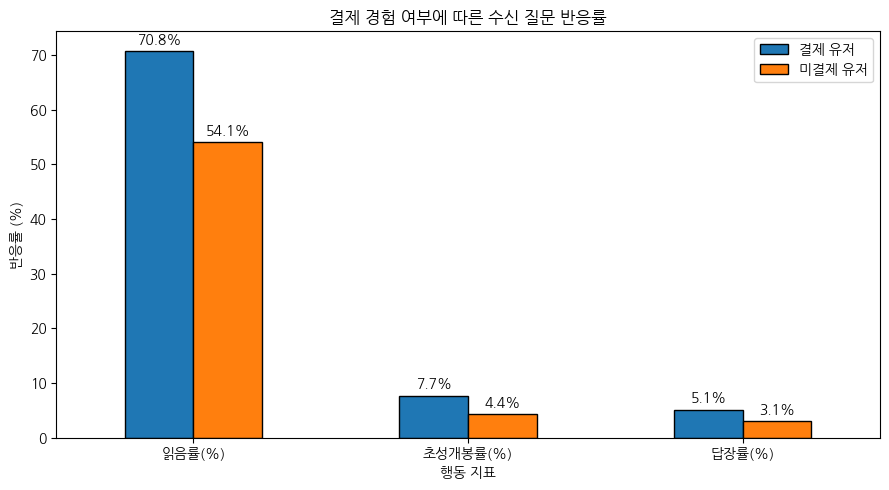

In [645]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

# 시각화용 형태 변환
plot_df = (
    payment_behavior[
        ['결제여부', '읽음률(%)', '초성개봉률(%)', '답장률(%)']
    ]
    .set_index('결제여부')
    .T
)

ax = plot_df.plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

# 막대 위 비율 표시
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('결제 경험 여부에 따른 수신 질문 반응률')
plt.xlabel('행동 지표')
plt.ylabel('반응률 (%)')
plt.xticks(rotation=0)
plt.legend(title='')
plt.tight_layout()
plt.show()

In [646]:
# 반응 수준 → 결제 경험률

# 유저별 반응 경험 집계
user_reaction = (
    behavior.groupby('chosen_user_id')
    .agg(
        수신건수=('id', 'size'),
        읽음경험=('읽음', 'max'),
        초성개봉경험=('초성개봉', 'max'),
        답장경험=('답장', 'max')
    )
    .reset_index()
)

# 가장 깊은 반응 단계
user_reaction['반응단계'] = np.select(
    [
        user_reaction['답장경험'] == 1,
        user_reaction['초성개봉경험'] == 1,
        user_reaction['읽음경험'] == 1
    ],
    [
        '답장 경험',
        '초성 개봉 경험',
        '읽기만 경험'
    ],
    default='미반응'
)

# 결제 경험 여부
user_reaction['결제경험'] = (
    user_reaction['chosen_user_id'].isin(payer_ids)
).astype(int)

reaction_payment = (
    user_reaction.groupby('반응단계')
    .agg(
        유저수=('chosen_user_id', 'size'),
        결제유저수=('결제경험', 'sum')
    )
    .reset_index()
)

reaction_payment['결제경험률(%)'] = (
    reaction_payment['결제유저수']
    / reaction_payment['유저수'] * 100
).round(2)

reaction_payment

,반응단계,유저수,결제유저수,결제경험률(%)
0,답장 경험,2012,238,11.83
1,미반응,2525,95,3.76
2,읽기만 경험,5573,424,7.61
3,초성 개봉 경험,5309,455,8.57


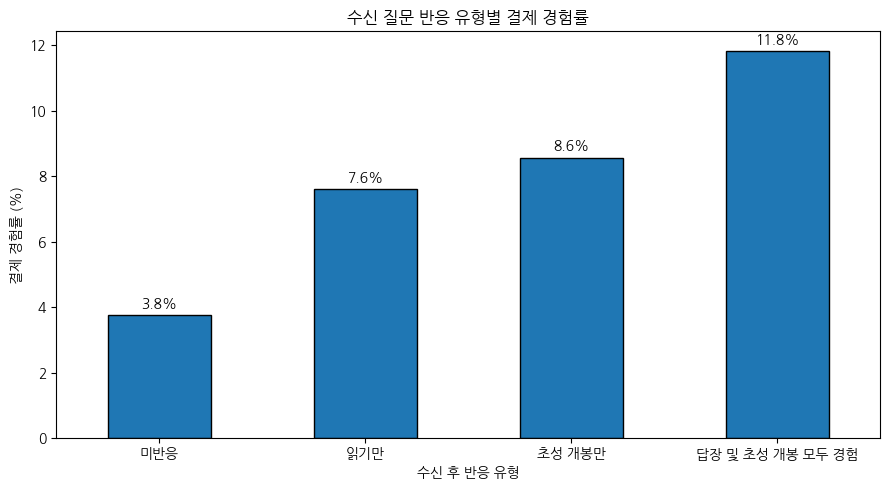

In [647]:
# 단계 순서 지정
order = ['미반응', '읽기만 경험', '초성 개봉 경험', '답장 경험']

plot_df = (
    reaction_payment
    .set_index('반응단계')
    .reindex(order)
    .dropna()
    .reset_index()
)

# 그래프 표시명 수정
plot_df['반응단계'] = plot_df['반응단계'].replace({
    '읽기만 경험': '읽기만',
    '초성 개봉 경험': '초성 개봉만',
    '답장 경험': '답장 및 초성 개봉 모두 경험'
})

ax = plot_df.plot(
    x='반응단계',
    y='결제경험률(%)',
    kind='bar',
    figsize=(9, 5),
    edgecolor='black',
    legend=False
)

# 막대 위 비율 표시
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('수신 질문 반응 유형별 결제 경험률')
plt.xlabel('수신 후 반응 유형')
plt.ylabel('결제 경험률 (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 1. 초성 개봉 + -10 답장을 합친 카테고리별 유저 반응률

5번 재진행

In [648]:
# 실제 답장으로 확인된 UQR
reply_ids = set(valid_reply['uqr_id'])

# 수신 질문 → 카테고리 연결
reaction = (
    uqr[['id', 'chosen_user_id', 'question_id', 'opened_times']]
    .merge(
        questions[['id', 'category']].rename(columns={'id': 'question_id'}),
        on='question_id',
        how='inner'
    )
)

# 초성 개봉 / 답장 / 둘 중 하나라도 하면 반응
reaction['초성개봉'] = (reaction['opened_times'] > 0).astype(int)
reaction['답장'] = reaction['id'].isin(reply_ids).astype(int)
reaction['반응'] = (
    (reaction['초성개봉'] == 1) |
    (reaction['답장'] == 1)
).astype(int)

category_reaction = (
    reaction.groupby('category')
    .agg(
        수신건수=('id', 'size'),
        초성개봉건수=('초성개봉', 'sum'),
        답장건수=('답장', 'sum'),
        반응건수=('반응', 'sum')
    )
    .reset_index()
)

category_reaction['반응률(%)'] = (
    category_reaction['반응건수']
    / category_reaction['수신건수'] * 100
).round(2)

category_reaction.sort_values('반응률(%)', ascending=False)

,category,수신건수,초성개봉건수,답장건수,반응건수,반응률(%)
2,외적 매력·연애 호감,293029,19150,10596,28348,9.67
3,우정·신뢰·관계 친밀도,244551,16386,8140,23314,9.53
4,취향·생활습관·상황,190054,5614,8120,13191,6.94
1,성격·감정·사회적 태도,263483,9636,7036,16058,6.09
0,능력·학업·미래,213111,5961,5571,11130,5.22


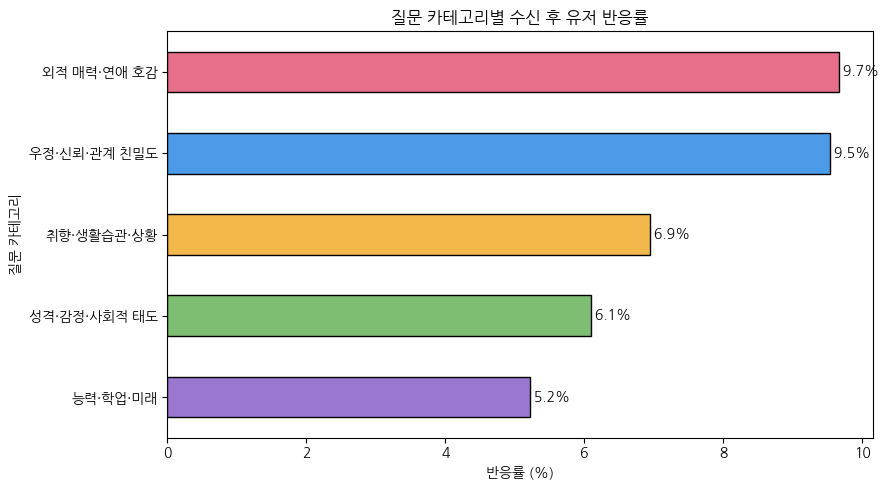

In [649]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

category_colors = {
    '외적 매력·연애 호감': '#E76F8A',
    '우정·신뢰·관계 친밀도': '#4C9BE8',
    '성격·감정·사회적 태도': '#7DBE72',
    '취향·생활습관·상황': '#F2B84B',
    '능력·학업·미래': '#9B78D0'
}

plot_df = category_reaction.sort_values('반응률(%)')
colors = plot_df['category'].map(category_colors)

ax = plot_df.plot(
    x='category',
    y='반응률(%)',
    kind='barh',
    figsize=(9, 5),
    color=colors,
    edgecolor='black',
    legend=False
)

for i, v in enumerate(plot_df['반응률(%)']):
    ax.text(v, i, f' {v:.1f}%', va='center')

plt.title('질문 카테고리별 수신 후 유저 반응률')
plt.xlabel('반응률 (%)')
plt.ylabel('질문 카테고리')
plt.tight_layout()
plt.show()

## -10 포인트 답장을 가장 많이 발생시킨 카테고리

In [650]:
# 실제 답장 UQR → 질문 카테고리 연결
reply_cat = (
    valid_reply
    .merge(
        questions[['id', 'category']].rename(columns={'id': 'question_id'}),
        on='question_id',
        how='inner'
    )
)

category_reply = (
    reply_cat.groupby('category')
    .agg(
        답장건수=('uqr_id', 'size'),
        답장유저수=('chosen_user_id', 'nunique')
    )
    .reset_index()
)

category_reply['답장비중(%)'] = (
    category_reply['답장건수']
    / category_reply['답장건수'].sum() * 100
).round(2)

category_reply.sort_values('답장건수', ascending=False)

,category,답장건수,답장유저수,답장비중(%)
2,외적 매력·연애 호감,10596,1509,26.85
3,우정·신뢰·관계 친밀도,8140,1399,20.63
4,취향·생활습관·상황,8120,1406,20.58
1,성격·감정·사회적 태도,7036,1260,17.83
0,능력·학업·미래,5571,1137,14.12


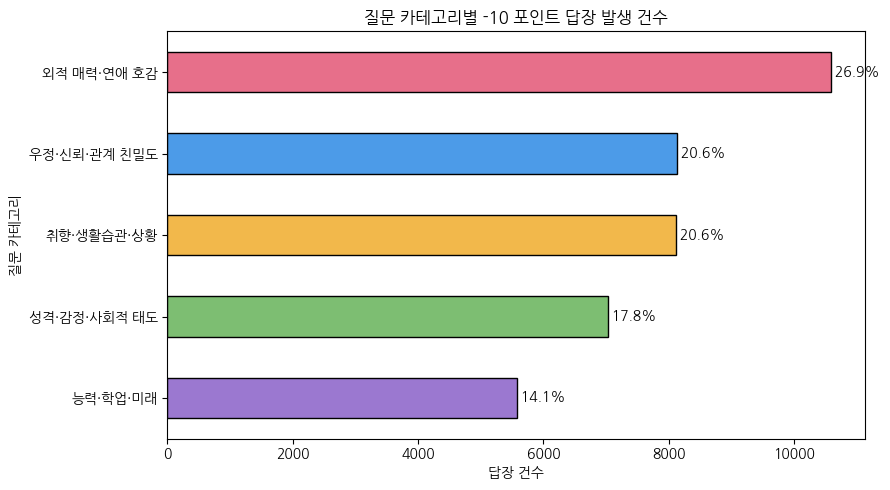

In [651]:
plot_df = category_reply.sort_values('답장건수')
colors = plot_df['category'].map(category_colors)

ax = plot_df.plot(
    x='category',
    y='답장건수',
    kind='barh',
    figsize=(9, 5),
    color=colors,
    edgecolor='black',
    legend=False
)

for i, row in plot_df.reset_index(drop=True).iterrows():
    ax.text(
        row['답장건수'],
        i,
        f" {row['답장비중(%)']:.1f}%",
        va='center'
    )

plt.title('질문 카테고리별 -10 포인트 답장 발생 건수')
plt.xlabel('답장 건수')
plt.ylabel('질문 카테고리')
plt.tight_layout()
plt.show()

## -10 포인트 답장이 가장 많이 발생한 질문

In [652]:
# 질문별 수신량
question_received = (
    reaction.groupby(['question_id', 'category'])
    .size()
    .rename('수신건수')
    .reset_index()
)

# 질문별 답장 건수
question_reply = (
    reply_cat.groupby(['question_id', 'category'])
    .size()
    .rename('답장건수')
    .reset_index()
)

question_reply_result = (
    question_received
    .merge(
        question_reply,
        on=['question_id', 'category'],
        how='left'
    )
    .merge(
        questions[['id', 'question_text']]
        .rename(columns={'id': 'question_id'}),
        on='question_id',
        how='left'
    )
)

question_reply_result['답장건수'] = (
    question_reply_result['답장건수'].fillna(0)
)

question_reply_result['답장률(%)'] = (
    question_reply_result['답장건수']
    / question_reply_result['수신건수'] * 100
).round(2)

top_reply_questions = (
    question_reply_result
    .sort_values('답장건수', ascending=False)
    .head(15)
)

top_reply_questions[
    ['question_text', 'category', '수신건수', '답장건수', '답장률(%)']
]

,question_text,category,수신건수,답장건수,답장률(%)
452,라면 잘 끓일 것 같은 사람은?,취향·생활습관·상황,2109,70.0,3.32
1112,화해하고 싶은 친구는?,우정·신뢰·관계 친밀도,382,60.0,15.71
1504,안 친한데 연락해보고 싶은 사람,우정·신뢰·관계 친밀도,299,57.0,19.06
720,눈이 제일 큰 사람은?,외적 매력·연애 호감,758,55.0,7.26
1453,전화번호 얻고 싶은 사람은?,우정·신뢰·관계 친밀도,321,54.0,16.82
1310,지금 심심할 것 같은 친구는?,취향·생활습관·상황,392,54.0,13.78
996,롯데월드가서 회전목마만 탈 것 같은 사람은?,취향·생활습관·상황,386,52.0,13.47
960,"""사랑해""를 가장 듣고 싶은 사람은?",외적 매력·연애 호감,280,51.0,18.21
1463,너 이쁘다,외적 매력·연애 호감,364,51.0,14.01
684,dm하고 싶은 친구는?,우정·신뢰·관계 친밀도,343,50.0,14.58


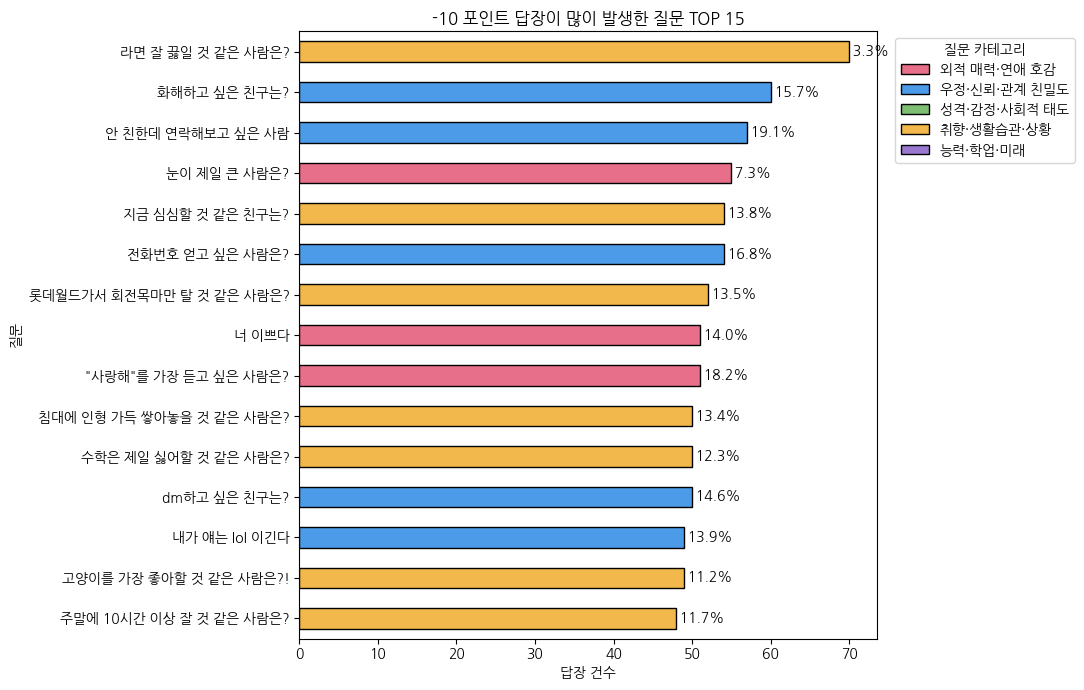

In [653]:
from matplotlib.patches import Patch

plot_df = top_reply_questions.sort_values('답장건수')
colors = plot_df['category'].map(category_colors)

ax = plot_df.plot(
    x='question_text',  # 질문 문장 표시
    y='답장건수',
    kind='barh',
    figsize=(11, 7),
    color=colors,
    edgecolor='black',
    legend=False
)

# 막대 끝 답장률 표시
for i, row in plot_df.reset_index(drop=True).iterrows():
    ax.text(
        row['답장건수'],
        i,
        f" {row['답장률(%)']:.1f}%",
        va='center'
    )

# 카테고리 색상 범례
legend_handles = [
    Patch(facecolor=color, edgecolor='black', label=category)
    for category, color in category_colors.items()
]

plt.legend(
    handles=legend_handles,
    title='질문 카테고리',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.title('-10 포인트 답장이 많이 발생한 질문 TOP 15')
plt.xlabel('답장 건수')
plt.ylabel('질문')
plt.tight_layout()
plt.show()

## 0. 유저별 최우선 반응 카테고리

⑤-5의 **“관측상 최고 반응 카테고리”**를 초성 개봉 OR -10 답장 기준으로 다시 계산

In [654]:
# 유저×카테고리별 반응 집계
user_category_reaction = (
    reaction.groupby(['chosen_user_id', 'category'])
    .agg(
        수신건수=('id', 'size'),
        반응건수=('반응', 'sum')
    )
    .reset_index()
)

# 유저×카테고리 반응률
user_category_reaction['반응률'] = (
    user_category_reaction['반응건수']
    / user_category_reaction['수신건수']
)

In [655]:
# 카테고리 전체 평균 반응률
category_base = (
    user_category_reaction.groupby('category')
    .agg(
        전체수신=('수신건수', 'sum'),
        전체반응=('반응건수', 'sum')
    )
)

category_base['기준반응률'] = (
    category_base['전체반응']
    / category_base['전체수신']
)

user_category_reaction = user_category_reaction.merge(
    category_base[['기준반응률']],
    on='category',
    how='left'
)

# 수신건수 중앙값을 보정 강도로 사용
prior_strength = user_category_reaction['수신건수'].median()

# 표본이 적은 유저의 극단적 반응률 완화
user_category_reaction['보정반응률'] = (
    user_category_reaction['반응건수']
    + prior_strength * user_category_reaction['기준반응률']
) / (
    user_category_reaction['수신건수']
    + prior_strength
)

# 해당 카테고리 평균 대비 얼마나 더 반응했는지
user_category_reaction['반응_lift'] = (
    user_category_reaction['보정반응률']
    - user_category_reaction['기준반응률']
)

In [656]:
# 유저별 관측 조건
user_valid = (
    user_category_reaction.groupby('chosen_user_id')
    .agg(
        경험카테고리수=('category', 'nunique'),
        전체반응건수=('반응건수', 'sum')
    )
    .reset_index()
)

valid_users = user_valid.loc[
    (user_valid['경험카테고리수'] >= 3) &
    (user_valid['전체반응건수'] > 0),
    'chosen_user_id'
]

valid_pref = user_category_reaction[
    user_category_reaction['chosen_user_id'].isin(valid_users)
].copy()

In [657]:
# 반응 lift가 가장 높은 카테고리를 개인별 최고 반응 카테고리로 선정
favorite = (
    valid_pref
    .sort_values(
        ['chosen_user_id', '반응_lift', '수신건수'],
        ascending=[True, False, False]
    )
    .drop_duplicates('chosen_user_id')
)

favorite_result = (
    favorite['category']
    .value_counts()
    .rename_axis('질문 카테고리')
    .reset_index(name='유저수')
)

favorite_result['유저비율(%)'] = (
    favorite_result['유저수']
    / favorite_result['유저수'].sum() * 100
).round(2)

favorite_result

,질문 카테고리,유저수,유저비율(%)
0,우정·신뢰·관계 친밀도,1856,27.01
1,외적 매력·연애 호감,1599,23.27
2,능력·학업·미래,1330,19.36
3,성격·감정·사회적 태도,1221,17.77
4,취향·생활습관·상황,865,12.59


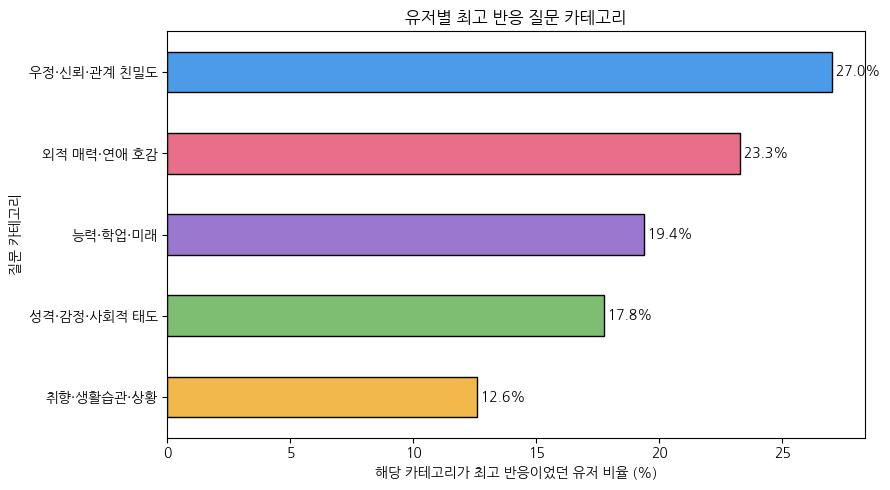

In [658]:
import matplotlib.pyplot as plt
import koreanize_matplotlib

plot_df = favorite_result.sort_values('유저비율(%)')
colors = plot_df['질문 카테고리'].map(category_colors)

ax = plot_df.plot(
    x='질문 카테고리',
    y='유저비율(%)',
    kind='barh',
    figsize=(9, 5),
    color=colors,
    edgecolor='black',
    legend=False
)

# 비율 표시
for i, v in enumerate(plot_df['유저비율(%)']):
    ax.text(v, i, f' {v:.1f}%', va='center')

plt.title('유저별 최고 반응 질문 카테고리')
plt.xlabel('해당 카테고리가 최고 반응이었던 유저 비율 (%)')
plt.ylabel('질문 카테고리')
plt.tight_layout()
plt.show()

## 결제 후 -10 답장과 연결된 카테고리

결제 → 24시간 이내 -10 답장 발생

In [659]:
# 답장 발생 시각 + 카테고리
reply_payment = reply_cat[
    ['uqr_id', 'chosen_user_id', 'created_at', 'category']
].copy()

reply_payment = reply_payment.rename(columns={
    'chosen_user_id': 'user_id',
    'created_at': 'reply_at'
})

# 결제 데이터 정리
payment_link = payment[
    ['id', 'user_id', 'created_at']
].copy().rename(columns={
    'id': 'payment_id',
    'created_at': 'payment_at'
})

# merge_asof 정렬
reply_payment = (
    reply_payment
    .dropna(subset=['reply_at'])
    .sort_values(['reply_at', 'user_id'])
    .reset_index(drop=True)
)

payment_link = (
    payment_link
    .dropna(subset=['payment_at'])
    .sort_values(['payment_at', 'user_id'])
    .reset_index(drop=True)
)

# 답장 직전 24시간 이내 결제가 있었는지 연결
reply_with_payment = pd.merge_asof(
    reply_payment,
    payment_link,
    left_on='reply_at',
    right_on='payment_at',
    by='user_id',
    direction='backward',
    tolerance=pd.Timedelta('24h')
)

In [660]:
reply_payment_category = (
    reply_with_payment
    .dropna(subset=['payment_id'])
    .groupby('category')
    .agg(
        결제연결답장건수=('uqr_id', 'size'),
        결제유저수=('user_id', 'nunique'),
        연결결제건수=('payment_id', 'nunique')
    )
    .reset_index()
)

reply_payment_category['비중(%)'] = (
    reply_payment_category['결제연결답장건수']
    / reply_payment_category['결제연결답장건수'].sum() * 100
).round(2)

reply_payment_category.sort_values(
    '결제연결답장건수',
    ascending=False
)

,category,결제연결답장건수,결제유저수,연결결제건수,비중(%)
2,외적 매력·연애 호감,287,79,95,28.16
4,취향·생활습관·상황,233,64,79,22.87
3,우정·신뢰·관계 친밀도,175,51,69,17.17
0,능력·학업·미래,164,52,65,16.09
1,성격·감정·사회적 태도,160,54,70,15.70


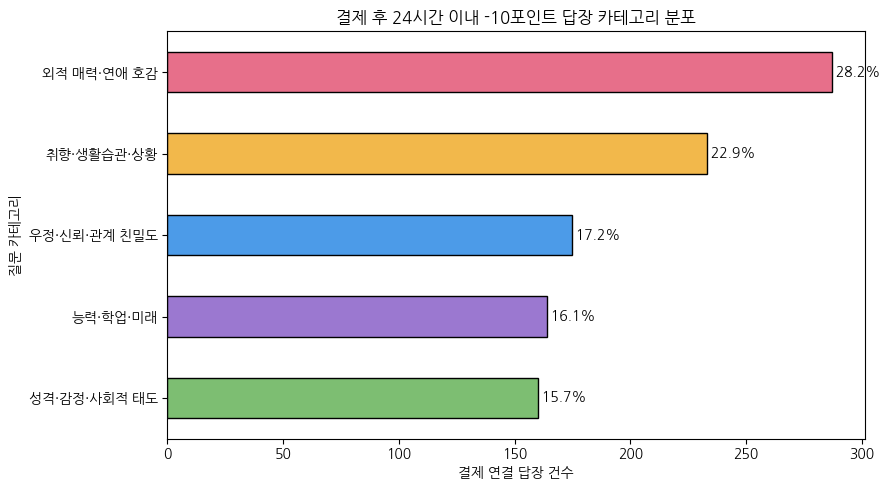

In [661]:
plot_df = reply_payment_category.sort_values('결제연결답장건수')
colors = plot_df['category'].map(category_colors)

ax = plot_df.plot(
    x='category',
    y='결제연결답장건수',
    kind='barh',
    figsize=(9, 5),
    color=colors,
    edgecolor='black',
    legend=False
)

for i, row in plot_df.reset_index(drop=True).iterrows():
    ax.text(
        row['결제연결답장건수'],
        i,
        f" {row['비중(%)']:.1f}%",
        va='center'
    )

plt.title('결제 후 24시간 이내 -10포인트 답장 카테고리 분포')
plt.xlabel('결제 연결 답장 건수')
plt.ylabel('질문 카테고리')
plt.tight_layout()
plt.show()

In [662]:
# 결제 경험 유저 ID
payer_ids = set(payment['user_id'].dropna().unique())

# 수신 질문 단위 데이터
behavior = uqr[['id', 'chosen_user_id', 'opened_times']].copy()

# 결제 여부
behavior['결제여부'] = np.where(
    behavior['chosen_user_id'].isin(payer_ids),
    '결제 유저',
    '미결제 유저'
)

# 통합 반응 = 초성 개봉 OR PING 답장
behavior['반응'] = (
    behavior['opened_times'].fillna(0).gt(0) |
    behavior['id'].isin(reply_ids)
)

# 결제 여부별 통합 반응률
pay_reaction = (
    behavior.groupby('결제여부')['반응']
    .mean()
    .mul(100)
    .round(2)
    .rename('반응률(%)')
    .reset_index()
)

pay_reaction

,결제여부,반응률(%)
0,결제 유저,12.10
1,미결제 유저,7.18


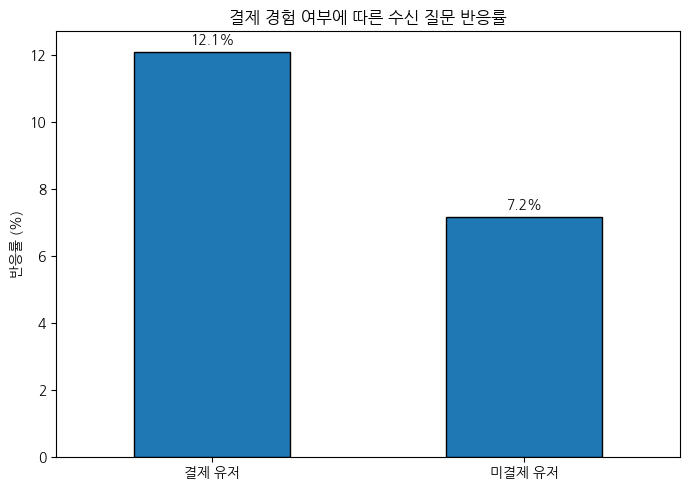

In [663]:
# 결제 여부별 통합 반응률 시각화
ax = pay_reaction.plot(
    x='결제여부',
    y='반응률(%)',
    kind='bar',
    figsize=(7, 5),
    legend=False,
    edgecolor='black'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

plt.title('결제 경험 여부에 따른 수신 질문 반응률')
plt.xlabel('')
plt.ylabel('반응률 (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [664]:
# 메모리 부족 방지 및 변수 초기화 (재현성 유지)
%reset -f